In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

# Update this path if Vicilin_MD is inside another folder
PDB_PATH = "/content/drive/MyDrive/Vicilin Trimer/Vicilin trimer.cif"

if os.path.exists(PDB_PATH):
    print("PDB found!")
    print("File size:", round(os.path.getsize(PDB_PATH) / 1024, 2), "KB")
else:
    print("PDB not found. Check the folder path.")

MessageError: Error: credential propagation was unsuccessful

In [ ]:
!pip -q install biopython

from Bio.PDB import MMCIFParser, PDBIO
import os

CIF_PATH = "/content/drive/MyDrive/Vicilin Trimer/Vicilin trimer.cif"
PDB_PATH = "/content/drive/MyDrive/Vicilin Trimer/Vicilin trimer.pdb"

parser = MMCIFParser(QUIET=True)
structure = parser.get_structure("vicilin_trimer", CIF_PATH)

io = PDBIO()
io.set_structure(structure)
io.save(PDB_PATH)

print("Conversion successful!")
print("PDB saved at:", PDB_PATH)
print("File size:", round(os.path.getsize(PDB_PATH) / 1024, 2), "KB")
print("Chains:", [chain.id for chain in structure.get_chains()])

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 46.0 MB/s eta 0:00:00
Conversion successful!
PDB saved at: /content/drive/MyDrive/Vicilin Trimer/Vicilin trimer.pdb
File size: 792.61 KB
Chains: ['A', 'B', 'C']


In [ ]:
from collections import defaultdict

PDB_PATH = "/content/drive/MyDrive/Vicilin Trimer/Vicilin trimer.pdb"

chains = defaultdict(set)
atom_counts = defaultdict(int)

with open(PDB_PATH, "r") as f:
    for line in f:
        if line.startswith("ATOM  "):
            chain = line[21].strip() or "_"
            residue_number = line[22:27].strip()
            residue_name = line[17:20].strip()

            chains[chain].add((residue_number, residue_name))
            atom_counts[chain] += 1

print("Number of chains:", len(chains))
print("Chain IDs:", sorted(chains.keys()))

for chain in sorted(chains):
    print(
        f"Chain {chain}: "
        f"{len(chains[chain])} residues, "
        f"{atom_counts[chain]} atoms"
    )

print("Total protein atoms:", sum(atom_counts.values()))

Number of chains: 3
Chain IDs: ['A', 'B', 'C']
Chain A: 415 residues, 3339 atoms
Chain B: 415 residues, 3339 atoms
Chain C: 415 residues, 3339 atoms
Total protein atoms: 10017


In [ ]:
from collections import Counter, defaultdict

PDB_PATH = "/content/drive/MyDrive/Vicilin Trimer/Vicilin trimer.pdb"

residues = defaultdict(dict)
record_counts = Counter()
atom_names = defaultdict(Counter)
other_residues = Counter()

with open(PDB_PATH) as f:
    for line in f:
        record = line[:6].strip()

        if record:
            record_counts[record] += 1

        if record == "ATOM":
            chain = line[21].strip() or "_"
            resid = (line[22:27].strip(), line[17:20].strip())
            atom_name = line[12:16].strip()

            residues[chain][resid] = True
            atom_names[chain][atom_name] += 1

        elif record == "HETATM":
            other_residues[line[17:20].strip()] += 1

print("PDB record types:", record_counts)
print("\nResidue numbering by chain:")

for chain in sorted(residues):
    numbers = [int(r[0].split()[0]) for r in residues[chain]]
    print(
        f"Chain {chain}: first={min(numbers)}, "
        f"last={max(numbers)}, unique residues={len(numbers)}"
    )

print("\nHETATM residue types:", other_residues or "None")
print("\nUnique atom names in chain A:")
print(sorted(atom_names["A"].keys()))

PDB record types: Counter({'ATOM': 10017, 'TER': 3, 'END': 1})

Residue numbering by chain:
Chain A: first=1, last=415, unique residues=415
Chain B: first=1, last=415, unique residues=415
Chain C: first=1, last=415, unique residues=415

HETATM residue types: None

Unique atom names in chain A:
['C', 'CA', 'CB', 'CD', 'CD1', 'CD2', 'CE', 'CE1', 'CE2', 'CG', 'CG1', 'CG2', 'CZ', 'N', 'ND1', 'ND2', 'NE', 'NE2', 'NH1', 'NH2', 'NZ', 'O', 'OD1', 'OD2', 'OE1', 'OE2', 'OG', 'OG1', 'OH', 'OXT', 'SG']


In [ ]:
%pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to
condacolab==0.1 as a workaround.

✨🍰✨ Everything looks OK!


In [ ]:
!CONDA_OVERRIDE_CUDA=12.9 conda create -y \
    -n gmx_cuda \
    -c conda-forge \
    "gromacs=2026.3=nompi_cuda*"

Channels:
 - conda-forge
Platform: linux-64
Solving environment: | / - done

## Package Plan ##

  environment location: /usr/local/envs/gmx_cuda

  added / updated specs:
    - gromacs==2026.3[build=nompi_cuda*]


The following NEW packages will be INSTALLED:

  _openmp_mutex      conda-forge/linux-64::_openmp_mutex-4.5-20_gnu 
  alsa-lib           conda-forge/linux-64::alsa-lib-1.2.16.1-h7cc23a3_1 
  binutils           conda-forge/linux-64::binutils-2.46.1-default_h4852527_103 
  binutils_impl_lin~ conda-forge/linux-64::binutils_impl_linux-64-2.46.1-default_hfdba357_103 
  binutils_linux-64  conda-forge/linux-64::binutils_linux-64-2.46.1-default_h4852527_103 
  bzip2              conda-forge/linux-64::bzip2-1.0.8-hda65f42_10 
  c-compiler         conda-forge/linux-64::c-compiler-1.11.0-h4d9bdce_0 
  ca-certificates    conda-forge/noarch::ca-certificates-2026.7.22-hbd8a1cb_0 
  conda-gcc-specs    conda-forge/linux-64::conda-gcc-specs-14.4.0-h611768e_7 
  cuda-cccl_linux-64 conda

In [ ]:
!conda run -n gmx_cuda gmx --version

                   :-) GROMACS - gmx, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content
Command line:
  gmx --version

GROMACS version:     2026.3-conda_forge
Precision:           mixed
Memory model:        64 bit
MPI library:         thread_mpi
MPI version:         built in
OpenMP support:      enabled (GMX_OPENMP_MAX_THREADS = 128)
GPU support:         CUDA
NBNxM GPU setup:     super-cluster 2x2x2 / cluster 8 (cluster-pair splitting on)
SIMD instructions:   AVX2_256
CPU FFT library:     fftw-3.3.11-sse2-avx
GPU FFT library:     cuFFT
Multi-GPU FFT:       none
RDTSCP:              disabled
TNG support:         enabled
Hwloc support:       disabled
Tracing support:     disabled
Colvars support:     enabled (version 2025-10-13)
CP2K support:        disabled
Torch support:       disabled
Plumed support:      enabled
C compiler:          /home/conda/feedstock_root/build_artifacts/gromacs_1785262689

In [ ]:
import os
import shutil

SOURCE = "/content/drive/MyDrive/Vicilin Trimer/Vicilin trimer.pdb"
PROJECT = "/content/drive/MyDrive/Plant Protein Extrusion MD"
STRUCTURES = os.path.join(PROJECT, "structures")
ANALYSIS = os.path.join(PROJECT, "analysis")
SIMULATIONS = os.path.join(PROJECT, "simulations")

for folder in [STRUCTURES, ANALYSIS, SIMULATIONS]:
    os.makedirs(folder, exist_ok=True)

DEST = os.path.join(STRUCTURES, "vicilin_trimer_original.pdb")

if not os.path.isfile(SOURCE):
    raise FileNotFoundError(f"Source PDB not found: {SOURCE}")

if not os.path.exists(DEST):
    shutil.copy2(SOURCE, DEST)

print("Project folder:", PROJECT)
print("Original PDB preserved:", os.path.isfile(SOURCE))
print("Working copy:", DEST)
print("Working copy size:", round(os.path.getsize(DEST) / 1024, 2), "KB")
print("GROMACS environment: /usr/local/envs/gmx_cuda")

Project folder: /content/drive/MyDrive/Plant Protein Extrusion MD
Original PDB preserved: True
Working copy: /content/drive/MyDrive/Plant Protein Extrusion MD/structures/vicilin_trimer_original.pdb
Working copy size: 792.61 KB
GROMACS environment: /usr/local/envs/gmx_cuda


In [ ]:
!conda run -n gmx_cuda gmx pdb2gmx -h

SYNOPSIS

gmx pdb2gmx [-f [<.gro/.g96/...>]] [-o [<.gro/.g96/...>]] [-p [<.top>]]
            [-i [<.itp>]] [-n [<.ndx>]] [-q [<.gro/.g96/...>]]
            [-chainsep <enum>] [-merge <enum>] [-ff <string>] [-water <enum>]
            [-[no]inter] [-[no]ss] [-[no]ter] [-[no]lys] [-[no]arg]
            [-[no]asp] [-[no]glu] [-[no]gln] [-[no]his] [-angle <real>]
            [-dist <real>] [-[no]una] [-[no]ignh] [-[no]missing] [-[no]v]
            [-posrefc <real>] [-vsite <enum>] [-[no]heavyh] [-[no]deuterate]
            [-[no]cmap] [-[no]renum] [-rtpres <enum>]

DESCRIPTION

gmx pdb2gmx reads a .pdb (or .gro) file, reads some database files, adds
hydrogens to the molecules and generates coordinates in GROMACS (GROMOS), or
optionally .pdb, format and a topology in GROMACS format. These files can
subsequently be processed to generate a run input file.

gmx pdb2gmx will search for force fields by looking for a forcefield.itp file
in subdirectories <forcefield>.ff of the current working di

In [ ]:
from pathlib import Path

GMX_DATA = Path("/usr/local/envs/gmx_cuda/share/gromacs/top")

print("Topology directory exists:", GMX_DATA.is_dir())

if GMX_DATA.is_dir():
    print("\nInstalled Amber force fields:")
    for item in sorted(GMX_DATA.glob("*amber*.ff")):
        print(item.name)

    print("\nAll force-field directories:")
    for item in sorted(GMX_DATA.glob("*.ff")):
        print(item.name)
else:
    print("Directory not found; checking the environment:")
    !conda run -n gmx_cuda gmx --version

Topology directory exists: True

Installed Amber force fields:
amber03.ff
amber14sb.ff
amber19sb.ff
amber94.ff
amber96.ff
amber99.ff
amber99sb-ildn.ff
amber99sb.ff
amberGS.ff

All force-field directories:
amber03.ff
amber14sb.ff
amber19sb.ff
amber94.ff
amber96.ff
amber99.ff
amber99sb-ildn.ff
amber99sb.ff
amberGS.ff
charmm27.ff
gromos43a1.ff
gromos43a2.ff
gromos45a3.ff
gromos53a5.ff
gromos53a6.ff
gromos54a7.ff
oplsaa.ff


In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!conda run -n gmx_cuda gmx pdb2gmx \
    -f structures/vicilin_trimer_original.pdb \
    -o structures/vicilin_trimer_processed.gro \
    -p topol.top \
    -i posre.itp \
    -ff amber99sb-ildn \
    -water spce \
    -chainsep id_or_ter \
    -merge no

/content/drive/MyDrive/Plant Protein Extrusion MD
Using the Amber99sb-ildn force field in directory amber99sb-ildn.ff

going to rename amber99sb-ildn.ff/aminoacids.r2b

going to rename amber99sb-ildn.ff/dna.r2b

going to rename amber99sb-ildn.ff/rna.r2b
Reading structures/vicilin_trimer_original.pdb...
Read '', 10017 atoms

Analyzing pdb file
Splitting chemical chains based on TER records or chain id changing.

There are 3 chains and 0 blocks of water and 1245 residues with 10017 atoms

  chain  #res #atoms

  1 'A'   415   3339  

  2 'B'   415   3339  

  3 'C'   415   3339  

All occupancies are one

Reading residue database... (Amber99sb-ildn)

Preserving residues names by default

Preserving residues names by default

Preserving residues names by default

Processing chain 1 'A' (3339 atoms, 415 residues)

Identified residue SER1 as a starting terminus.

Identified residue GLU415 as a ending terminus.

Checking for duplicate atoms....

Generating any missing hydrogen atoms and/or a

In [ ]:
import os

PROJECT = "/content/drive/MyDrive/Plant Protein Extrusion MD"

files = [
    "structures/vicilin_trimer_processed.gro",
    "topol.top",
    "posre.itp",
]

for name in files:
    path = os.path.join(PROJECT, name)
    print(f"{name}: {'FOUND' if os.path.isfile(path) else 'MISSING'}")
    if os.path.isfile(path):
        print(f"  Size: {os.path.getsize(path) / 1024:.1f} KB")

print("\nTopology molecule definitions:")
with open(os.path.join(PROJECT, "topol.top")) as f:
    show = False
    for line in f:
        if line.strip() == "[ molecules ]":
            show = True
        if show:
            print(line.rstrip())

structures/vicilin_trimer_processed.gro: FOUND
  Size: 876.4 KB
topol.top: FOUND
  Size: 1.3 KB
posre.itp: MISSING

Topology molecule definitions:
[ molecules ]
; Compound        #mols
Protein_chain_A     1
Protein_chain_B     1
Protein_chain_C     1


In [ ]:
import os

PROJECT = "/content/drive/MyDrive/Plant Protein Extrusion MD"

print("Checking possible position-restraint files:\n")

for root, dirs, files in os.walk(PROJECT):
    for name in files:
        if name == "posre.itp" or name.startswith("posre_"):
            path = os.path.join(root, name)
            print(path, f"({os.path.getsize(path) / 1024:.1f} KB)")

print("\nChecking topology includes:")
with open(os.path.join(PROJECT, "topol.top")) as f:
    for line in f:
        if "#include" in line or "[ molecules ]" in line:
            print(line.rstrip())

Checking possible position-restraint files:

/content/drive/MyDrive/Plant Protein Extrusion MD/posre_Protein_chain_A.itp (101.3 KB)
/content/drive/MyDrive/Plant Protein Extrusion MD/posre_Protein_chain_B.itp (101.3 KB)
/content/drive/MyDrive/Plant Protein Extrusion MD/posre_Protein_chain_C.itp (101.3 KB)

Checking topology includes:
#include "amber99sb-ildn.ff/forcefield.itp"
#include "topol_Protein_chain_A.itp"
#include "topol_Protein_chain_B.itp"
#include "topol_Protein_chain_C.itp"
#include "amber99sb-ildn.ff/spce.itp"
#include "amber99sb-ildn.ff/ions.itp"
[ molecules ]


In [ ]:
import os

PROJECT = "/content/drive/MyDrive/Plant Protein Extrusion MD"

for chain in "ABC":
    filename = f"topol_Protein_chain_{chain}.itp"
    path = os.path.join(PROJECT, filename)

    print(f"\n--- Chain {chain}: {filename} ---")

    if not os.path.isfile(path):
        print("MISSING")
        continue

    with open(path) as f:
        for line in f:
            if "posre" in line.lower() or line.strip() == "[ moleculetype ]":
                print(line.rstrip())


--- Chain A: topol_Protein_chain_A.itp ---
;	  gmx pdb2gmx -f structures/vicilin_trimer_original.pdb -o structures/vicilin_trimer_processed.gro -p topol.top -i posre.itp -ff amber99sb-ildn -water spce -chainsep id_or_ter -merge no
[ moleculetype ]
#ifdef POSRES
#include "posre_Protein_chain_A.itp"

--- Chain B: topol_Protein_chain_B.itp ---
;	  gmx pdb2gmx -f structures/vicilin_trimer_original.pdb -o structures/vicilin_trimer_processed.gro -p topol.top -i posre.itp -ff amber99sb-ildn -water spce -chainsep id_or_ter -merge no
[ moleculetype ]
#ifdef POSRES
#include "posre_Protein_chain_B.itp"

--- Chain C: topol_Protein_chain_C.itp ---
;	  gmx pdb2gmx -f structures/vicilin_trimer_original.pdb -o structures/vicilin_trimer_processed.gro -p topol.top -i posre.itp -ff amber99sb-ildn -water spce -chainsep id_or_ter -merge no
[ moleculetype ]
#ifdef POSRES
#include "posre_Protein_chain_C.itp"


In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!conda run -n gmx_cuda gmx editconf \
    -f structures/vicilin_trimer_processed.gro \
    -o structures/vicilin_trimer_box.gro \
    -c \
    -d 1.2 \
    -bt dodecahedron

/content/drive/MyDrive/Plant Protein Extrusion MD
Note that major changes are planned in future for editconf, to improve usability and utility.
Read 19941 atoms
Volume: 807.587 nm^3, corresponds to roughly 363400 electrons
No velocities found
    system size :  7.527 10.251 10.465 (nm)
    diameter    : 11.113               (nm)
    center      : -0.016 -0.018  0.064 (nm)
    box vectors :  7.528 10.251 10.466 (nm)
    box angles  :  90.00  90.00  90.00 (degrees)
    box volume  : 807.59               (nm^3)
    shift       : 10.151 10.153  4.713 (nm)
new center      : 10.134 10.134  4.777 (nm)
new box vectors : 13.513 13.513 13.513 (nm)
new box angles  :  60.00  60.00  90.00 (degrees)
new box volume  :1744.59               (nm^3)
               :-) GROMACS - gmx editconf, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx editconf -f s

In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!conda run -n gmx_cuda gmx solvate \
    -cp structures/vicilin_trimer_box.gro \
    -cs spc216.gro \
    -o structures/vicilin_trimer_solv.gro \
    -p topol.top

/content/drive/MyDrive/Plant Protein Extrusion MD

         based on residue and atom names, since they could not be
         definitively assigned from the information in your input
         files. These guessed numbers might deviate from the mass
         and radius of the atom type. Please check the output
         files if necessary. Note, that this functionality may
         be removed in a future GROMACS version. Please, consider
         using another file format for your input.

         The atomic radii are set according to:

++++ PLEASE READ AND CITE THE FOLLOWING REFERENCE ++++
A. Bondi
van der Waals Volumes and Radii
J. Phys. Chem. (1964)
https://doi.org/10.1021/j100785a001
-------- -------- --- Thank You --- -------- --------

Adding line for 50992 solvent molecules with resname (SOL) to topology file (topol.top)
               :-) GROMACS - gmx solvate, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
W

In [ ]:
from pathlib import Path

project = Path("/content/drive/MyDrive/Plant Protein Extrusion MD")
mdp = project / "em.mdp"

mdp.write_text("""; Energy minimization
integrator      = steep
emtol           = 1000.0
emstep          = 0.01
nsteps          = 50000

cutoff-scheme   = Verlet
nstlist         = 20
coulombtype     = PME
rcoulomb        = 1.0
rvdw            = 1.0
pbc             = xyz

constraints     = h-bonds
""")

print(f"Created: {mdp}")
print(mdp.read_text())

Created: /content/drive/MyDrive/Plant Protein Extrusion MD/em.mdp
; Energy minimization
integrator      = steep
emtol           = 1000.0
emstep          = 0.01
nsteps          = 50000

cutoff-scheme   = Verlet
nstlist         = 20
coulombtype     = PME
rcoulomb        = 1.0
rvdw            = 1.0
pbc             = xyz

constraints     = h-bonds



In [ ]:
from pathlib import Path

project = Path("/content/drive/MyDrive/Plant Protein Extrusion MD")
top = project / "topol.top"

print("Topology solvent and ion entries:")
for line in top.read_text().splitlines():
    if "spce.itp" in line or "ions.itp" in line or line.strip().startswith("SOL"):
        print(line)

ions = Path("/usr/local/envs/gmx_cuda/share/gromacs/top/amber99sb-ildn.ff/ions.itp")
print("\nIon definitions file exists:", ions.exists())

if ions.exists():
    for line in ions.read_text().splitlines():
        if line.strip().startswith("[ ") or line.strip().startswith("NA") or line.strip().startswith("CL"):
            print(line)

Topology solvent and ion entries:
#include "amber99sb-ildn.ff/spce.itp"
#include "amber99sb-ildn.ff/ions.itp"
SOL             50992

Ion definitions file exists: True
[ moleculetype ]
[ atoms ]
[ moleculetype ]
[ atoms ]
[ moleculetype ]
CL              1
[ atoms ]
[ moleculetype ]
NA              1
[ atoms ]
[ moleculetype ]
[ atoms ]
[ moleculetype ]
[ atoms ]
[ moleculetype ]
[ atoms ]
[ moleculetype ]
[ atoms ]
[ moleculetype ]
[ atoms ]
[ moleculetype ]
[ atoms ]


In [ ]:
from pathlib import Path

project = Path("/content/drive/MyDrive/Plant Protein Extrusion MD")
mdp = project / "em.mdp"

mdp.write_text("""; Energy minimization
integrator      = steep
emtol           = 1000.0
emstep          = 0.01
nsteps          = 50000

cutoff-scheme   = Verlet
nstlist         = 20
coulombtype     = PME
rcoulomb        = 1.0
rvdw            = 1.0
pbc             = xyz

constraints     = h-bonds
""")

print(f"Created: {mdp}")
print(mdp.read_text())

Created: /content/drive/MyDrive/Plant Protein Extrusion MD/em.mdp
; Energy minimization
integrator      = steep
emtol           = 1000.0
emstep          = 0.01
nsteps          = 50000

cutoff-scheme   = Verlet
nstlist         = 20
coulombtype     = PME
rcoulomb        = 1.0
rvdw            = 1.0
pbc             = xyz

constraints     = h-bonds



In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!printf "SOL\n" | conda run -n gmx_cuda gmx genion \
    -s ions.tpr \
    -o structures/vicilin_trimer_ions.gro \
    -p topol.top \
    -pname NA \
    -nname CL \
    -neutral

/content/drive/MyDrive/Plant Protein Extrusion MD
Will try to add 21 NA ions and 0 CL ions.
Select a continuous group of solvent molecules
                :-) GROMACS - gmx genion, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx genion -s ions.tpr -o structures/vicilin_trimer_ions.gro -p topol.top -pname NA -nname CL -neutral

Reading file ions.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file ions.tpr, VERSION 2026.3-conda_forge (single precision)
Group     0 (         System) has 172917 elements
Group     1 (        Protein) has 19941 elements
Group     2 (      Protein-H) has 10017 elements
Group     3 (        C-alpha) has  1245 elements
Group     4 (       Backbone) has  3735 elements
Group     5 (      MainChain) has  4983 elements
Group     6 (   MainChain+Cb) has  6168 elements
Group     7 (    MainChain+H) has 

In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!conda run -n gmx_cuda gmx grompp \
    -f em.mdp \
    -c structures/vicilin_trimer_solv.gro \
    -p topol.top \
    -o ions.tpr \
    -maxwarn 1

/content/drive/MyDrive/Plant Protein Extrusion MD
Setting the LD random seed to -1342750866

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

++++ PLEASE READ AND CITE THE FOLLOWING REFERENCE ++++
J. S. Hub, B. L. de Groot, H. Grubmüller, G. Groenhof
Quantifying Artifacts in Ewald Simulations of Inhomogeneous Systems with a Net
Charge
J. Chem. Theory Comput. (2014)
https://doi.org/10.1021/ct400626b
-------- -------- --- Thank You --- -------- --------

Analysing residue names:
There are:  1245    Protein residues
There are: 50992      Wat

In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!conda run -n gmx_cuda gmx genion \
    -s ions.tpr \
    -o structures/vicilin_trimer_ions.gro \
    -p topol.top \
    -pname NA \
    -nname CL \
    -neutral \
    --select 'group "SOL"'

/content/drive/MyDrive/Plant Protein Extrusion MD
                :-) GROMACS - gmx genion, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx genion -s ions.tpr -o structures/vicilin_trimer_ions.gro -p topol.top -pname NA -nname CL -neutral --select 'group "SOL"'


-------------------------------------------------------
Program:     gmx genion, version 2026.3-conda_forge
Source file: src/gromacs/commandline/cmdlineparser.cpp (line 271)
Function:    void gmx::CommandLineParser::parse(int*, char**)

Error in user input:
Invalid command-line options
    Unknown command-line option --select

For more information and tips for troubleshooting, please check the GROMACS
website at https://manual.gromacs.org/current/user-guide/run-time-errors.html
-------------------------------------------------------
ERROR conda.cli.main_run:execute(148): `co

In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!bash -c 'printf "13\n" | conda run -n gmx_cuda gmx genion \
    -s ions.tpr \
    -o structures/vicilin_trimer_ions.gro \
    -p topol.top \
    -pname NA \
    -nname CL \
    -neutral'

/content/drive/MyDrive/Plant Protein Extrusion MD
Will try to add 21 NA ions and 0 CL ions.
Select a continuous group of solvent molecules
                :-) GROMACS - gmx genion, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx genion -s ions.tpr -o structures/vicilin_trimer_ions.gro -p topol.top -pname NA -nname CL -neutral

Reading file ions.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file ions.tpr, VERSION 2026.3-conda_forge (single precision)
Group     0 (         System) has 172917 elements
Group     1 (        Protein) has 19941 elements
Group     2 (      Protein-H) has 10017 elements
Group     3 (        C-alpha) has  1245 elements
Group     4 (       Backbone) has  3735 elements
Group     5 (      MainChain) has  4983 elements
Group     6 (   MainChain+Cb) has  6168 elements
Group     7 (    MainChain+H) has 

In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!printf '13\n' | /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx genion \
    -s ions.tpr \
    -o structures/vicilin_trimer_ions.gro \
    -p topol.top \
    -pname NA \
    -nname CL \
    -neutral

/content/drive/MyDrive/Plant Protein Extrusion MD
                :-) GROMACS - gmx genion, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx genion -s ions.tpr -o structures/vicilin_trimer_ions.gro -p topol.top -pname NA -nname CL -neutral

Reading file ions.tpr, VERSION 2026.3-conda_forge (single precision)
Reading file ions.tpr, VERSION 2026.3-conda_forge (single precision)
Will try to add 21 NA ions and 0 CL ions.
Select a continuous group of solvent molecules
Group     0 (         System) has 172917 elements
Group     1 (        Protein) has 19941 elements
Group     2 (      Protein-H) has 10017 elements
Group     3 (        C-alpha) has  1245 elements
Group     4 (       Backbone) has  3735 elements
Group     5 (      MainChain) has  4983 elements
Group     6 (   MainChain+Cb) has  6168 elements
Group     7 (    MainChain+H) has 

In [ ]:
from pathlib import Path

project = Path("/content/drive/MyDrive/Plant Protein Extrusion MD")
gro = project / "structures/vicilin_trimer_ions.gro"
top = project / "topol.top"

print("Ionized structure exists:", gro.exists())

if gro.exists():
    with gro.open() as f:
        f.readline()
        atom_count = int(f.readline().strip())
    print("Total atoms in ionized structure:", atom_count)

print("\nUpdated topology:")
for line in top.read_text().splitlines():
    if line.strip().startswith(("SOL", "NA", "CL")):
        print(line)

Ionized structure exists: True
Total atoms in ionized structure: 172875

Updated topology:
SOL         50971
NA               21


In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!conda run -n gmx_cuda gmx grompp \
    -f em.mdp \
    -c structures/vicilin_trimer_ions.gro \
    -p topol.top \
    -o em.tpr \
    -maxwarn 0

/content/drive/MyDrive/Plant Protein Extrusion MD
Setting the LD random seed to -8388997

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:  1245    Protein residues
There are: 50971      Water residues
There are:    21        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.399 nm between atom 11734 and 11742
Calculating fourier grid dimensions for X Y Z
Using a fourier grid of 120x12

In [ ]:
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!conda run -n gmx_cuda gmx mdrun \
    -deffnm em \
    -ntmpi 1 \
    -ntomp 4 \
    -pin off

/content/drive/MyDrive/Plant Protein Extrusion MD
                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx mdrun -deffnm em -ntmpi 1 -ntomp 4 -pin off

Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file em.tpr, VERSION 2026.3-conda_forge (single precision)

1 GPU selected for this run.
Mapping of GPU IDs to the 1 GPU task in the 1 rank on this node:
  PP:0
PP tasks will do non-perturbed short-ranged interactions on the GPU
PP task will update and constrain coordinates on the CPU
Using 1 MPI thread
Using 4 O

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"
!ls

In [ ]:
import os
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin.AVX2_256:/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

/content/drive/MyDrive/Plant Protein Extrusion MD


In [ ]:
%%bash
SEED=111; T=300; TAG=nvt_${T}_r1

cat > ${TAG}.mdp << EOF
define        = -DPOSRES
integrator    = md
dt            = 0.002
nsteps        = 50000          ; 100 ps
continuation  = no
constraints   = h-bonds
constraint-algorithm = lincs
cutoff-scheme = Verlet
coulombtype   = PME
rcoulomb      = 1.0
rvdw          = 1.0
DispCorr      = EnerPres
tcoupl        = V-rescale
tc-grps       = Protein Non-Protein
tau-t         = 0.1 0.1
ref-t         = ${T} ${T}
pcoupl        = no
gen-vel       = yes
gen-temp      = ${T}
gen-seed      = ${SEED}
nstenergy     = 500
nstlog        = 500
nstxout-compressed = 5000
EOF

gmx grompp -f ${TAG}.mdp -c em.gro -r em.gro -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -ntmpi 1 -ntomp 2 -pin off

Setting the LD random seed to -18949121

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Velocities were taken from a Maxwell distribution at 300 K
Analysing residue names:
There are:  1245    Protein residues
There are: 50971      Water residues
There are:    21        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.398 nm between atom 4324 and 4335

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 30

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx grompp -f nvt_300_r1.mdp -c em.gro -r em.gro -p topol.top -o nvt_300_r1.tpr

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 49898.58
Number of degrees of freedom in T-Coupling group non-Protein is 305886.41

NOTE 1 [file nvt_300_r1.mdp]:
  Removing center of mass motion in the presence of position restraints
  might cause artifacts. When you are using position restraints to
  equilibrate a macro-molecule, the artifacts are usually negligible.


There was 1 NOTE

GROMACS reminds you: "There is no reason for any individual to have a computer in his home." (Ken Olsen, head of Digital Equipment Corp.)

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/

In [ ]:
!tail -n 8 topol.top


[ molecules ]
; Compound        #mols
Protein_chain_A     1
Protein_chain_B     1
Protein_chain_C     1
SOL         50971
NA               21


In [ ]:
%%bash
cp topol.top topol_wrong_ions.bak
sed -i '/^NA /d' topol.top
sed -i 's/^SOL .*/SOL                50992/' topol.top
tail -n 6 topol.top

[ molecules ]
; Compound        #mols
Protein_chain_A     1
Protein_chain_B     1
Protein_chain_C     1
SOL                50992


In [ ]:
%%bash
gmx grompp -f ions.mdp -c structures/vicilin_trimer_solv.gro -p topol.top -o ions.tpr
echo SOL | gmx genion -s ions.tpr -o structures/vicilin_trimer_ions.gro -p topol.top -pname NA -nname CL -neutral -conc 0.15
tail -n 6 topol.top

Will try to add 179 NA ions and 158 CL ions.
Select a continuous group of solvent molecules
Selected 13: 'SOL'

Processing topology
Replacing 337 solute molecules in topology file (topol.top)  by 179 NA and 158 CL ions.
Protein_chain_A     1
Protein_chain_B     1
Protein_chain_C     1
SOL         50655
NA               179
CL               158


                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx grompp -f ions.mdp -c structures/vicilin_trimer_solv.gro -p topol.top -o ions.tpr


-------------------------------------------------------
Program:     gmx grompp, version 2026.3-conda_forge
Source file: src/gromacs/commandline/cmdlineparser.cpp (line 271)
Function:    void gmx::CommandLineParser::parse(int*, char**)

Error in user input:
Invalid command-line options
  In command-line option -f
    File 'ions.mdp' does not exist or is not accessible.
    The file could not be opened.
      Reason: No such file or directory
      (call to fopen() returned error code 2)

For more information and tips for troubleshooting, please check the GROMACS
website at https://manual.gromacs.org/current/user-guide/run-time-errors.html
------------------------

In [ ]:
%%bash
cat > ions.mdp << EOF
integrator = steep
nsteps     = 0
cutoff-scheme = Verlet
coulombtype = cutoff
rcoulomb   = 1.0
rvdw       = 1.0
pbc        = xyz
EOF

gmx grompp -f ions.mdp -c structures/vicilin_trimer_solv.gro -p topol.top -o ions.tpr -maxwarn 1
echo SOL | gmx genion -s ions.tpr -o structures/vicilin_trimer_ions.gro -p topol.top -pname NA -nname CL -neutral -conc 0.15
tail -n 6 topol.top

Setting the LD random seed to 2102548221

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

Excluding 2 bonded neighbours molecule type 'SOL'

Excluding 1 bonded neighbours molecule type 'NA'

Excluding 1 bonded neighbours molecule type 'CL'
Will try to add 179 NA ions and 158 CL ions.
Select a continuous group of solvent molecules
Selected 13: 'SOL'

Processing topology
Replacing 337 solute molecules in topology file (topol.top)  by 179 NA and 158 CL ions.
Protein_chain_C     1
SOL         50318
NA               179
CL               158
NA               179
CL               158


                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx grompp -f ions.mdp -c structures/vicilin_trimer_solv.gro -p topol.top -o ions.tpr -maxwarn 1


NOTE 1 [file ions.mdp]:
  For a correct single-point energy evaluation with nsteps = 0, use
  continuation = yes to avoid constraining the input coordinates.

Generating 1-4 interactions: fudge = 0.5

-------------------------------------------------------
Program:     gmx grompp, version 2026.3-conda_forge
Source file: src/gromacs/gmxpreprocess/grompp.cpp (line 750)

Fatal error:
number of coordinates in coordinate file (structures/vicilin_trimer_solv.gro,
172917)
             does not match topology (topol.top, 172243)

For more information and tips for troubleshooting, please check the GROMACS
website at https://manual.gromacs.org/current/user-guide

In [ ]:
%%bash
python3 - << 'EOF'
t = open('topol.top').read()
i = t.index('[ molecules ]')
t = t[:i] + """[ molecules ]
; Compound        #mols
Protein_chain_A     1
Protein_chain_B     1
Protein_chain_C     1
SOL         50655
NA          179
CL          158
"""
open('topol.top', 'w').write(t)
EOF
tail -n 8 topol.top
sed -n 2p structures/vicilin_trimer_ions.gro

[ molecules ]
; Compound        #mols
Protein_chain_A     1
Protein_chain_B     1
Protein_chain_C     1
SOL         50655
NA          179
CL          158
172243


In [ ]:
%%bash
gmx grompp -f em.mdp -c structures/vicilin_trimer_ions.gro -p topol.top -o em.tpr
gmx mdrun -deffnm em -ntmpi 1 -ntomp 2 -pin off

Setting the LD random seed to -1384718373

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'CL'

turning H bonds into constraints...
Analysing residue names:
There are:  1245    Protein residues
There are: 50655      Water residues
There are:   337        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.399 nm between atom 11734 and 11742
Calculating fourier grid dimensions 

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx grompp -f em.mdp -c structures/vicilin_trimer_ions.gro -p topol.top -o em.tpr

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group rest is 354837.00
The integrator does not provide a ensemble temperature, there is no system ensemble temperature

Back Off! I just backed up em.tpr to ./#em.tpr.1#

GROMACS reminds you: "gmx fellowship-writing -g grant_name -s protein_structure_involved -o output -m method_used -p list_of_pi" (Tanadet Pipatpolkai, while discussing new features for GROMACS)

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
C

In [ ]:
%%bash
set -e
T=300; R=1; SEED=111

# NVT (100 ps)
TAG=nvt_${T}_r${R}
cat > ${TAG}.mdp << EOF
define = -DPOSRES
integrator = md
dt = 0.002
nsteps = 50000
continuation = no
constraints = h-bonds
constraint-algorithm = lincs
cutoff-scheme = Verlet
coulombtype = PME
rcoulomb = 1.0
rvdw = 1.0
DispCorr = EnerPres
tcoupl = V-rescale
tc-grps = Protein Non-Protein
tau-t = 0.1 0.1
ref-t = ${T} ${T}
pcoupl = no
gen-vel = yes
gen-temp = ${T}
gen-seed = ${SEED}
nstenergy = 500
nstlog = 500
nstxout-compressed = 5000
EOF
gmx grompp -f ${TAG}.mdp -c em.gro -r em.gro -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -ntmpi 1 -ntomp 2 -pin off

# NPT (500 ps)
PREV=${TAG}; TAG=npt_${T}_r${R}
sed -e 's/^nsteps.*/nsteps = 250000/' \
    -e 's/^continuation.*/continuation = yes/' \
    -e 's/^pcoupl .*/pcoupl = C-rescale\npcoupltype = isotropic\ntau-p = 2.0\ncompressibility = 4.5e-5\nref-p = 1.0/' \
    -e 's/^gen-vel.*/gen-vel = no/' \
    -e '/^gen-temp/d' -e '/^gen-seed/d' ${PREV}.mdp > ${TAG}.mdp
gmx grompp -f ${TAG}.mdp -c ${PREV}.gro -r ${PREV}.gro -t ${PREV}.cpt -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -ntmpi 1 -ntomp 2 -pin off

Setting the LD random seed to -84410474

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'CL'

turning H bonds into constraints...

Velocities were taken from a Maxwell distribution at 300 K
Analysing residue names:
There are:  1245    Protein residues
There are: 50655      Water residues
There are:   337        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.399 nm between

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx grompp -f nvt_300_r1.mdp -c em.gro -r em.gro -p topol.top -o nvt_300_r1.tpr

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 49898.58
Number of degrees of freedom in T-Coupling group non-Protein is 304938.41

NOTE 1 [file nvt_300_r1.mdp]:
  Removing center of mass motion in the presence of position restraints
  might cause artifacts. When you are using position restraints to
  equilibrate a macro-molecule, the artifacts are usually negligible.


There was 1 NOTE

Back Off! I just backed up nvt_300_r1.tpr to ./#nvt_300_r1.tpr.1#

GROMACS reminds you: "I originally implemented PME to prove that you didn't need it..." (Erik Lindahl)

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

CalledProcessError: Command 'b"set -e\nT=300; R=1; SEED=111\n\n# NVT (100 ps)\nTAG=nvt_${T}_r${R}\ncat > ${TAG}.mdp << EOF\ndefine = -DPOSRES\nintegrator = md\ndt = 0.002\nnsteps = 50000\ncontinuation = no\nconstraints = h-bonds\nconstraint-algorithm = lincs\ncutoff-scheme = Verlet\ncoulombtype = PME\nrcoulomb = 1.0\nrvdw = 1.0\nDispCorr = EnerPres\ntcoupl = V-rescale\ntc-grps = Protein Non-Protein\ntau-t = 0.1 0.1\nref-t = ${T} ${T}\npcoupl = no\ngen-vel = yes\ngen-temp = ${T}\ngen-seed = ${SEED}\nnstenergy = 500\nnstlog = 500\nnstxout-compressed = 5000\nEOF\ngmx grompp -f ${TAG}.mdp -c em.gro -r em.gro -p topol.top -o ${TAG}.tpr\ngmx mdrun -deffnm ${TAG} -ntmpi 1 -ntomp 2 -pin off\n\n# NPT (500 ps)\nPREV=${TAG}; TAG=npt_${T}_r${R}\nsed -e 's/^nsteps.*/nsteps = 250000/' \\\n    -e 's/^continuation.*/continuation = yes/' \\\n    -e 's/^pcoupl .*/pcoupl = C-rescale\\npcoupltype = isotropic\\ntau-p = 2.0\\ncompressibility = 4.5e-5\\nref-p = 1.0/' \\\n    -e 's/^gen-vel.*/gen-vel = no/' \

In [ ]:
%%bash
set -e
T=300; R=1
PREV=nvt_${T}_r${R}; TAG=npt_${T}_r${R}

grep -q refcoord ${TAG}.mdp || echo "refcoord-scaling = com" >> ${TAG}.mdp

gmx grompp -f ${TAG}.mdp -c ${PREV}.gro -r ${PREV}.gro -t ${PREV}.cpt -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -ntmpi 1 -ntomp 2 -pin off

Setting the LD random seed to 1064304357

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'CL'

turning H bonds into constraints...

Taking velocities from 'nvt_300_r1.gro'
Analysing residue names:
There are:  1245    Protein residues
There are: 50655      Water residues
There are:   337        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.412 nm between atom 9776 and 978

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx grompp -f npt_300_r1.mdp -c nvt_300_r1.gro -r nvt_300_r1.gro -t nvt_300_r1.cpt -p topol.top -o npt_300_r1.tpr

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 49898.58
Number of degrees of freedom in T-Coupling group non-Protein is 304938.41

NOTE 1 [file npt_300_r1.mdp]:
  Removing center of mass motion in the presence of position restraints
  might cause artifacts. When you are using position restraints to
  equilibrate a macro-molecule, the artifacts are usually negligible.

Last frame         -1 time  100.000   

There was 1 NOTE

GROMACS reminds you: "I know poetry is not dead, nor genius lost; nor has Mammon gained power over either, to bind or slay; they will both assert their existence

In [ ]:
%%bash
echo "Density" | gmx energy -f npt_300_r1.edr -o npt_300_r1_density.xvg | tail -n 4
echo "Temperature" | gmx energy -f npt_300_r1.edr | tail -n 4
echo "Potential" | gmx energy -f npt_300_r1.edr | tail -n 4
echo "Pressure" | gmx energy -f npt_300_r1.edr | tail -n 4
tail -n 1 npt_300_r1.gro


Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Density                     1022.62      0.076   0.784092   0.234678  (kg/m^3)

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Temperature                 300.003     0.0076   0.803328  0.0154472  (K)

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                -2.6822e+06         48    1700.64    6.80385  (kJ/mol)

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Pressure                    3.93364        2.9    133.299    4.05851  (bar)
  13.47489  13.47489   9.52819   0.00000   0.00000   0.00000   0.00000   6.73744   6.73744


                :-) GROMACS - gmx energy, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx energy -f npt_300_r1.edr -o npt_300_r1_density.xvg

Opened npt_300_r1.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Disper.-corr. 
  9  Coulomb-(SR)    10  Coul.-recip.    11  Position-Rest.  12  Potential     
 13  Kinetic-En.     14  Total-Energy    15  Conserved-En.   16  Temperature   
 17  Pres.-DC        18  Pressure        19  Constr.-rmsd    20  Box-X         
 21  Box-Y

In [ ]:
%%bash
set -e
T=300; R=1; SEED=111
PREV=npt_${T}_r${R}; TAG=md_${T}_r${R}

cat > ${TAG}.mdp << EOF
integrator = md
dt = 0.002
nsteps = 500000
continuation = yes
constraints = h-bonds
constraint-algorithm = lincs
cutoff-scheme = Verlet
coulombtype = PME
rcoulomb = 1.0
rvdw = 1.0
DispCorr = EnerPres
tcoupl = V-rescale
tc-grps = Protein Non-Protein
tau-t = 0.1 0.1
ref-t = ${T} ${T}
pcoupl = no
gen-vel = no
ld-seed = ${SEED}
nstenergy = 500
nstlog = 5000
nstxout-compressed = 500
compressed-x-grps = Protein
EOF

gmx grompp -f ${TAG}.mdp -c ${PREV}.gro -t ${PREV}.cpt -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -ntmpi 1 -ntomp 2 -pin off

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'CL'

turning H bonds into constraints...

Taking velocities from 'npt_300_r1.gro'
Analysing residue names:
There are:  1245    Protein residues
There are: 50655      Water residues
There are:   337        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.410 nm between atom 9547 and 9555

Determining Verlet buffer for a toleran

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx grompp -f md_300_r1.mdp -c npt_300_r1.gro -t npt_300_r1.cpt -p topol.top -o md_300_r1.tpr

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 49898.58
Number of degrees of freedom in T-Coupling group non-Protein is 304938.41
Last frame         -1 time  500.000   

GROMACS reminds you: "A Pretty Village Burning Makes a Pretty Fire" (David Sandstrom)

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx mdrun -deffnm md_300_r1 -ntmpi 1 -ntomp 2 -pin off

Compiled SIMD is AVX2_256, but CPU also supports AVX_512 

In [ ]:
%%bash
set -e
T=300; R=2
SEED=$((R*111))
echo "T=$T rep=$R seed=$SEED"

COMMON="integrator = md
dt = 0.002
constraints = h-bonds
constraint-algorithm = lincs
cutoff-scheme = Verlet
coulombtype = PME
rcoulomb = 1.0
rvdw = 1.0
DispCorr = EnerPres
tcoupl = V-rescale
tc-grps = Protein Non-Protein
tau-t = 0.1 0.1
ref-t = ${T} ${T}"

# NVT 100 ps
TAG=nvt_${T}_r${R}
cat > ${TAG}.mdp << EOF
define = -DPOSRES
${COMMON}
nsteps = 50000
continuation = no
pcoupl = no
gen-vel = yes
gen-temp = ${T}
gen-seed = ${SEED}
nstenergy = 500
nstlog = 500
nstxout-compressed = 5000
EOF
gmx grompp -f ${TAG}.mdp -c em.gro -r em.gro -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -cpt 5 -ntmpi 1 -ntomp 2 -pin off

# NPT 500 ps
PREV=${TAG}; TAG=npt_${T}_r${R}
cat > ${TAG}.mdp << EOF
define = -DPOSRES
${COMMON}
nsteps = 250000
continuation = yes
pcoupl = C-rescale
pcoupltype = isotropic
tau-p = 2.0
compressibility = 4.5e-5
ref-p = 1.0
refcoord-scaling = com
gen-vel = no
nstenergy = 500
nstlog = 500
nstxout-compressed = 5000
EOF
gmx grompp -f ${TAG}.mdp -c ${PREV}.gro -r ${PREV}.gro -t ${PREV}.cpt -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -cpt 5 -ntmpi 1 -ntomp 2 -pin off

# Production 1 ns (NVT, no restraints)
PREV=${TAG}; TAG=md_${T}_r${R}
cat > ${TAG}.mdp << EOF
${COMMON}
nsteps = 500000
continuation = yes
pcoupl = no
gen-vel = no
ld-seed = ${SEED}
nstenergy = 500
nstlog = 5000
nstxout-compressed = 500
compressed-x-grps = Protein
EOF
gmx grompp -f ${TAG}.mdp -c ${PREV}.gro -t ${PREV}.cpt -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -cpt 5 -ntmpi 1 -ntomp 2 -pin off

T=300 rep=2 seed=222
Setting the LD random seed to 1737882974

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'CL'

turning H bonds into constraints...

Velocities were taken from a Maxwell distribution at 300 K
Analysing residue names:
There are:  1245    Protein residues
There are: 50655      Water residues
There are:   337        Ion residues
Analysing Protein...

The largest distance between excluded ato

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx grompp -f nvt_300_r2.mdp -c em.gro -r em.gro -p topol.top -o nvt_300_r2.tpr

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 49898.58
Number of degrees of freedom in T-Coupling group non-Protein is 304938.41

NOTE 1 [file nvt_300_r2.mdp]:
  Removing center of mass motion in the presence of position restraints
  might cause artifacts. When you are using position restraints to
  equilibrate a macro-molecule, the artifacts are usually negligible.


There was 1 NOTE

GROMACS reminds you: "No great discovery was ever made without a bold guess." (Marie Curie)

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/l

In [ ]:
%%bash
tail -n 6 md_300_r2.log
awk '/Step           Time/{getline; s=$1} END{printf "last step: %d / 500000\n", s}' md_300_r1.log
grep -c "LINCS WARNING" md_300_r2.log || true
echo "Temperature" | gmx energy -f md_300_r2.edr 2>/dev/null | grep -E "^Temperature"
echo "Potential" | gmx energy -f md_300_r2.edr 2>/dev/null | grep -E "^Potential"
echo "Pressure" | gmx energy -f md_300_r2.edr 2>/dev/null | grep -E "^Pressure"

       Time:     5530.469     2765.245      200.0
                         46:05
                 (ns/day)    (hour/ns)    (ms/step)  (Matom*steps/s) 
Performance:       31.245        0.768        5.530           31.144 
Finished mdrun on rank 0 Sat Oct 10 19:08:37 2026

last step: 500000 / 500000
0
Temperature                 300.008     0.0094   0.807594 -0.0496807  (K)
Potential                -2.68922e+06        290    1814.11   -1729.34  (kJ/mol)
Pressure                   -454.301        2.6    66.7743    -13.062  (bar)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"
!ls

Mounted at /content/drive
/content/drive/MyDrive/Plant Protein Extrusion MD
 analysis		  md_300_r2.xtc		     nvt_300_r1.edr
 backups		  md_373_r1.cpt		    '#nvt_300_r1.edr.1#'
 condacolab_install.log   md_373_r1.edr		     nvt_300_r1.gro
 em.edr			  md_373_r1.gro		    '#nvt_300_r1.gro.1#'
'#em.edr.1#'		  md_373_r1.log		     nvt_300_r1.log
 em.gro			  md_373_r1.mdp		    '#nvt_300_r1.log.1#'
'#em.gro.1#'		  md_373_r1_prev.cpt	     nvt_300_r1.mdp
 em.log			  md_373_r1.tpr		     nvt_300_r1_prev.cpt
'#em.log.1#'		  md_373_r1.xtc		     nvt_300_r1.tpr
 em.mdp			  md_373_shear_r1.cpt	    '#nvt_300_r1.tpr.1#'
 em.tpr			  md_373_shear_r1.edr	     nvt_300_r1.xtc
'#em.tpr.1#'		  md_373_shear_r1.gro	    '#nvt_300_r1.xtc.1#'
 em.trr			  md_373_shear_r1.log	     nvt_300_r2.cpt
'#em.trr.1#'		  md_373_shear_r1.mdp	     nvt_300_r2.edr
 energy.xvg		  md_373_shear_r1_prev.cpt   nvt_300_r2.gro
'#energy.xvg.1#'	  md_373_shear_r1.tpr	     nvt_300_r2.log
'#energy.xvg.10#'	  md_373_shear_r1.xtc	     nvt_300_r2.

In [ ]:
%pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to
condacolab==0.1 as a workaround.

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:09
🔁 Restarting kernel...


In [ ]:
!CONDA_OVERRIDE_CUDA=12.9 conda create -y \
    -n gmx_cuda \
    -c conda-forge \
    "gromacs=2026.3=nompi_cuda*"

Streaming output truncated to the last 5000 lines.




libcublas-12.9.2.10  | 446.0 MB  | :  87% 0.8714128703228078/1 [00:19<00:02, 19.74s/it]







gcc_impl_linux-64-14 | 75.0 MB   | :  19% 0.18769890819564228/1 [00:19<00:24, 29.71s/it]








libcublas-12.9.2.10  | 446.0 MB  | :  88% 0.8779640565715159/1 [00:19<00:02, 18.32s/it]







gcc_impl_linux-64-14 | 75.0 MB   | :  21% 0.21478088163119555/1 [00:19<00:17, 21.75s/it]








cuda-nvrtc-12.9.86   | 64.1 MB   | :  12% 0.11781560826581808/1 [00:20<01:27, 99.20s/it] 







libcublas-12.9.2.10  | 446.0 MB  | :  88% 0.883534316536995/1 [00:20<00:02, 19.96s/it] 








cuda-nvrtc-12.9.86   | 64.1 MB   | :  16% 0.1648930666411864/1 [00:20<00:50, 60.33s/it] 







libcublas-12.9.2.10  | 446.0 MB  | :  89% 0.8886841795239473/1 [00:20<00:02, 20.03s/it]








cuda-nvrtc-12.9.86   | 64.1 MB   | :  21% 0.21026305243299212/1 [00:20<00:31, 39.66s/it]







libcublas-12.9.2.10  | 446.0 MB  | :  89% 0.8937639763478119/1 [00:20<00:02, 20.

In [ ]:
!conda run -n gmx_cuda gmx --version

                   :-) GROMACS - gmx, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content
Command line:
  gmx --version

GROMACS version:     2026.3-conda_forge
Precision:           mixed
Memory model:        64 bit
MPI library:         thread_mpi
MPI version:         built in
OpenMP support:      enabled (GMX_OPENMP_MAX_THREADS = 128)
GPU support:         CUDA
NBNxM GPU setup:     super-cluster 2x2x2 / cluster 8 (cluster-pair splitting on)
SIMD instructions:   AVX2_256
CPU FFT library:     fftw-3.3.11-sse2-avx
GPU FFT library:     cuFFT
Multi-GPU FFT:       none
RDTSCP:              disabled
TNG support:         enabled
Hwloc support:       disabled
Tracing support:     disabled
Colvars support:     enabled (version 2025-10-13)
CP2K support:        disabled
Torch support:       disabled
Plumed support:      enabled
C compiler:          /home/conda/feedstock_root/build_artifacts/gromacs_1785262689

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin.AVX2_256:/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"
!gmx --version | head -n 3
!nvidia-smi | head -n 12
!ls em.gro topol.top
!ls nvt_373* npt_373* 2>/dev/null

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Plant Protein Extrusion MD
                   :-) GROMACS - gmx, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
/bin/bash: line 1: nvidia-smi: command not found
em.gro	topol.top
npt_373_r1.cpt	npt_373_r1.mdp	     nvt_373_r1.cpt  nvt_373_r1.mdp
npt_373_r1.edr	npt_373_r1_prev.cpt  nvt_373_r1.edr  nvt_373_r1.tpr
npt_373_r1.gro	npt_373_r1.tpr	     nvt_373_r1.gro  nvt_373_r1.xtc
npt_373_r1.log	npt_373_r1.xtc	     nvt_373_r1.log


In [ ]:
%%bash
set -e
T=373; R=1
SEED=$((R*111))
echo "T=$T rep=$R seed=$SEED"

COMMON="integrator = md
dt = 0.002
constraints = h-bonds
constraint-algorithm = lincs
cutoff-scheme = Verlet
coulombtype = PME
rcoulomb = 1.0
rvdw = 1.0
DispCorr = EnerPres
tcoupl = V-rescale
tc-grps = Protein Non-Protein
tau-t = 0.1 0.1
ref-t = ${T} ${T}"

# NVT
TAG=nvt_${T}_r${R}
cat > ${TAG}.mdp << EOF
define = -DPOSRES
${COMMON}
nsteps = 50000
continuation = no
pcoupl = no
gen-vel = yes
gen-temp = ${T}
gen-seed = ${SEED}
nstenergy = 500
nstlog = 500
nstxout-compressed = 5000
EOF
gmx grompp -f ${TAG}.mdp -c em.gro -r em.gro -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -cpt 5 -ntmpi 1 -ntomp 2 -pin off

# NPT
PREV=${TAG}; TAG=npt_${T}_r${R}
cat > ${TAG}.mdp << EOF
define = -DPOSRES
${COMMON}
nsteps = 250000
continuation = yes
pcoupl = C-rescale
pcoupltype = isotropic
tau-p = 2.0
compressibility = 4.5e-5
ref-p = 1.0
refcoord-scaling = com
gen-vel = no
nstenergy = 500
nstlog = 500
nstxout-compressed = 5000
EOF
gmx grompp -f ${TAG}.mdp -c ${PREV}.gro -r ${PREV}.gro -t ${PREV}.cpt -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -cpt 5 -ntmpi 1 -ntomp 2 -pin off
echo "DONE NVT + NPT"

T=373 rep=1 seed=111
Setting the LD random seed to -1073425

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'CL'

turning H bonds into constraints...

Velocities were taken from a Maxwell distribution at 373 K
Analysing residue names:
There are:  1245    Protein residues
There are: 50655      Water residues
There are:   337        Ion residues
Analysing Protein...

The largest distance between excluded atoms

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx grompp -f nvt_373_r1.mdp -c em.gro -r em.gro -p topol.top -o nvt_373_r1.tpr

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 49898.58
Number of degrees of freedom in T-Coupling group non-Protein is 304938.41

NOTE 1 [file nvt_373_r1.mdp]:
  Removing center of mass motion in the presence of position restraints
  might cause artifacts. When you are using position restraints to
  equilibrate a macro-molecule, the artifacts are usually negligible.


There was 1 NOTE

GROMACS reminds you: "I didn't want to just know names of things. I remember really wanting to know how it all worked." (Elizabeth Blackburn)

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/e

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin.AVX2_256:/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
%cd "/content/drive/MyDrive/Plant Protein Extrusion MD"
!gmx --version | head -n 3
!nvidia-smi | head -n 12

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Plant Protein Extrusion MD
                   :-) GROMACS - gmx, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Mon Oct 12 16:20:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4            

In [ ]:
!ls -l npt_373_r1.*
!awk '/Step           Time/{getline; s=$1} END{printf "%d / 250000 steps (%.1f%%)\n", s, s/2500}' npt_373_r1.log

-rw------- 1 root root  4136044 Oct 11 15:37 npt_373_r1.cpt
-rw------- 1 root root   331452 Oct 11 15:10 npt_373_r1.edr
-rw------- 1 root root 11884882 Oct 11 15:36 npt_373_r1.gro
-rw------- 1 root root   360157 Oct 11 15:10 npt_373_r1.log
-rw------- 1 root root      481 Oct 11 15:10 npt_373_r1.mdp
-rw------- 1 root root 10090388 Oct 11 15:10 npt_373_r1.tpr
-rw------- 1 root root 32695508 Oct 11 15:37 npt_373_r1.xtc
250000 / 250000 steps (100.0%)


In [ ]:
%%bash
tail -n 5 npt_373_r1.log
for term in Density Temperature Potential Pressure; do
  echo $term | gmx energy -f npt_373_r1.edr 2>&1 | grep -E "^$term|Last energy frame"
done
tail -n 1 npt_373_r1.gro

       Time:     3172.853     1586.435      200.0
                 (ns/day)    (hour/ns)    (ms/step)  (Matom*steps/s) 
Performance:       27.231        0.881        6.346           27.143 
Finished mdrun on rank 0 Sun Oct 11 15:36:53 2026

Last energy frame read 500 time  500.000         
Density                     1004.44      0.049   0.899832    0.10296  (kg/m^3)
Last energy frame read 500 time  500.000         
Temperature                 373.048       0.03    1.01958 -0.0300224  (K)
Last energy frame read 500 time  500.000         
Potential                -2.46192e+06        100     1981.9   -388.415  (kJ/mol)
Last energy frame read 500 time  500.000         
Pressure                   0.102256        2.6    150.319   -5.99145  (bar)
  13.54724  13.54724   9.57934   0.00000   0.00000   0.00000   0.00000   6.77362   6.77362


In [ ]:
%%bash
set -e
T=373; R=1; SEED=111
PREV=npt_${T}_r${R}; TAG=md_${T}_r${R}

cat > ${TAG}.mdp << EOF
integrator = md
dt = 0.002
nsteps = 500000
continuation = yes
constraints = h-bonds
constraint-algorithm = lincs
cutoff-scheme = Verlet
coulombtype = PME
rcoulomb = 1.0
rvdw = 1.0
DispCorr = EnerPres
tcoupl = V-rescale
tc-grps = Protein Non-Protein
tau-t = 0.1 0.1
ref-t = ${T} ${T}
pcoupl = no
gen-vel = no
ld-seed = ${SEED}
nstenergy = 500
nstlog = 5000
nstxout-compressed = 500
compressed-x-grps = Protein
EOF

gmx grompp -f ${TAG}.mdp -c ${PREV}.gro -t ${PREV}.cpt -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -cpt 5 -ntmpi 1 -ntomp 2 -pin off

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'CL'

turning H bonds into constraints...

Taking velocities from 'npt_373_r1.gro'
Analysing residue names:
There are:  1245    Protein residues
There are: 50655      Water residues
There are:   337        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.414 nm between atom 18366 and 18374

Determining Verlet buffer for a toler

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx grompp -f md_373_r1.mdp -c npt_373_r1.gro -t npt_373_r1.cpt -p topol.top -o md_373_r1.tpr

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group Protein is 49898.58
Number of degrees of freedom in T-Coupling group non-Protein is 304938.41
Last frame         -1 time  500.000   

GROMACS reminds you: "On average, it takes twenty years for the world's largest super computer to shrink down to the size of your laptop." (Pete Beckman)

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx mdrun -deffnm md_373_r1 -cpt 5 -ntmpi 1 -

In [ ]:
%%bash
tail -n 6 md_373_r1.log
awk '/Step           Time/{getline; s=$1} END{printf "last step: %d / 500000\n", s}' md_373_r1.log
grep -c "LINCS WARNING" md_373_r1.log || true
for term in Temperature Potential Pressure; do
  echo $term | gmx energy -f md_373_r1.edr 2>/dev/null | grep -E "^$term"
done
ls -l md_373_r1.*

       Time:     5932.562     2966.295      200.0
                         49:26
                 (ns/day)    (hour/ns)    (ms/step)  (Matom*steps/s) 
Performance:       29.127        0.824        5.933           29.033 
Finished mdrun on rank 0 Sun Oct 11 17:30:42 2026

last step: 500000 / 500000
0
Temperature                 373.005      0.029    1.01059  0.0743506  (K)
Potential                -2.46891e+06        180    2012.89   -1042.21  (kJ/mol)
Pressure                    262.402        1.3     71.773   -3.16661  (bar)
-rw------- 1 root root  4135792 Oct 11 17:30 md_373_r1.cpt
-rw------- 1 root root   565240 Oct 11 17:30 md_373_r1.edr
-rw------- 1 root root 11884882 Oct 11 17:30 md_373_r1.gro
-rw------- 1 root root    90834 Oct 11 17:30 md_373_r1.log
-rw------- 1 root root      403 Oct 11 16:41 md_373_r1.mdp
-rw------- 1 root root  9183008 Oct 11 16:41 md_373_r1.tpr
-rw------- 1 root root 76559024 Oct 11 17:30 md_373_r1.xtc


In [ ]:
%%bash
set -e
T=373; R=1; SEED=111
PREV=npt_${T}_r${R}; TAG=md_${T}_shear_r${R}
BY=$(tail -n 1 ${PREV}.gro | awk '{print $2}')
DEF=$(awk -v b=$BY 'BEGIN{printf "%.6f", 2.5e-4*b}')
echo "b_y = $BY nm  ->  deform b_x velocity = $DEF nm/ps"

cat > ${TAG}.mdp << EOF
integrator = md
dt = 0.002
nsteps = 500000
continuation = yes
constraints = h-bonds
constraint-algorithm = lincs
cutoff-scheme = Verlet
coulombtype = PME
rcoulomb = 1.0
rvdw = 1.0
DispCorr = EnerPres
tcoupl = V-rescale
tc-grps = System
tau-t = 0.1
ref-t = ${T}
pcoupl = no
deform = 0 0 0 ${DEF} 0 0
gen-vel = no
ld-seed = ${SEED}
nstenergy = 500
nstlog = 5000
nstxout-compressed = 500
compressed-x-grps = Protein
EOF

gmx grompp -f ${TAG}.mdp -c ${PREV}.gro -t ${PREV}.cpt -p topol.top -o ${TAG}.tpr
gmx mdrun -deffnm ${TAG} -cpt 5 -ntmpi 1 -ntomp 2 -pin off

b_y = 13.54724 nm  ->  deform b_x velocity = 0.003387 nm/ps
Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

turning H bonds into constraints...

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'CL'

turning H bonds into constraints...

Taking velocities from 'npt_373_r1.gro'
Analysing residue names:
There are:  1245    Protein residues
There are: 50655      Water residues
There are:   337        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.414 nm between

                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx grompp -f md_373_shear_r1.mdp -c npt_373_r1.gro -t npt_373_r1.cpt -p topol.top -o md_373_shear_r1.tpr

Generating 1-4 interactions: fudge = 0.5
Number of degrees of freedom in T-Coupling group System is 354837.00
Last frame         -1 time  500.000   

GROMACS reminds you: "If we are going to have SYCL, can we have a hammer as well?" (Joe Jordan)

                :-) GROMACS - gmx mdrun, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx mdrun -deffnm md_373_shear_r1 -cpt 5 -ntmpi 1 -ntomp 2 -pin off

Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure 

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!find "/content/drive/MyDrive" -type f -name "*.edr"

Mounted at /content/drive
/content/drive/MyDrive/Plant Protein Extrusion MD/em.edr
/content/drive/MyDrive/Plant Protein Extrusion MD/nvt_300_r1.edr
/content/drive/MyDrive/Plant Protein Extrusion MD/npt_300_r1.edr
/content/drive/MyDrive/Plant Protein Extrusion MD/md_300_r1.edr
/content/drive/MyDrive/Plant Protein Extrusion MD/nvt_300_r2.edr
/content/drive/MyDrive/Plant Protein Extrusion MD/npt_300_r2.edr
/content/drive/MyDrive/Plant Protein Extrusion MD/md_300_r2.edr
/content/drive/MyDrive/Plant Protein Extrusion MD/nvt_373_r1.edr
/content/drive/MyDrive/Plant Protein Extrusion MD/npt_373_r1.edr
/content/drive/MyDrive/Plant Protein Extrusion MD/md_373_r1.edr


In [ ]:
!ls -lh "/content/drive/MyDrive/Plant Protein Extrusion MD/"

total 677M
drwx------ 2 root root 4.0K Oct 10 14:32  analysis
-rw------- 1 root root  20K Oct 11 16:34  condacolab_install.log
-rw------- 1 root root 332K Oct 10 16:04  em.edr
-rw------- 1 root root 367K Oct 10 16:01 '#em.edr.1#'
-rw------- 1 root root 7.4M Oct 10 16:04  em.gro
-rw------- 1 root root 7.5M Oct 10 16:04 '#em.gro.1#'
-rw------- 1 root root 794K Oct 10 16:04  em.log
-rw------- 1 root root 875K Oct 10 16:01 '#em.log.1#'
-rw------- 1 root root  280 Oct 10 14:52  em.mdp
-rw------- 1 root root 6.5M Oct 10 16:01  em.tpr
-rw------- 1 root root 6.5M Oct 10 16:01 '#em.tpr.1#'
-rw------- 1 root root 2.0M Oct 10 16:04  em.trr
-rw------- 1 root root 2.0M Oct 10 16:01 '#em.trr.1#'
-rw------- 1 root root  26K Oct 11 17:32  energy.xvg
-rw------- 1 root root  13K Oct 10 16:43 '#energy.xvg.1#'
-rw------- 1 root root  14K Oct 11 17:32 '#energy.xvg.10#'
-rw------- 1 root root  26K Oct 11 17:32 '#energy.xvg.11#'
-rw------- 1 root root  30K Oct 11 17:32 '#energy.xvg.12#'
-rw------- 1 root roo

In [ ]:
!gmx check -f md_373_shear_r1.xtc

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx check -f md_373_shear_r1.xtc

Checking file md_373_shear_r1.xtc
Reading frame       0 time    0.000   
# Atoms  19941
Precision 0.001 (nm)
Reading frame     300 time  300.000   


Item        #frames Timestep (ps)
Step           340    1
Time           340    1
Lambda           0
Coords         340    1
Velocities       0
Forces           0
Box            340    1

GROMACS reminds you: "In the Meantime, Take Care of Yourself aaand Eachother" (J. Springer)



In [ ]:
!ls -lh --time-style=full-iso \
md_373_shear_r1.xtc \
md_373_shear_r1.log \
md_373_shear_r1.cpt \
md_373_shear_r1.edr

-rw------- 1 root root 4.0M 2026-10-12 17:33:41.000000000 +0000 md_373_shear_r1.cpt
-rw------- 1 root root 646K 2026-10-12 17:33:42.000000000 +0000 md_373_shear_r1.edr
-rw------- 1 root root  90K 2026-10-12 17:33:42.000000000 +0000 md_373_shear_r1.log
-rw------- 1 root root  25M 2026-10-12 17:33:41.000000000 +0000 md_373_shear_r1.xtc


In [ ]:
!cd "/content/drive/MyDrive/Plant Protein Extrusion MD"

!find backups -type f \
  \( -name "md_373_shear_r1.xtc" -o -name "md_373_shear_r1.edr" \) \
  -printf '%TY-%Tm-%Td %TH:%TM  %s bytes  %p\n'

2026-10-12 16:48  223844 bytes  backups/md_373_shear_r1/20261012_164810/md_373_shear_r1.edr
2026-10-12 16:48  13565952 bytes  backups/md_373_shear_r1/20261012_164810/md_373_shear_r1.xtc
2026-10-12 16:49  231764 bytes  backups/md_373_shear_r1/20261012_164911/md_373_shear_r1.edr
2026-10-12 16:49  26726268 bytes  backups/md_373_shear_r1/20261012_164911/md_373_shear_r1.xtc
2026-10-12 16:54  279284 bytes  backups/md_373_shear_r1/20261012_165411/md_373_shear_r1.edr
2026-10-12 16:54  32218972 bytes  backups/md_373_shear_r1/20261012_165411/md_373_shear_r1.xtc
2026-10-12 16:59  327464 bytes  backups/md_373_shear_r1/20261012_165912/md_373_shear_r1.edr
2026-10-12 16:59  37795216 bytes  backups/md_373_shear_r1/20261012_165912/md_373_shear_r1.xtc
2026-10-12 17:04  376304 bytes  backups/md_373_shear_r1/20261012_170413/md_373_shear_r1.edr
2026-10-12 17:04  43452848 bytes  backups/md_373_shear_r1/20261012_170413/md_373_shear_r1.xtc
2026-10-12 17:09  423824 bytes  backups/md_373_shear_r1/20261012_17091

In [ ]:
import os
import shutil
from datetime import datetime
from google.colab import drive

drive.mount('/content/drive')

src = "/content/drive/MyDrive/Plant Protein Extrusion MD"
dest = os.path.join(
    src, "recovered_final_run",
    datetime.now().strftime("%Y%m%d_%H%M%S")
)
os.makedirs(dest, exist_ok=True)

files = [
    "md_373_shear_r1.xtc",
    "md_373_shear_r1.edr",
    "md_373_shear_r1.log",
    "md_373_shear_r1.cpt",
    "md_373_shear_r1.tpr",
    "md_373_shear_r1.mdp",
    "md_373_shear_r1.gro",
]

for name in files:
    source = os.path.join(src, name)
    if os.path.isfile(source):
        target = os.path.join(dest, name)
        shutil.copy2(source, target)
        print(f"Saved: {name} ({os.path.getsize(target):,} bytes)")
    else:
        print(f"Not found: {name}")

print("\nRecovery folder:", dest)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved: md_373_shear_r1.xtc (25,963,148 bytes)
Saved: md_373_shear_r1.edr (661,424 bytes)
Saved: md_373_shear_r1.log (91,931 bytes)
Saved: md_373_shear_r1.cpt (4,135,892 bytes)
Saved: md_373_shear_r1.tpr (9,010,736 bytes)
Saved: md_373_shear_r1.mdp (410 bytes)
Saved: md_373_shear_r1.gro (11,884,882 bytes)

Recovery folder: /content/drive/MyDrive/Plant Protein Extrusion MD/recovered_final_run/20261012_174925


In [ ]:
import os
import glob
import subprocess

BASE = "/content/drive/MyDrive/Plant Protein Extrusion MD"
RECOVERY = os.path.join(BASE, "recovered_final_run")

print("=== RECOVERED FILES ===")
for f in glob.glob(RECOVERY + "/**/md_373_shear_r1.*", recursive=True):
    print(os.path.basename(f), f"{os.path.getsize(f):,} bytes")

xtcs = glob.glob(RECOVERY + "/**/md_373_shear_r1.xtc", recursive=True)
if xtcs:
    print("\n=== XTC FRAME CHECK ===")
    result = subprocess.run(
        ["/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx",
         "check", "-f", xtcs[-1]],
        capture_output=True, text=True
    )
    print(result.stdout[-4000:])
    if result.stderr:
        print(result.stderr[-1000:])

logs = glob.glob(RECOVERY + "/**/md_373_shear_r1.log", recursive=True)
if logs:
    print("\n=== FINAL LOG LINES ===")
    with open(logs[-1], errors="replace") as f:
        print("".join(f.readlines()[-25:]))

=== RECOVERED FILES ===
md_373_shear_r1.xtc 25,963,148 bytes
md_373_shear_r1.edr 661,424 bytes
md_373_shear_r1.log 91,931 bytes
md_373_shear_r1.cpt 4,135,892 bytes
md_373_shear_r1.tpr 9,010,736 bytes
md_373_shear_r1.mdp 410 bytes
md_373_shear_r1.gro 11,884,882 bytes

=== XTC FRAME CHECK ===
Checking file /content/drive/MyDrive/Plant Protein Extrusion MD/recovered_final_run/20261012_174925/md_373_shear_r1.xtc

 frame      50 time   50.000   
Reading frame      60 time   60.000   
Reading frame      70 time   70.000   
Reading frame      80 time   80.000   
Reading frame      90 time   90.000   
Reading frame     100 time  100.000   
Reading frame     110 time  110.000   
Reading frame     120 time  120.000   
Reading frame     130 time  130.000   
Reading frame     140 time  140.000   
Reading frame     150 time  150.000   
Reading frame     160 time  160.000   
Reading frame     170 time  170.000   
Reading frame     180 time  180.000   
Reading frame     190 time  190.000   
Reading f

In [ ]:
import subprocess

gmx = "/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"
cpt = "/content/drive/MyDrive/Plant Protein Extrusion MD/recovered_final_run/20261012_174925/md_373_shear_r1.cpt"

result = subprocess.run(
    [gmx, "dump", "-cp", cpt],
    capture_output=True, text=True
)

print((result.stdout + result.stderr)[-6000:])

_NHC (1):
   Vscale_NHC[0]= 1.00000e+00
energy_n (1):
   energy_n[0]=49
energy_aver (49):
   energy_aver[0]= 5.97961e+05
   energy_aver[1]= 3.64936e+05
   energy_aver[2]= 3.80257e+04
   energy_aver[3]= 8.84867e+03
   energy_aver[4]= 6.84699e+04
   energy_aver[5]= 1.75787e+05
   energy_aver[6]= 4.36659e+06
   energy_aver[7]= 0.00000e+00
   energy_aver[8]= 9.37685e+06
   energy_aver[9]= 1.43099e+04
   energy_aver[10]= 1.64290e+06
   energy_aver[11]= 4.14304e+06
   energy_aver[12]= 1.08269e+06
   energy_aver[13]= 4.58140e+03
   energy_aver[14]= 1.90392e+00
   energy_aver[15]= 1.94026e-11
   energy_aver[16]= 1.17635e+04
   energy_aver[17]= 0.00000e+00
   energy_aver[18]= 0.00000e+00
   energy_aver[19]= 0.00000e+00
   energy_aver[20]= 0.00000e+00
   energy_aver[21]= 2.29400e-06
   energy_aver[22]= 0.00000e+00
   energy_aver[23]= 0.00000e+00
   energy_aver[24]= 0.00000e+00
   energy_aver[25]= 0.00000e+00
   energy_aver[26]= 0.00000e+00
   energy_aver[27]= 1.08269e+06
   energy_aver[28]= 1.19

In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in {"proc", "sys", "dev"}]
    for name in files:
        if name == "md_373_shear_r1.xtc" or name == "md_373_shear_r1.edr":
            path = os.path.join(root, name)
            print(f"{os.path.getsize(path):,} bytes | {path}")

25,963,148 bytes | /content/drive/MyDrive/Plant Protein Extrusion MD/md_373_shear_r1.xtc
661,424 bytes | /content/drive/MyDrive/Plant Protein Extrusion MD/md_373_shear_r1.edr
223,844 bytes | /content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261012_164810/md_373_shear_r1.edr
13,565,952 bytes | /content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261012_164810/md_373_shear_r1.xtc
231,764 bytes | /content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261012_164911/md_373_shear_r1.edr
26,726,268 bytes | /content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261012_164911/md_373_shear_r1.xtc
279,284 bytes | /content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261012_165411/md_373_shear_r1.edr
32,218,972 bytes | /content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261012_165411/md_373_shear_r1.xtc
327,464 bytes | /content/drive/MyDrive/Plant Protein Extrusi

In [ ]:
import subprocess

gmx = "/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"
xtc = "/content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261012_172918/md_373_shear_r1.xtc"

result = subprocess.run(
    [gmx, "check", "-f", xtc],
    capture_output=True, text=True
)
print(result.stdout)
print(result.stderr)

Checking file /content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261012_172918/md_373_shear_r1.xtc

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx check -f '/content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261012_172918/md_373_shear_r1.xtc'


Reading frame       0 time    0.000   
# Atoms  19941
Precision 0.001 (nm)

Reading frame       1 time    1.000   
Reading frame       2 time    2.000   
Reading frame       3 time    3.000   
Reading frame       4 time    4.000   
Reading frame       5 time    5.000   
Reading frame       6 time    6.000   
Reading frame       7 time    7.000   
Reading frame       8 time    8.000   
Reading frame       9 time    9.000   
Reading frame      10 time   10.000   
Reading frame      11 time   11.000   
Rea

In [ ]:
import os, shutil

base = "/content/drive/MyDrive/Plant Protein Extrusion MD"
src = os.path.join(base, "backups/md_373_shear_r1/20261012_172918")
dst = os.path.join(base, "recovered_valid_935ps")

os.makedirs(dst, exist_ok=True)

for name in ["md_373_shear_r1.xtc", "md_373_shear_r1.edr"]:
    source = os.path.join(src, name)
    if os.path.isfile(source):
        shutil.copy2(source, os.path.join(dst, name))
        print(name, "copied:", os.path.getsize(source), "bytes")
    else:
        print("Missing:", name)

md_373_shear_r1.xtc copied: 71417680 bytes
md_373_shear_r1.edr copied: 617864 bytes


In [ ]:
gmx = "/usr/local/envs/gmx_cuda/bin.AVX2_256/gmx"
edr = "/content/drive/MyDrive/Plant Protein Extrusion MD/recovered_valid_935ps/md_373_shear_r1.edr"

import subprocess
r = subprocess.run([gmx, "check", "-e", edr],
                   capture_output=True, text=True)
print(r.stdout)
print(r.stderr)


                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx check -e '/content/drive/MyDrive/Plant Protein Extrusion MD/recovered_valid_935ps/md_373_shear_r1.edr'

Checking energy file /content/drive/MyDrive/Plant Protein Extrusion MD/recovered_valid_935ps/md_373_shear_r1.edr

Opened /content/drive/MyDrive/Plant Protein Extrusion MD/recovered_valid_935ps/md_373_shear_r1.edr as single precision energy file
49 groups in energy file
Reading energy frame      0 time    0.000         
frame:      0 (index      0), t:      0.000

Reading energy frame      1 time    1.000         
Reading energy frame      2 time    2.000         
Reading energy frame      3 time    3.000         
Reading energy frame      4 time    4.000         
Reading energy frame      5 time    5.000         
Reading energy frame      6 ti

In [ ]:
cd "/content/drive/MyDrive/Plant Protein Extrusion MD/recovered_valid_935ps"

gmx check -f md_373_shear_r1.xtc

In [ ]:
!gmx check -f md_373_shear_r1.xtc

                :-) GROMACS - gmx check, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx check -f md_373_shear_r1.xtc

Checking file md_373_shear_r1.xtc
Reading frame       0 time    0.000   
# Atoms  19941
Precision 0.001 (nm)
Reading frame     300 time  300.000   


Item        #frames Timestep (ps)
Step           340    1
Time           340    1
Lambda           0
Coords         340    1
Velocities       0
Forces           0
Box            340    1

GROMACS reminds you: "Rat-tat-tat Ka boom boom" (The Smashing Pumpkins)



In [ ]:
!gmx check -f md_373_shear_r1.xtc 2>&1 | grep -iE "last frame|reading frame"
!tail -n 25 md_373_shear_r1.log

Reading frame       0 time    0.000   
Reading frame     300 time  300.000   
 Write traj.               1    2       1013      10.937         43.750   0.3
 Update                    1    2     500001     549.894       2199.576  13.4
 Constraints               1    2     500001     913.214       3652.854  22.2
 Kinetic energy            1    2     100001     163.310        653.240   4.0
 Rest                                             39.841        159.365   1.0
--------------------------------------------------------------------------------
 Total                                          4111.661      16446.642 100.0
--------------------------------------------------------------------------------
 Breakdown of PME mesh activities
--------------------------------------------------------------------------------
 Wait PME GPU gather       1    2     500001       0.165          0.662   0.0
 Reduce GPU PME F          1    2     500001       2.598         10.392   0.1
 Launch PME GPU ops. 

In [ ]:
!cd "Plant Protein Extrusion MD"
!gmx check -f md_373_shear_r1.xtc 2>&1 | grep -iE "last frame|step|time"
!gmx check -f backups/md_373_shear_r1/20261012_173419/md_373_shear_r1.xtc 2>&1 | grep -iE "last frame|step|time"
!ls -lh --time-style=full-iso md_373_shear_r1.xtc backups/md_373_shear_r1/20261012_173419/

/bin/bash: line 1: cd: Plant Protein Extrusion MD: No such file or directory
Reading frame       0 time    0.000   
Reading frame     300 time  300.000   
Item        #frames Timestep (ps)
Step           340    1
Time           340    1
Reading frame       0 time    0.000   
Reading frame     300 time  300.000   
Item        #frames Timestep (ps)
Step           340    1
Time           340    1
-rw------- 1 root root  25M 2026-10-12 16:25:10.000000000 +0000 md_373_shear_r1.xtc

backups/md_373_shear_r1/20261012_173419/:
total 54M
-rw------- 1 root root 4.0M 2026-10-12 17:34:19.000000000 +0000 md_373_shear_r1.cpt
-rw------- 1 root root 646K 2026-10-12 17:34:19.000000000 +0000 md_373_shear_r1.edr
-rw------- 1 root root  12M 2026-10-12 17:34:20.000000000 +0000 md_373_shear_r1.gro
-rw------- 1 root root  90K 2026-10-12 17:34:19.000000000 +0000 md_373_shear_r1.log
-rw------- 1 root root  410 2026-10-12 17:34:20.000000000 +0000 md_373_shear_r1.mdp
-rw------- 1 root root 4.0M 2026-10-12 17:34:1

In [ ]:
!mkdir -p /content/resume && cd /content/resume
!cp "/content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261012_172918/"* .
!cp "/content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261012_173419/md_373_shear_r1.tpr" .
!ls -lh

total 757M
drwx------ 2 root root 4.0K Oct 10 14:32  analysis
drwx------ 3 root root 4.0K Oct 12 16:48  backups
-rw------- 1 root root  20K Oct 14 10:24  condacolab_install.log
-rw------- 1 root root 332K Oct 10 16:04  em.edr
-rw------- 1 root root 367K Oct 10 16:01 '#em.edr.1#'
-rw------- 1 root root 7.4M Oct 10 16:04  em.gro
-rw------- 1 root root 7.5M Oct 10 16:04 '#em.gro.1#'
-rw------- 1 root root 794K Oct 10 16:04  em.log
-rw------- 1 root root 875K Oct 10 16:01 '#em.log.1#'
-rw------- 1 root root  280 Oct 10 14:52  em.mdp
-rw------- 1 root root 6.5M Oct 10 16:01  em.tpr
-rw------- 1 root root 6.5M Oct 10 16:01 '#em.tpr.1#'
-rw------- 1 root root 2.0M Oct 10 16:04  em.trr
-rw------- 1 root root 2.0M Oct 10 16:01 '#em.trr.1#'
-rw------- 1 root root  26K Oct 11 17:32  energy.xvg
-rw------- 1 root root  13K Oct 10 16:43 '#energy.xvg.1#'
-rw------- 1 root root  14K Oct 11 17:32 '#energy.xvg.10#'
-rw------- 1 root root  26K Oct 11 17:32 '#energy.xvg.11#'
-rw------- 1 root root  30K Oc

In [ ]:
!mkdir -p /content/resume && cd /content/resume
!D="/content/drive/MyDrive/Plant Protein Extrusion MD"
!cp "$D"/md_373_shear_r1.{tpr,cpt,xtc,log,edr,mdp} .
!cp "$D"/md_373_shear_r1_prev.cpt .
!gmx check -f md_373_shear_r1.cpt 2>&1 | grep -iE "step|time"

cp: cannot stat '/md_373_shear_r1.tpr': No such file or directory
cp: cannot stat '/md_373_shear_r1.cpt': No such file or directory
cp: cannot stat '/md_373_shear_r1.xtc': No such file or directory
cp: cannot stat '/md_373_shear_r1.log': No such file or directory
cp: cannot stat '/md_373_shear_r1.edr': No such file or directory
cp: cannot stat '/md_373_shear_r1.mdp': No such file or directory
cp: cannot stat '/md_373_shear_r1_prev.cpt': No such file or directory
Last frame         -1 time  873.440   
Item        #frames Timestep (ps)
Step             1
Time             1


In [ ]:
%%bash
set -e
D="/content/drive/MyDrive/Plant Protein Extrusion MD"
mkdir -p /content/resume && cd /content/resume
cp "$D"/md_373_shear_r1.{tpr,cpt,xtc,log,edr,mdp} .
cp "$D"/md_373_shear_r1_prev.cpt .
ls -lh --time-style=full-iso
gmx check -f md_373_shear_r1.cpt 2>&1 | grep -iE "step|time"

total 86M
-rw------- 1 root root 4.0M 2026-10-14 10:53:30.108022574 +0000 md_373_shear_r1.cpt
-rw------- 1 root root 604K 2026-10-14 10:53:30.205030358 +0000 md_373_shear_r1.edr
-rw------- 1 root root  80K 2026-10-14 10:53:30.202030117 +0000 md_373_shear_r1.log
-rw------- 1 root root  410 2026-10-14 10:53:30.207030519 +0000 md_373_shear_r1.mdp
-rw------- 1 root root 4.0M 2026-10-14 10:53:30.216031241 +0000 md_373_shear_r1_prev.cpt
-rw------- 1 root root 8.6M 2026-10-14 10:53:30.100021932 +0000 md_373_shear_r1.tpr
-rw------- 1 root root  69M 2026-10-14 10:53:30.200029957 +0000 md_373_shear_r1.xtc
Last frame         -1 time  873.440   
Item        #frames Timestep (ps)
Step             1
Time             1


In [ ]:
%%bash
cd /content/resume
gmx mdrun -s md_373_shear_r1.tpr -deffnm md_373_shear_r1 -cpi md_373_shear_r1.cpt -append -nb gpu -pme gpu -update gpu 2>&1 | tail -n 25
gmx check -f md_373_shear_r1.xtc 2>&1 | tail -n 8
tail -n 5 md_373_shear_r1.log

Command line:
  gmx mdrun -s md_373_shear_r1.tpr -deffnm md_373_shear_r1 -cpi md_373_shear_r1.cpt -append -nb gpu -pme gpu -update gpu

Compiled SIMD is AVX2_256, but CPU also supports AVX_512 (see log).
The current CPU can measure timings more accurately than the code in
gmx mdrun was configured to use. This might affect your simulation
speed as accurate timings are needed for load-balancing.
Please consider rebuilding gmx mdrun with the GMX_USE_RDTSCP=ON CMake option.
Reading file md_373_shear_r1.tpr, VERSION 2026.3-conda_forge (single precision)
Changing nstlist from 10 to 80, rlist from 1.001 to 1.154


-------------------------------------------------------
Program:     gmx mdrun, version 2026.3-conda_forge
Source file: src/gromacs/taskassignment/decidegpuusage.cpp (line 872)
Function:    bool gmx::decideWhetherToUseGpuForUpdate(bool, bool, PmeRunMode, bool, bool, TaskTarget, bool, const t_inputrec&, const gmx_mtop_t&, bool, bool, bool, bool, bool, const MDLogger&)

Inconsistency 

In [ ]:
%%bash
cd /content/resume
gmx mdrun -s md_373_shear_r1.tpr -deffnm md_373_shear_r1 -cpi md_373_shear_r1.cpt -append -nb gpu -pme gpu -update cpu 2>&1 | tail -n 25
gmx check -f md_373_shear_r1.xtc 2>&1 | tail -n 8
tail -n 5 md_373_shear_r1.log


1 GPU selected for this run.
Mapping of GPU IDs to the 2 GPU tasks in the 1 rank on this node:
  PP:0,PME:0
PP tasks will do non-perturbed short-ranged interactions on the GPU
PP task will update and constrain coordinates on the CPU
PME tasks will do all aspects on the GPU
Using 1 MPI thread
Using 2 OpenMP threads 

starting mdrun 'Protein in water'
500000 steps,   1000.0 ps (continuing from step 436720,    873.4 ps).

Writing final coordinates.

NOTE: 12 % of the run time was spent in pair search,
      you might want to increase nstlist (this has no effect on accuracy)

               Core t (s)   Wall t (s)        (%)
       Time:      875.029      437.522      200.0
                 (ns/day)    (hour/ns)    (ms/step)  (Matom*steps/s) 
Performance:       24.993        0.960        6.914           24.912 

GROMACS reminds you: "After a few talks we usually sit down to do some work... or drinking." (Mike Klein)

Coords        1001    1
Velocities       0
Forces           0
Box       

In [ ]:
%%bash
for DIR in /content/resume "/content/drive/MyDrive/Plant Protein Extrusion MD/recovered_complete_1ns"; do
  [ -d "$DIR" ] || continue
  cd "$DIR"; echo "################ $DIR"
  echo "--- XTC (want ~1001 frames, timestep 1, last 1000)"
  gmx check -f md_373_shear_r1.xtc 2>&1 | grep -E "Last frame|^Step|^Time|^Box"
  echo "--- EDR (want first 0, last 1000)"
  gmx check -e md_373_shear_r1.edr 2>&1 | grep -iE "frame|time|step" | head -n 6
  echo "--- LOG (want step 500000 and Finished)"
  grep -A1 -E "^\s+Step\s+Time" md_373_shear_r1.log | tail -n 1
  grep -E "Finished mdrun" md_373_shear_r1.log
  echo "--- GRO (want t= 1000)"
  head -n 1 md_373_shear_r1.gro
  echo "--- CPT (want 1000)"
  gmx check -f md_373_shear_r1.cpt 2>&1 | grep -iE "step|time"
  ls -lh --time-style=full-iso md_373_shear_r1.{xtc,edr,log,gro,cpt}
done

################ /content/resume
--- XTC (want ~1001 frames, timestep 1, last 1000)
Last frame       1000 time 1000.000   
Step          1001    1
Time          1001    1
Box           1001    1
--- EDR (want first 0, last 1000)
frame:      0 (index      0), t:      0.000
Last energy frame read 1000 time 1000.000         
Found 1001 frames with a timestep of 1 ps.
--- LOG (want step 500000 and Finished)
         500000     1000.00000
Finished mdrun on rank 0 Wed Oct 14 11:02:49 2026
--- GRO (want t= 1000)
Protein in water
--- CPT (want 1000)
Last frame         -1 time 1000.000   
Item        #frames Timestep (ps)
Step             1
Time             1
-rw-r--r-- 1 root root 4.0M 2026-10-14 11:02:49.300897291 +0000 md_373_shear_r1.cpt
-rw------- 1 root root 646K 2026-10-14 11:02:49.556917836 +0000 md_373_shear_r1.edr
-rw-r--r-- 1 root root  12M 2026-10-14 11:02:49.552917515 +0000 md_373_shear_r1.gro
-rw------- 1 root root  97K 2026-10-14 11:02:49.647925138 +0000 md_373_shear_r1.log
-rw--

In [ ]:
%%bash
cd /content/resume
OUT="/content/drive/MyDrive/Plant Protein Extrusion MD/recovered_complete_1ns"
mkdir -p "$OUT"
cp md_373_shear_r1.{tpr,cpt,xtc,log,edr,gro,mdp} md_373_shear_r1_prev.cpt "$OUT"/
sync
md5sum md_373_shear_r1.xtc md_373_shear_r1.edr "$OUT"/md_373_shear_r1.xtc "$OUT"/md_373_shear_r1.edr

e28c271509a06a4b673240313afb3ee3  md_373_shear_r1.xtc
183abcaf265879e73e7b357b10834901  md_373_shear_r1.edr
e28c271509a06a4b673240313afb3ee3  /content/drive/MyDrive/Plant Protein Extrusion MD/recovered_complete_1ns/md_373_shear_r1.xtc
183abcaf265879e73e7b357b10834901  /content/drive/MyDrive/Plant Protein Extrusion MD/recovered_complete_1ns/md_373_shear_r1.edr


In [ ]:
%%bash
D="/content/drive/MyDrive/Plant Protein Extrusion MD"
cd "$D"
for R in md_300_r1 md_300_r2 md_373_r1; do
  echo "################ $R"
  echo "--- XTC (want 1001 frames, timestep 1, last 1000)"
  gmx check -f $R.xtc 2>&1 | grep -E "Last frame|^Step|^Time|^Box"
  echo "--- EDR (want last 1000)"
  gmx check -e $R.edr 2>&1 | grep -iE "Last energy|Found"
  echo "--- LOG (want 500000 + Finished)"
  grep -A1 -E "^\s+Step\s+Time" $R.log | tail -n 1
  grep "Finished mdrun" $R.log
done

################ md_300_r1
--- XTC (want 1001 frames, timestep 1, last 1000)
Last frame       1000 time 1000.000   
Step          1001    1
Time          1001    1
Box           1001    1
--- EDR (want last 1000)
Last energy frame read 1000 time 1000.000         
Found 1001 frames with a timestep of 1 ps.
--- LOG (want 500000 + Finished)
         500000     1000.00000
Finished mdrun on rank 0 Sat Oct 10 17:32:29 2026
################ md_300_r2
--- XTC (want 1001 frames, timestep 1, last 1000)
Last frame       1000 time 1000.000   
Step          1001    1
Time          1001    1
Box           1001    1
--- EDR (want last 1000)
Last energy frame read 1000 time 1000.000         
Found 1001 frames with a timestep of 1 ps.
--- LOG (want 500000 + Finished)
         500000     1000.00000
Finished mdrun on rank 0 Sat Oct 10 19:08:37 2026
################ md_373_r1
--- XTC (want 1001 frames, timestep 1, last 1000)
Last frame       1000 time 1000.000   
Step          1001    1
Time          1001

In [ ]:
%%bash
D="/content/drive/MyDrive/Plant Protein Extrusion MD"
cd "$D"
R=md_300_r2
gmx check -f $R.xtc 2>&1 | grep -E "Last frame|^Step|^Time|^Box"
gmx check -e $R.edr 2>&1 | grep -iE "Last energy|Found"
grep -A1 -E "^\s+Step\s+Time" $R.log | tail -n 1
grep "Finished mdrun" $R.log
gmx check -f $R.cpt 2>&1 | grep -iE "time"

Last frame       1000 time 1000.000   
Step          1001    1
Time          1001    1
Box           1001    1
Last energy frame read 1000 time 1000.000         
Found 1001 frames with a timestep of 1 ps.
         500000     1000.00000
Finished mdrun on rank 0 Sat Oct 10 19:08:37 2026
Last frame         -1 time 1000.000   
Item        #frames Timestep (ps)
Time             1


In [ ]:
%%bash
R=md_300_r1; TAG=vicilin_300_r1
D="/content/drive/MyDrive/Plant Protein Extrusion MD"
W=/content/work/$TAG; mkdir -p $W/xvg $W/frames $W/logs; cd $W
cp "$D"/$R.{tpr,xtc,edr} .

# make molecules whole, remove jumps, fit on backbone
printf "System\n" | gmx trjconv -s $R.tpr -f $R.xtc -pbc whole -o whole.xtc > logs/whole.txt 2>&1
printf "System\n" | gmx trjconv -s $R.tpr -f whole.xtc -pbc nojump -o nojump.xtc > logs/nojump.txt 2>&1
printf "Backbone\nSystem\n" | gmx trjconv -s $R.tpr -f nojump.xtc -fit rot+trans -o fit.xtc > logs/fit.txt 2>&1

# first/last frames to check the chains by eye
printf "Protein\n" | gmx trjconv -s $R.tpr -f nojump.xtc -dump 0 -o frames/first.pdb > logs/dump0.txt 2>&1
printf "Protein\n" | gmx trjconv -s $R.tpr -f nojump.xtc -dump 1000 -o frames/last.pdb > logs/dump1.txt 2>&1

# analyses (xvg in ps)
printf "Backbone\nBackbone\n" | gmx rms -s $R.tpr -f fit.xtc -o xvg/rmsd_backbone.xvg > logs/rms.txt 2>&1 || echo "rms FAILED"
printf "C-alpha\n" | gmx rmsf -s $R.tpr -f fit.xtc -o xvg/rmsf_calpha.xvg -res > logs/rmsf.txt 2>&1 || echo "rmsf FAILED"
printf "Protein\n" | gmx gyrate -s $R.tpr -f nojump.xtc -o xvg/gyrate.xvg > logs/gyrate.txt 2>&1 || echo "gyrate FAILED"
printf "Protein\nProtein\n" | gmx sasa -s $R.tpr -f nojump.xtc -o xvg/sasa_total.xvg > logs/sasa.txt 2>&1 || echo "sasa FAILED"
printf "Protein\nProtein\n" | gmx hbond -s $R.tpr -f nojump.xtc -num xvg/hbonds_protein.xvg > logs/hbond.txt 2>&1 || echo "hbond FAILED"
gmx dssp -s $R.tpr -f nojump.xtc -sel 'group "Protein"' -o xvg/ss.dat -num xvg/ss_count.xvg > logs/dssp.txt 2>&1 || echo "dssp FAILED"
printf "Temperature\nPotential\nPressure\nDensity\n0\n" | gmx energy -f $R.edr -o xvg/energy.xvg > logs/energy.txt 2>&1 || echo "energy FAILED"

ls -lh xvg frames

rms FAILED
rmsf FAILED
gyrate FAILED
sasa FAILED
hbond FAILED
dssp FAILED
frames:
total 0

xvg:
total 56K
-rw-r--r-- 1 root root 55K Oct 14 11:13 energy.xvg


In [ ]:
%%bash
R=md_300_r1; TAG=vicilin_300_r1
D="/content/drive/MyDrive/Plant Protein Extrusion MD"
cd "$D"

echo "===== CHECK $R ====="
OUT=$(gmx check -f $R.xtc 2>&1 | tr '\r' '\n')
NF=$(echo "$OUT" | awk '/^Step/{print $2}')
LT=$(echo "$OUT" | grep "Last frame" | awk '{print $NF}')
echo "XTC frames: $NF | last time: $LT"
gmx check -e $R.edr 2>&1 | grep -iE "Last energy|Found"
grep -A1 -E "^\s+Step\s+Time" $R.log | tail -n 1
grep "Finished mdrun" $R.log || echo "NO 'Finished mdrun' in log"
if [ "$NF" != "1001" ] || [ "${LT%.*}" != "1000" ]; then
  echo ">>> TRAJECTORY NOT COMPLETE - stopping, paste this output to Claude"; exit 1
fi
echo ">>> COMPLETE, running analysis"

W=/content/work/$TAG; rm -rf $W; mkdir -p $W/xvg $W/frames $W/logs; cd $W
cp "$D"/$R.{tpr,xtc,edr} .
echo "atoms in XTC: $(gmx check -f $R.xtc 2>&1 | grep -i 'Atoms' | head -n 1)"
echo "atoms in TPR: $(gmx dump -s $R.tpr 2>&1 | grep -m1 -i 'natoms')"

printf "Protein\n" | gmx convert-tpr -s $R.tpr -o protein.tpr > logs/convert.txt 2>&1 || { echo "convert-tpr FAILED"; tail -n 10 logs/convert.txt; }
T=protein.tpr
fail(){ echo "$1 FAILED"; tail -n 8 logs/$2.txt; }

printf "Protein\n" | gmx trjconv -s $T -f $R.xtc -pbc whole -o whole.xtc > logs/whole.txt 2>&1 || fail whole whole
printf "Protein\n" | gmx trjconv -s $T -f whole.xtc -pbc nojump -o nojump.xtc > logs/nojump.txt 2>&1 || fail nojump nojump
printf "Backbone\nProtein\n" | gmx trjconv -s $T -f nojump.xtc -fit rot+trans -o fit.xtc > logs/fit.txt 2>&1 || fail fit fit
printf "Protein\n" | gmx trjconv -s $T -f nojump.xtc -dump 0 -o frames/first.pdb > logs/dump0.txt 2>&1 || fail dump0 dump0
printf "Protein\n" | gmx trjconv -s $T -f nojump.xtc -dump 1000 -o frames/last.pdb > logs/dump1.txt 2>&1 || fail dump1 dump1

printf "Backbone\nBackbone\n" | gmx rms -s $T -f fit.xtc -o xvg/rmsd_backbone.xvg > logs/rms.txt 2>&1 || fail rms rms
printf "C-alpha\n" | gmx rmsf -s $T -f fit.xtc -o xvg/rmsf_calpha.xvg -res > logs/rmsf.txt 2>&1 || fail rmsf rmsf
printf "Protein\n" | gmx gyrate -s $T -f nojump.xtc -o xvg/gyrate.xvg > logs/gyrate.txt 2>&1 || fail gyrate gyrate
printf "Protein\nProtein\n" | gmx sasa -s $T -f nojump.xtc -o xvg/sasa_total.xvg > logs/sasa.txt 2>&1 || fail sasa sasa
printf "Protein\nProtein\n" | gmx hbond -s $T -f nojump.xtc -num xvg/hbonds_protein.xvg > logs/hbond.txt 2>&1 || fail hbond hbond
gmx dssp -s $T -f nojump.xtc -sel 'group "Protein"' -o xvg/ss.dat -num xvg/ss_count.xvg > logs/dssp.txt 2>&1 || fail dssp dssp
printf "Temperature\nPotential\nPressure\nDensity\n0\n" | gmx energy -f $R.edr -o xvg/energy.xvg > logs/energy.txt 2>&1 || fail energy energy

ls -lh xvg frames

===== CHECK md_300_r1 =====
XTC frames: 1001 | last time: 1000.000
Last energy frame read 1000 time 1000.000         
Found 1001 frames with a timestep of 1 ps.
         500000     1000.00000
Finished mdrun on rank 0 Sat Oct 10 17:32:29 2026
>>> COMPLETE, running analysis
atoms in XTC: # Atoms  19941
atoms in TPR:    natoms = 172243
frames:
total 3.1M
-rw-r--r-- 1 root root 1.6M Oct 14 11:17 first.pdb
-rw-r--r-- 1 root root 1.6M Oct 14 11:17 last.pdb

xvg:
total 1.6M
-rw-r--r-- 1 root root  55K Oct 14 11:20 energy.xvg
-rw-r--r-- 1 root root  48K Oct 14 11:17 gyrate.xvg
-rw-r--r-- 1 root root  24K Oct 14 11:20 hbonds_protein.xvg
-rw-r--r-- 1 root root  26K Oct 14 11:17 rmsd_backbone.xvg
-rw-r--r-- 1 root root  19K Oct 14 11:17 rmsf_calpha.xvg
-rw-r--r-- 1 root root  22K Oct 14 11:20 sasa_total.xvg
-rw-r--r-- 1 root root 121K Oct 14 11:20 ss_count.xvg
-rw-r--r-- 1 root root 1.2M Oct 14 11:20 ss.dat


In [ ]:
%%bash
TAG=vicilin_300_r1
OUT="/content/drive/MyDrive/Plant Protein Extrusion MD/analysis/$TAG"
mkdir -p "$OUT"
cp -r /content/work/$TAG/{xvg,frames,logs} "$OUT"/
sync
echo "--- local";  find /content/work/$TAG/xvg /content/work/$TAG/frames -type f | wc -l
echo "--- Drive";  find "$OUT/xvg" "$OUT/frames" -type f | wc -l
ls -lh "$OUT/xvg" "$OUT/frames"

--- local
10
--- Drive
10
/content/drive/MyDrive/Plant Protein Extrusion MD/analysis/vicilin_300_r1/frames:
total 3.1M
-rw------- 1 root root 1.6M Oct 14 11:22 first.pdb
-rw------- 1 root root 1.6M Oct 14 11:22 last.pdb

/content/drive/MyDrive/Plant Protein Extrusion MD/analysis/vicilin_300_r1/xvg:
total 1.5M
-rw------- 1 root root  55K Oct 14 11:22 energy.xvg
-rw------- 1 root root  48K Oct 14 11:22 gyrate.xvg
-rw------- 1 root root  24K Oct 14 11:22 hbonds_protein.xvg
-rw------- 1 root root  26K Oct 14 11:22 rmsd_backbone.xvg
-rw------- 1 root root  19K Oct 14 11:22 rmsf_calpha.xvg
-rw------- 1 root root  22K Oct 14 11:22 sasa_total.xvg
-rw------- 1 root root 121K Oct 14 11:22 ss_count.xvg
-rw------- 1 root root 1.2M Oct 14 11:22 ss.dat


In [ ]:
import os, re, shutil, numpy as np
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt

TAG = "vicilin_300_r1"
W = f"/content/work/{TAG}"
os.makedirs(f"{W}/graphs", exist_ok=True)

def read_xvg(p):
    title = xl = yl = ""; leg = {}; rows = []
    for l in open(p):
        if l.startswith("#"): continue
        if l.startswith("@"):
            for key, pat in (("t", r'@\s+title\s+"(.*)"'), ("x", r'@\s+xaxis\s+label\s+"(.*)"'), ("y", r'@\s+yaxis\s+label\s+"(.*)"')):
                m = re.match(pat, l)
                if m:
                    if key == "t": title = m.group(1)
                    elif key == "x": xl = m.group(1)
                    else: yl = m.group(1)
            m = re.match(r'@\s+s(\d+)\s+legend\s+"(.*)"', l)
            if m: leg[int(m.group(1))] = m.group(2)
            continue
        try: rows.append([float(v) for v in l.split()])
        except ValueError: pass
    return title, xl, yl, leg, np.array(rows)

for f in sorted(os.listdir(f"{W}/xvg")):
    if not f.endswith(".xvg"): continue
    t, xl, yl, leg, d = read_xvg(f"{W}/xvg/{f}")
    if d.size == 0: continue
    n = d.shape[1] - 1
    if f.startswith("energy") and n > 1:
        fig, ax = plt.subplots(n, 1, figsize=(7, 2.2*n), sharex=True)
        for i in range(n):
            ax[i].plot(d[:, 0], d[:, i+1], lw=1); ax[i].set_ylabel(leg.get(i, f"col{i+1}"), fontsize=8)
        ax[-1].set_xlabel(xl)
    else:
        fig, a = plt.subplots(figsize=(7, 4))
        for i in range(n):
            a.plot(d[:, 0], d[:, i+1], lw=1, label=leg.get(i))
        a.set_xlabel(xl); a.set_ylabel(yl); a.set_title(f"{TAG}: {t}")
        if leg and n > 1: a.legend(fontsize=7)
    fig.tight_layout(); fig.savefig(f"{W}/graphs/{f[:-4]}.png", dpi=300); plt.close(fig)

OUT = f"/content/drive/MyDrive/Plant Protein Extrusion MD/analysis/{TAG}"
for sub in ("xvg", "graphs", "frames", "logs"):
    shutil.copytree(f"{W}/{sub}", f"{OUT}/{sub}", dirs_exist_ok=True)
print(sorted(os.listdir(OUT + "/graphs")))

['energy.png', 'gyrate.png', 'hbonds_protein.png', 'rmsd_backbone.png', 'rmsf_calpha.png', 'sasa_total.png', 'ss_count.png']


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

fn = "rmsf_calpha.xvg"
if not os.path.exists(fn):
    files.upload()  # pick rmsf_calpha.xvg

data = np.loadtxt(fn, comments=("#", "@"))
x, y = data[:, 0], data[:, 1]

# new chain wherever residue number drops; fallback: 3 equal parts
breaks = np.where(np.diff(x) < 0)[0] + 1
if len(breaks) == 0:
    breaks = [len(x) // 3, 2 * len(x) // 3]
ys = np.split(y, breaks)
print("Chains found:", len(ys), "| residues per chain:", [len(c) for c in ys])

colors = ["#1f77b4", "#d62728", "#2ca02c", "#ff7f0e", "#9467bd", "#8c564b"]
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=300)
for i, yi in enumerate(ys):
    ax.plot(np.arange(1, len(yi) + 1), yi,
            color=colors[i % len(colors)], lw=1.3,
            label=f"Chain {chr(65 + i)}")

ax.set_xlabel("Residue")
ax.set_ylabel("RMSF (nm)")
ax.set_title("vicilin_300_r1: C-alpha RMSF per chain")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("rmsf_chains.png")
plt.show()
files.download("rmsf_chains.png")

Saving rmsf_calpha.xvg to rmsf_calpha.xvg
Chains found: 3 | residues per chain: [415, 415, 415]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

fn = "rmsf_calpha.xvg"
if not os.path.exists(fn):
    files.upload()  # pick rmsf_calpha.xvg

data = np.loadtxt(fn, comments=("#", "@"))
x, y = data[:, 0], data[:, 1]

# new chain wherever residue number drops; fallback: 3 equal parts
breaks = np.where(np.diff(x) < 0)[0] + 1
if len(breaks) == 0:
    breaks = [len(x) // 3, 2 * len(x) // 3]
ys = np.split(y, breaks)
print("Chains found:", len(ys), "| residues per chain:", [len(c) for c in ys])

colors = ["#1f77b4", "#d62728", "#2ca02c", "#ff7f0e", "#9467bd", "#8c564b"]
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=300)
for i, yi in enumerate(ys):
    ax.plot(np.arange(1, len(yi) + 1), yi,
            color=colors[i % len(colors)], lw=1.3,
            label=f"Chain {chr(65 + i)}")

ax.set_xlabel("Residue")
ax.set_ylabel("RMSF (nm)")
ax.set_title("vicilin_300_r1: C-alpha RMSF per chain")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("rmsf_chains.png")
plt.show()
files.download("rmsf_chains.png")

Chains found: 3 | residues per chain: [415, 415, 415]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os, re, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

base = "/content/drive/MyDrive/Plant Protein Extrusion MD/analysis/vicilin_300_r1"
graphs = os.path.join(base, "graphs")
run = os.path.basename(base)
LAST_PS = 500   # window for mean ± SD
SMOOTH = 20     # running-average frames

def clean(s):
    for a, b in [(r"\xb\f{}", "β"), (r"\xa\f{}", "α"), (r"\xp\f{}", "π"),
                 (r"\s10\N", "₁₀"), (r"\S2\N", "²")]:
        s = s.replace(a, b)
    s = re.sub(r"\\s(.*?)\\N", r"_\1", s)
    s = re.sub(r"\\S(.*?)\\N", r"^\1", s)
    return re.sub(r"\\[A-Za-z]\{\}|\\N", "", s)

def read_xvg(path):
    meta = dict(title="", xlabel="", ylabel="", legends={})
    rows = []
    for line in open(path):
        if line.startswith("#"):
            continue
        if line.startswith("@"):
            if (m := re.match(r'@\s+title\s+"(.*)"', line)):
                meta["title"] = clean(m.group(1))
            elif (m := re.match(r'@\s+xaxis\s+label\s+"(.*)"', line)):
                meta["xlabel"] = clean(m.group(1))
            elif (m := re.match(r'@\s+yaxis\s+label\s+"(.*)"', line)):
                meta["ylabel"] = clean(m.group(1))
            elif (m := re.match(r'@\s+s(\d+)\s+legend\s+"(.*)"', line)):
                meta["legends"][int(m.group(1))] = clean(m.group(2))
        elif line.strip() and not line.startswith("&"):
            rows.append([float(v) for v in line.split()])
    return meta, np.array(rows)

def find(name):
    hits = glob.glob(os.path.join(base, "**", name), recursive=True)
    if not hits:
        print("NOT FOUND:", name)
    return hits[0] if hits else None

def smooth(y, n=SMOOTH):
    return pd.Series(y).rolling(n, center=True, min_periods=1).mean().values

stats = []
def add_stats(file, label, t, y):
    m = t >= t.max() - LAST_PS
    tt, yy = t[m], y[m]
    blocks = np.array_split(yy, 5)
    stats.append(dict(file=file, series=label,
                      mean=yy.mean(), sd=yy.std(),
                      block_sd=np.std([b.mean() for b in blocks]),
                      drift_per_ns=np.polyfit(tt, yy, 1)[0] * 1000))

def plot_ts(fname, title, ylabel=None, split=False, do_smooth=True):
    p = find(fname)
    if not p:
        return
    meta, d = read_xvg(p)
    t = d[:, 0]
    cols = [i for i in range(1, d.shape[1]) if np.abs(d[:, i]).max() > 1e-9]
    cmap = plt.cm.tab10.colors
    n = len(cols) if split else 1
    fig, axes = plt.subplots(n, 1, figsize=(8, 2.6 * n + 1.5),
                             sharex=True, dpi=300, squeeze=False)
    for k, i in enumerate(cols):
        ax = axes[k, 0] if split else axes[0, 0]
        lab = meta["legends"].get(i - 1, f"col{i}")
        c = cmap[k % 10]
        if do_smooth:
            ax.plot(t, d[:, i], color=c, lw=0.5, alpha=0.3)
            ax.plot(t, smooth(d[:, i]), color=c, lw=1.4, label=lab)
        else:
            ax.plot(t, d[:, i], color=c, lw=0.9, label=lab)
        if split:
            ax.set_ylabel(lab)
        add_stats(fname, lab, t, d[:, i])
    ax0 = axes[0, 0]
    axes[-1, 0].set_xlabel("Time (ps)")
    if not split:
        ax0.set_ylabel(ylabel or meta["ylabel"])
        if len(cols) > 1:
            ax0.legend(frameon=False, fontsize=7, ncol=2)
    ax0.set_title(f"{run}: {title}")
    fig.tight_layout()
    out = os.path.join(graphs, fname.replace(".xvg", "_clean.png"))
    fig.savefig(out); plt.show(); print("Saved:", out)

plot_ts("rmsd_backbone.xvg", "Backbone RMSD", "RMSD (nm)")
plot_ts("gyrate.xvg", "Radius of gyration", "Rg (nm)")
plot_ts("sasa_total.xvg", "Total SASA", "SASA (nm²)")
plot_ts("hbonds_protein.xvg", "Intramolecular H-bonds", "Number of H-bonds")
plot_ts("ss_count.xvg", "Secondary structure content",
        "Number of residues", do_smooth=False)
plot_ts("energy.xvg", "Thermodynamics", split=True)

# ---- RMSF per chain ----
p = find("rmsf_calpha.xvg")
if p:
    _, d = read_xvg(p)
    x, y = d[:, 0], d[:, 1]
    br = np.where(np.diff(x) < 0)[0] + 1
    if len(br) == 0:
        br = [len(x) // 3, 2 * len(x) // 3]
    ys = np.split(y, br)
    print("Chains:", len(ys), [len(c) for c in ys])
    L = min(len(c) for c in ys)
    colors = ["#1f77b4", "#d62728", "#2ca02c", "#ff7f0e", "#9467bd", "#8c564b"]
    fig, ax = plt.subplots(figsize=(8, 4.5), dpi=300)
    for i, yi in enumerate(ys):
        ax.plot(np.arange(1, len(yi) + 1), yi, color=colors[i % 6],
                lw=1.2, label=f"Chain {chr(65 + i)}")
    ax.plot(np.arange(1, L + 1), np.mean([c[:L] for c in ys], axis=0),
            "k--", lw=1.5, label="Chain average")
    ax.set_xlabel("Residue"); ax.set_ylabel("RMSF (nm)")
    ax.set_title(f"{run}: C-alpha RMSF per chain")
    ax.legend(frameon=False)
    fig.tight_layout()
    out = os.path.join(graphs, "rmsf_chains.png")
    fig.savefig(out); plt.show(); print("Saved:", out)

# ---- summary table ----
df = pd.DataFrame(stats).round(4)
df.to_csv(os.path.join(graphs, "summary_stats.csv"), index=False)
print(df.to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved: /content/drive/MyDrive/Plant Protein Extrusion MD/analysis/vicilin_300_r1/graphs/rmsd_backbone_clean.png
Saved: /content/drive/MyDrive/Plant Protein Extrusion MD/analysis/vicilin_300_r1/graphs/gyrate_clean.png
Saved: /content/drive/MyDrive/Plant Protein Extrusion MD/analysis/vicilin_300_r1/graphs/sasa_total_clean.png
Saved: /content/drive/MyDrive/Plant Protein Extrusion MD/analysis/vicilin_300_r1/graphs/hbonds_protein_clean.png
Saved: /content/drive/MyDrive/Plant Protein Extrusion MD/analysis/vicilin_300_r1/graphs/ss_count_clean.png
Saved: /content/drive/MyDrive/Plant Protein Extrusion MD/analysis/vicilin_300_r1/graphs/energy_clean.png
Chains: 3 [415, 415, 415]
Saved: /content/drive/MyDrive/Plant Protein Extrusion MD/analysis/vicilin_300_r1/graphs/rmsf_chains.png
              file         series          mean        sd  block_sd  drift_per_ns
 rmsd_ba

In [ ]:
%pip install MDAnalysis

In [ ]:
import sys
print(sys.executable)
print(sys.version)

/usr/bin/python3.real
3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]


In [ ]:
!/usr/bin/python3.real -m pip install --break-system-packages MDAnalysis

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.9/108.9 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 85.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 91.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 2.8 MB/s eta 0:00:00


In [ ]:
import MDAnalysis as mda
print(mda.__version__)

2.10.0


Loading topology...
Total GRO atoms: 172243
Protein GRO atoms: 19941
XTC atoms: 19941
Detecting chains from backbone geometry...
Total frames: 1001
Detected chains: 3
Residues per chain: [415, 415, 415]
No checkpoint found. Starting from frame 0.


Calculating RMSD:   0%|          | 0/1001 [00:00<?, ?frame/s]

/tmp/ipykernel_8032/1486691620.py:223: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  updated = pd.concat(


Frames saved: 1001/1001


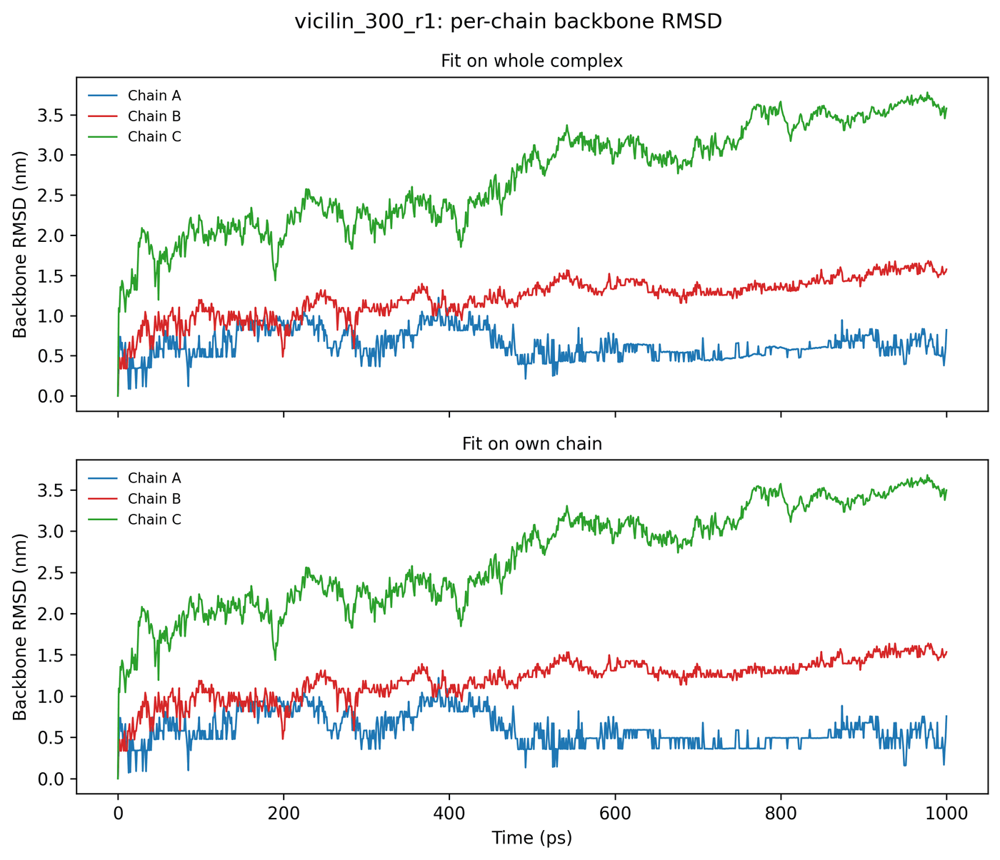


Analysis completed.
RMSD CSV: /content/drive/MyDrive/Plant Protein Extrusion MD/analysis/vicilin_300_r1/graphs/rmsd_per_chain.csv
Statistics: /content/drive/MyDrive/Plant Protein Extrusion MD/analysis/vicilin_300_r1/graphs/rmsd_per_chain_stats.csv
Graph: /content/drive/MyDrive/Plant Protein Extrusion MD/analysis/vicilin_300_r1/graphs/rmsd_per_chain.png

Statistics over the final 500 ps:
                      mean      sd  drift_per_ns
chainA_fit_complex  0.5740  0.1045        0.2898
chainA_fit_own      0.4888  0.1150        0.1245
chainB_fit_complex  1.4054  0.1126        0.4622
chainB_fit_own      1.3735  0.1082        0.4188
chainC_fit_complex  3.2906  0.2591        1.4765
chainC_fit_own      3.2266  0.2400        1.3606


In [ ]:
# ============================================================
# FAST, CHECKPOINTED VICILIN 300 K PER-CHAIN RMSD ANALYSIS
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import MDAnalysis as mda
from MDAnalysis.analysis import align, rms
from MDAnalysis.lib.distances import calc_bonds
from tqdm.auto import tqdm

# ---------------- PATHS ----------------
proj = "/content/drive/MyDrive/Plant Protein Extrusion MD"
gro = f"{proj}/md_300_r1.gro"
xtc = f"{proj}/md_300_r1.xtc"

graphs = f"{proj}/analysis/vicilin_300_r1/graphs"
os.makedirs(graphs, exist_ok=True)

checkpoint = f"{graphs}/rmsd_checkpoint.csv"
final_csv = f"{graphs}/rmsd_per_chain.csv"
stats_csv = f"{graphs}/rmsd_per_chain_stats.csv"
plot_png = f"{graphs}/rmsd_per_chain.png"

CHECKPOINT_EVERY = 25
LAST_PS = 500

assert os.path.isfile(gro), f"Missing GRO: {gro}"
assert os.path.isfile(xtc), f"Missing XTC: {xtc}"

# ---------------- LOAD TRAJECTORY ----------------
print("Loading topology...")

top = mda.Universe(gro)
protein_top = top.select_atoms("protein")

reader = mda.coordinates.XTC.XTCReader(xtc)
n_xtc = reader.n_atoms
reader.close()

print("Total GRO atoms:", top.atoms.n_atoms)
print("Protein GRO atoms:", protein_top.n_atoms)
print("XTC atoms:", n_xtc)

if n_xtc == top.atoms.n_atoms:
    u = mda.Universe(gro, xtc)
elif n_xtc == protein_top.n_atoms:
    u = mda.Merge(protein_top)
    u.load_new(xtc)
else:
    raise ValueError(
        "XTC atom count matches neither the full GRO nor the protein selection."
    )

prot = u.select_atoms("protein")
bb = prot.select_atoms("backbone")

if len(bb) == 0:
    raise ValueError("No protein backbone atoms found.")

# ---------------- DETECT CHAINS ----------------
# No guess_bonds() or unwrap(): these are unnecessary for
# the RMSD calculation if the coordinates are already suitable.

print("Detecting chains from backbone geometry...")

Cs = prot.select_atoms("name C")
Ns = prot.select_atoms("name N")

if not (len(Cs) == len(Ns) == len(prot.residues)):
    raise ValueError("Unexpected backbone atom counts; inspect topology.")

u.trajectory[0]

dist = calc_bonds(
    Cs.positions[:-1],
    Ns.positions[1:],
    box=u.dimensions
)

resids = prot.residues.resids
breaks = np.where(
    (dist > 2.0) | (np.diff(resids) < 0)
)[0] + 1

chains = [
    prot.residues[idx].atoms
    for idx in np.split(np.arange(len(prot.residues)), breaks)
]

print("Total frames:", len(u.trajectory))
print("Detected chains:", len(chains))
print("Residues per chain:", [len(c.residues) for c in chains])

if len(chains) != 3:
    raise ValueError(
        f"Expected 3 chains, detected {len(chains)}. "
        "Check chain segmentation before proceeding."
    )

chain_bb = [c.select_atoms("backbone") for c in chains]

# Map each chain's backbone atoms into the complex backbone.
masks = [
    np.isin(bb.indices, c.indices)
    for c in chain_bb
]

if not all(mask.any() for mask in masks):
    raise ValueError("At least one chain has no mapped backbone atoms.")

# ---------------- REFERENCE STRUCTURE ----------------
u.trajectory[0]

ref = bb.positions.copy()
ref -= ref.mean(axis=0)

chain_ref = [c.positions.copy() for c in chain_bb]

# ---------------- RESUME CHECKPOINT ----------------
columns = ["frame_index", "time_ps"]

for i in range(len(chains)):
    letter = chr(65 + i)
    columns += [
        f"chain{letter}_fit_complex",
        f"chain{letter}_fit_own"
    ]

if os.path.exists(checkpoint):
    saved = pd.read_csv(checkpoint)

    if not set(columns).issubset(saved.columns):
        raise ValueError(
            "Checkpoint columns do not match this analysis. "
            "Rename or inspect the checkpoint before restarting."
        )

    saved = saved[columns].drop_duplicates(
        subset="frame_index", keep="last"
    ).sort_values("frame_index")

    start_frame = (
        int(saved["frame_index"].iloc[-1]) + 1
        if len(saved) else 0
    )

    print(f"Resuming at frame {start_frame}/{len(u.trajectory)}")
else:
    saved = pd.DataFrame(columns=columns)
    start_frame = 0
    print("No checkpoint found. Starting from frame 0.")

if start_frame >= len(u.trajectory):
    print("All trajectory frames are already checkpointed.")
else:
    # ---------------- RMSD LOOP ----------------
    pending = []
    started = time.time()

    pbar = tqdm(
        total=len(u.trajectory),
        initial=start_frame,
        desc="Calculating RMSD",
        unit="frame"
    )

    try:
        for frame_index, ts in enumerate(u.trajectory):
            if frame_index < start_frame:
                continue

            # Fit entire complex to frame-0 reference.
            P = bb.positions.copy()
            P -= P.mean(axis=0)

            R, _ = align.rotation_matrix(P, ref)
            P_fit = P @ R.T

            row = {
                "frame_index": frame_index,
                "time_ps": float(ts.time)
            }

            # Per-chain RMSD after whole-complex fitting.
            for i, mask in enumerate(masks):
                letter = chr(65 + i)

                row[f"chain{letter}_fit_complex"] = (
                    np.sqrt(
                        np.mean(
                            np.sum(
                                (P_fit[mask] - ref[mask]) ** 2,
                                axis=1
                            )
                        )
                    ) / 10.0
                )

            # Per-chain RMSD after fitting each chain separately.
            for i, (chain, reference) in enumerate(
                zip(chain_bb, chain_ref)
            ):
                letter = chr(65 + i)

                row[f"chain{letter}_fit_own"] = (
                    rms.rmsd(
                        chain.positions,
                        reference,
                        center=True,
                        superposition=True
                    ) / 10.0
                )

            pending.append(row)
            pbar.update(1)

            # Save checkpoint frequently to limit lost work.
            if len(pending) >= CHECKPOINT_EVERY:
                updated = pd.concat(
                    [saved, pd.DataFrame(pending)],
                    ignore_index=True
                )

                temp = checkpoint + ".tmp"
                updated.to_csv(temp, index=False)
                os.replace(temp, checkpoint)

                saved = updated
                pending = []

                elapsed = time.time() - started
                pbar.set_postfix(
                    saved=len(saved),
                    elapsed_min=round(elapsed / 60, 1)
                )

        # Save the final partial batch.
        if pending:
            updated = pd.concat(
                [saved, pd.DataFrame(pending)],
                ignore_index=True
            )

            temp = checkpoint + ".tmp"
            updated.to_csv(temp, index=False)
            os.replace(temp, checkpoint)
            saved = updated

    finally:
        pbar.close()

# ---------------- FINALIZE RESULTS ----------------
# Reload the durable checkpoint rather than relying on memory.
saved = pd.read_csv(checkpoint)
saved = saved.drop_duplicates(
    subset="frame_index", keep="last"
).sort_values("frame_index")

expected = len(u.trajectory)

print(f"Frames saved: {len(saved)}/{expected}")

if len(saved) != expected:
    print(
        "Analysis is incomplete. The checkpoint is preserved; "
        "rerun this cell to resume."
    )
else:
    # Final CSV: same columns as the original analysis.
    output = saved.drop(columns=["frame_index"])
    output.to_csv(final_csv, index=False)

    # ---------------- SUMMARY STATISTICS ----------------
    t = output["time_ps"].to_numpy()
    value_cols = [
        c for c in output.columns if c != "time_ps"
    ]

    recent = t >= t.max() - LAST_PS

    if recent.sum() < 2:
        raise ValueError(
            "Insufficient frames in the final 500 ps for statistics."
        )

    stats = pd.DataFrame({
        name: [
            output.loc[recent, name].mean(),
            output.loc[recent, name].std(),
            np.polyfit(
                t[recent],
                output.loc[recent, name],
                1
            )[0] * 1000
        ]
        for name in value_cols
    }, index=["mean", "sd", "drift_per_ns"]).T.round(4)

    stats.to_csv(stats_csv)

    # ---------------- PLOT ----------------
    colors = [
        "#1f77b4", "#d62728", "#2ca02c",
        "#ff7f0e", "#9467bd", "#8c564b"
    ]

    complex_cols = [
        f"chain{chr(65+i)}_fit_complex"
        for i in range(len(chains))
    ]
    own_cols = [
        f"chain{chr(65+i)}_fit_own"
        for i in range(len(chains))
    ]

    fig, axes = plt.subplots(
        2, 1, figsize=(8, 7),
        sharex=True, dpi=300
    )

    for ax, names, title in [
        (axes[0], complex_cols, "Fit on whole complex"),
        (axes[1], own_cols, "Fit on own chain")
    ]:
        for i, name in enumerate(names):
            ax.plot(
                t, output[name],
                color=colors[i],
                lw=1.0,
                label=f"Chain {chr(65+i)}"
            )

        ax.set_ylabel("Backbone RMSD (nm)")
        ax.set_title(title, fontsize=10)
        ax.legend(frameon=False, fontsize=8)

    axes[1].set_xlabel("Time (ps)")
    fig.suptitle("vicilin_300_r1: per-chain backbone RMSD")
    fig.tight_layout()
    fig.savefig(plot_png, dpi=300)
    plt.show()
    plt.close(fig)

    print("\nAnalysis completed.")
    print("RMSD CSV:", final_csv)
    print("Statistics:", stats_csv)
    print("Graph:", plot_png)
    print("\nStatistics over the final 500 ps:")
    print(stats)

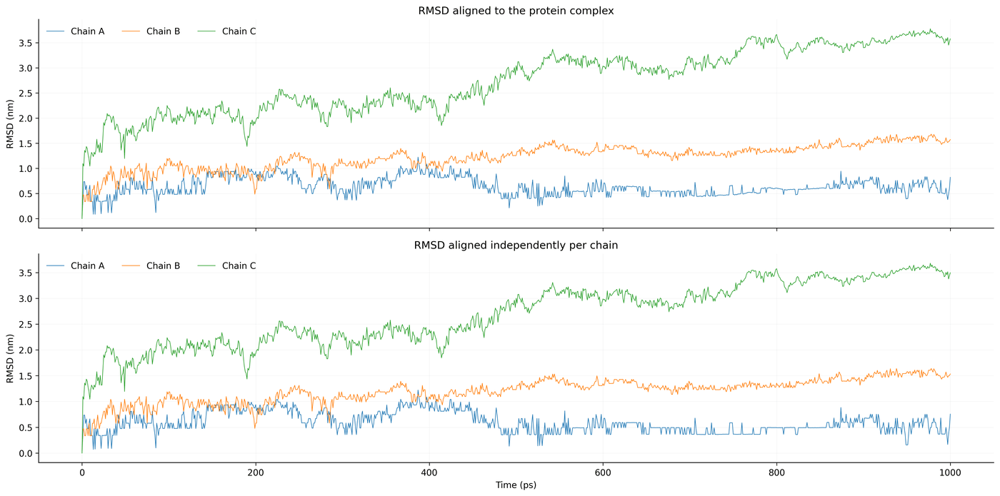

Saved: /content/drive/MyDrive/Plant Protein Extrusion MD/analysis/vicilin_300_r1/graphs/rmsd_per_chain_landscape.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

proj = "/content/drive/MyDrive/Plant Protein Extrusion MD"
folder = f"{proj}/analysis/vicilin_300_r1/graphs"

# Reuse existing RMSD data — no recalculation
df = pd.read_csv(f"{folder}/rmsd_per_chain.csv")
t = df["time_ps"].to_numpy()

fig, axes = plt.subplots(
    2, 1,
    figsize=(16, 8),
    sharex=True,
    dpi=300
)

# Complex-aligned RMSD
for chain in ["A", "B", "C"]:
    axes[0].plot(
        t, df[f"chain{chain}_fit_complex"],
        linewidth=0.65,
        label=f"Chain {chain}"
    )

axes[0].set_ylabel("RMSD (nm)")
axes[0].set_title("RMSD aligned to the protein complex")
axes[0].legend(frameon=False, ncol=3)

# Individually aligned RMSD
for chain in ["A", "B", "C"]:
    axes[1].plot(
        t, df[f"chain{chain}_fit_own"],
        linewidth=0.65,
        label=f"Chain {chain}"
    )

axes[1].set_xlabel("Time (ps)")
axes[1].set_ylabel("RMSD (nm)")
axes[1].set_title("RMSD aligned independently per chain")
axes[1].legend(frameon=False, ncol=3)

for ax in axes:
    ax.grid(True, linewidth=0.35, alpha=0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(direction="out", width=0.7)

fig.tight_layout()

out = f"{folder}/rmsd_per_chain_landscape.png"
fig.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

print("Saved:", out)

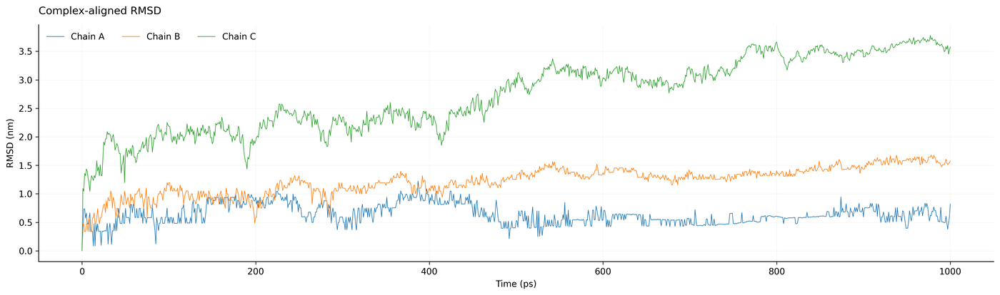

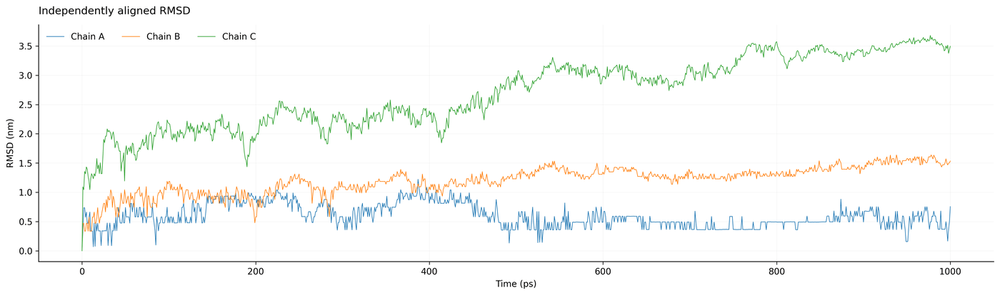

Both separate landscape graphs saved successfully.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

proj = "/content/drive/MyDrive/Plant Protein Extrusion MD"
folder = f"{proj}/analysis/vicilin_300_r1/graphs"

df = pd.read_csv(f"{folder}/rmsd_per_chain.csv")
t = df["time_ps"].to_numpy()

# Graph 1: Complex-aligned RMSD
fig, ax = plt.subplots(figsize=(16, 4.8), dpi=300)

for chain in ["A", "B", "C"]:
    ax.plot(
        t, df[f"chain{chain}_fit_complex"],
        linewidth=0.65,
        label=f"Chain {chain}"
    )

ax.set_xlabel("Time (ps)")
ax.set_ylabel("RMSD (nm)")
ax.set_title("Complex-aligned RMSD", loc="left", pad=12)
ax.legend(frameon=False, ncol=3)
ax.grid(True, linewidth=0.35, alpha=0.2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out", width=0.7)
fig.tight_layout()

fig.savefig(
    f"{folder}/rmsd_complex_landscape.png",
    dpi=300, bbox_inches="tight", facecolor="white"
)
plt.show()
plt.close(fig)


# Graph 2: Independently aligned RMSD
fig, ax = plt.subplots(figsize=(16, 4.8), dpi=300)

for chain in ["A", "B", "C"]:
    ax.plot(
        t, df[f"chain{chain}_fit_own"],
        linewidth=0.65,
        label=f"Chain {chain}"
    )

ax.set_xlabel("Time (ps)")
ax.set_ylabel("RMSD (nm)")
ax.set_title("Independently aligned RMSD", loc="left", pad=12)
ax.legend(frameon=False, ncol=3)
ax.grid(True, linewidth=0.35, alpha=0.2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(direction="out", width=0.7)
fig.tight_layout()

fig.savefig(
    f"{folder}/rmsd_individual_landscape.png",
    dpi=300, bbox_inches="tight", facecolor="white"
)
plt.show()
plt.close(fig)

print("Both separate landscape graphs saved successfully.")

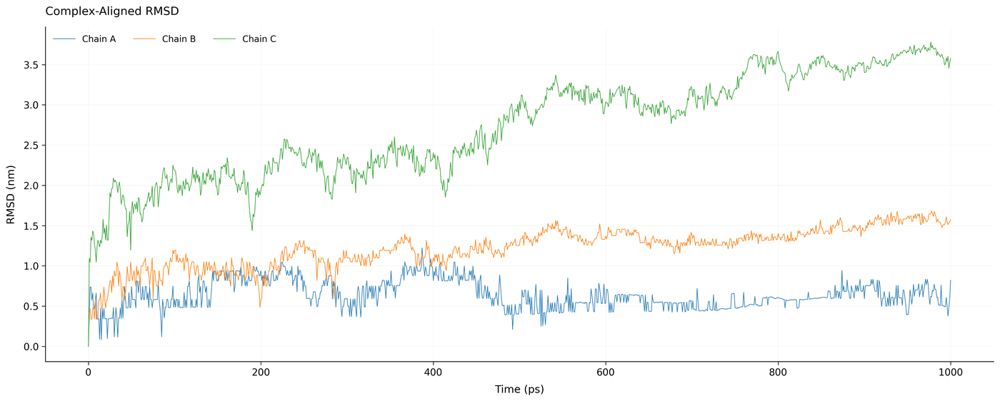

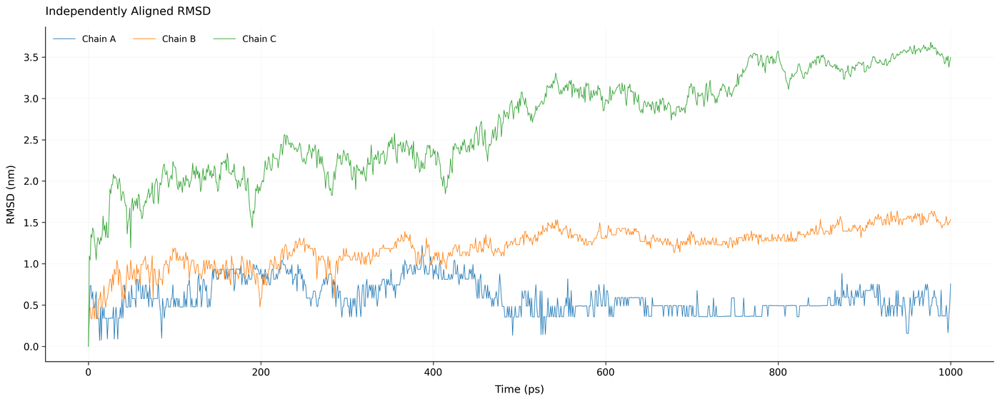


Both RMSD graphs saved successfully:
/content/drive/MyDrive/Plant Protein Extrusion MD/analysis/vicilin_300_r1/graphs/rmsd_complex_landscape.png
/content/drive/MyDrive/Plant Protein Extrusion MD/analysis/vicilin_300_r1/graphs/rmsd_individual_landscape.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Project paths
proj = "/content/drive/MyDrive/Plant Protein Extrusion MD"
folder = f"{proj}/analysis/vicilin_300_r1/graphs"
os.makedirs(folder, exist_ok=True)

# Load existing RMSD results
df = pd.read_csv(f"{folder}/rmsd_per_chain.csv")
t = df["time_ps"].to_numpy()

# Consistent clean scientific styling
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "legend.fontsize": 10,
    "lines.linewidth": 0.65,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white"
})

# ==========================================
# GRAPH 1: COMPLEX-ALIGNED RMSD
# ==========================================
fig, ax = plt.subplots(figsize=(16, 6.5), dpi=300)

for chain in ["A", "B", "C"]:
    ax.plot(
        t,
        df[f"chain{chain}_fit_complex"],
        linewidth=0.65,
        label=f"Chain {chain}"
    )

ax.set_xlabel("Time (ps)", labelpad=8)
ax.set_ylabel("RMSD (nm)", labelpad=8)
ax.set_title("Complex-Aligned RMSD", loc="left", pad=14)

ax.legend(
    loc="best",
    frameon=False,
    ncol=3,
    handlelength=2.5
)

ax.grid(True, linewidth=0.35, alpha=0.20)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", direction="out", width=0.7, length=4)

fig.tight_layout()

fig.savefig(
    f"{folder}/rmsd_complex_landscape.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)


# ==========================================
# GRAPH 2: INDEPENDENTLY ALIGNED RMSD
# ==========================================
fig, ax = plt.subplots(figsize=(16, 6.5), dpi=300)

for chain in ["A", "B", "C"]:
    ax.plot(
        t,
        df[f"chain{chain}_fit_own"],
        linewidth=0.65,
        label=f"Chain {chain}"
    )

ax.set_xlabel("Time (ps)", labelpad=8)
ax.set_ylabel("RMSD (nm)", labelpad=8)
ax.set_title("Independently Aligned RMSD", loc="left", pad=14)

ax.legend(
    loc="best",
    frameon=False,
    ncol=3,
    handlelength=2.5
)

ax.grid(True, linewidth=0.35, alpha=0.20)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", direction="out", width=0.7, length=4)

fig.tight_layout()

fig.savefig(
    f"{folder}/rmsd_individual_landscape.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("\nBoth RMSD graphs saved successfully:")
print(f"{folder}/rmsd_complex_landscape.png")
print(f"{folder}/rmsd_individual_landscape.png")

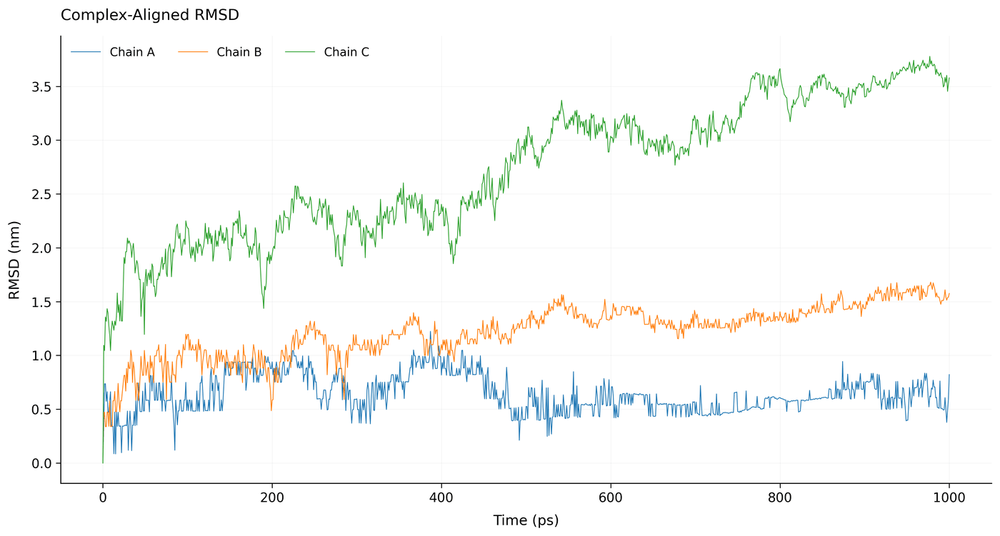

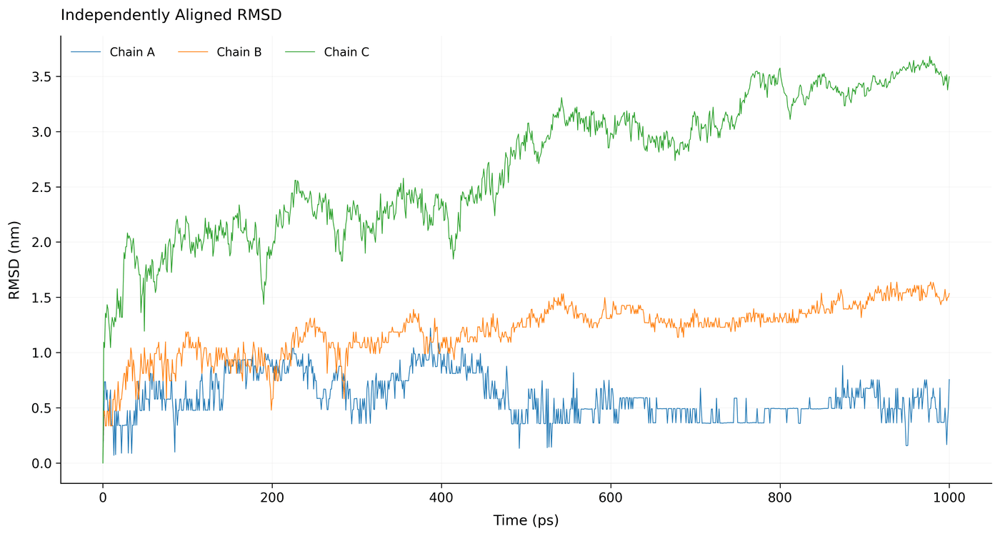

Both separate landscape graphs saved successfully.
Complex-aligned: /content/drive/MyDrive/Plant Protein Extrusion MD/analysis/vicilin_300_r1/graphs/rmsd_complex_landscape.png
Independently aligned: /content/drive/MyDrive/Plant Protein Extrusion MD/analysis/vicilin_300_r1/graphs/rmsd_individual_landscape.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

proj = "/content/drive/MyDrive/Plant Protein Extrusion MD"
folder = f"{proj}/analysis/vicilin_300_r1/graphs"
os.makedirs(folder, exist_ok=True)

# Reuse existing RMSD data
df = pd.read_csv(f"{folder}/rmsd_per_chain.csv")
t = df["time_ps"].to_numpy()

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "legend.fontsize": 10,
    "lines.linewidth": 0.65,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white"
})

def style_graph(ax, title):
    ax.set_xlabel("Time (ps)", labelpad=8)
    ax.set_ylabel("RMSD (nm)", labelpad=8)
    ax.set_title(title, loc="left", pad=14)
    ax.legend(frameon=False, ncol=3, handlelength=2.5)
    ax.grid(True, linewidth=0.35, alpha=0.20)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", direction="out", width=0.7, length=4)

# GRAPH 1: Complex-aligned RMSD
fig, ax = plt.subplots(figsize=(12, 6.5), dpi=300)

for chain in ["A", "B", "C"]:
    ax.plot(t, df[f"chain{chain}_fit_complex"],
            linewidth=0.65, label=f"Chain {chain}")

style_graph(ax, "Complex-Aligned RMSD")
fig.tight_layout()
fig.savefig(f"{folder}/rmsd_complex_landscape.png",
            dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)

# GRAPH 2: Independently aligned RMSD
fig, ax = plt.subplots(figsize=(12, 6.5), dpi=300)

for chain in ["A", "B", "C"]:
    ax.plot(t, df[f"chain{chain}_fit_own"],
            linewidth=0.65, label=f"Chain {chain}")

style_graph(ax, "Independently Aligned RMSD")
fig.tight_layout()
fig.savefig(f"{folder}/rmsd_individual_landscape.png",
            dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig)

print("Both separate landscape graphs saved successfully.")
print("Complex-aligned:", f"{folder}/rmsd_complex_landscape.png")
print("Independently aligned:", f"{folder}/rmsd_individual_landscape.png")

In [ ]:
import os
os.environ["P"]  = "/content/drive/MyDrive/Plant Protein Extrusion MD"
os.environ["S"]  = "md_300_r2"   # file prefix
os.environ["OUT"] = os.environ["P"] + "/analysism/vicilin_300_r2"
for d in ["graphs","logs","frames","xvgs"]:
    os.makedirs(f'{os.environ["OUT"]}/{d}', exist_ok=True)

In [ ]:
%%bash
cd "$P"
ls -lh $S.tpr $S.xtc $S.edr $S.gro
gmx check -f $S.xtc 2>&1 | grep -E "Last frame|Reading frame|Step|Time" | tail -5
gmx check -e $S.edr 2>&1 | grep -E "Last frame|Reading frame" | tail -3

-rw------- 1 root root 552K Oct 10 18:22 md_300_r2.edr
-rw------- 1 root root  12M Oct 10 19:08 md_300_r2.gro
-rw------- 1 root root 8.8M Oct 10 18:22 md_300_r2.tpr
-rw------- 1 root root  73M Oct 10 18:22 md_300_r2.xtc


In [ ]:
import os
os.environ["PATH"] = "/content/gmx/bin:" + os.environ["PATH"]

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
os.environ["P"]   = "/content/drive/MyDrive/Plant Protein Extrusion MD"
os.environ["S"]   = "md_300_r2"
os.environ["OUT"] = os.environ["P"] + "/analysism/vicilin_300_r2"
for d in ["graphs","logs","frames","xvgs"]:
    os.makedirs(f'{os.environ["OUT"]}/{d}', exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
%%bash
ls /content/gmx/bin/gmx 2>&1
ls /content/bin/micromamba 2>&1
which gmx || echo "gmx not on PATH"

ls: cannot access '/content/gmx/bin/gmx': No such file or directory
ls: cannot access '/content/bin/micromamba': No such file or directory
gmx not on PATH


In [ ]:
%%bash
which gmx
gmx --version | head -3

bash: line 2: gmx: command not found


In [ ]:
%%bash
ls -d /usr/local/envs/gmx_cuda/bin/gmx /opt/conda/envs/gmx_cuda/bin/gmx 2>/dev/null
G=$(ls /usr/local/envs/gmx_cuda/bin/gmx /opt/conda/envs/gmx_cuda/bin/gmx 2>/dev/null | head -1)
echo "found: $G"
ln -sf "$G" /usr/local/bin/gmx
gmx --version | head -5

/usr/local/envs/gmx_cuda/bin/gmx
found: /usr/local/envs/gmx_cuda/bin/gmx
                   :-) GROMACS - gmx, 2026.3-conda_forge (-:

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
os.environ["P"]   = "/content/drive/MyDrive/Plant Protein Extrusion MD"
os.environ["S"]   = "md_300_r2"
os.environ["OUT"] = os.environ["P"] + "/analysism/vicilin_300_r2"
for d in ["graphs","logs","frames","xvgs"]:
    os.makedirs(f'{os.environ["OUT"]}/{d}', exist_ok=True)
print(os.listdir(os.environ["OUT"]))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['graphs', 'logs', 'frames', 'xvgs']


In [ ]:
%%bash
cd "$P"
ls -lh $S.*
gmx check -f $S.xtc 2>&1 | tail -25
echo ---- TPR ----
gmx dump -s $S.tpr 2>/dev/null | grep -E "^\s+(nsteps|dt|nstxout-compressed)\s"

-rw------- 1 root root 4.0M Oct 10 19:08 md_300_r2.cpt
-rw------- 1 root root 552K Oct 10 18:22 md_300_r2.edr
-rw------- 1 root root  12M Oct 10 19:08 md_300_r2.gro
-rw------- 1 root root  89K Oct 10 19:08 md_300_r2.log
-rw------- 1 root root  403 Oct 10 18:22 md_300_r2.mdp
-rw------- 1 root root 8.8M Oct 10 18:22 md_300_r2.tpr
-rw------- 1 root root  73M Oct 10 18:22 md_300_r2.xtc

Executable:   /usr/local/envs/gmx_cuda/bin.AVX2_256/gmx
Data prefix:  /usr/local/envs/gmx_cuda
Working dir:  /content/drive/MyDrive/Plant Protein Extrusion MD
Command line:
  gmx check -f md_300_r2.xtc

Reading frame       0 time    0.000   
# Atoms  19941
Precision 0.001 (nm)
Last frame       1000 time 1000.000   


Item        #frames Timestep (ps)
Step          1001    1
Time          1001    1
Lambda           0
Coords        1001    1
Velocities       0
Forces           0
Box           1001    1

GROMACS reminds you: "I've Got Two Turntables and a Microphone" (B. Hansen)

Checking file md_300_r2.xtc
--

In [ ]:
import os
os.system('ln -sfn "/content/drive/MyDrive/Plant Protein Extrusion MD" /content/pm')
os.environ["P"]   = "/content/pm"
os.environ["S"]   = "md_300_r2"
os.environ["OUT"] = "/content/pm/analysism/vicilin_300_r2"
for d in ["graphs","logs","frames","xvgs"]:
    os.makedirs(f'{os.environ["OUT"]}/{d}', exist_ok=True)
print(os.listdir("/content/pm/analysism/vicilin_300_r2"))

['graphs', 'logs', 'frames', 'xvgs']


In [ ]:
%%bash
cd "$P"
F="$OUT/frames"

printf "Protein\n" | gmx convert-tpr -s $S.tpr -o "$F/protein.tpr" 2>&1 | tail -4
gmx dump -s "$F/protein.tpr" 2>/dev/null | grep -m1 natoms

printf "Protein\n" | gmx trjconv -s "$F/protein.tpr" -f $S.xtc -o "$F/whole.xtc" -pbc whole 2>&1 | tail -2
printf "Protein\n" | gmx trjconv -s "$F/protein.tpr" -f "$F/whole.xtc" -o "$F/nojump.xtc" -pbc nojump 2>&1 | tail -2
printf "Backbone\nProtein\n" | gmx trjconv -s "$F/protein.tpr" -f "$F/nojump.xtc" -o "$F/fit_skip5.xtc" -fit rot+trans -skip 5 2>&1 | tail -2

rm -f "$F/whole.xtc" "$F/nojump.xtc"
gmx check -f "$F/fit_skip5.xtc" 2>&1 | grep -E "# Atoms|Last frame|Step" || true


GROMACS reminds you: "Do You Have a Mind of Your Own ?" (Garbage)

Selected 1: 'Protein'
   natoms = 19941
Select group for output
Selected 1: 'Protein'
Select group for output
Selected 1: 'Protein'
Select group for output
Selected 1: 'Protein'
# Atoms  19941
Last frame        200 time 1000.000   
Step           201    5


In [ ]:
%%bash
cd "$P"
F="$OUT/frames"
printf "Backbone\nBackbone\n" | gmx rms -s "$F/protein.tpr" -f "$F/fit_skip5.xtc" \
  -o "$OUT/xvgs/rmsd_backbone.xvg" -tu ns 2>&1 | tee "$OUT/logs/rmsd.log" | tail -2
grep -E "^@ (title|xaxis|yaxis)" "$OUT/xvgs/rmsd_backbone.xvg"
tail -2 "$OUT/xvgs/rmsd_backbone.xvg"

Selected 4: 'Backbone'
Selected 4: 'Backbone'
   0.9950001    0.2659630
   1.0000000    0.2711204


In [ ]:
%%bash
cd "$OUT/frames"
printf "splitch 1\nq\n" | gmx make_ndx -f protein.tpr -o chains.ndx 2>&1 | grep -E "^ *[0-9]+ " | tail -15

  0 System              : 19941 atoms
  1 Protein             : 19941 atoms
  2 Protein-H           : 10017 atoms
  3 C-alpha             :  1245 atoms
  4 Backbone            :  3735 atoms
  5 MainChain           :  4983 atoms
  6 MainChain+Cb        :  6168 atoms
  7 MainChain+H         :  6180 atoms
  8 SideChain           : 13761 atoms
  9 SideChain-H         :  5034 atoms


In [ ]:
%%bash
cd "$P"
# gro line = atom number + 2; print the last atom of a chain and the first of the next
for a in 1 6647 6648 13294 13295 19941; do sed -n "$((a+2))p" $S.gro | cut -c1-20; done

    1SER      N    1
  415GLU    OC2 6647
    1SER      N 6648
  415GLU    OC213294
    1SER      N13295
  415GLU    OC219941


In [ ]:
import os
P, S, OUT = os.environ["P"], os.environ["S"], os.environ["OUT"]
L = open(f"{P}/{S}.gro").read().split("\n")
atoms = L[2:2+19941]
name = [a[10:15].strip() for a in atoms]

chains = {"chA": range(1,6648), "chB": range(6648,13295), "chC": range(13295,19942)}
groups = {}
for c, r in chains.items():
    groups[c]          = list(r)
    groups[c+"_bb"]    = [i for i in r if name[i-1] in ("N","CA","C")]
    groups[c+"_CA"]    = [i for i in r if name[i-1] == "CA"]

with open(f"{OUT}/frames/chains.ndx", "w") as f:
    for g, idx in groups.items():
        f.write(f"[ {g} ]\n")
        for k in range(0, len(idx), 15):
            f.write(" ".join(f"{i:4d}" for i in idx[k:k+15]) + "\n")
for g, idx in groups.items(): print(g, len(idx))

chA 6647
chA_bb 1245
chA_CA 415
chB 6647
chB_bb 1245
chB_CA 415
chC 6647
chC_bb 1245
chC_CA 415


In [ ]:
%%bash
cd "$P"
F="$OUT/frames"
for c in chA chB chC; do
  printf "${c}_bb\n${c}_bb\n" | gmx rms -s "$F/protein.tpr" -f "$F/fit_skip5.xtc" -n "$F/chains.ndx" \
    -o "$OUT/xvgs/rmsd_${c}.xvg" -tu ns > "$OUT/logs/rmsd_${c}.log" 2>&1
  echo $c; tail -1 "$OUT/xvgs/rmsd_${c}.xvg"
done

chA
   1.0000000    0.1379955
chB
   1.0000000    0.1409407
chC
   1.0000000    0.1383121


In [ ]:
%%bash
cd "$P"
F="$OUT/frames"
for c in chA chB chC; do
  printf "${c}_CA\n${c}_CA\n" | gmx rmsf -s "$F/protein.tpr" -f "$F/fit_skip5.xtc" -n "$F/chains.ndx" \
    -o "$OUT/xvgs/rmsf_${c}.xvg" -res > "$OUT/logs/rmsf_${c}.log" 2>&1
  echo $c; grep -vc "^[@#]" "$OUT/xvgs/rmsf_${c}.xvg"
done

chA
415
chB
415
chC
415


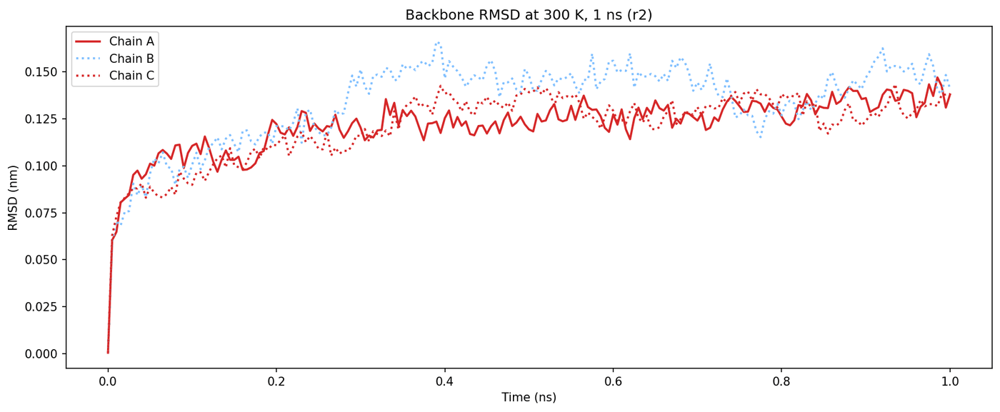

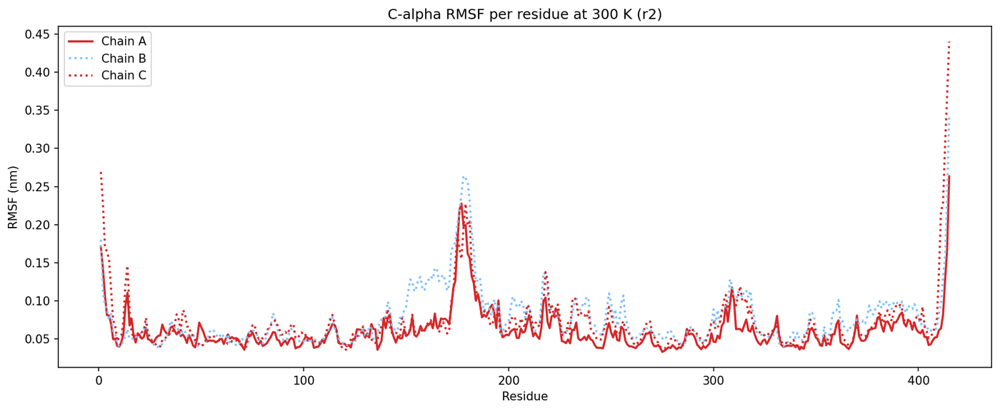

In [ ]:
import numpy as np, matplotlib.pyplot as plt, os
OUT = os.environ["OUT"]
def xvg(f): return np.loadtxt(f, comments=('#','@'))
sty = {"chA": dict(color="#d62728", ls="-",  label="Chain A"),
       "chB": dict(color="#7fbfff", ls=":",  label="Chain B"),
       "chC": dict(color="#d62728", ls=":",  label="Chain C")}

def plot(prefix, xlabel, ylabel, title, out, tcol=0):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        d = xvg(f"{OUT}/xvgs/{prefix}_{c}.xvg")
        ax.plot(d[:,0], d[:,1], lw=1.8, **s)
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    ax.legend(); fig.tight_layout()
    fig.savefig(f"{OUT}/graphs/{out}.png"); plt.show()

plot("rmsd", "Time (ns)", "RMSD (nm)", "Backbone RMSD at 300 K, 1 ns (r2)", "rmsd_per_chain")
plot("rmsf", "Residue", "RMSF (nm)", "C-alpha RMSF per residue at 300 K (r2)", "rmsf_per_chain")

In [ ]:
%%bash
cd "$P"
F="$OUT/frames"
printf "Backbone\nBackbone\n" | gmx rms -s "$F/protein.tpr" -f "$F/fit_skip5.xtc" \
  -o "$OUT/xvgs/rmsd_protein.xvg" -tu ns > "$OUT/logs/rmsd_protein.log" 2>&1
tail -1 "$OUT/xvgs/rmsd_protein.xvg"

   1.0000000    0.2711204


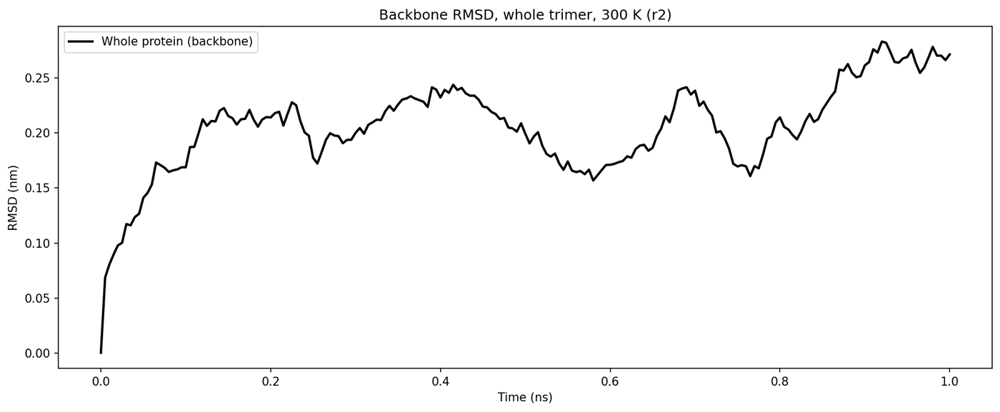

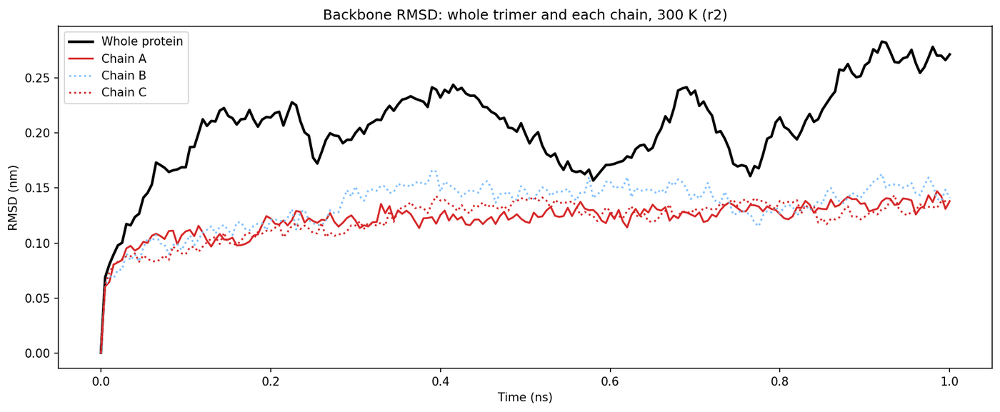

In [ ]:
import numpy as np, matplotlib.pyplot as plt, os
OUT = os.environ["OUT"]
def xvg(f): return np.loadtxt(f, comments=('#','@'))
p = xvg(f"{OUT}/xvgs/rmsd_protein.xvg")

# combined only
fig, ax = plt.subplots(figsize=(12,5), dpi=150)
ax.plot(p[:,0], p[:,1], color="black", lw=2, label="Whole protein (backbone)")
ax.set(xlabel="Time (ns)", ylabel="RMSD (nm)", title="Backbone RMSD, whole trimer, 300 K (r2)")
ax.legend(); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/rmsd_protein.png"); plt.show()

# combined + chains
sty = {"chA": dict(color="#d62728", ls="-", label="Chain A"),
       "chB": dict(color="#7fbfff", ls=":", label="Chain B"),
       "chC": dict(color="#d62728", ls=":", label="Chain C")}
fig, ax = plt.subplots(figsize=(12,5), dpi=150)
ax.plot(p[:,0], p[:,1], color="black", lw=2.2, label="Whole protein")
for c, s in sty.items():
    d = xvg(f"{OUT}/xvgs/rmsd_{c}.xvg"); ax.plot(d[:,0], d[:,1], lw=1.6, **s)
ax.set(xlabel="Time (ns)", ylabel="RMSD (nm)", title="Backbone RMSD: whole trimer and each chain, 300 K (r2)")
ax.legend(); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/rmsd_protein_and_chains.png"); plt.show()

In [ ]:
%%bash
cd "$P"
F="$OUT/frames"
printf "Protein\n" | gmx trjconv -s "$F/protein.tpr" -f "$F/fit_skip5.xtc" -o "$F/first.gro" -dump 0 2>&1 | tail -1
pip install -q MDAnalysis

Selected 1: 'Protein'


chA 415 0.109
chB 415 0.12
chC 415 0.105


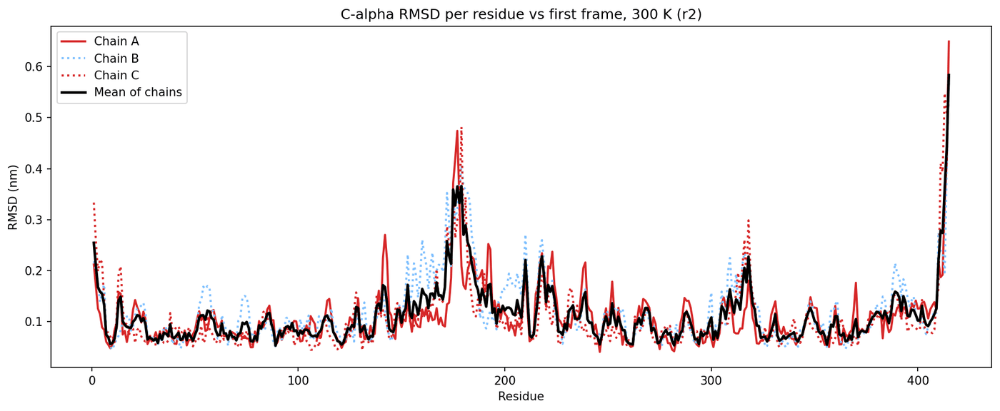

In [ ]:
import os, numpy as np, MDAnalysis as mda, matplotlib.pyplot as plt
from MDAnalysis.analysis.align import rotation_matrix
OUT = os.environ["OUT"]
u = mda.Universe(f"{OUT}/frames/first.gro", f"{OUT}/frames/fit_skip5.xtc")

chains = {"chA": slice(0,6647), "chB": slice(6647,13294), "chC": slice(13294,19941)}
res = {}
for name, sl in chains.items():
    ch = u.atoms[sl]
    bb = ch.select_atoms("name N CA C"); ca = ch.select_atoms("name CA")
    u.trajectory[0]
    c0 = bb.positions.mean(0); bb0 = bb.positions - c0; ca0 = ca.positions - c0
    d2 = np.zeros(len(ca)); n = 0
    for ts in u.trajectory:                      # fit each chain on its own backbone
        c = bb.positions.mean(0)
        R, _ = rotation_matrix(bb.positions - c, bb0)
        d2 += (((ca.positions - c) @ R.T - ca0)**2).sum(1); n += 1
    rms = np.sqrt(d2/n) / 10.0                   # Angstrom -> nm
    res[name] = (ca.resids, rms)
    with open(f"{OUT}/xvgs/rmsd_perres_{name}.xvg","w") as f:
        f.write('@ title "RMSD per residue"\n@ xaxis label "Residue"\n@ yaxis label "RMSD (nm)"\n')
        for r, v in zip(ca.resids, rms): f.write(f"{r} {v:.6f}\n")
    print(name, len(rms), round(rms.mean(),3))

sty = {"chA": dict(color="#d62728", ls="-", label="Chain A"),
       "chB": dict(color="#7fbfff", ls=":", label="Chain B"),
       "chC": dict(color="#d62728", ls=":", label="Chain C")}
fig, ax = plt.subplots(figsize=(12,5), dpi=150)
for c, s in sty.items(): ax.plot(*res[c], lw=1.8, **s)
mean = np.mean([res[c][1] for c in res], axis=0)
ax.plot(res["chA"][0], mean, color="black", lw=2.2, label="Mean of chains")
ax.set(xlabel="Residue", ylabel="RMSD (nm)", title="C-alpha RMSD per residue vs first frame, 300 K (r2)")
ax.legend(); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/rmsd_per_residue.png"); plt.show()

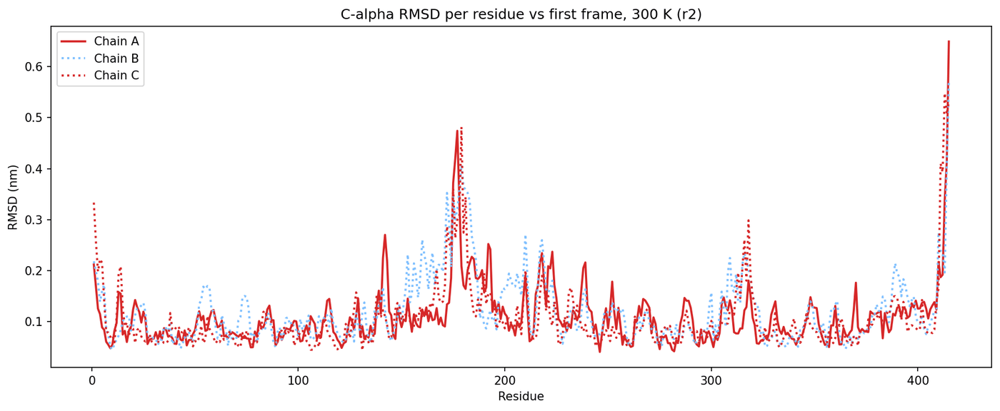

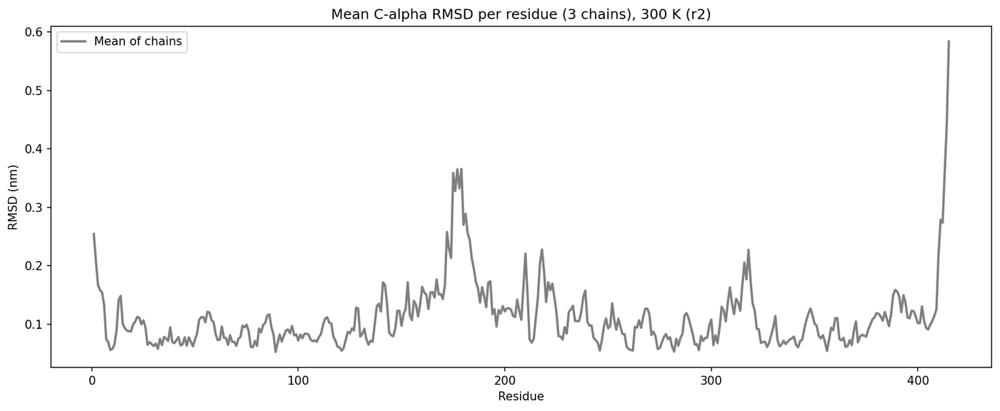

In [ ]:
import os, numpy as np, matplotlib.pyplot as plt
OUT = os.environ["OUT"]
def xvg(f): return np.loadtxt(f, comments=('#','@'))
d = {c: xvg(f"{OUT}/xvgs/rmsd_perres_{c}.xvg") for c in ["chA","chB","chC"]}

sty = {"chA": dict(color="#d62728", ls="-", label="Chain A"),
       "chB": dict(color="#7fbfff", ls=":", label="Chain B"),
       "chC": dict(color="#d62728", ls=":", label="Chain C")}

# 1) per chain, no mean
fig, ax = plt.subplots(figsize=(12,5), dpi=150)
for c, s in sty.items():
    ax.plot(d[c][:,0], d[c][:,1], lw=1.8, **s)
ax.set(xlabel="Residue", ylabel="RMSD (nm)", title="C-alpha RMSD per residue vs first frame, 300 K (r2)")
ax.legend(); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/rmsd_per_residue.png"); plt.show()

# 2) mean of chains only, grey
res = d["chA"][:,0]
mean = np.mean([d[c][:,1] for c in d], axis=0)
with open(f"{OUT}/xvgs/rmsd_perres_mean.xvg","w") as f:
    f.write('@ title "Mean RMSD per residue"\n@ xaxis label "Residue"\n@ yaxis label "RMSD (nm)"\n')
    for r, v in zip(res, mean): f.write(f"{int(r)} {v:.6f}\n")

fig, ax = plt.subplots(figsize=(12,5), dpi=150)
ax.plot(res, mean, color="grey", lw=2, label="Mean of chains")
ax.set(xlabel="Residue", ylabel="RMSD (nm)", title="Mean C-alpha RMSD per residue (3 chains), 300 K (r2)")
ax.legend(); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/rmsd_per_residue_mean.png"); plt.show()

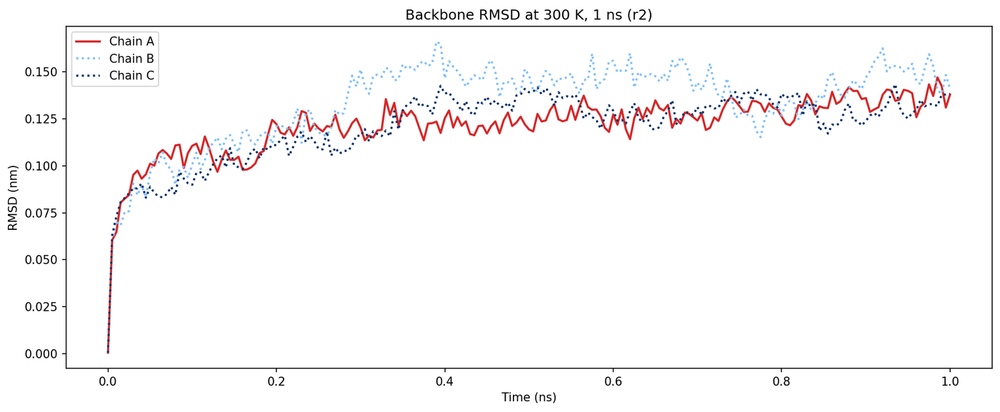

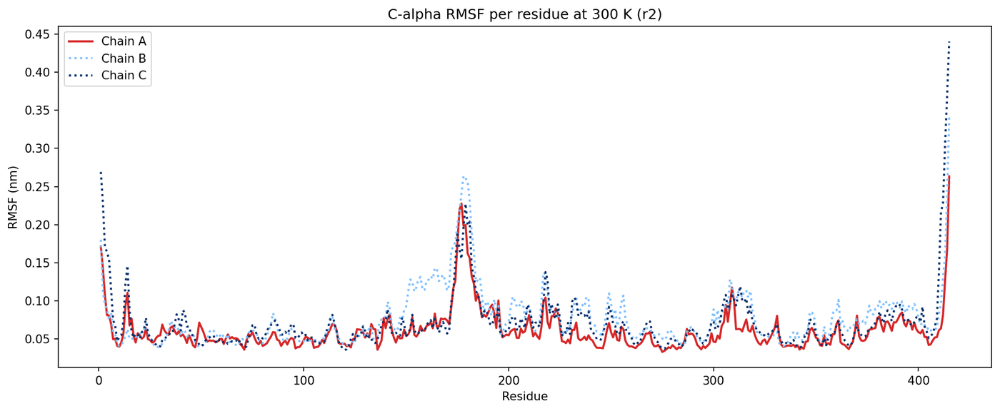

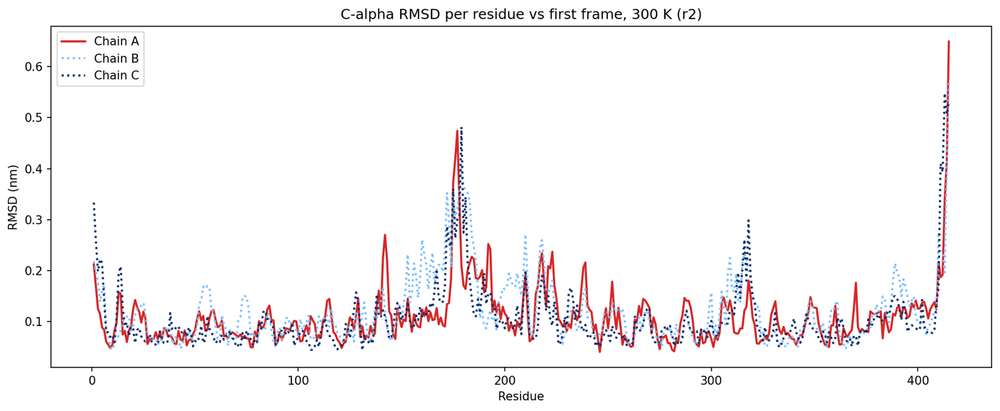

In [ ]:
import os, numpy as np, matplotlib.pyplot as plt
OUT = os.environ["OUT"]
def xvg(f): return np.loadtxt(f, comments=('#','@'))

sty = {"chA": dict(color="#d62728", ls="-", label="Chain A"),
       "chB": dict(color="#7fbfff", ls=":", label="Chain B"),
       "chC": dict(color="#08306b", ls=":", label="Chain C")}

def plot(prefix, xlabel, ylabel, title, out, grey=None):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        d = xvg(f"{OUT}/xvgs/{prefix}_{c}.xvg")
        ax.plot(d[:,0], d[:,1], lw=1.8, **s)
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    ax.legend(); fig.tight_layout()
    fig.savefig(f"{OUT}/graphs/{out}.png"); plt.show()

plot("rmsd",        "Time (ns)", "RMSD (nm)", "Backbone RMSD at 300 K, 1 ns (r2)",              "rmsd_per_chain")
plot("rmsf",        "Residue",   "RMSF (nm)", "C-alpha RMSF per residue at 300 K (r2)",           "rmsf_per_chain")
plot("rmsd_perres", "Residue",   "RMSD (nm)", "C-alpha RMSD per residue vs first frame, 300 K (r2)", "rmsd_per_residue")

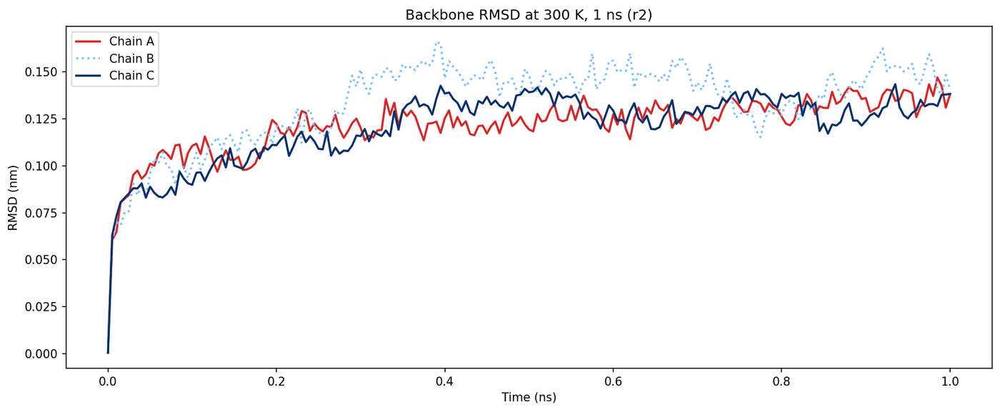

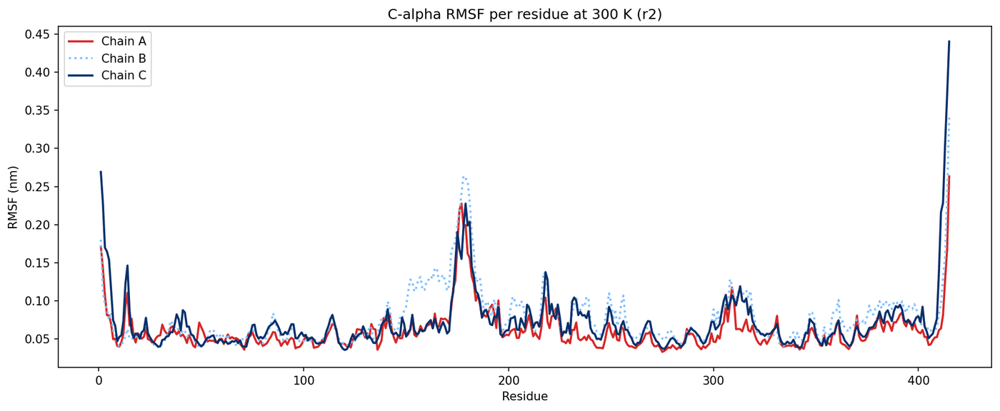

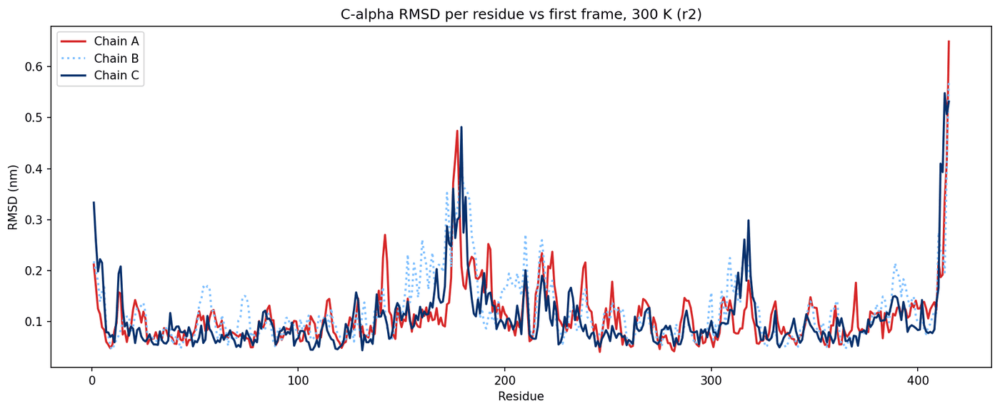

In [ ]:
import os, numpy as np, matplotlib.pyplot as plt
OUT = os.environ["OUT"]
def xvg(f): return np.loadtxt(f, comments=('#','@'))

sty = {"chA": dict(color="#d62728", ls="-", label="Chain A"),
       "chB": dict(color="#7fbfff", ls=":", label="Chain B"),
       "chC": dict(color="#08306b", ls="-", label="Chain C")}

def plot(prefix, xlabel, ylabel, title, out):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        d = xvg(f"{OUT}/xvgs/{prefix}_{c}.xvg")
        ax.plot(d[:,0], d[:,1], lw=1.8, **s)
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    ax.legend(); fig.tight_layout()
    fig.savefig(f"{OUT}/graphs/{out}.png"); plt.show()

plot("rmsd",        "Time (ns)", "RMSD (nm)", "Backbone RMSD at 300 K, 1 ns (r2)",                  "rmsd_per_chain")
plot("rmsf",        "Residue",   "RMSF (nm)", "C-alpha RMSF per residue at 300 K (r2)",              "rmsf_per_chain")
plot("rmsd_perres", "Residue",   "RMSD (nm)", "C-alpha RMSD per residue vs first frame, 300 K (r2)", "rmsd_per_residue")

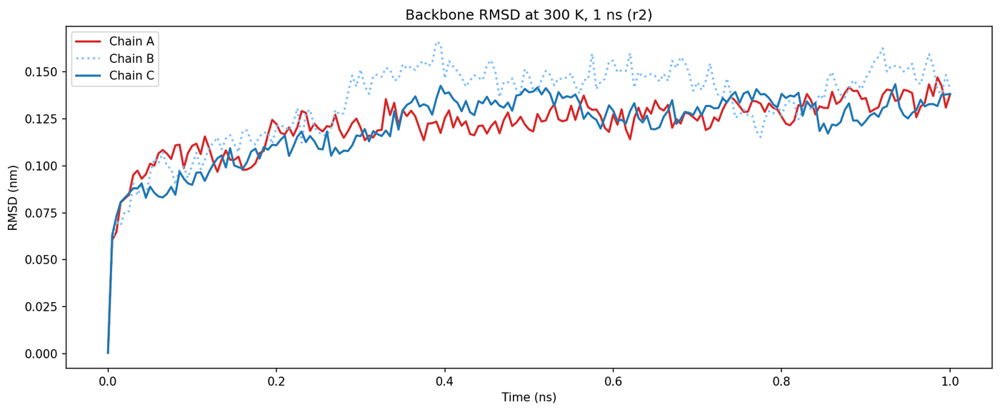

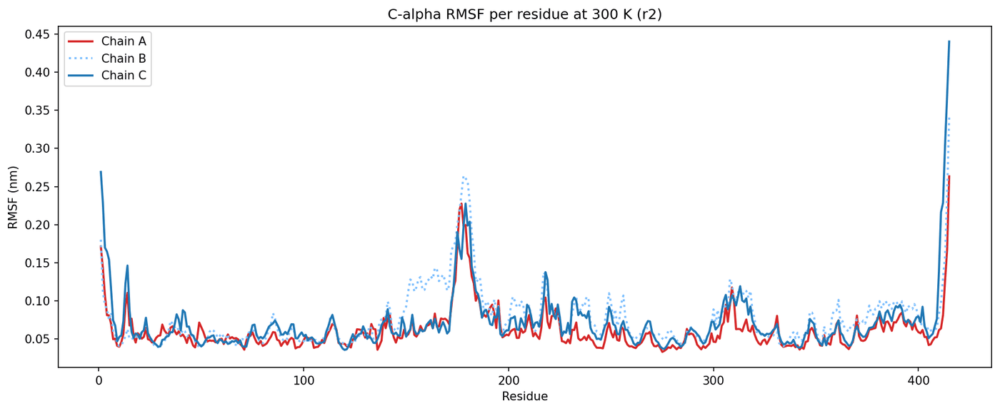

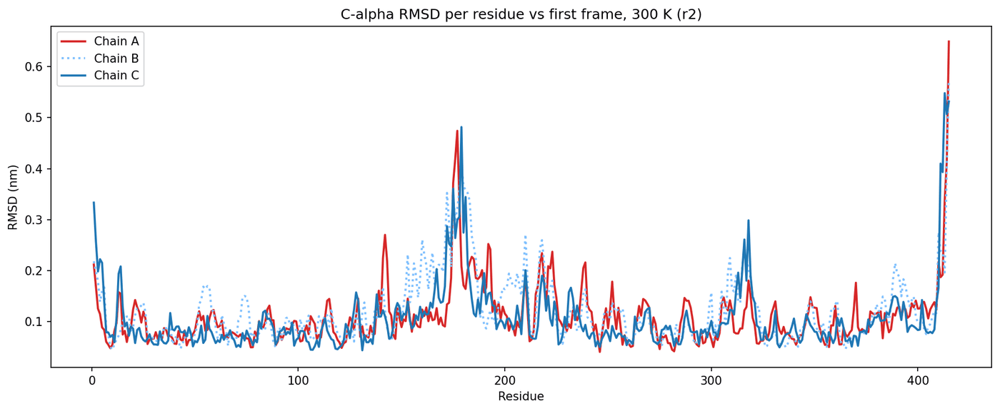

In [ ]:
import os, numpy as np, matplotlib.pyplot as plt
OUT = os.environ["OUT"]
def xvg(f): return np.loadtxt(f, comments=('#','@'))

sty = {"chA": dict(color="#d62728", ls="-", label="Chain A"),
       "chB": dict(color="#7fbfff", ls=":", label="Chain B"),
       "chC": dict(color="#1f77b4", ls="-", label="Chain C")}

def plot(prefix, xlabel, ylabel, title, out):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        d = xvg(f"{OUT}/xvgs/{prefix}_{c}.xvg")
        ax.plot(d[:,0], d[:,1], lw=1.8, **s)
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    ax.legend(); fig.tight_layout()
    fig.savefig(f"{OUT}/graphs/{out}.png"); plt.show()

plot("rmsd",        "Time (ns)", "RMSD (nm)", "Backbone RMSD at 300 K, 1 ns (r2)",                  "rmsd_per_chain")
plot("rmsf",        "Residue",   "RMSF (nm)", "C-alpha RMSF per residue at 300 K (r2)",              "rmsf_per_chain")
plot("rmsd_perres", "Residue",   "RMSD (nm)", "C-alpha RMSD per residue vs first frame, 300 K (r2)", "rmsd_per_residue")

In [ ]:
%%bash
cd "$OUT/frames"
grep -q "\[ Protein \]" chains.ndx || { echo "[ Protein ]"; seq 1 19941 | paste -sd' ' | fold -w 80 -s; } >> chains.ndx
for c in chA chB chC Protein; do
  printf "$c\n" | gmx gyrate -s protein.tpr -f fit_skip5.xtc -n chains.ndx \
    -o "$OUT/xvgs/rg_${c}.xvg" > "$OUT/logs/rg_${c}.log" 2>&1
  echo $c; tail -1 "$OUT/xvgs/rg_${c}.xvg"
done

chA
   1000.000 2.568348 2.313755 2.209897 1.719218
chB
   1000.000 2.570585 2.248275 1.582423 2.378449
chC
   1000.000 2.562610 2.213125 2.242074 1.791406
Protein
   1000.000 5.272256 5.078487 2.712388 4.737640


In [ ]:
%%bash
cd "$OUT/frames"
for c in chA chB chC Protein; do
  printf "Protein\n$c\n" | gmx sasa -s protein.tpr -f fit_skip5.xtc -n chains.ndx \
    -o "$OUT/xvgs/sasa_${c}.xvg" -or "$OUT/xvgs/sasa_perres_${c}.xvg" -tu ns \
    > "$OUT/logs/sasa_${c}.log" 2>&1
  echo $c; tail -1 "$OUT/xvgs/sasa_${c}.xvg"; grep -vc "^[@#]" "$OUT/xvgs/sasa_perres_${c}.xvg"
done

chA
      1.000  532.555
1245
chB
      1.000  532.555
1245
chC
      1.000  532.555
1245
Protein
      1.000  532.555
1245


In [ ]:
%%bash
cd "$OUT/frames"
for c in chA chB chC Protein; do
  gmx hbond -s protein.tpr -f fit_skip5.xtc -n chains.ndx -r "group $c" -t "group $c" \
    -num "$OUT/xvgs/hbnum_${c}.xvg" -tu ns > "$OUT/logs/hbond_${c}.log" 2>&1
  echo $c; tail -1 "$OUT/xvgs/hbnum_${c}.xvg"
done

chA
      1.000        316
chB
      1.000        311
chC
      1.000        301
Protein
      1.000       1010


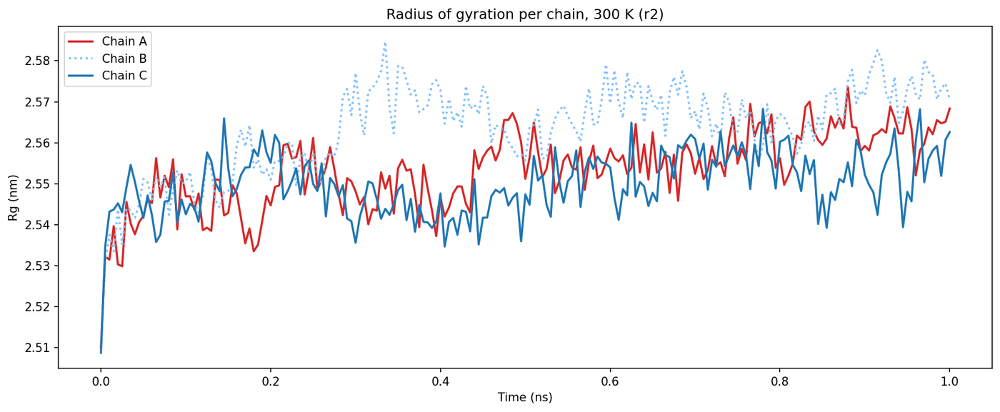

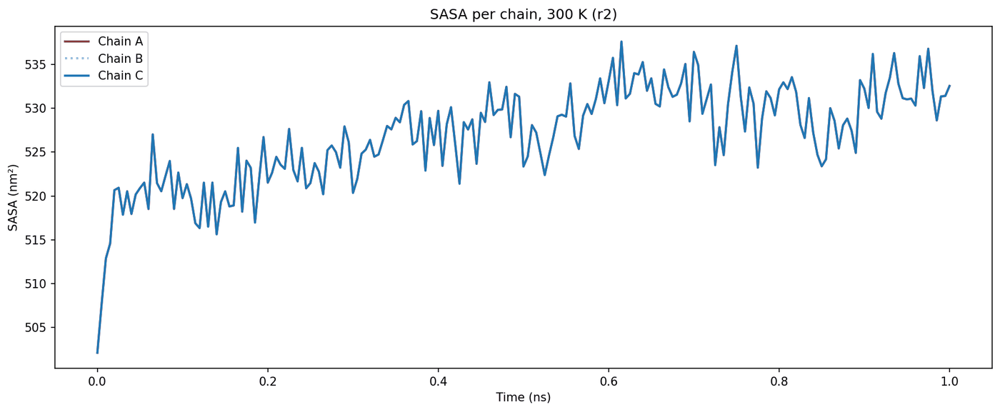

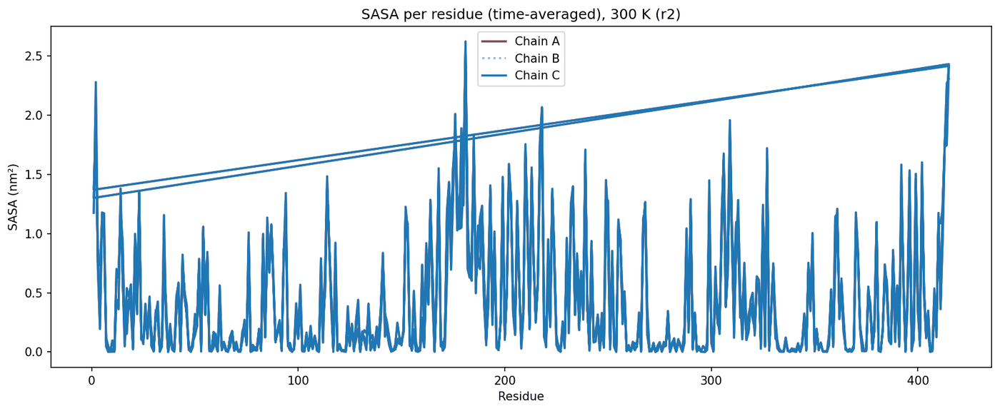

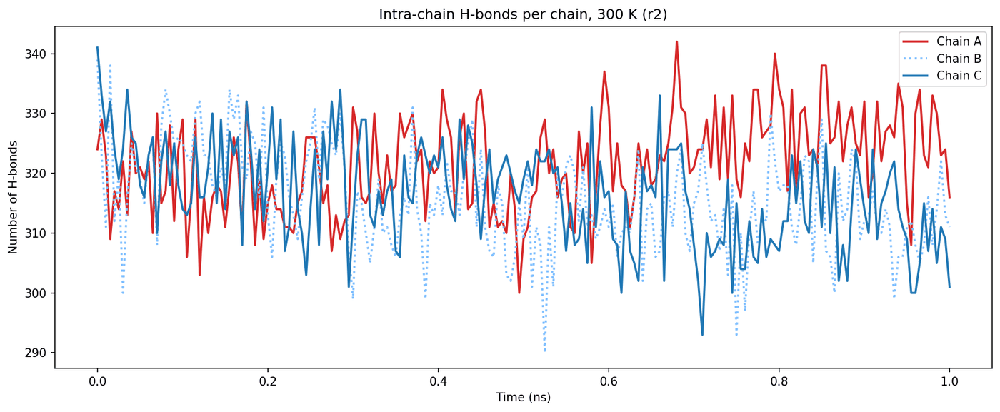

In [ ]:
import os, numpy as np, matplotlib.pyplot as plt
OUT = os.environ["OUT"]
def xvg(f): return np.loadtxt(f, comments=('#','@'))
sty = {"chA": dict(color="#d62728", ls="-", label="Chain A"),
       "chB": dict(color="#7fbfff", ls=":", label="Chain B"),
       "chC": dict(color="#1f77b4", ls="-", label="Chain C")}

def plot(prefix, xlabel, ylabel, title, out, ps2ns=False):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        d = xvg(f"{OUT}/xvgs/{prefix}_{c}.xvg")
        x = d[:,0]/1000 if ps2ns else d[:,0]
        ax.plot(x, d[:,1], lw=1.8, **s)
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    ax.legend(); fig.tight_layout()
    fig.savefig(f"{OUT}/graphs/{out}.png"); plt.show()

plot("rg",          "Time (ns)", "Rg (nm)",          "Radius of gyration per chain, 300 K (r2)", "rg_per_chain", ps2ns=True)
plot("sasa",        "Time (ns)", "SASA (nm²)",       "SASA per chain, 300 K (r2)",               "sasa_per_chain")
plot("sasa_perres", "Residue",   "SASA (nm²)",       "SASA per residue (time-averaged), 300 K (r2)", "sasa_per_residue")
plot("hbnum",       "Time (ns)", "Number of H-bonds","Intra-chain H-bonds per chain, 300 K (r2)", "hbonds_per_chain")

In [ ]:
%%bash
cd "$OUT/xvgs"
for c in chA chB chC Protein; do echo $c $(grep -vc "^[@#]" sasa_perres_$c.xvg); done
md5sum sasa_perres_ch?.xvg

chA 1245
chB 1245
chC 1245
Protein 1245
06f4c6e0efbdf85b7c836b7143f10c4e  sasa_perres_chA.xvg
2d9a1f21e5a992488a288f7426a573cb  sasa_perres_chB.xvg
a28c6ddd4c84a8badb65d10cdcd9cac4  sasa_perres_chC.xvg


In [ ]:
import numpy as np, os
OUT = os.environ["OUT"]
def xvg(f): return np.loadtxt(f, comments=('#','@'))
tot  = xvg(f"{OUT}/xvgs/sasa_Protein.xvg")[:,1].mean()
ch   = {c: xvg(f"{OUT}/xvgs/sasa_{c}.xvg")[:,1].mean() for c in ["chA","chB","chC"]}
pr   = xvg(f"{OUT}/xvgs/sasa_perres_Protein.xvg")[:,1]
print("whole trimer total      :", round(tot,2))
print("sum of 3 chain totals   :", round(sum(ch.values()),2), ch)
print("sum of per-residue file :", round(pr.sum(),2))
for i,c in enumerate(["chA","chB","chC"]):
    print(c, "per-residue block sum:", round(pr[i*415:(i+1)*415].sum(),2))

whole trimer total      : 526.97
sum of 3 chain totals   : 1580.91 {'chA': np.float64(526.969815920398), 'chB': np.float64(526.969815920398), 'chC': np.float64(526.969815920398)}
sum of per-residue file : 526.96
chA per-residue block sum: 172.26
chB per-residue block sum: 180.07
chC per-residue block sum: 174.64


In [ ]:
%%bash
cd "$OUT/frames"
for c in chA chB chC; do
  gmx sasa -s protein.tpr -f fit_skip5.xtc -n chains.ndx \
    -surface "group Protein" -output "group $c" \
    -o "$OUT/xvgs/sasa_${c}.xvg" -or "$OUT/xvgs/tmp_perres_${c}.xvg" -tu ns \
    > "$OUT/logs/sasa_${c}.log" 2>&1
  echo $c $(grep -vc "^[@#]" "$OUT/xvgs/tmp_perres_${c}.xvg") rows; tail -1 "$OUT/xvgs/sasa_${c}.xvg"
done

chA 1245 rows
      1.000  532.555  174.442
chB 1245 rows
      1.000  532.555  185.809
chC 1245 rows
      1.000  532.555  172.298


In [ ]:
%%bash
cd "$OUT/xvgs"
ls rg_*.xvg sasa_*.xvg sasa_perres_Protein.xvg hbnum_*.xvg 2>&1
ls "$OUT/frames/first.gro" 2>&1

hbnum_chA.xvg
hbnum_chB.xvg
hbnum_chC.xvg
hbnum_Protein.xvg
rg_chA.xvg
rg_chB.xvg
rg_chC.xvg
rg_Protein.xvg
sasa_chA.xvg
sasa_chB.xvg
sasa_chC.xvg
sasa_perres_chA.xvg
sasa_perres_chB.xvg
sasa_perres_chC.xvg
sasa_perres_Protein.xvg
sasa_perres_Protein.xvg
sasa_Protein.xvg
/content/pm/analysism/vicilin_300_r2/frames/first.gro


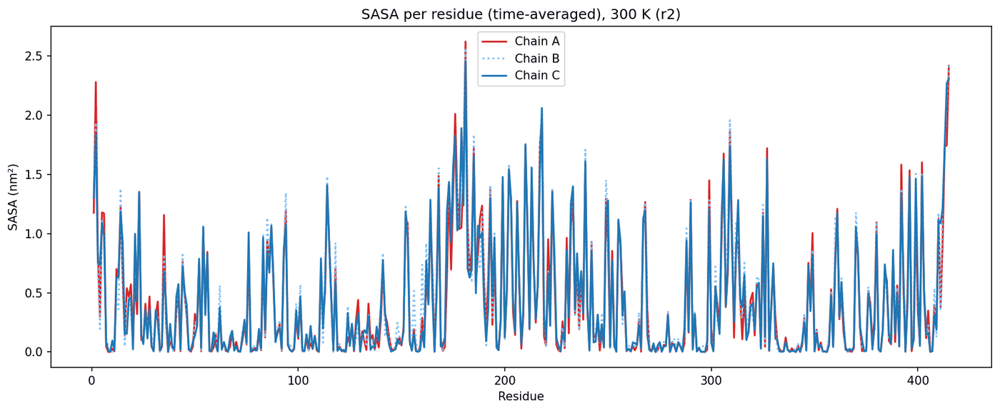

chA mean SASA: 172.3
chB mean SASA: 180.1
chC mean SASA: 174.6


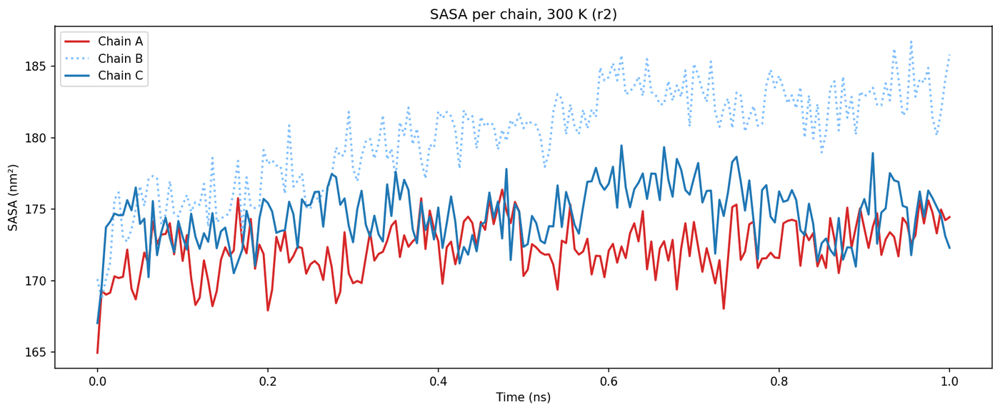

In [ ]:
import os, glob, numpy as np, matplotlib.pyplot as plt
OUT = os.environ["OUT"]
for f in glob.glob(f"{OUT}/xvgs/tmp_*.xvg"): os.remove(f)
def xvg(f): return np.loadtxt(f, comments=('#','@'))
sty = {"chA": dict(color="#d62728", ls="-", label="Chain A"),
       "chB": dict(color="#7fbfff", ls=":", label="Chain B"),
       "chC": dict(color="#1f77b4", ls="-", label="Chain C")}

# per residue: split the 1245-row trimer file into 3 chains
d = xvg(f"{OUT}/xvgs/sasa_perres_Protein.xvg"); assert len(d) == 1245
for i, c in enumerate(sty):
    with open(f"{OUT}/xvgs/sasa_perres_{c}.xvg","w") as f:
        f.write('@ xaxis label "Residue"\n@ yaxis label "SASA (nm^2)"\n')
        for r in range(415): f.write(f"{r+1} {d[i*415+r,1]:.6f}\n")

fig, ax = plt.subplots(figsize=(12,5), dpi=150)
for c, s in sty.items():
    a = xvg(f"{OUT}/xvgs/sasa_perres_{c}.xvg"); ax.plot(a[:,0], a[:,1], lw=1.6, **s)
ax.set(xlabel="Residue", ylabel="SASA (nm²)", title="SASA per residue (time-averaged), 300 K (r2)")
ax.legend(); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/sasa_per_residue.png"); plt.show()

# per chain vs time: column 2 is the chain's own area
fig, ax = plt.subplots(figsize=(12,5), dpi=150)
for c, s in sty.items():
    a = xvg(f"{OUT}/xvgs/sasa_{c}.xvg"); ax.plot(a[:,0], a[:,2], lw=1.8, **s)
    print(c, "mean SASA:", round(a[:,2].mean(),1))
ax.set(xlabel="Time (ns)", ylabel="SASA (nm²)", title="SASA per chain, 300 K (r2)")
ax.legend(); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/sasa_per_chain.png"); plt.show()

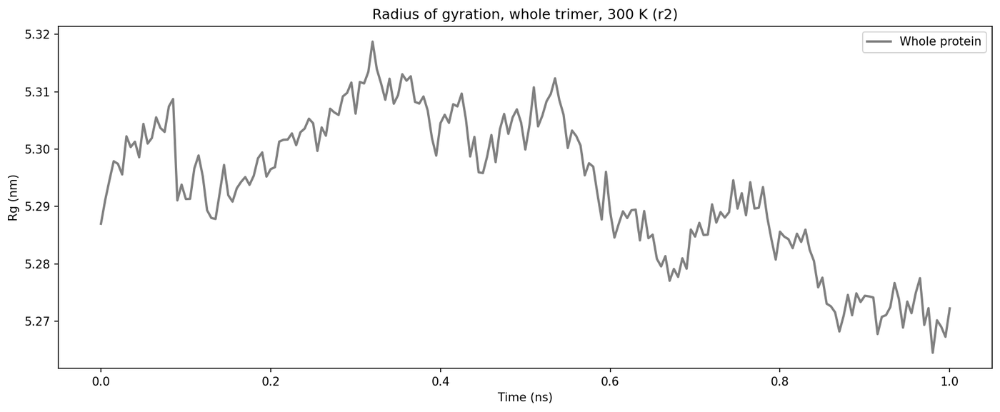

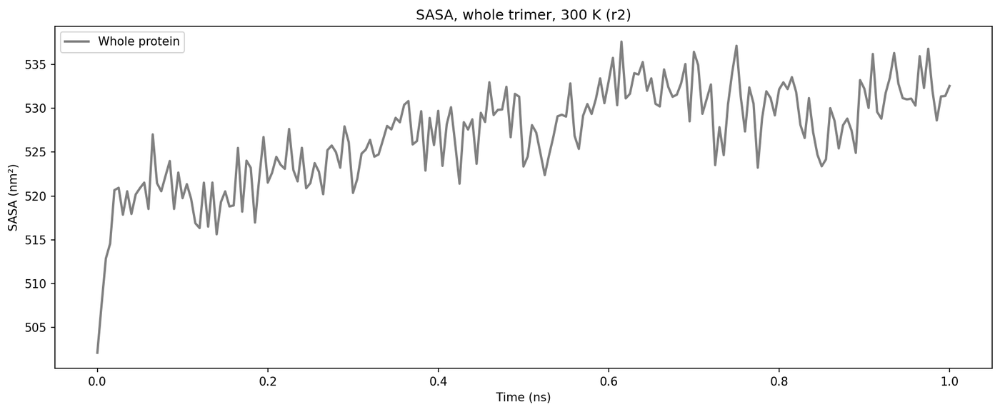

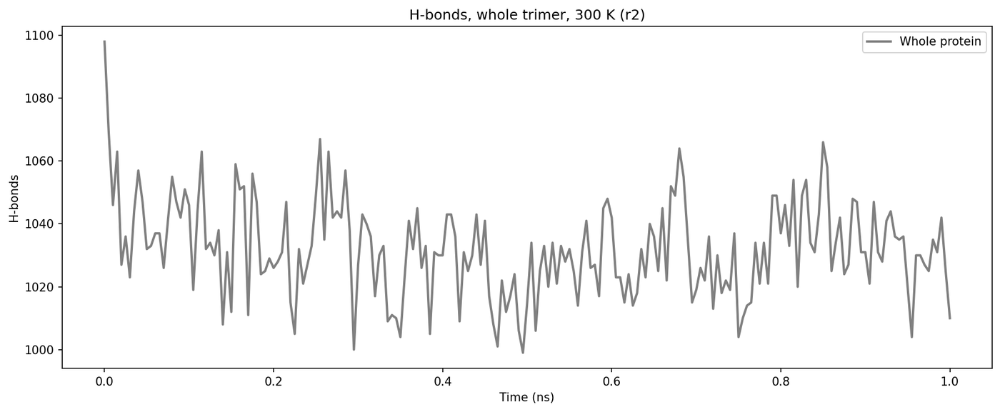

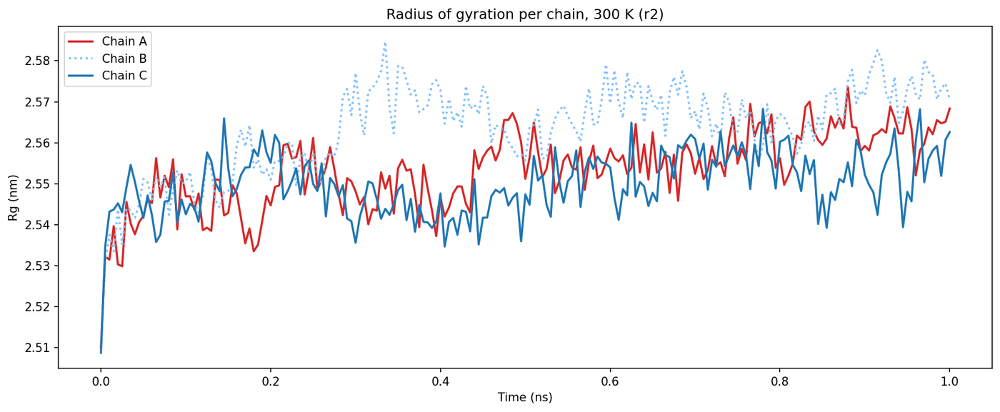

In [ ]:
def whole(prefix, yl, title, out, ps2ns=False):
    a = xvg(f"{OUT}/xvgs/{prefix}_Protein.xvg"); x = a[:,0]/1000 if ps2ns else a[:,0]
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    ax.plot(x, a[:,1], color="grey", lw=2, label="Whole protein")
    ax.set(xlabel="Time (ns)", ylabel=yl, title=title); ax.legend(); fig.tight_layout()
    fig.savefig(f"{OUT}/graphs/{out}.png"); plt.show()

whole("rg",    "Rg (nm)",    "Radius of gyration, whole trimer, 300 K (r2)", "rg_protein", ps2ns=True)
whole("sasa",  "SASA (nm²)", "SASA, whole trimer, 300 K (r2)",               "sasa_protein")
whole("hbnum", "H-bonds",    "H-bonds, whole trimer, 300 K (r2)",            "hbonds_protein")

fig, ax = plt.subplots(figsize=(12,5), dpi=150)
for c, s in sty.items():
    a = xvg(f"{OUT}/xvgs/rg_{c}.xvg"); ax.plot(a[:,0]/1000, a[:,1], lw=1.8, **s)
ax.set(xlabel="Time (ns)", ylabel="Rg (nm)", title="Radius of gyration per chain, 300 K (r2)")
ax.legend(); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/rg_per_chain.png"); plt.show()

In [ ]:
%%bash
cd "$OUT/frames"
printf "Protein\n" | gmx trjconv -s protein.tpr -f fit_skip5.xtc -o first.gro -dump 0 2>&1 | tail -1
pip install -q MDAnalysis scipy

Selected 1: 'Protein'


mean H-bonds/frame: 948.318407960199


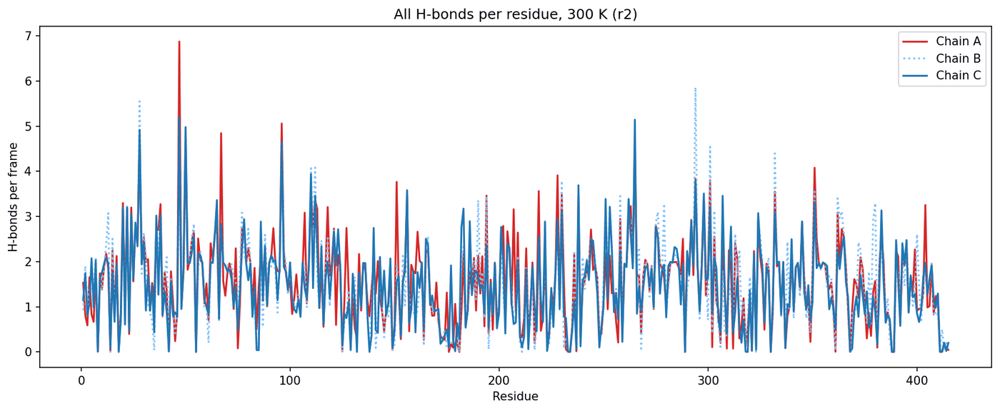

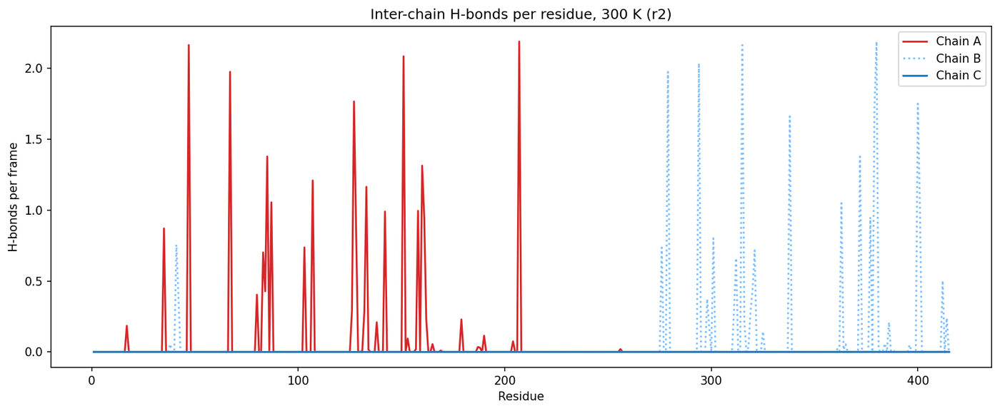

In [ ]:
import MDAnalysis as mda
from scipy.spatial import cKDTree
u = mda.Universe(f"{OUT}/frames/first.gro", f"{OUT}/frames/fit_skip5.xtc")
nm = np.array([n.strip() for n in u.atoms.names]); rn = u.atoms.resnames
resid = u.atoms.resids; chain = np.arange(len(nm))//6647
isH = np.array([n.startswith("H") for n in nm])
P0 = u.atoms.positions/10; heavy = np.where(~isH)[0]; Hs = np.where(isH)[0]
don = heavy[cKDTree(P0[heavy]).query(P0[Hs])[1]]
k = np.array([nm[i][0] in "NO" for i in don]); Hs, don = Hs[k], don[k]
acc = np.array([i for i in range(len(nm)) if nm[i][0]=="O" or (nm[i] in ("ND1","NE2") and rn[i].startswith("HI"))])
tot = np.zeros((3,416)); inter = np.zeros((3,416)); nb = []
for ts in u.trajectory:
    P = u.atoms.positions/10; n = 0
    for hi, lst in enumerate(cKDTree(P[Hs]).query_ball_tree(cKDTree(P[acc]), 0.25)):
        D = don[hi]
        for aj in lst:
            A = acc[aj]
            if A == D or (chain[A]==chain[D] and resid[A]==resid[D]): continue
            v1, v2 = P[Hs[hi]]-P[D], P[A]-P[D]; dist = np.linalg.norm(v2)
            if dist > 0.35 or v1@v2/(np.linalg.norm(v1)*dist) < np.cos(np.radians(30)): continue
            n += 1
            for X in (D, A):
                tot[chain[X], resid[X]] += 1
                if chain[D] != chain[A]: inter[chain[X], resid[X]] += 1
    nb.append(n)
nf = len(nb); print("mean H-bonds/frame:", np.mean(nb))
for name, arr, title in (("hbperres",tot,"All H-bonds per residue"), ("hbperres_inter",inter,"Inter-chain H-bonds per residue")):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for i, (c, s) in enumerate(sty.items()):
        with open(f"{OUT}/xvgs/{name}_{c}.xvg","w") as f:
            f.write('@ xaxis label "Residue"\n@ yaxis label "H-bonds per frame"\n')
            for r in range(1,416): f.write(f"{r} {arr[i,r]/nf:.5f}\n")
        ax.plot(range(1,416), arr[i,1:]/nf, lw=1.6, **s)
    ax.set(xlabel="Residue", ylabel="H-bonds per frame", title=f"{title}, 300 K (r2)")
    ax.legend(); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/{name}.png"); plt.show()

In [ ]:
%%bash
cd "$OUT/frames"
for p in "chA chB" "chB chC" "chA chC"; do set -- $p
  printf "$1\n$2\n" | gmx mindist -s protein.tpr -f fit_skip5.xtc -n chains.ndx \
    -od mind_$1_$2.xvg -tu ns > "$OUT/logs/mind_$1_$2.log" 2>&1
  gmx hbond -s protein.tpr -f fit_skip5.xtc -n chains.ndx -r "group $1" -t "group $2" \
    -num hb_$1_$2.xvg -tu ns > "$OUT/logs/hb_$1_$2.log" 2>&1
  echo "$1-$2  min dist (nm): $(tail -1 mind_$1_$2.xvg)   H-bonds: $(tail -1 hb_$1_$2.xvg)"
done

chA-chB  min dist (nm): 1.000000e+00  1.710050e-01   H-bonds:       1.000         28
chB-chC  min dist (nm): 1.000000e+00  1.514427e-01   H-bonds:       1.000         28
chA-chC  min dist (nm): 1.000000e+00  1.424702e-01   H-bonds:       1.000         26


In [ ]:
import MDAnalysis as mda, numpy as np
from scipy.spatial import cKDTree
u = mda.Universe(f"{OUT}/frames/first.gro", f"{OUT}/frames/fit_skip5.xtc")
P = u.atoms.positions/10
ch = {"A":P[:6647], "B":P[6647:13294], "C":P[13294:]}
for a,b in (("A","B"),("B","C"),("A","C")):
    print(a+b, "raw min dist (nm):", round(cKDTree(ch[a]).query(ch[b])[0].min(),2))
print("box (nm):", u.dimensions[:3]/10)

In [ ]:
%%bash
cd "$OUT/frames"
printf "Protein\n" | gmx trjconv -s protein.tpr -f "$P/$S.xtc" -o whole2.xtc -pbc whole 2>&1 | tail -1
printf "Protein\nProtein\n" | gmx trjconv -s protein.tpr -f whole2.xtc -o cluster.xtc -pbc cluster 2>&1 | tail -1
printf "Backbone\nProtein\n" | gmx trjconv -s protein.tpr -f cluster.xtc -o fit_cluster_skip5.xtc -fit rot+trans -skip 5 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f fit_cluster_skip5.xtc -o first_cl.gro -dump 0 2>&1 | tail -1
rm -f whole2.xtc cluster.xtc
gmx check -f fit_cluster_skip5.xtc 2>&1 | grep -E "Last frame|Step"

Selected 1: 'Protein'

Selected 1: 'Protein'
Selected 1: 'Protein'
Last frame        200 time 1000.000   
Step           201    5


In [ ]:
import os, numpy as np, MDAnalysis as mda
from scipy.spatial import cKDTree
OUT = os.environ["OUT"]
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
worst = {"AB":0,"BC":0,"AC":0}
for ts in u.trajectory:
    P = u.atoms.positions/10
    ch = {"A":P[:6647], "B":P[6647:13294], "C":P[13294:]}
    for k in worst:
        worst[k] = max(worst[k], cKDTree(ch[k[0]]).query(ch[k[1]])[0].min())
print({k: round(v,2) for k,v in worst.items()})

{'AB': np.float64(5.55), 'BC': np.float64(4.81), 'AC': np.float64(15.58)}


In [ ]:
%%bash
cd "$OUT/frames"
printf "Backbone\nBackbone\n" | gmx rms -s protein.tpr -f fit_cluster_skip5.xtc \
  -o "$OUT/xvgs/rmsd_protein.xvg" -tu ns > "$OUT/logs/rmsd_protein.log" 2>&1
tail -1 "$OUT/xvgs/rmsd_protein.xvg"

   1.0000000    5.6639471


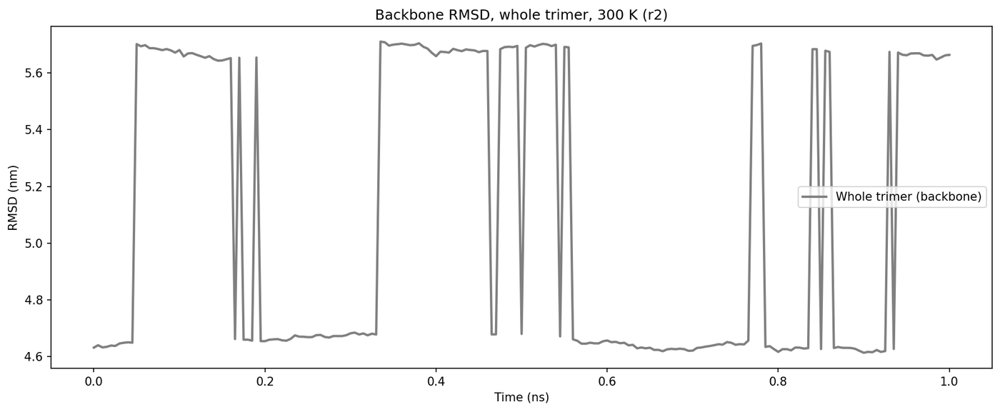

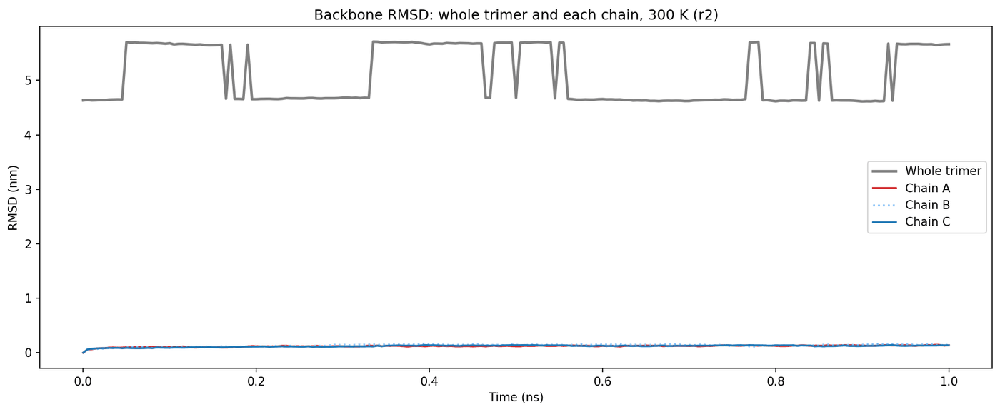

In [ ]:
import os, numpy as np, matplotlib.pyplot as plt
OUT = os.environ["OUT"]
def xvg(f): return np.loadtxt(f, comments=('#','@'))
p = xvg(f"{OUT}/xvgs/rmsd_protein.xvg")

fig, ax = plt.subplots(figsize=(12,5), dpi=150)
ax.plot(p[:,0], p[:,1], color="grey", lw=2, label="Whole trimer (backbone)")
ax.set(xlabel="Time (ns)", ylabel="RMSD (nm)", title="Backbone RMSD, whole trimer, 300 K (r2)")
ax.legend(); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/rmsd_protein.png"); plt.show()

sty = {"chA": dict(color="#d62728", ls="-", label="Chain A"),
       "chB": dict(color="#7fbfff", ls=":", label="Chain B"),
       "chC": dict(color="#1f77b4", ls="-", label="Chain C")}
fig, ax = plt.subplots(figsize=(12,5), dpi=150)
ax.plot(p[:,0], p[:,1], color="grey", lw=2.2, label="Whole trimer")
for c, s in sty.items():
    d = xvg(f"{OUT}/xvgs/rmsd_{c}.xvg"); ax.plot(d[:,0], d[:,1], lw=1.6, **s)
ax.set(xlabel="Time (ns)", ylabel="RMSD (nm)", title="Backbone RMSD: whole trimer and each chain, 300 K (r2)")
ax.legend(); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/rmsd_protein_and_chains.png"); plt.show()

In [ ]:
import os
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
os.system('ln -sfn "/content/drive/MyDrive/Plant Protein Extrusion MD" /content/pm')
os.environ.update(P="/content/pm", S="md_300_r2", OUT="/content/pm/analysism/vicilin_300_r2")
for d in ["graphs","logs","frames","xvgs"]: os.makedirs(f'{os.environ["OUT"]}/{d}', exist_ok=True)
os.system('pip install -q MDAnalysis scipy; gmx --version | head -1; ls $P/$S.*')

0

In [ ]:
%%bash
cd "$OUT/frames"
printf "Protein\n" | gmx convert-tpr -s "$P/$S.tpr" -o protein.tpr 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f "$P/$S.xtc" -o whole2.xtc -pbc whole 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f whole2.xtc -o first_w.gro -dump 0 2>&1 | tail -1

Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'


In [ ]:
import numpy as np, MDAnalysis as mda
from MDAnalysis.lib.distances import minimize_vectors
OUT = os.environ["OUT"]
u = mda.Universe(f"{OUT}/frames/first_w.gro", f"{OUT}/frames/whole2.xtc")
sl = {"A":slice(0,6647), "B":slice(6647,13294), "C":slice(13294,19941)}
with mda.Writer(f"{OUT}/frames/together.xtc", u.atoms.n_atoms) as W:
    for ts in u.trajectory[::5]:
        pos = u.atoms.positions.copy(); box = ts.dimensions.astype(np.float32)
        a0 = pos[sl["A"]].mean(0)
        for k in "BC":
            d = pos[sl[k]].mean(0) - a0
            dm = minimize_vectors(d[None,:].astype(np.float32), box)[0]
            pos[sl[k]] -= (d - dm)
        u.atoms.positions = pos; W.write(u.atoms)

In [ ]:
%%bash
cd "$OUT/frames"
printf "Backbone\nProtein\n" | gmx trjconv -s protein.tpr -f together.xtc -o fit_cluster_skip5.xtc -fit rot+trans 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f fit_cluster_skip5.xtc -o first_cl.gro -dump 0 2>&1 | tail -1
rm -f whole2.xtc together.xtc
gmx check -f fit_cluster_skip5.xtc 2>&1 | grep -E "Last frame|Step"

Selected 1: 'Protein'
Selected 1: 'Protein'
Last frame        200 time 1000.000   
Step           201    5


In [ ]:
from scipy.spatial import cKDTree
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
worst = {"AB":0,"BC":0,"AC":0}
for ts in u.trajectory:
    Pp = u.atoms.positions/10; chp = {k:Pp[s] for k,s in sl.items()}
    for p in worst: worst[p] = max(worst[p], cKDTree(chp[p[0]]).query(chp[p[1]])[0].min())
print({k: round(float(v),2) for k,v in worst.items()})
assert max(worst.values()) < 0.5, "chains NOT together - stop and send me this line"

nm = [a[10:15].strip() for a in open(f"{OUT}/frames/first_cl.gro").read().split("\n")[2:2+19941]]
G = {}
for c, r in {"chA":range(1,6648),"chB":range(6648,13295),"chC":range(13295,19942),"Protein":range(1,19942)}.items():
    G[c] = list(r); G[c+"_bb"] = [i for i in r if nm[i-1] in ("N","CA","C")]; G[c+"_CA"] = [i for i in r if nm[i-1]=="CA"]
with open(f"{OUT}/frames/chains.ndx","w") as f:
    for g, idx in G.items():
        f.write(f"[ {g} ]\n")
        for k in range(0, len(idx), 15): f.write(" ".join(f"{i:4d}" for i in idx[k:k+15]) + "\n")
print({g: len(v) for g, v in G.items()})

{'AB': 0.18, 'BC': 0.18, 'AC': 0.18}
{'chA': 6647, 'chA_bb': 1245, 'chA_CA': 415, 'chB': 6647, 'chB_bb': 1245, 'chB_CA': 415, 'chC': 6647, 'chC_bb': 1245, 'chC_CA': 415, 'Protein': 19941, 'Protein_bb': 3735, 'Protein_CA': 1245}


In [ ]:
%%bash
cd "$OUT/frames"; X="$OUT/xvgs"; L="$OUT/logs"; T=fit_cluster_skip5.xtc
for c in Protein chA chB chC; do
  printf "${c}_bb\n${c}_bb\n" | gmx rms  -s first_cl.gro -f $T -n chains.ndx -o $X/rmsd_$c.xvg -tu ns > $L/rmsd_$c.log 2>&1
  printf "${c}_CA\n${c}_CA\n" | gmx rmsf -s first_cl.gro -f $T -n chains.ndx -o $X/rmsf_$c.xvg -res   > $L/rmsf_$c.log 2>&1
  printf "$c\n"               | gmx gyrate -s protein.tpr -f $T -n chains.ndx -o $X/rg_$c.xvg          > $L/rg_$c.log 2>&1
  gmx sasa -s protein.tpr -f $T -n chains.ndx -surface "group Protein" -output "group $c" -o $X/sasa_$c.xvg -or $X/tmp_$c.xvg -tu ns > $L/sasa_$c.log 2>&1
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r "group $c" -t "group $c" -num $X/hbnum_$c.xvg -tu ns > $L/hbond_$c.log 2>&1
done
for p in "chA chB" "chB chC" "chA chC"; do set -- $p
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r "group $1" -t "group $2" -num $X/hbinter_$1_$2.xvg -tu ns > $L/hbinter_$1_$2.log 2>&1
done
mv $X/tmp_Protein.xvg $X/sasa_perres_Protein.xvg; rm -f $X/tmp_ch*.xvg
for f in rmsd_Protein rmsd_chA rmsf_chA rg_Protein sasa_chA hbnum_Protein hbinter_chA_chB; do echo $f $(tail -1 $X/$f.xvg); done

rmsd_Protein 1.0000000 0.1702183
rmsd_chA 1.0000000 0.1379617
rmsf_chA 415 0.2559
rg_Protein 1000.000 3.413503 2.786370 2.770215 2.804652
sasa_chA 1.000 534.075 175.888
hbnum_Protein 1.000 1012
hbinter_chA_chB 1.000 28


In [ ]:
import matplotlib.pyplot as plt
X = f"{OUT}/xvgs"
def xvg(f): return np.loadtxt(f, comments=('#','@'))
sty = {"chA": dict(color="#d62728", ls="-", label="Chain A"),
       "chB": dict(color="#7fbfff", ls=":", label="Chain B"),
       "chC": dict(color="#1f77b4", ls="-", label="Chain C")}
def draw(out, title, xl, yl, items):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for x, y, s in items: ax.plot(x, y, lw=1.8, **s)
    ax.set(xlabel=xl, ylabel=yl, title=title); ax.legend(); fig.tight_layout()
    fig.savefig(f"{OUT}/graphs/{out}.png"); plt.show()
def chains(prefix, col=1, sc=1):
    return [(xvg(f"{X}/{prefix}_{c}.xvg")[:,0]/sc, xvg(f"{X}/{prefix}_{c}.xvg")[:,col], s) for c, s in sty.items()]
def whole(prefix, col=1, sc=1):
    a = xvg(f"{X}/{prefix}_Protein.xvg"); return [(a[:,0]/sc, a[:,col], dict(color="grey", label="Whole trimer"))]

for pre, yl, ttl, sc, col in (("rmsd","RMSD (nm)","Backbone RMSD",1,1), ("rg","Rg (nm)","Radius of gyration",1000,1),
                              ("sasa","SASA (nm²)","SASA",1,None), ("hbnum","H-bonds","Intra-chain H-bonds",1,1)):
    cc = 2 if pre == "sasa" else 1
    draw(f"{pre}_per_chain", f"{ttl} per chain, 300 K (r2)", "Time (ns)", yl, chains(pre, cc, sc))
    draw(f"{pre}_protein", f"{ttl}, whole trimer, 300 K (r2)", "Time (ns)", yl, whole(pre, 1, sc))

# residue-based: RMSF per chain; SASA per residue (split the 1245-row trimer file)
draw("rmsf_per_chain", "C-alpha RMSF per residue, 300 K (r2)", "Residue", "RMSF (nm)", chains("rmsf"))
d = xvg(f"{X}/sasa_perres_Protein.xvg"); assert len(d) == 1245
draw("sasa_per_residue", "SASA per residue (time-averaged), 300 K (r2)", "Residue", "SASA (nm²)",
     [(np.arange(1,416), d[i*415:(i+1)*415,1], s) for i, s in enumerate(sty.values())])

# inter-chain H-bonds vs time
pairs = [("chA","chB","A–B"),("chB","chC","B–C"),("chA","chC","A–C")]
draw("hbonds_inter_chain", "Inter-chain H-bonds, 300 K (r2)", "Time (ns)", "H-bonds",
     [(xvg(f"{X}/hbinter_{a}_{b}.xvg")[:,0], xvg(f"{X}/hbinter_{a}_{b}.xvg")[:,1], dict(color=c, ls=l, label=n))
      for (a,b,n), c, l in zip(pairs, ("#d62728","#7fbfff","#1f77b4"), ("-",":","-"))])

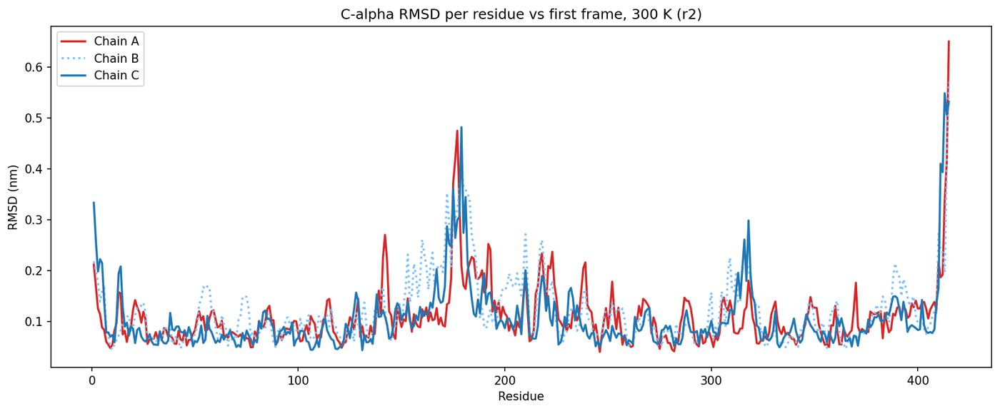

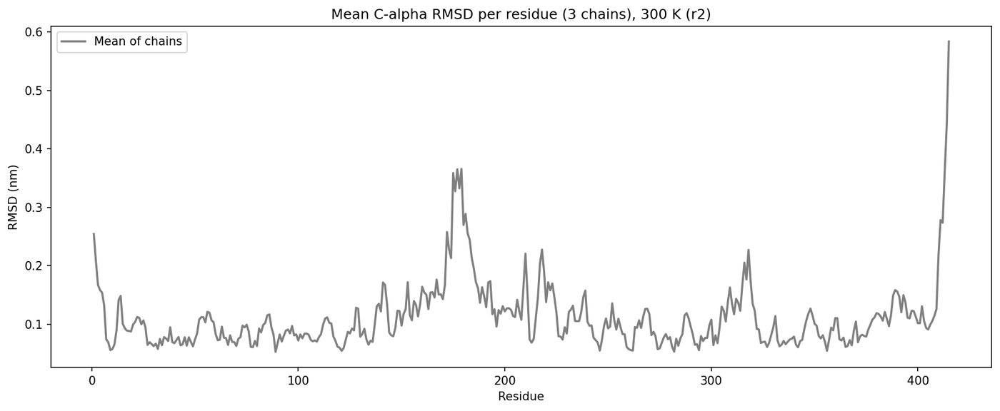

mean H-bonds/frame: 1004.7


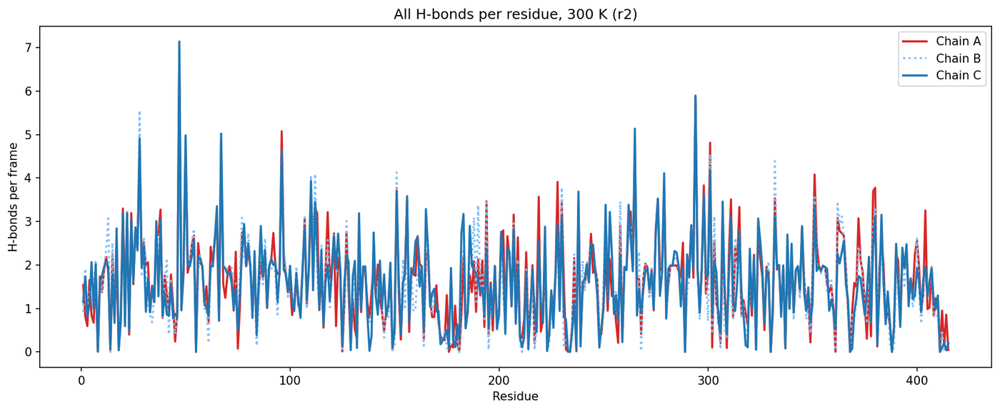

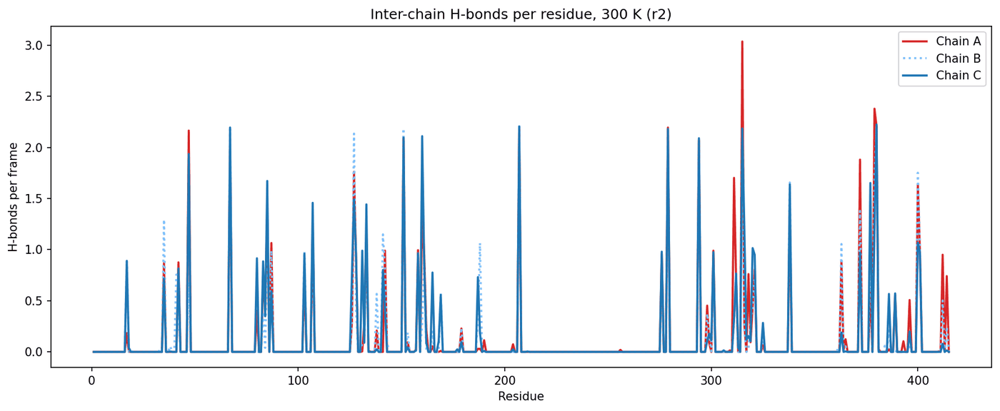

In [ ]:
from MDAnalysis.analysis.align import rotation_matrix
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
cs = {"chA":slice(0,6647), "chB":slice(6647,13294), "chC":slice(13294,19941)}
resR = {}
for name, s in cs.items():
    chn = u.atoms[s]; bb = chn.select_atoms("name N CA C"); ca = chn.select_atoms("name CA")
    u.trajectory[0]; c0 = bb.positions.mean(0); bb0 = bb.positions - c0; ca0 = ca.positions - c0
    d2 = np.zeros(len(ca)); n = 0
    for ts in u.trajectory:
        c = bb.positions.mean(0); R, _ = rotation_matrix(bb.positions - c, bb0)
        d2 += (((ca.positions - c) @ R.T - ca0)**2).sum(1); n += 1
    resR[name] = np.sqrt(d2/n)/10
    np.savetxt(f"{X}/rmsd_perres_{name}.xvg", np.c_[np.arange(1,416), resR[name]], fmt="%d %.6f")
draw("rmsd_per_residue", "C-alpha RMSD per residue vs first frame, 300 K (r2)", "Residue", "RMSD (nm)",
     [(np.arange(1,416), resR[c], s) for c, s in sty.items()])
m = np.mean(list(resR.values()), axis=0)
draw("rmsd_per_residue_mean", "Mean C-alpha RMSD per residue (3 chains), 300 K (r2)", "Residue", "RMSD (nm)",
     [(np.arange(1,416), m, dict(color="grey", label="Mean of chains"))])

# per-residue H-bonds (box-corrected trajectory, D-A <= 0.35 nm, angle <= 30 deg)
nmA = np.array([n.strip() for n in u.atoms.names]); rn = u.atoms.resnames
resid = u.atoms.resids; chain = np.arange(len(nmA))//6647
isH = np.array([n.startswith("H") for n in nmA])
P0 = u.atoms.positions/10; heavy = np.where(~isH)[0]; Hs = np.where(isH)[0]
don = heavy[cKDTree(P0[heavy]).query(P0[Hs])[1]]
k = np.array([nmA[i][0] in "NO" for i in don]); Hs, don = Hs[k], don[k]
acc = np.array([i for i in range(len(nmA)) if nmA[i][0]=="O" or (nmA[i] in ("ND1","NE2") and rn[i].startswith("HI"))])
tot = np.zeros((3,416)); inter = np.zeros((3,416)); nb = []
for ts in u.trajectory:
    Pf = u.atoms.positions/10; n = 0
    for hi, lst in enumerate(cKDTree(Pf[Hs]).query_ball_tree(cKDTree(Pf[acc]), 0.25)):
        D = don[hi]
        for aj in lst:
            A = acc[aj]
            if A == D or (chain[A]==chain[D] and resid[A]==resid[D]): continue
            v1, v2 = Pf[Hs[hi]]-Pf[D], Pf[A]-Pf[D]; dist = np.linalg.norm(v2)
            if dist > 0.35 or v1@v2/(np.linalg.norm(v1)*dist) < np.cos(np.radians(30)): continue
            n += 1
            for Xa in (D, A):
                tot[chain[Xa], resid[Xa]] += 1
                if chain[D] != chain[A]: inter[chain[Xa], resid[Xa]] += 1
    nb.append(n)
nf = len(nb); print("mean H-bonds/frame:", round(float(np.mean(nb)),1))
for nmx, arr, ttl in (("hbperres",tot,"All H-bonds per residue"), ("hbperres_inter",inter,"Inter-chain H-bonds per residue")):
    for i, c in enumerate(sty): np.savetxt(f"{X}/{nmx}_{c}.xvg", np.c_[np.arange(1,416), arr[i,1:]/nf], fmt="%d %.5f")
    draw(nmx, f"{ttl}, 300 K (r2)", "Residue", "H-bonds per frame",
         [(np.arange(1,416), arr[i,1:]/nf, s) for i, s in enumerate(sty.values())])

In [ ]:
%%bash
cd "$OUT/frames"
for c in chA chB chC; do
  printf "$c\n" | gmx dssp -s protein.tpr -f fit_cluster_skip5.xtc -n chains.ndx -o "$OUT/xvgs/dssp_$c.dat" > "$OUT/logs/dssp_$c.log" 2>&1
  echo $c; head -c 80 "$OUT/xvgs/dssp_$c.dat"; echo; tail -3 "$OUT/logs/dssp_$c.log"
done

chA
~HHHHH~TTEE~GGGEEEEEEETTEEEEEEPPGGGT~GGGTTSTT~EEEEEEE~TTEEEEEEEESEEEEEEEEES~EEEE

GROMACS reminds you: "It Doesn't Seem Right, No Computers in Sight" (Faun Fables)

chB
~HHHHH~TTEE~GGGEEEEEEETTEEEEEEPPGGGT~GGGTTSTT~EEEEEEE~TTEEEEEEEESEEEEEEEEES~EEEE

GROMACS reminds you: "Science, my lad, is made up of mistakes, but they are mistakes which it is useful to make, because they lead little by little to the truth." (Jules Verne)

chC
~HHHHH~TTEE~GGGEEEEEEETTEEEEEEPPGGGT~GGGTTSTT~EEEEEEE~TTEEEEEEEESEEEEEEEEES~EEEE

GROMACS reminds you: "Why add prime numbers? Prime numbers are made to be multiplied." (Lev Landau)



shape: (201, 1247) | chain breaks at columns: [415 831]
helix chA mean %: 17.7
helix chB mean %: 15.8
helix chC mean %: 16.9


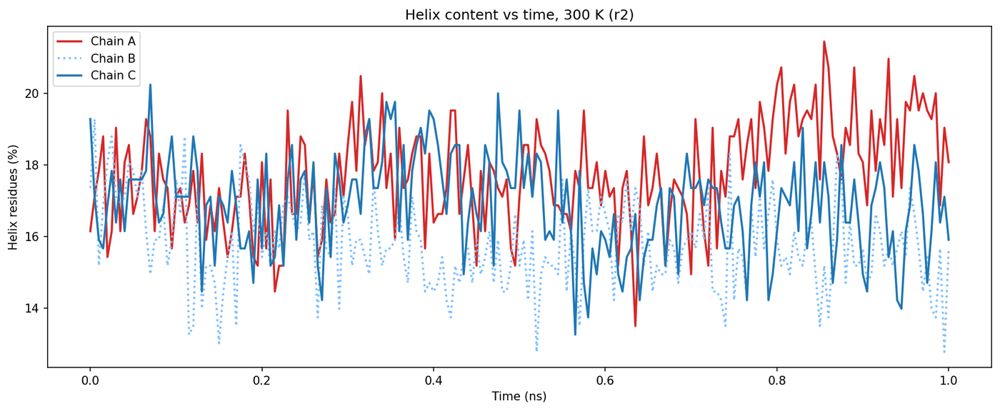

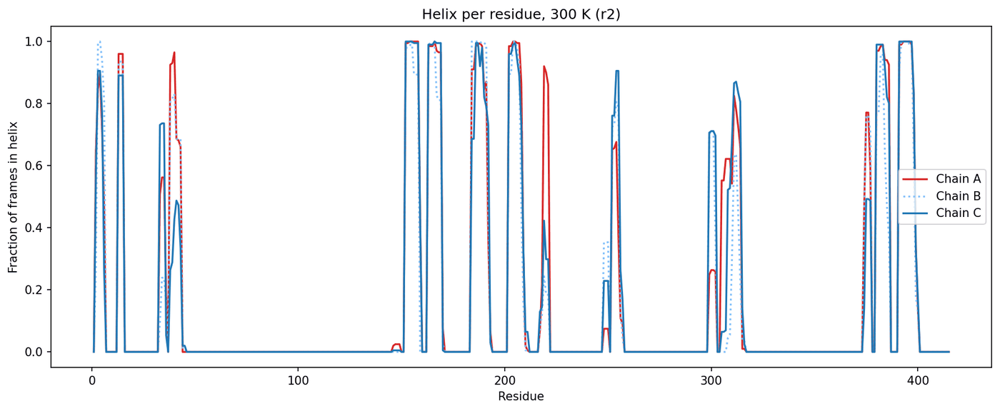

strand chA mean %: 36.9
strand chB mean %: 37.3
strand chC mean %: 37.5


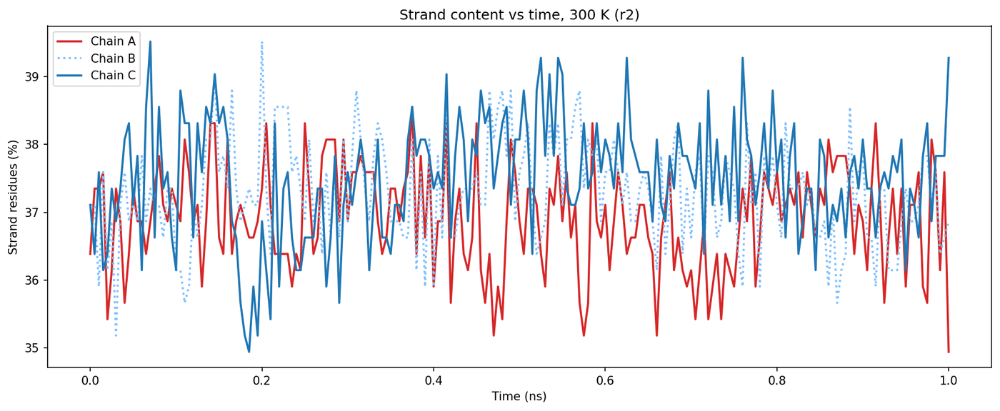

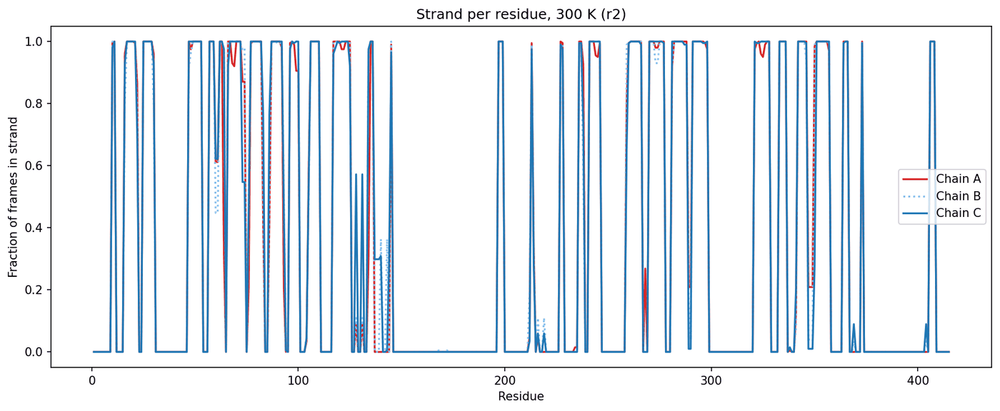

In [ ]:
import numpy as np, matplotlib.pyplot as plt, os
OUT = os.environ["OUT"]
a = np.array([list(l.rstrip("\n")) for l in open(f"{OUT}/xvgs/dssp_chA.dat") if l.strip()])
brk = np.where((a == "=").all(0))[0]
print("shape:", a.shape, "| chain breaks at columns:", brk)
a = a[:, ~(a == "=").all(0)]
assert a.shape[1] == 1245, a.shape
D = {c: a[:, i*415:(i+1)*415] for i, c in enumerate(("chA","chB","chC"))}

sty = {"chA": dict(color="#d62728", ls="-", label="Chain A"),
       "chB": dict(color="#7fbfff", ls=":", label="Chain B"),
       "chC": dict(color="#1f77b4", ls="-", label="Chain C")}
t = np.linspace(0, 1, len(a))
for name, ss, yl in (("helix","HGI","Helix residues (%)"), ("strand","EB","Strand residues (%)")):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        ax.plot(t, 100*np.isin(D[c], list(ss)).mean(1), lw=1.8, **s)
        print(name, c, "mean %:", round(100*np.isin(D[c], list(ss)).mean(), 1))
    ax.set(xlabel="Time (ns)", ylabel=yl, title=f"{name.capitalize()} content vs time, 300 K (r2)")
    ax.legend(); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_time.png"); plt.show()

    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        f = np.isin(D[c], list(ss)).mean(0); ax.plot(np.arange(1,416), f, lw=1.6, **s)
        np.savetxt(f"{OUT}/xvgs/dssp_{name}_perres_{c}.xvg", np.c_[np.arange(1,416), f], fmt="%d %.4f")
    ax.set(xlabel="Residue", ylabel=f"Fraction of frames in {name}", title=f"{name.capitalize()} per residue, 300 K (r2)")
    ax.legend(); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_perres.png"); plt.show()

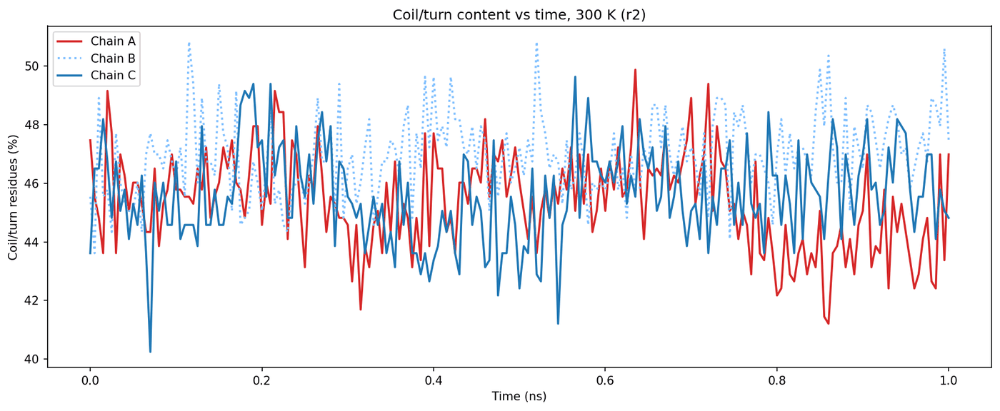

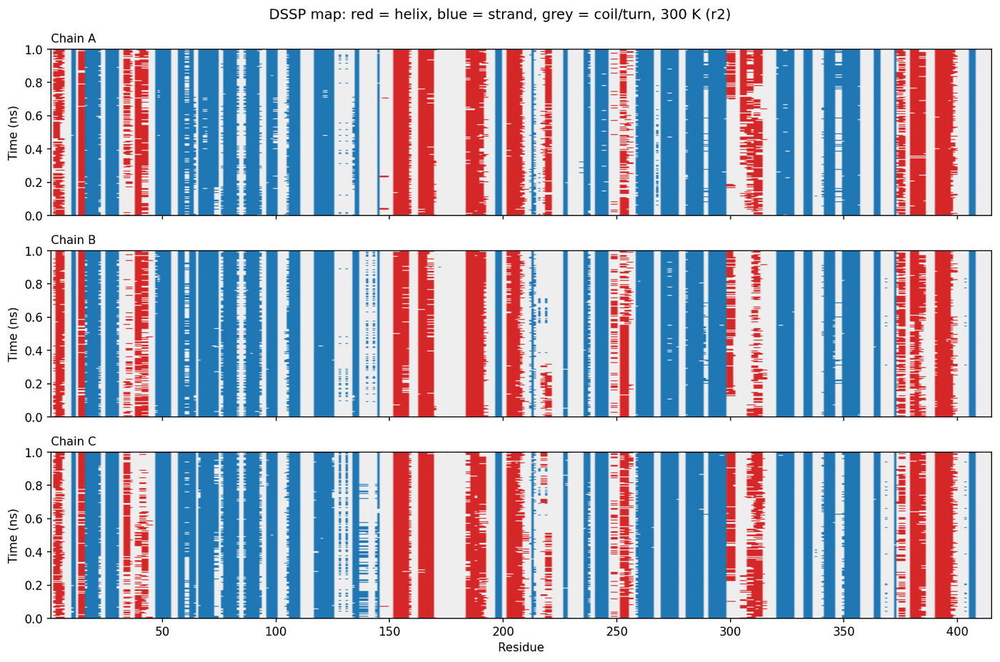

In [ ]:
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(12,5), dpi=150)
for c, s in sty.items():
    ax.plot(t, 100*(1-np.isin(D[c], list("HGIEB")).mean(1)), lw=1.8, **s)
ax.set(xlabel="Time (ns)", ylabel="Coil/turn residues (%)", title="Coil/turn content vs time, 300 K (r2)")
ax.legend(); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_coil_time.png"); plt.show()

cmap = ListedColormap(["#eeeeee", "#d62728", "#1f77b4"])   # coil, helix, strand
code = lambda m: np.where(np.isin(m, list("HGI")), 1, np.where(np.isin(m, list("EB")), 2, 0))
fig, axs = plt.subplots(3, 1, figsize=(12,8), dpi=150, sharex=True)
for ax, (c, s) in zip(axs, sty.items()):
    ax.imshow(code(D[c]), aspect="auto", cmap=cmap, vmin=0, vmax=2, origin="lower", extent=[1,415,0,1])
    ax.set_ylabel("Time (ns)"); ax.set_title(s["label"], loc="left", fontsize=10)
axs[-1].set_xlabel("Residue"); fig.suptitle("DSSP map: red = helix, blue = strand, grey = coil/turn, 300 K (r2)")
fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_map.png"); plt.show()

In [ ]:
import pandas as pd
def last(f, col=1): a = np.loadtxt(f, comments=('#','@')); return a[len(a)//2:, col].mean()
rows = []
for c in ("chA","chB","chC"):
    rows.append(dict(chain=c,
      RMSD_nm = last(f"{OUT}/xvgs/rmsd_{c}.xvg"), Rg_nm = last(f"{OUT}/xvgs/rg_{c}.xvg"),
      SASA_nm2 = last(f"{OUT}/xvgs/sasa_{c}.xvg", 2), intra_Hbonds = last(f"{OUT}/xvgs/hbnum_{c}.xvg"),
      helix_pct = 100*np.isin(D[c][len(t)//2:], list("HGI")).mean(), strand_pct = 100*np.isin(D[c][len(t)//2:], list("EB")).mean()))
rows.append(dict(chain="trimer", RMSD_nm=last(f"{OUT}/xvgs/rmsd_Protein.xvg"), Rg_nm=last(f"{OUT}/xvgs/rg_Protein.xvg"),
                 SASA_nm2=last(f"{OUT}/xvgs/sasa_Protein.xvg"), intra_Hbonds=last(f"{OUT}/xvgs/hbnum_Protein.xvg")))
df = pd.DataFrame(rows).round(3); df.to_csv(f"{OUT}/xvgs/summary_last0.5ns.csv", index=False); print(df)

    chain  RMSD_nm  Rg_nm  SASA_nm2  intra_Hbonds  helix_pct  strand_pct
0     chA    0.130  2.559   172.670       324.347     18.151      36.805
1     chB    0.144  2.569   182.660       312.653     15.598      37.230
2     chC    0.131  2.553   175.949       312.762     16.512      37.671
3  trimer    0.160  3.404   531.286      1032.723        NaN         NaN


(201, 1245)


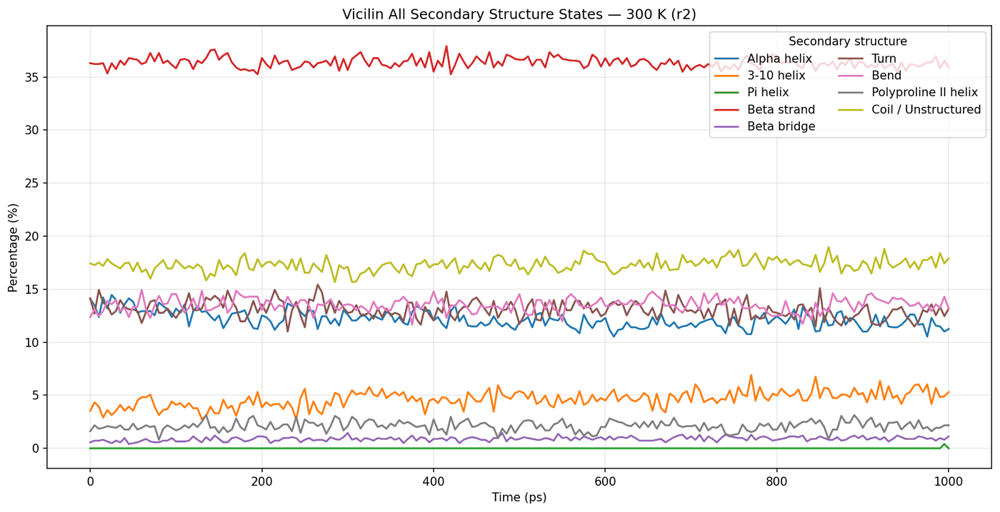

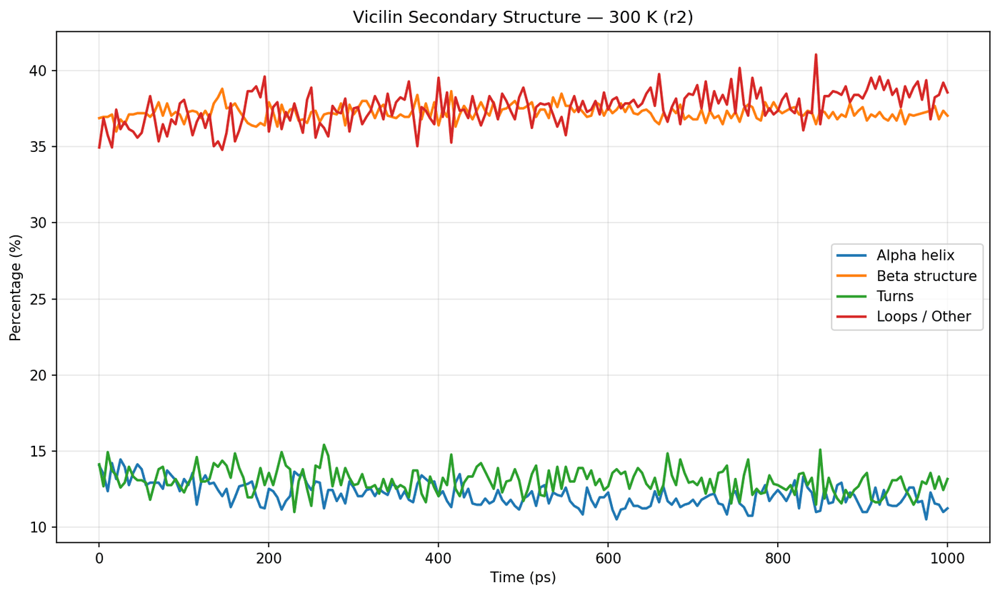

In [ ]:
import os, numpy as np, matplotlib.pyplot as plt
OUT = os.environ["OUT"]

def load_dssp(path):
    a = np.array([list(l.rstrip("\n")) for l in open(path) if l.strip()])
    return a[:, ~(a == "=").all(0)]            # frames x residues, chain breaks removed

STATES = [("Alpha helix","H"),("3-10 helix","G"),("Pi helix","I"),("Beta strand","E"),("Beta bridge","B"),
          ("Turn","T"),("Bend","S"),("Polyproline II helix","P")]
def percent(a):
    P = {n: 100*(a == c).mean(1) for n, c in STATES}
    P["Coil / Unstructured"] = 100 - sum(P.values())      # everything else
    return P

a = load_dssp(f"{OUT}/xvgs/dssp_chA.dat"); print(a.shape)   # expect (201, 1245)
P = percent(a); t = np.arange(len(a))*5.0                   # 5 ps between kept frames

fig, ax = plt.subplots(figsize=(12,6.2), dpi=150)
for i, (n, y) in enumerate(P.items()): ax.plot(t, y, color=plt.cm.tab10(i), lw=1.6, label=n)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title="Vicilin All Secondary Structure States — 300 K (r2)")
ax.grid(alpha=.3); ax.legend(title="Secondary structure", ncol=2, loc="upper right"); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_all_states_300K.png"); plt.show()

G = {"Alpha helix": P["Alpha helix"], "Beta structure": P["Beta strand"]+P["Beta bridge"], "Turns": P["Turn"]}
G["Loops / Other"] = 100 - sum(G.values())
fig, ax = plt.subplots(figsize=(10,6), dpi=150)
for i, (n, y) in enumerate(G.items()): ax.plot(t, y, color=plt.cm.tab10(i), lw=1.8, label=n)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title="Vicilin Secondary Structure — 300 K (r2)")
ax.grid(alpha=.3); ax.legend(); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_groups_300K.png"); plt.show()

In [ ]:
import os
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
os.system('ln -sfn "/content/drive/MyDrive/Plant Protein Extrusion MD" /content/pm')
os.environ.update(P="/content/pm", S="md_373_r1", OUT="/content/pm/analysism/vicilin_373_r1")
for d in ["graphs","logs","frames","xvgs"]: os.makedirs(f'{os.environ["OUT"]}/{d}', exist_ok=True)
os.system('pip install -q MDAnalysis scipy; gmx --version | head -1; ls $P/$S.*')

0

In [ ]:
%%bash
cd "$OUT/frames"
printf "Protein\n" | gmx convert-tpr -s "$P/$S.tpr" -o protein.tpr 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f "$P/$S.xtc" -o whole2.xtc -pbc whole 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f whole2.xtc -o first_w.gro -dump 0 2>&1 | tail -1

Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'


In [ ]:
%%bash
ls /content/pm | head -50
echo ---
find /content/drive/MyDrive -name "md_373_r1*" 2>/dev/null

analysis
analysism
backups
condacolab_install.log
em.edr
#em.edr.1#
em.gro
#em.gro.1#
em.log
#em.log.1#
em.mdp
em.tpr
#em.tpr.1#
em.trr
#em.trr.1#
energy.xvg
#energy.xvg.1#
#energy.xvg.10#
#energy.xvg.11#
#energy.xvg.12#
#energy.xvg.2#
#energy.xvg.3#
#energy.xvg.4#
#energy.xvg.5#
#energy.xvg.6#
#energy.xvg.7#
#energy.xvg.8#
#energy.xvg.9#
ions.mdp
ions.tpr
md_300_r1.cpt
md_300_r1.edr
md_300_r1.gro
md_300_r1.log
md_300_r1.mdp
md_300_r1_prev.cpt
md_300_r1.tpr
md_300_r1.xtc
md_300_r2.cpt
md_300_r2.edr
md_300_r2.gro
md_300_r2.log
md_300_r2.mdp
md_300_r2_prev.cpt
md_300_r2.tpr
md_300_r2.xtc
md_373_r1.cpt
md_373_r1.edr
md_373_r1.gro
md_373_r1.log
---
/content/drive/MyDrive/Plant Protein Extrusion MD/md_373_r1.mdp
/content/drive/MyDrive/Plant Protein Extrusion MD/md_373_r1.tpr
/content/drive/MyDrive/Plant Protein Extrusion MD/md_373_r1.xtc
/content/drive/MyDrive/Plant Protein Extrusion MD/md_373_r1.edr
/content/drive/MyDrive/Plant Protein Extrusion MD/md_373_r1.gro
/content/drive/MyDrive/Plan

In [ ]:
%%bash
ls -lh /content/pm/md_373_r1.*
echo "S=$S  P=$P  OUT=$OUT"

-rw------- 1 root root 4.0M Oct 11 17:30 /content/pm/md_373_r1.cpt
-rw------- 1 root root 552K Oct 11 16:41 /content/pm/md_373_r1.edr
-rw------- 1 root root  12M Oct 11 17:30 /content/pm/md_373_r1.gro
-rw------- 1 root root  89K Oct 11 17:30 /content/pm/md_373_r1.log
-rw------- 1 root root  403 Oct 11 16:41 /content/pm/md_373_r1.mdp
-rw------- 1 root root 8.8M Oct 11 16:41 /content/pm/md_373_r1.tpr
-rw------- 1 root root  74M Oct 11 16:41 /content/pm/md_373_r1.xtc
S=md_373_r1  P=/content/pm  OUT=/content/pm/analysism/vicilin_373_r1


In [ ]:
%%bash
cd "$OUT/frames"
printf "Protein\n" | gmx convert-tpr -s "$P/$S.tpr" -o protein.tpr 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f "$P/$S.xtc" -o whole2.xtc -pbc whole 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f whole2.xtc -o first_w.gro -dump 0 2>&1 | tail -1

Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'


In [ ]:
%%bash
ls -lh "$OUT/frames"

total 158M
-rw------- 1 root root 877K Oct 16 07:20 first_w.gro
-rw------- 1 root root 877K Oct 16 07:17 #first_w.gro.1#
-rw------- 1 root root 5.3M Oct 16 07:19 protein.tpr
-rw------- 1 root root 5.3M Oct 16 07:17 #protein.tpr.1#
-rw------- 1 root root  73M Oct 16 07:20 whole2.xtc
-rw------- 1 root root  73M Oct 16 07:17 #whole2.xtc.1#


In [ ]:
import numpy as np, MDAnalysis as mda
from MDAnalysis.lib.distances import minimize_vectors
OUT = os.environ["OUT"]
u = mda.Universe(f"{OUT}/frames/first_w.gro", f"{OUT}/frames/whole2.xtc")
sl = {"A":slice(0,6647), "B":slice(6647,13294), "C":slice(13294,19941)}
with mda.Writer(f"{OUT}/frames/together.xtc", u.atoms.n_atoms) as W:
    for ts in u.trajectory[::5]:
        pos = u.atoms.positions.copy(); box = ts.dimensions.astype(np.float32)
        a0 = pos[sl["A"]].mean(0)
        for k in "BC":
            d = pos[sl[k]].mean(0) - a0
            dm = minimize_vectors(d[None,:].astype(np.float32), box)[0]
            pos[sl[k]] -= (d - dm)
        u.atoms.positions = pos; W.write(u.atoms)

In [ ]:
%%bash
cd "$OUT/frames"
printf "Backbone\nProtein\n" | gmx trjconv -s protein.tpr -f together.xtc -o fit_cluster_skip5.xtc -fit rot+trans 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f fit_cluster_skip5.xtc -o first_cl.gro -dump 0 2>&1 | tail -1
rm -f whole2.xtc together.xtc
gmx check -f fit_cluster_skip5.xtc 2>&1 | grep -E "Last frame|Step"

Selected 1: 'Protein'
Selected 1: 'Protein'
Last frame        200 time 1000.000   
Step           201    5


In [ ]:
from scipy.spatial import cKDTree
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
worst = {"AB":0,"BC":0,"AC":0}
for ts in u.trajectory:
    Pp = u.atoms.positions/10; chp = {k:Pp[s] for k,s in sl.items()}
    for p in worst: worst[p] = max(worst[p], cKDTree(chp[p[0]]).query(chp[p[1]])[0].min())
print({k: round(float(v),2) for k,v in worst.items()})
assert max(worst.values()) < 0.5, "chains NOT together - stop and send me this line"

nm = [a[10:15].strip() for a in open(f"{OUT}/frames/first_cl.gro").read().split("\n")[2:2+19941]]
G = {}
for c, r in {"chA":range(1,6648),"chB":range(6648,13295),"chC":range(13295,19942),"Protein":range(1,19942)}.items():
    G[c] = list(r); G[c+"_bb"] = [i for i in r if nm[i-1] in ("N","CA","C")]; G[c+"_CA"] = [i for i in r if nm[i-1]=="CA"]
with open(f"{OUT}/frames/chains.ndx","w") as f:
    for g, idx in G.items():
        f.write(f"[ {g} ]\n")
        for k in range(0, len(idx), 15): f.write(" ".join(f"{i:4d}" for i in idx[k:k+15]) + "\n")
print({g: len(v) for g, v in G.items()})

{'AB': 0.18, 'BC': 0.18, 'AC': 0.18}
{'chA': 6647, 'chA_bb': 1245, 'chA_CA': 415, 'chB': 6647, 'chB_bb': 1245, 'chB_CA': 415, 'chC': 6647, 'chC_bb': 1245, 'chC_CA': 415, 'Protein': 19941, 'Protein_bb': 3735, 'Protein_CA': 1245}


In [ ]:
%%bash
cd "$OUT/frames"; X="$OUT/xvgs"; L="$OUT/logs"; T=fit_cluster_skip5.xtc
for c in Protein chA chB chC; do
  printf "${c}_bb\n${c}_bb\n" | gmx rms  -s first_cl.gro -f $T -n chains.ndx -o $X/rmsd_$c.xvg -tu ns > $L/rmsd_$c.log 2>&1
  printf "${c}_CA\n${c}_CA\n" | gmx rmsf -s first_cl.gro -f $T -n chains.ndx -o $X/rmsf_$c.xvg -res   > $L/rmsf_$c.log 2>&1
  printf "$c\n"               | gmx gyrate -s protein.tpr -f $T -n chains.ndx -o $X/rg_$c.xvg          > $L/rg_$c.log 2>&1
  gmx sasa -s protein.tpr -f $T -n chains.ndx -surface "group Protein" -output "group $c" -o $X/sasa_$c.xvg -or $X/tmp_$c.xvg -tu ns > $L/sasa_$c.log 2>&1
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r "group $c" -t "group $c" -num $X/hbnum_$c.xvg -tu ns > $L/hbond_$c.log 2>&1
done
for p in "chA chB" "chB chC" "chA chC"; do set -- $p
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r "group $1" -t "group $2" -num $X/hbinter_$1_$2.xvg -tu ns > $L/hbinter_$1_$2.log 2>&1
done
mv $X/tmp_Protein.xvg $X/sasa_perres_Protein.xvg; rm -f $X/tmp_ch*.xvg
for f in rmsd_Protein rmsd_chA rmsf_chA rg_Protein sasa_chA hbnum_Protein hbinter_chA_chB; do echo $f $(tail -1 $X/$f.xvg); done

rmsd_Protein 1.0000000 0.1888374
rmsd_chA 1.0000000 0.1760979
rmsf_chA 415 0.3856
rg_Protein 1000.000 3.394427 2.769484 2.758904 2.786145
sasa_chA 1.000 524.536 168.549
hbnum_Protein 1.000 1030
hbinter_chA_chB 1.000 33


In [ ]:
import matplotlib.pyplot as plt
X = f"{OUT}/xvgs"
def xvg(f): return np.loadtxt(f, comments=('#','@'))
sty = {"chA": dict(color="#d62728", ls="-", label="Chain A"),
       "chB": dict(color="#7fbfff", ls=":", label="Chain B"),
       "chC": dict(color="#1f77b4", ls="-", label="Chain C")}
def draw(out, title, xl, yl, items):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for x, y, s in items: ax.plot(x, y, lw=1.8, **s)
    ax.set(xlabel=xl, ylabel=yl, title=title); ax.legend(); fig.tight_layout()
    fig.savefig(f"{OUT}/graphs/{out}.png"); plt.show()
def chains(prefix, col=1, sc=1):
    return [(xvg(f"{X}/{prefix}_{c}.xvg")[:,0]/sc, xvg(f"{X}/{prefix}_{c}.xvg")[:,col], s) for c, s in sty.items()]
def whole(prefix, col=1, sc=1):
    a = xvg(f"{X}/{prefix}_Protein.xvg"); return [(a[:,0]/sc, a[:,col], dict(color="grey", label="Whole trimer"))]

for pre, yl, ttl, sc, col in (("rmsd","RMSD (nm)","Backbone RMSD",1,1), ("rg","Rg (nm)","Radius of gyration",1000,1),
                              ("sasa","SASA (nm²)","SASA",1,None), ("hbnum","H-bonds","Intra-chain H-bonds",1,1)):
    cc = 2 if pre == "sasa" else 1
    draw(f"{pre}_per_chain", f"{ttl} per chain, 373 K (r1)", "Time (ns)", yl, chains(pre, cc, sc))
    draw(f"{pre}_protein", f"{ttl}, whole trimer, 373 K (r1)", "Time (ns)", yl, whole(pre, 1, sc))

# residue-based: RMSF per chain; SASA per residue (split the 1245-row trimer file)
draw("rmsf_per_chain", "C-alpha RMSF per residue, 373 K (r1)", "Residue", "RMSF (nm)", chains("rmsf"))
d = xvg(f"{X}/sasa_perres_Protein.xvg"); assert len(d) == 1245
draw("sasa_per_residue", "SASA per residue (time-averaged), 373 K (r1)", "Residue", "SASA (nm²)",
     [(np.arange(1,416), d[i*415:(i+1)*415,1], s) for i, s in enumerate(sty.values())])

# inter-chain H-bonds vs time
pairs = [("chA","chB","A–B"),("chB","chC","B–C"),("chA","chC","A–C")]
draw("hbonds_inter_chain", "Inter-chain H-bonds, 373 K (r1)", "Time (ns)", "H-bonds",
     [(xvg(f"{X}/hbinter_{a}_{b}.xvg")[:,0], xvg(f"{X}/hbinter_{a}_{b}.xvg")[:,1], dict(color=c, ls=l, label=n))
      for (a,b,n), c, l in zip(pairs, ("#d62728","#7fbfff","#1f77b4"), ("-",":","-"))])

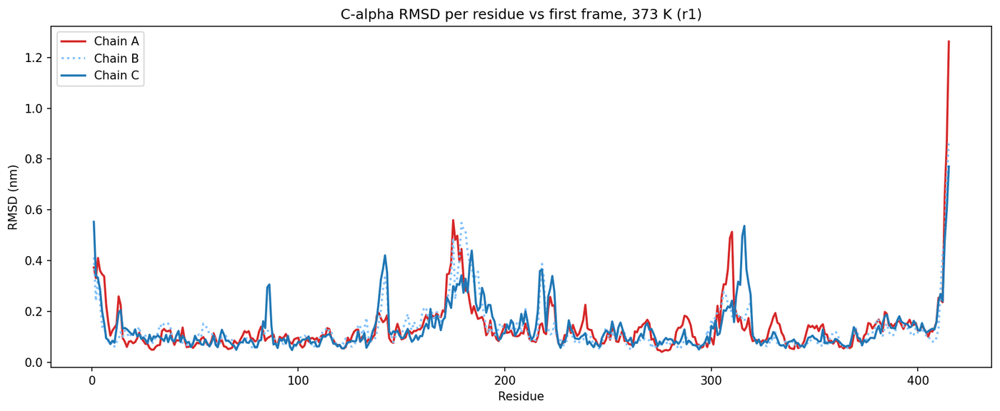

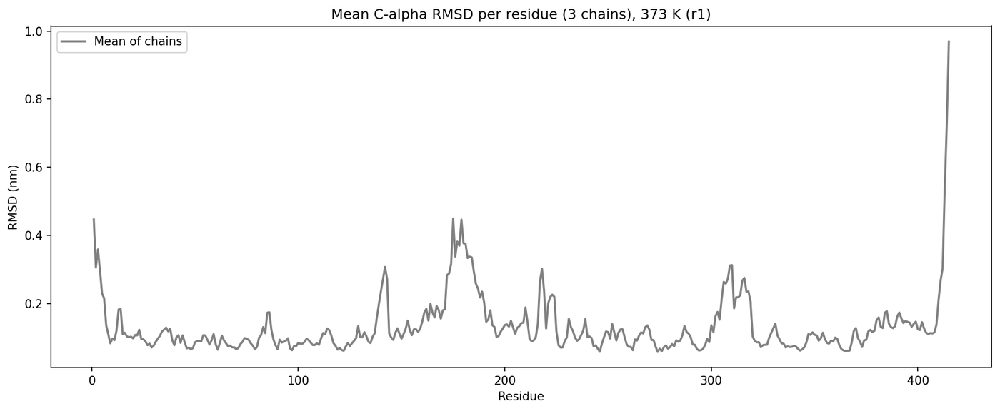

mean H-bonds/frame: 999.4


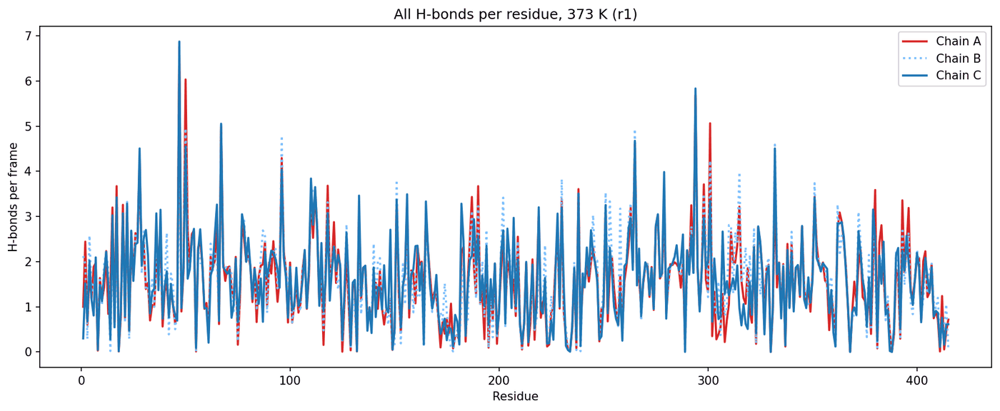

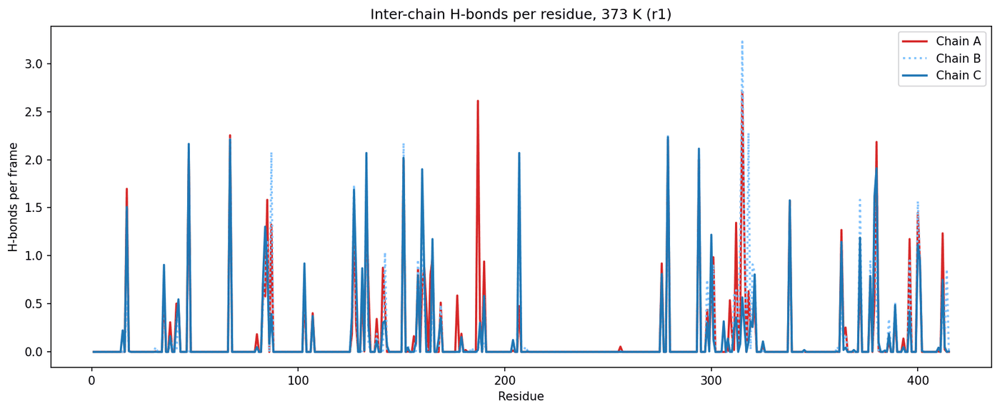

In [ ]:
from MDAnalysis.analysis.align import rotation_matrix
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
cs = {"chA":slice(0,6647), "chB":slice(6647,13294), "chC":slice(13294,19941)}
resR = {}
for name, s in cs.items():
    chn = u.atoms[s]; bb = chn.select_atoms("name N CA C"); ca = chn.select_atoms("name CA")
    u.trajectory[0]; c0 = bb.positions.mean(0); bb0 = bb.positions - c0; ca0 = ca.positions - c0
    d2 = np.zeros(len(ca)); n = 0
    for ts in u.trajectory:
        c = bb.positions.mean(0); R, _ = rotation_matrix(bb.positions - c, bb0)
        d2 += (((ca.positions - c) @ R.T - ca0)**2).sum(1); n += 1
    resR[name] = np.sqrt(d2/n)/10
    np.savetxt(f"{X}/rmsd_perres_{name}.xvg", np.c_[np.arange(1,416), resR[name]], fmt="%d %.6f")
draw("rmsd_per_residue", "C-alpha RMSD per residue vs first frame, 373 K (r1)", "Residue", "RMSD (nm)",
     [(np.arange(1,416), resR[c], s) for c, s in sty.items()])
m = np.mean(list(resR.values()), axis=0)
draw("rmsd_per_residue_mean", "Mean C-alpha RMSD per residue (3 chains), 373 K (r1)", "Residue", "RMSD (nm)",
     [(np.arange(1,416), m, dict(color="grey", label="Mean of chains"))])

# per-residue H-bonds (box-corrected trajectory, D-A <= 0.35 nm, angle <= 30 deg)
nmA = np.array([n.strip() for n in u.atoms.names]); rn = u.atoms.resnames
resid = u.atoms.resids; chain = np.arange(len(nmA))//6647
isH = np.array([n.startswith("H") for n in nmA])
P0 = u.atoms.positions/10; heavy = np.where(~isH)[0]; Hs = np.where(isH)[0]
don = heavy[cKDTree(P0[heavy]).query(P0[Hs])[1]]
k = np.array([nmA[i][0] in "NO" for i in don]); Hs, don = Hs[k], don[k]
acc = np.array([i for i in range(len(nmA)) if nmA[i][0]=="O" or (nmA[i] in ("ND1","NE2") and rn[i].startswith("HI"))])
tot = np.zeros((3,416)); inter = np.zeros((3,416)); nb = []
for ts in u.trajectory:
    Pf = u.atoms.positions/10; n = 0
    for hi, lst in enumerate(cKDTree(Pf[Hs]).query_ball_tree(cKDTree(Pf[acc]), 0.25)):
        D = don[hi]
        for aj in lst:
            A = acc[aj]
            if A == D or (chain[A]==chain[D] and resid[A]==resid[D]): continue
            v1, v2 = Pf[Hs[hi]]-Pf[D], Pf[A]-Pf[D]; dist = np.linalg.norm(v2)
            if dist > 0.35 or v1@v2/(np.linalg.norm(v1)*dist) < np.cos(np.radians(30)): continue
            n += 1
            for Xa in (D, A):
                tot[chain[Xa], resid[Xa]] += 1
                if chain[D] != chain[A]: inter[chain[Xa], resid[Xa]] += 1
    nb.append(n)
nf = len(nb); print("mean H-bonds/frame:", round(float(np.mean(nb)),1))
for nmx, arr, ttl in (("hbperres",tot,"All H-bonds per residue"), ("hbperres_inter",inter,"Inter-chain H-bonds per residue")):
    for i, c in enumerate(sty): np.savetxt(f"{X}/{nmx}_{c}.xvg", np.c_[np.arange(1,416), arr[i,1:]/nf], fmt="%d %.5f")
    draw(nmx, f"{ttl}, 373 K (r1)", "Residue", "H-bonds per frame",
         [(np.arange(1,416), arr[i,1:]/nf, s) for i, s in enumerate(sty.values())])

In [ ]:
%%bash
cd "$OUT/frames"
for c in chA chB chC; do
  printf "$c\n" | gmx dssp -s protein.tpr -f fit_cluster_skip5.xtc -n chains.ndx -o "$OUT/xvgs/dssp_$c.dat" > "$OUT/logs/dssp_$c.log" 2>&1
  echo $c; head -c 80 "$OUT/xvgs/dssp_$c.dat"; echo; tail -3 "$OUT/logs/dssp_$c.log"
done

chA
~HHHHH~TTEE~GGGEEEEEEETTEEEEEEPPSTTT~GGGTTSTT~EEEEEEE~TTEEEEEEE~SEEEEEEEEESEEEEE

GROMACS reminds you: ""What are the biological implications of your research?" - "Well, I simulate water." " (Petter Johansson)

chB
~HHHHH~TTEE~GGGEEEEEEETTEEEEEEPPSTTT~GGGTTSTT~EEEEEEE~TTEEEEEEE~SEEEEEEEEESEEEEE

GROMACS reminds you: "Encountered Subspace Anomaly" (Star Trek)

chC
~HHHHH~TTEE~GGGEEEEEEETTEEEEEEPPSTTT~GGGTTSTT~EEEEEEE~TTEEEEEEE~SEEEEEEEEESEEEEE

GROMACS reminds you: "Your Country Raised You, Your Country Fed You, and Just Like Any Other Country it Will Break You" (Gogol Bordello)



shape: (201, 1247) | chain breaks at columns: [415 831]
helix chA mean %: 16.0
helix chB mean %: 16.7
helix chC mean %: 15.8


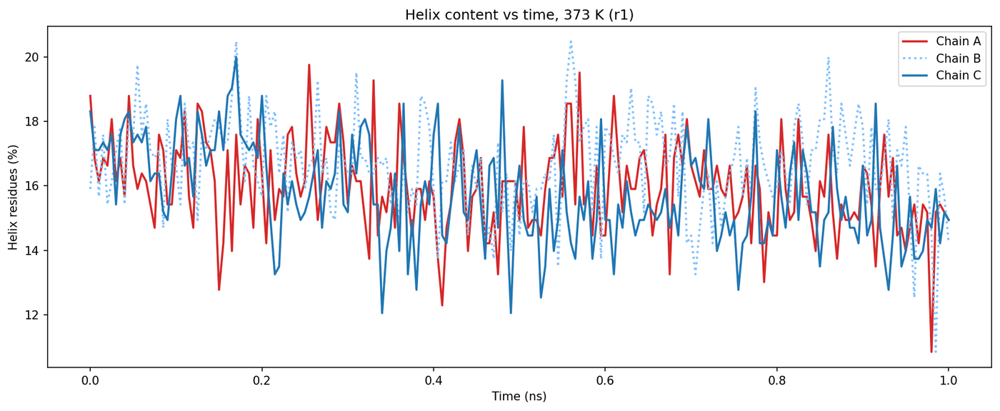

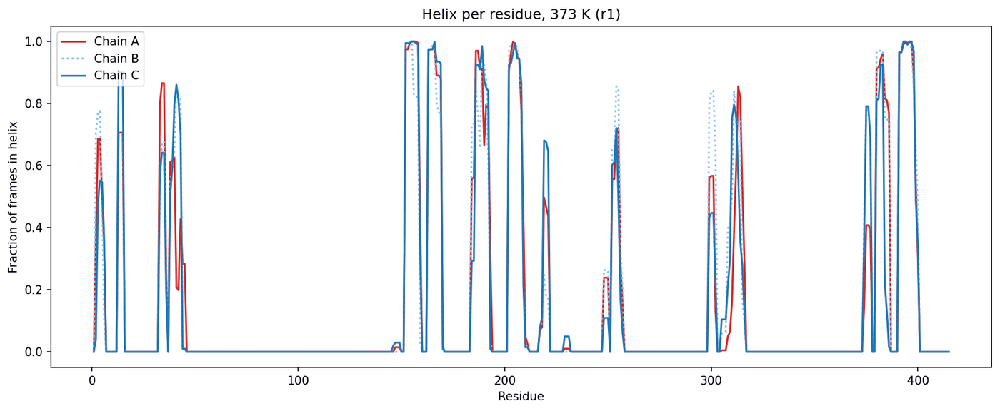

strand chA mean %: 37.2
strand chB mean %: 37.0
strand chC mean %: 37.6


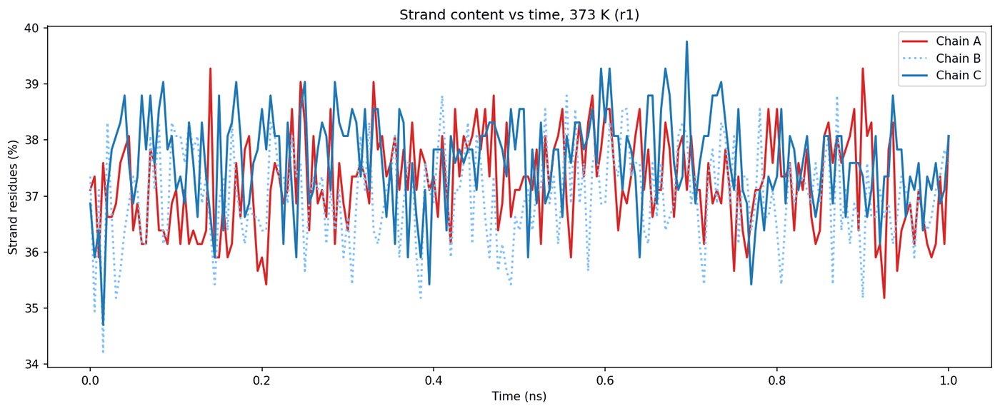

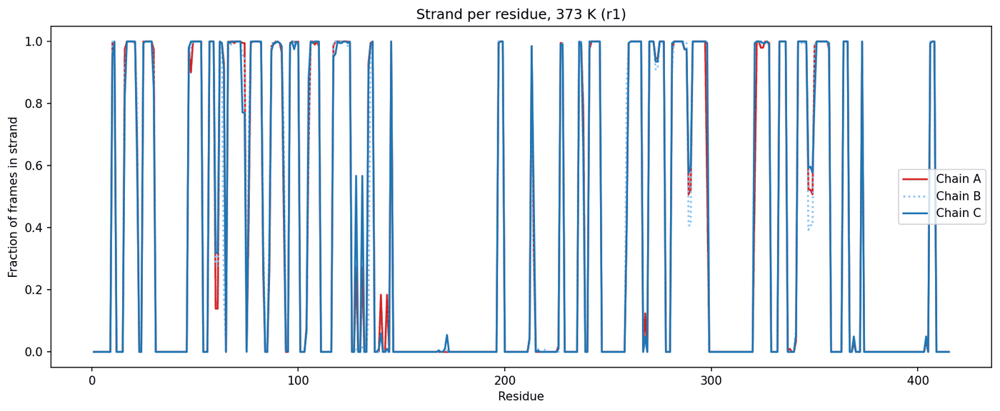

In [ ]:
import numpy as np, matplotlib.pyplot as plt, os
OUT = os.environ["OUT"]
a = np.array([list(l.rstrip("\n")) for l in open(f"{OUT}/xvgs/dssp_chA.dat") if l.strip()])
brk = np.where((a == "=").all(0))[0]
print("shape:", a.shape, "| chain breaks at columns:", brk)
a = a[:, ~(a == "=").all(0)]
assert a.shape[1] == 1245, a.shape
D = {c: a[:, i*415:(i+1)*415] for i, c in enumerate(("chA","chB","chC"))}

sty = {"chA": dict(color="#d62728", ls="-", label="Chain A"),
       "chB": dict(color="#7fbfff", ls=":", label="Chain B"),
       "chC": dict(color="#1f77b4", ls="-", label="Chain C")}
t = np.linspace(0, 1, len(a))
for name, ss, yl in (("helix","HGI","Helix residues (%)"), ("strand","EB","Strand residues (%)")):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        ax.plot(t, 100*np.isin(D[c], list(ss)).mean(1), lw=1.8, **s)
        print(name, c, "mean %:", round(100*np.isin(D[c], list(ss)).mean(), 1))
    ax.set(xlabel="Time (ns)", ylabel=yl, title=f"{name.capitalize()} content vs time, 373 K (r1)")
    ax.legend(); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_time.png"); plt.show()

    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        f = np.isin(D[c], list(ss)).mean(0); ax.plot(np.arange(1,416), f, lw=1.6, **s)
        np.savetxt(f"{OUT}/xvgs/dssp_{name}_perres_{c}.xvg", np.c_[np.arange(1,416), f], fmt="%d %.4f")
    ax.set(xlabel="Residue", ylabel=f"Fraction of frames in {name}", title=f"{name.capitalize()} per residue, 373 K (r1)")
    ax.legend(); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_perres.png"); plt.show()

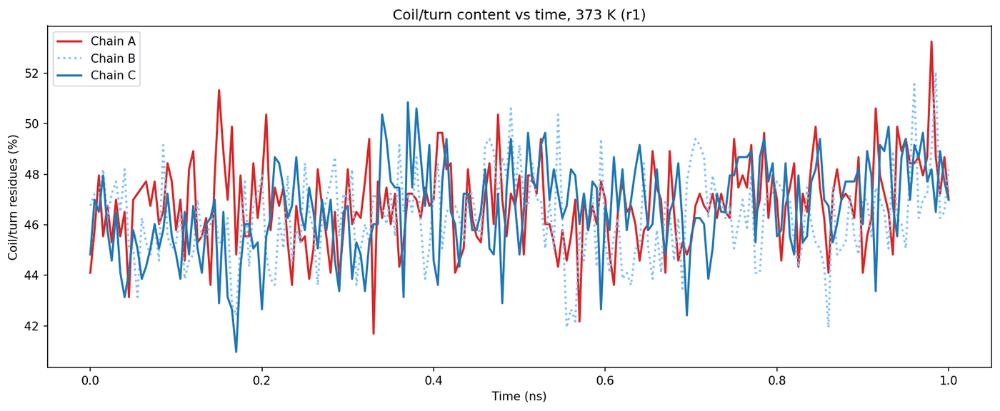

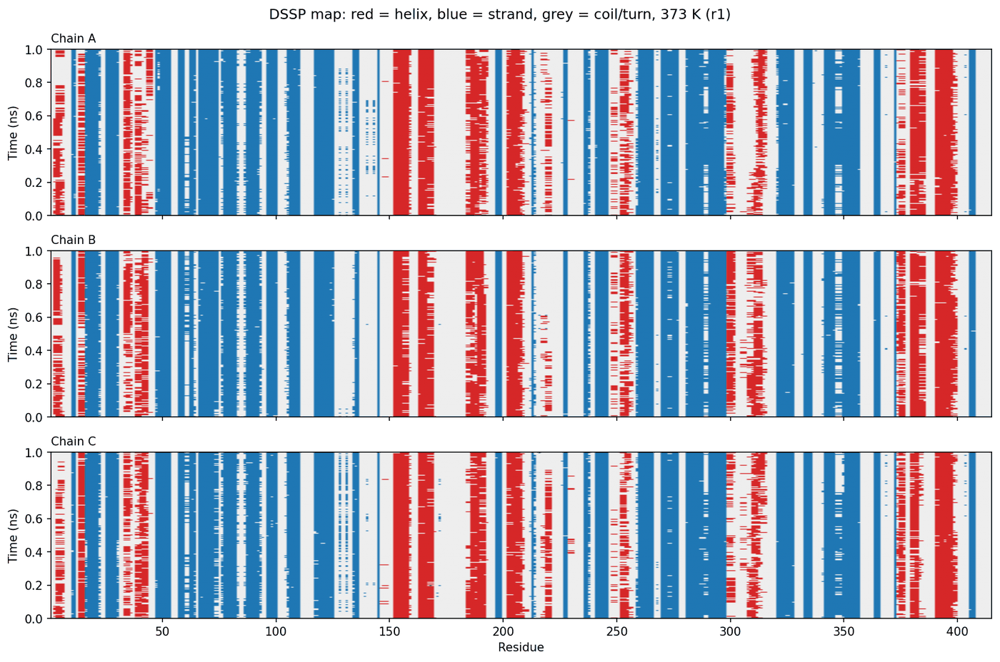

In [ ]:
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(12,5), dpi=150)
for c, s in sty.items():
    ax.plot(t, 100*(1-np.isin(D[c], list("HGIEB")).mean(1)), lw=1.8, **s)
ax.set(xlabel="Time (ns)", ylabel="Coil/turn residues (%)", title="Coil/turn content vs time, 373 K (r1)")
ax.legend(); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_coil_time.png"); plt.show()

cmap = ListedColormap(["#eeeeee", "#d62728", "#1f77b4"])   # coil, helix, strand
code = lambda m: np.where(np.isin(m, list("HGI")), 1, np.where(np.isin(m, list("EB")), 2, 0))
fig, axs = plt.subplots(3, 1, figsize=(12,8), dpi=150, sharex=True)
for ax, (c, s) in zip(axs, sty.items()):
    ax.imshow(code(D[c]), aspect="auto", cmap=cmap, vmin=0, vmax=2, origin="lower", extent=[1,415,0,1])
    ax.set_ylabel("Time (ns)"); ax.set_title(s["label"], loc="left", fontsize=10)
axs[-1].set_xlabel("Residue"); fig.suptitle("DSSP map: red = helix, blue = strand, grey = coil/turn, 373 K (r1)")
fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_map.png"); plt.show()

In [ ]:
import pandas as pd
def last(f, col=1): a = np.loadtxt(f, comments=('#','@')); return a[len(a)//2:, col].mean()
rows = []
for c in ("chA","chB","chC"):
    rows.append(dict(chain=c,
      RMSD_nm = last(f"{OUT}/xvgs/rmsd_{c}.xvg"), Rg_nm = last(f"{OUT}/xvgs/rg_{c}.xvg"),
      SASA_nm2 = last(f"{OUT}/xvgs/sasa_{c}.xvg", 2), intra_Hbonds = last(f"{OUT}/xvgs/hbnum_{c}.xvg"),
      helix_pct = 100*np.isin(D[c][len(t)//2:], list("HGI")).mean(), strand_pct = 100*np.isin(D[c][len(t)//2:], list("EB")).mean()))
rows.append(dict(chain="trimer", RMSD_nm=last(f"{OUT}/xvgs/rmsd_Protein.xvg"), Rg_nm=last(f"{OUT}/xvgs/rg_Protein.xvg"),
                 SASA_nm2=last(f"{OUT}/xvgs/sasa_Protein.xvg"), intra_Hbonds=last(f"{OUT}/xvgs/hbnum_Protein.xvg")))
df = pd.DataFrame(rows).round(3); df.to_csv(f"{OUT}/xvgs/summary_last0.5ns.csv", index=False); print(df)

    chain  RMSD_nm  Rg_nm  SASA_nm2  intra_Hbonds  helix_pct  strand_pct
0     chA    0.182  2.537   169.195       312.307     15.763      37.292
1     chB    0.170  2.567   177.328       321.733     16.615      37.092
2     chC    0.171  2.564   178.900       317.495     15.190      37.636
3  trimer    0.193  3.402   525.430      1039.980        NaN         NaN


(201, 1245)


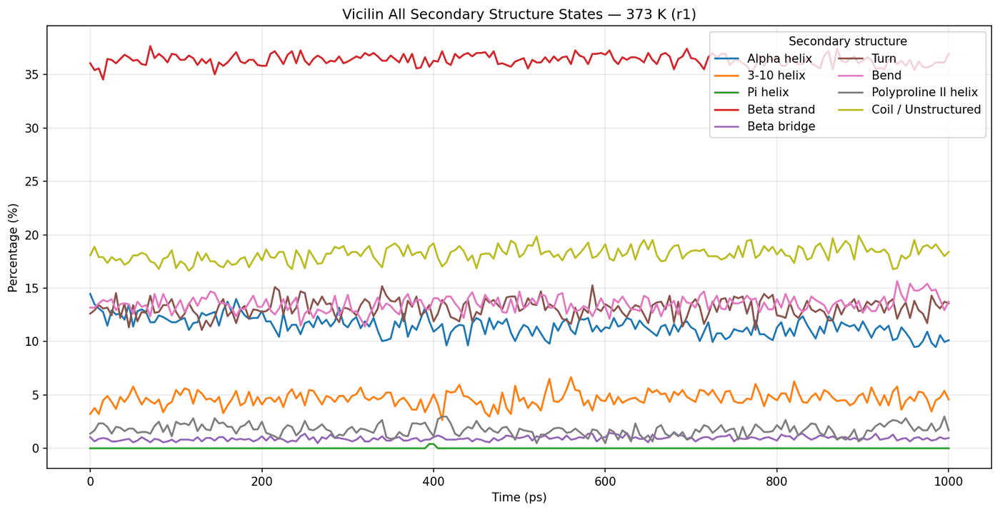

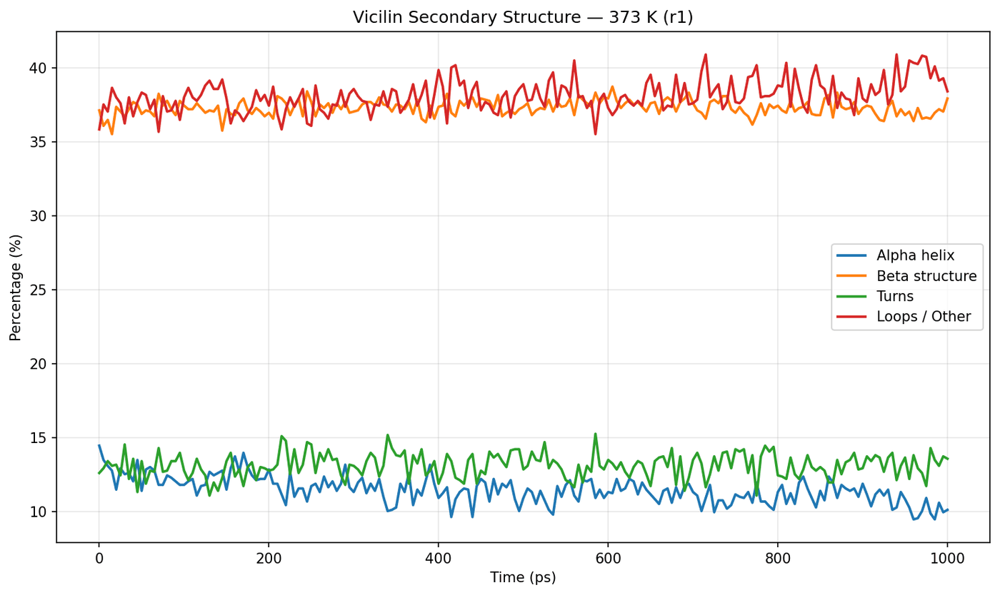

In [ ]:
import os, numpy as np, matplotlib.pyplot as plt
OUT = os.environ["OUT"]

def load_dssp(path):
    a = np.array([list(l.rstrip("\n")) for l in open(path) if l.strip()])
    return a[:, ~(a == "=").all(0)]            # frames x residues, chain breaks removed

STATES = [("Alpha helix","H"),("3-10 helix","G"),("Pi helix","I"),("Beta strand","E"),("Beta bridge","B"),
          ("Turn","T"),("Bend","S"),("Polyproline II helix","P")]
def percent(a):
    P = {n: 100*(a == c).mean(1) for n, c in STATES}
    P["Coil / Unstructured"] = 100 - sum(P.values())      # everything else
    return P

a = load_dssp(f"{OUT}/xvgs/dssp_chA.dat"); print(a.shape)   # expect (201, 1245)
P = percent(a); t = np.arange(len(a))*5.0                   # 5 ps between kept frames

fig, ax = plt.subplots(figsize=(12,6.2), dpi=150)
for i, (n, y) in enumerate(P.items()): ax.plot(t, y, color=plt.cm.tab10(i), lw=1.6, label=n)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title="Vicilin All Secondary Structure States — 373 K (r1)")
ax.grid(alpha=.3); ax.legend(title="Secondary structure", ncol=2, loc="upper right"); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_all_states_373K.png"); plt.show()

G = {"Alpha helix": P["Alpha helix"], "Beta structure": P["Beta strand"]+P["Beta bridge"], "Turns": P["Turn"]}
G["Loops / Other"] = 100 - sum(G.values())
fig, ax = plt.subplots(figsize=(10,6), dpi=150)
for i, (n, y) in enumerate(G.items()): ax.plot(t, y, color=plt.cm.tab10(i), lw=1.8, label=n)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title="Vicilin Secondary Structure — 373 K (r1)")
ax.grid(alpha=.3); ax.legend(); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_groups_373K.png"); plt.show()

In [ ]:
import os
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
os.system('ln -sfn "/content/drive/MyDrive/Plant Protein Extrusion MD" /content/pm')
os.environ.update(P="/content/pm", S="md_373_shear_r1", OUT="/content/pm/analysism/vicilin_373_shear_r1")
for d in ["graphs","logs","frames","xvgs"]: os.makedirs(f'{os.environ["OUT"]}/{d}', exist_ok=True)
os.system('pip install -q MDAnalysis scipy; gmx --version | head -1; ls $P/$S.*')

0

In [ ]:
%%bash
ls -lh /content/pm/md_373_shear_r1.*
echo "S=$S  OUT=$OUT"

-rw------- 1 root root 4.0M Oct 14 10:46 /content/pm/md_373_shear_r1.cpt
-rw------- 1 root root 604K Oct 14 10:46 /content/pm/md_373_shear_r1.edr
-rw------- 1 root root  12M Oct 12 17:33 /content/pm/md_373_shear_r1.gro
-rw------- 1 root root  80K Oct 14 10:46 /content/pm/md_373_shear_r1.log
-rw------- 1 root root  410 Oct 14 10:46 /content/pm/md_373_shear_r1.mdp
-rw------- 1 root root 8.6M Oct 14 10:46 /content/pm/md_373_shear_r1.tpr
-rw------- 1 root root  69M Oct 14 10:46 /content/pm/md_373_shear_r1.xtc
S=md_373_shear_r1  OUT=/content/pm/analysism/vicilin_373_shear_r1


In [ ]:
%%bash
cd "$OUT/frames"
printf "Protein\n" | gmx convert-tpr -s "$P/$S.tpr" -o protein.tpr 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f "$P/$S.xtc" -o whole2.xtc -pbc whole 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f whole2.xtc -o first_w.gro -dump 0 2>&1 | tail -1

Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'


In [ ]:
%%bash
gmx check -f "$P/$S.xtc" 2>&1 | grep -iE "Natoms|atoms|Last frame|Step"

# Atoms  19941
Item        #frames Timestep (ps)
Step           935    1


In [ ]:
%%bash
find /content/drive/MyDrive -type d -name "Shear Run" 2>/dev/null
find /content/drive/MyDrive -name "md_373_shear_r1.xtc" -exec ls -lh {} \; 2>/dev/null
find /content/drive/MyDrive -name "md_373_shear_r1.tpr" -exec ls -lh {} \; 2>/dev/null

-rw------- 1 root root 13M Oct 12 16:48 /content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261012_164810/md_373_shear_r1.xtc
-rw------- 1 root root 26M Oct 12 16:49 /content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261012_164911/md_373_shear_r1.xtc
-rw------- 1 root root 31M Oct 12 16:54 /content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261012_165411/md_373_shear_r1.xtc
-rw------- 1 root root 37M Oct 12 16:59 /content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261012_165912/md_373_shear_r1.xtc
-rw------- 1 root root 42M Oct 12 17:04 /content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261012_170413/md_373_shear_r1.xtc
-rw------- 1 root root 47M Oct 12 17:09 /content/drive/MyDrive/Plant Protein Extrusion MD/backups/md_373_shear_r1/20261012_170914/md_373_shear_r1.xtc
-rw------- 1 root root 52M Oct 12 17:14 /content/drive/MyDrive/Plant Protein Extrusion MD/backups/md

In [ ]:
import os, glob
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
os.system('ln -sfn "/content/drive/MyDrive/Plant Protein Extrusion MD" /content/pm')
sr = [d for d in glob.glob("/content/pm/Shear Run*") if os.path.isdir(d)][0]
os.system(f'ln -sfn "{sr}" /content/shear')
os.environ.update(P="/content/shear", S="md_373_shear_r1", OUT="/content/pm/analysism/vicilin_373_shear_r1")
for d in ["graphs","logs","frames","xvgs"]: os.makedirs(f'{os.environ["OUT"]}/{d}', exist_ok=True)
os.system('pip install -q MDAnalysis scipy; gmx --version | head -1; ls $P/$S.*')

0

In [ ]:
%%bash
ls -lh $P/$S.*
echo "S=$S  P=$P  OUT=$OUT"
gmx check -f "$P/$S.xtc" 2>&1 | grep -iE "Natoms|Last frame|Step|Time"

-rw------- 1 root root 4.0M Oct 14 11:05 /content/shear/md_373_shear_r1.cpt
-rw------- 1 root root 646K Oct 14 11:05 /content/shear/md_373_shear_r1.edr
-rw------- 1 root root  12M Oct 14 11:05 /content/shear/md_373_shear_r1.gro
-rw------- 1 root root  97K Oct 14 11:05 /content/shear/md_373_shear_r1.log
-rw------- 1 root root  410 Oct 14 11:05 /content/shear/md_373_shear_r1.mdp
-rw------- 1 root root 8.6M Oct 14 11:05 /content/shear/md_373_shear_r1.tpr
-rw------- 1 root root  73M Oct 14 11:05 /content/shear/md_373_shear_r1.xtc
S=md_373_shear_r1  P=/content/shear  OUT=/content/pm/analysism/vicilin_373_shear_r1
Reading frame       0 time    0.000   
Last frame       1000 time 1000.000   
Item        #frames Timestep (ps)
Step          1001    1
Time          1001    1


In [ ]:
%%bash
gmx check -f "$P/$S.xtc" 2>&1 | grep -iE "atoms"

# Atoms  19941


In [ ]:
%%bash
cd "$OUT/frames"
printf "Protein\n" | gmx convert-tpr -s "$P/$S.tpr" -o protein.tpr 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f "$P/$S.xtc" -o whole2.xtc -pbc whole 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f whole2.xtc -o first_w.gro -dump 0 2>&1 | tail -1

Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'


In [ ]:
import numpy as np, MDAnalysis as mda
from MDAnalysis.lib.distances import minimize_vectors
OUT = os.environ["OUT"]
u = mda.Universe(f"{OUT}/frames/first_w.gro", f"{OUT}/frames/whole2.xtc")
sl = {"A":slice(0,6647), "B":slice(6647,13294), "C":slice(13294,19941)}
with mda.Writer(f"{OUT}/frames/together.xtc", u.atoms.n_atoms) as W:
    for ts in u.trajectory[::5]:
        pos = u.atoms.positions.copy(); box = ts.dimensions.astype(np.float32)
        a0 = pos[sl["A"]].mean(0)
        for k in "BC":
            d = pos[sl[k]].mean(0) - a0
            dm = minimize_vectors(d[None,:].astype(np.float32), box)[0]
            pos[sl[k]] -= (d - dm)
        u.atoms.positions = pos; W.write(u.atoms)

In [ ]:
%%bash
cd "$OUT/frames"
printf "Backbone\nProtein\n" | gmx trjconv -s protein.tpr -f together.xtc -o fit_cluster_skip5.xtc -fit rot+trans 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f fit_cluster_skip5.xtc -o first_cl.gro -dump 0 2>&1 | tail -1
rm -f whole2.xtc together.xtc
gmx check -f fit_cluster_skip5.xtc 2>&1 | grep -E "Last frame|Step"

Selected 1: 'Protein'
Selected 1: 'Protein'
Last frame        200 time 1000.000   
Step           201    5


In [ ]:
from scipy.spatial import cKDTree
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
worst = {"AB":0,"BC":0,"AC":0}
for ts in u.trajectory:
    Pp = u.atoms.positions/10; chp = {k:Pp[s] for k,s in sl.items()}
    for p in worst: worst[p] = max(worst[p], cKDTree(chp[p[0]]).query(chp[p[1]])[0].min())
print({k: round(float(v),2) for k,v in worst.items()})
assert max(worst.values()) < 0.5, "chains NOT together - stop and send me this line"

nm = [a[10:15].strip() for a in open(f"{OUT}/frames/first_cl.gro").read().split("\n")[2:2+19941]]
G = {}
for c, r in {"chA":range(1,6648),"chB":range(6648,13295),"chC":range(13295,19942),"Protein":range(1,19942)}.items():
    G[c] = list(r); G[c+"_bb"] = [i for i in r if nm[i-1] in ("N","CA","C")]; G[c+"_CA"] = [i for i in r if nm[i-1]=="CA"]
with open(f"{OUT}/frames/chains.ndx","w") as f:
    for g, idx in G.items():
        f.write(f"[ {g} ]\n")
        for k in range(0, len(idx), 15): f.write(" ".join(f"{i:4d}" for i in idx[k:k+15]) + "\n")
print({g: len(v) for g, v in G.items()})

{'AB': 0.18, 'BC': 0.18, 'AC': 0.18}
{'chA': 6647, 'chA_bb': 1245, 'chA_CA': 415, 'chB': 6647, 'chB_bb': 1245, 'chB_CA': 415, 'chC': 6647, 'chC_bb': 1245, 'chC_CA': 415, 'Protein': 19941, 'Protein_bb': 3735, 'Protein_CA': 1245}


In [ ]:
%%bash
cd "$OUT/frames"; X="$OUT/xvgs"; L="$OUT/logs"; T=fit_cluster_skip5.xtc
for c in Protein chA chB chC; do
  printf "${c}_bb\n${c}_bb\n" | gmx rms  -s first_cl.gro -f $T -n chains.ndx -o $X/rmsd_$c.xvg -tu ns > $L/rmsd_$c.log 2>&1
  printf "${c}_CA\n${c}_CA\n" | gmx rmsf -s first_cl.gro -f $T -n chains.ndx -o $X/rmsf_$c.xvg -res   > $L/rmsf_$c.log 2>&1
  printf "$c\n"               | gmx gyrate -s protein.tpr -f $T -n chains.ndx -o $X/rg_$c.xvg          > $L/rg_$c.log 2>&1
  gmx sasa -s protein.tpr -f $T -n chains.ndx -surface "group Protein" -output "group $c" -o $X/sasa_$c.xvg -or $X/tmp_$c.xvg -tu ns > $L/sasa_$c.log 2>&1
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r "group $c" -t "group $c" -num $X/hbnum_$c.xvg -tu ns > $L/hbond_$c.log 2>&1
done
for p in "chA chB" "chB chC" "chA chC"; do set -- $p
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r "group $1" -t "group $2" -num $X/hbinter_$1_$2.xvg -tu ns > $L/hbinter_$1_$2.log 2>&1
done
mv $X/tmp_Protein.xvg $X/sasa_perres_Protein.xvg; rm -f $X/tmp_ch*.xvg
for f in rmsd_Protein rmsd_chA rmsf_chA rg_Protein sasa_chA hbnum_Protein hbinter_chA_chB; do echo $f $(tail -1 $X/$f.xvg); done

rmsd_Protein 1.0000000 0.1852334
rmsd_chA 1.0000000 0.1841216
rmsf_chA 415 0.2987
rg_Protein 1000.000 3.405029 2.778989 2.760418 2.801031
sasa_chA 1.000 514.891 171.346
hbnum_Protein 1.000 1037
hbinter_chA_chB 1.000 28


In [ ]:
import matplotlib.pyplot as plt
X = f"{OUT}/xvgs"
def xvg(f): return np.loadtxt(f, comments=('#','@'))
sty = {"chA": dict(color="#d62728", ls="-", label="Chain A"),
       "chB": dict(color="#7fbfff", ls=":", label="Chain B"),
       "chC": dict(color="#1f77b4", ls="-", label="Chain C")}
def draw(out, title, xl, yl, items):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for x, y, s in items: ax.plot(x, y, lw=1.8, **s)
    ax.set(xlabel=xl, ylabel=yl, title=title); ax.legend(); fig.tight_layout()
    fig.savefig(f"{OUT}/graphs/{out}.png"); plt.show()
def chains(prefix, col=1, sc=1):
    return [(xvg(f"{X}/{prefix}_{c}.xvg")[:,0]/sc, xvg(f"{X}/{prefix}_{c}.xvg")[:,col], s) for c, s in sty.items()]
def whole(prefix, col=1, sc=1):
    a = xvg(f"{X}/{prefix}_Protein.xvg"); return [(a[:,0]/sc, a[:,col], dict(color="grey", label="Whole trimer"))]

for pre, yl, ttl, sc, col in (("rmsd","RMSD (nm)","Backbone RMSD",1,1), ("rg","Rg (nm)","Radius of gyration",1000,1),
                              ("sasa","SASA (nm²)","SASA",1,None), ("hbnum","H-bonds","Intra-chain H-bonds",1,1)):
    cc = 2 if pre == "sasa" else 1
    draw(f"{pre}_per_chain", f"{ttl} per chain, 373 K shear (r1)", "Time (ns)", yl, chains(pre, cc, sc))
    draw(f"{pre}_protein", f"{ttl}, whole trimer, 373 K shear (r1)", "Time (ns)", yl, whole(pre, 1, sc))

# residue-based: RMSF per chain; SASA per residue (split the 1245-row trimer file)
draw("rmsf_per_chain", "C-alpha RMSF per residue, 373 K shear (r1)", "Residue", "RMSF (nm)", chains("rmsf"))
d = xvg(f"{X}/sasa_perres_Protein.xvg"); assert len(d) == 1245
draw("sasa_per_residue", "SASA per residue (time-averaged), 373 K shear (r1)", "Residue", "SASA (nm²)",
     [(np.arange(1,416), d[i*415:(i+1)*415,1], s) for i, s in enumerate(sty.values())])

# inter-chain H-bonds vs time
pairs = [("chA","chB","A–B"),("chB","chC","B–C"),("chA","chC","A–C")]
draw("hbonds_inter_chain", "Inter-chain H-bonds, 373 K shear (r1)", "Time (ns)", "H-bonds",
     [(xvg(f"{X}/hbinter_{a}_{b}.xvg")[:,0], xvg(f"{X}/hbinter_{a}_{b}.xvg")[:,1], dict(color=c, ls=l, label=n))
      for (a,b,n), c, l in zip(pairs, ("#d62728","#7fbfff","#1f77b4"), ("-",":","-"))])

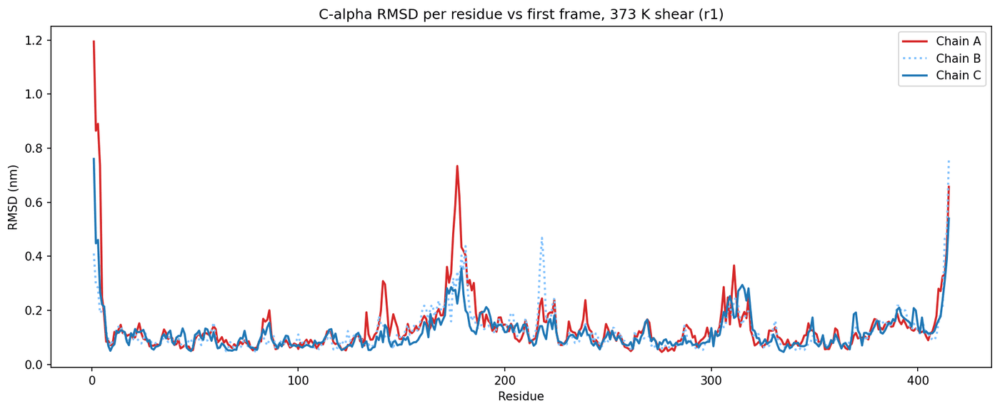

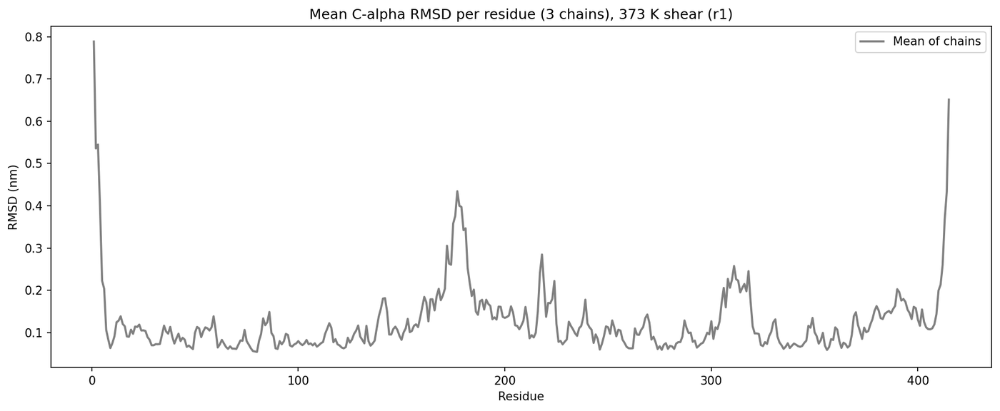

mean H-bonds/frame: 994.3


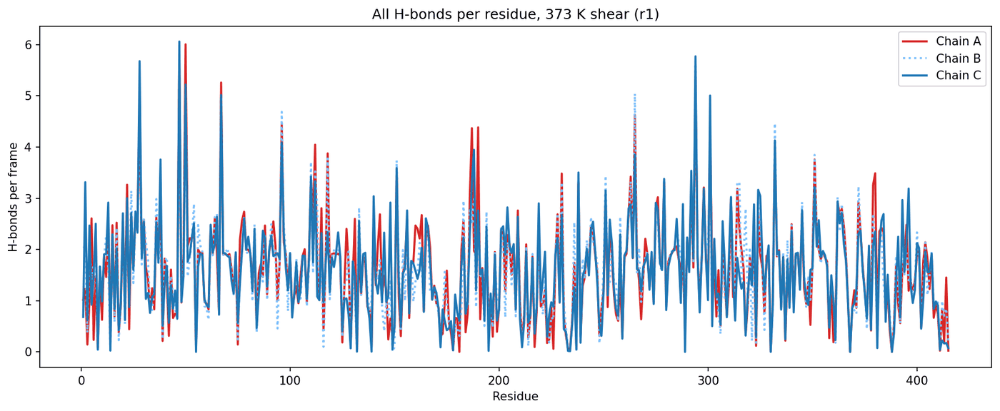

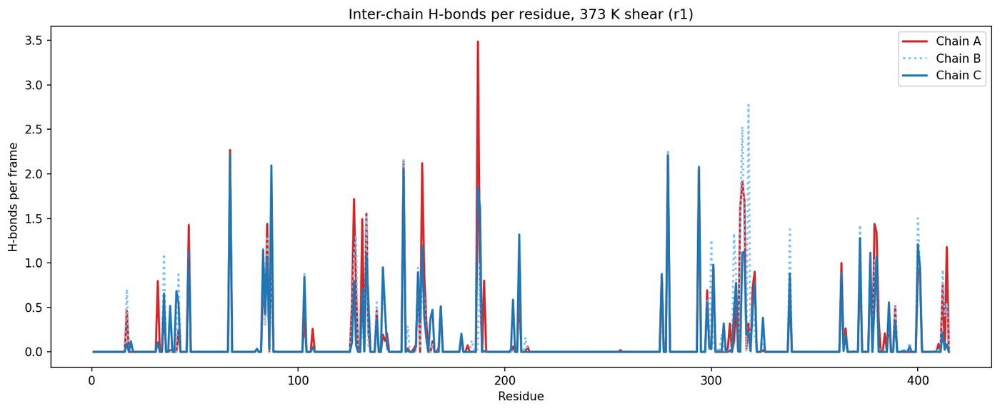

In [ ]:
from MDAnalysis.analysis.align import rotation_matrix
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
cs = {"chA":slice(0,6647), "chB":slice(6647,13294), "chC":slice(13294,19941)}
resR = {}
for name, s in cs.items():
    chn = u.atoms[s]; bb = chn.select_atoms("name N CA C"); ca = chn.select_atoms("name CA")
    u.trajectory[0]; c0 = bb.positions.mean(0); bb0 = bb.positions - c0; ca0 = ca.positions - c0
    d2 = np.zeros(len(ca)); n = 0
    for ts in u.trajectory:
        c = bb.positions.mean(0); R, _ = rotation_matrix(bb.positions - c, bb0)
        d2 += (((ca.positions - c) @ R.T - ca0)**2).sum(1); n += 1
    resR[name] = np.sqrt(d2/n)/10
    np.savetxt(f"{X}/rmsd_perres_{name}.xvg", np.c_[np.arange(1,416), resR[name]], fmt="%d %.6f")
draw("rmsd_per_residue", "C-alpha RMSD per residue vs first frame, 373 K shear (r1)", "Residue", "RMSD (nm)",
     [(np.arange(1,416), resR[c], s) for c, s in sty.items()])
m = np.mean(list(resR.values()), axis=0)
draw("rmsd_per_residue_mean", "Mean C-alpha RMSD per residue (3 chains), 373 K shear (r1)", "Residue", "RMSD (nm)",
     [(np.arange(1,416), m, dict(color="grey", label="Mean of chains"))])

# per-residue H-bonds (box-corrected trajectory, D-A <= 0.35 nm, angle <= 30 deg)
nmA = np.array([n.strip() for n in u.atoms.names]); rn = u.atoms.resnames
resid = u.atoms.resids; chain = np.arange(len(nmA))//6647
isH = np.array([n.startswith("H") for n in nmA])
P0 = u.atoms.positions/10; heavy = np.where(~isH)[0]; Hs = np.where(isH)[0]
don = heavy[cKDTree(P0[heavy]).query(P0[Hs])[1]]
k = np.array([nmA[i][0] in "NO" for i in don]); Hs, don = Hs[k], don[k]
acc = np.array([i for i in range(len(nmA)) if nmA[i][0]=="O" or (nmA[i] in ("ND1","NE2") and rn[i].startswith("HI"))])
tot = np.zeros((3,416)); inter = np.zeros((3,416)); nb = []
for ts in u.trajectory:
    Pf = u.atoms.positions/10; n = 0
    for hi, lst in enumerate(cKDTree(Pf[Hs]).query_ball_tree(cKDTree(Pf[acc]), 0.25)):
        D = don[hi]
        for aj in lst:
            A = acc[aj]
            if A == D or (chain[A]==chain[D] and resid[A]==resid[D]): continue
            v1, v2 = Pf[Hs[hi]]-Pf[D], Pf[A]-Pf[D]; dist = np.linalg.norm(v2)
            if dist > 0.35 or v1@v2/(np.linalg.norm(v1)*dist) < np.cos(np.radians(30)): continue
            n += 1
            for Xa in (D, A):
                tot[chain[Xa], resid[Xa]] += 1
                if chain[D] != chain[A]: inter[chain[Xa], resid[Xa]] += 1
    nb.append(n)
nf = len(nb); print("mean H-bonds/frame:", round(float(np.mean(nb)),1))
for nmx, arr, ttl in (("hbperres",tot,"All H-bonds per residue"), ("hbperres_inter",inter,"Inter-chain H-bonds per residue")):
    for i, c in enumerate(sty): np.savetxt(f"{X}/{nmx}_{c}.xvg", np.c_[np.arange(1,416), arr[i,1:]/nf], fmt="%d %.5f")
    draw(nmx, f"{ttl}, 373 K shear (r1)", "Residue", "H-bonds per frame",
         [(np.arange(1,416), arr[i,1:]/nf, s) for i, s in enumerate(sty.values())])

In [ ]:
%%bash
cd "$OUT/frames"
for c in chA chB chC; do
  printf "$c\n" | gmx dssp -s protein.tpr -f fit_cluster_skip5.xtc -n chains.ndx -o "$OUT/xvgs/dssp_$c.dat" > "$OUT/logs/dssp_$c.log" 2>&1
  echo $c; head -c 80 "$OUT/xvgs/dssp_$c.dat"; echo; tail -3 "$OUT/logs/dssp_$c.log"
done

chA
~HHHHH~TTEE~GGGEEEEEEETTEEEEEEPPSTTT~GGGTTSTT~EEEEEEE~TTEEEEEEE~SEEEEEEEEESEEEEE

GROMACS reminds you: "This May Come As a Shock" (F. Black)

chB
~HHHHH~TTEE~GGGEEEEEEETTEEEEEEPPSTTT~GGGTTSTT~EEEEEEE~TTEEEEEEE~SEEEEEEEEESEEEEE

GROMACS reminds you: "Good judgement is the result of experience; experience is the result of bad judgement." (Mark Twain)

chC
~HHHHH~TTEE~GGGEEEEEEETTEEEEEEPPSTTT~GGGTTSTT~EEEEEEE~TTEEEEEEE~SEEEEEEEEESEEEEE

GROMACS reminds you: "I'll Master Your Language, and In the Meantime I'll Create My Own" (Tricky)



shape: (201, 1247) | chain breaks at columns: [415 831]
helix chA mean %: 16.5
helix chB mean %: 16.4
helix chC mean %: 16.6


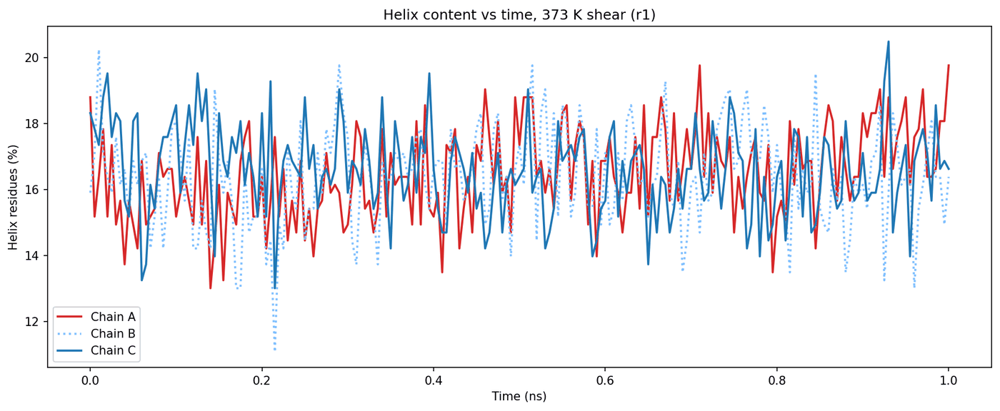

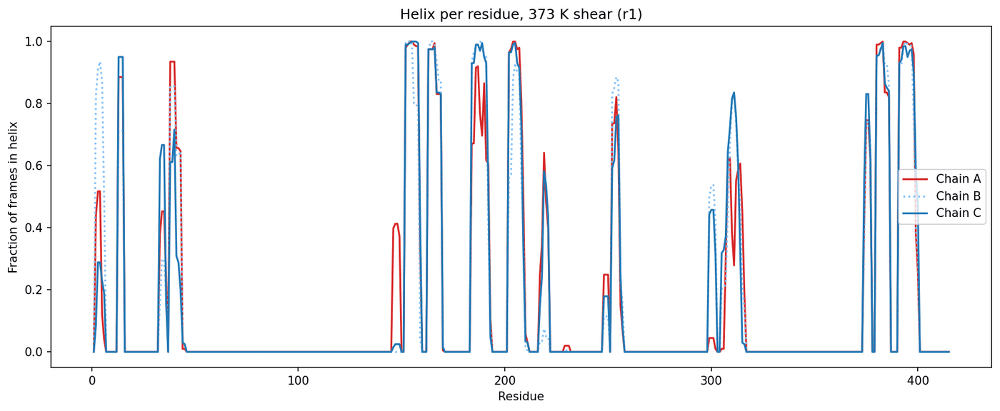

strand chA mean %: 37.2
strand chB mean %: 37.1
strand chC mean %: 38.4


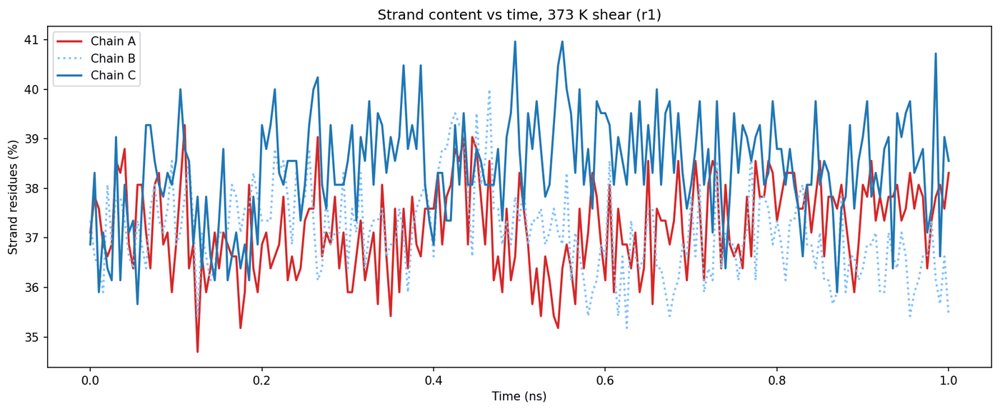

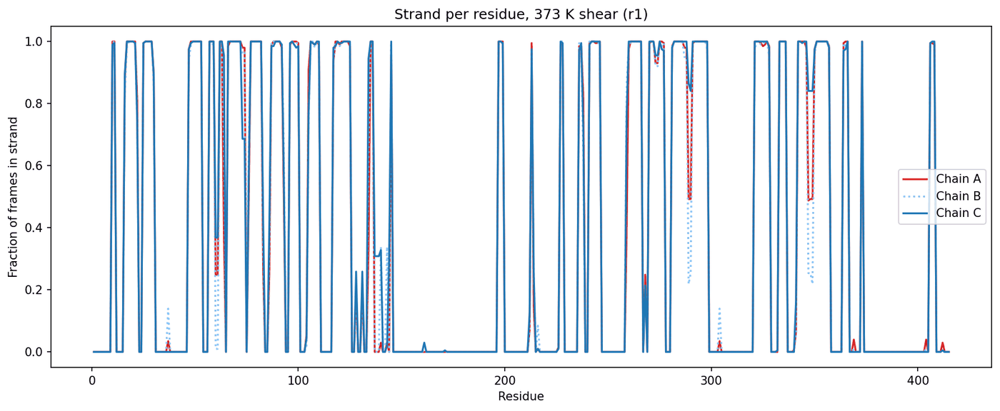

In [ ]:
import numpy as np, matplotlib.pyplot as plt, os
OUT = os.environ["OUT"]
a = np.array([list(l.rstrip("\n")) for l in open(f"{OUT}/xvgs/dssp_chA.dat") if l.strip()])
brk = np.where((a == "=").all(0))[0]
print("shape:", a.shape, "| chain breaks at columns:", brk)
a = a[:, ~(a == "=").all(0)]
assert a.shape[1] == 1245, a.shape
D = {c: a[:, i*415:(i+1)*415] for i, c in enumerate(("chA","chB","chC"))}

sty = {"chA": dict(color="#d62728", ls="-", label="Chain A"),
       "chB": dict(color="#7fbfff", ls=":", label="Chain B"),
       "chC": dict(color="#1f77b4", ls="-", label="Chain C")}
t = np.linspace(0, 1, len(a))
for name, ss, yl in (("helix","HGI","Helix residues (%)"), ("strand","EB","Strand residues (%)")):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        ax.plot(t, 100*np.isin(D[c], list(ss)).mean(1), lw=1.8, **s)
        print(name, c, "mean %:", round(100*np.isin(D[c], list(ss)).mean(), 1))
    ax.set(xlabel="Time (ns)", ylabel=yl, title=f"{name.capitalize()} content vs time, 373 K shear (r1)")
    ax.legend(); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_time.png"); plt.show()

    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        f = np.isin(D[c], list(ss)).mean(0); ax.plot(np.arange(1,416), f, lw=1.6, **s)
        np.savetxt(f"{OUT}/xvgs/dssp_{name}_perres_{c}.xvg", np.c_[np.arange(1,416), f], fmt="%d %.4f")
    ax.set(xlabel="Residue", ylabel=f"Fraction of frames in {name}", title=f"{name.capitalize()} per residue, 373 K shear (r1)")
    ax.legend(); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_perres.png"); plt.show()

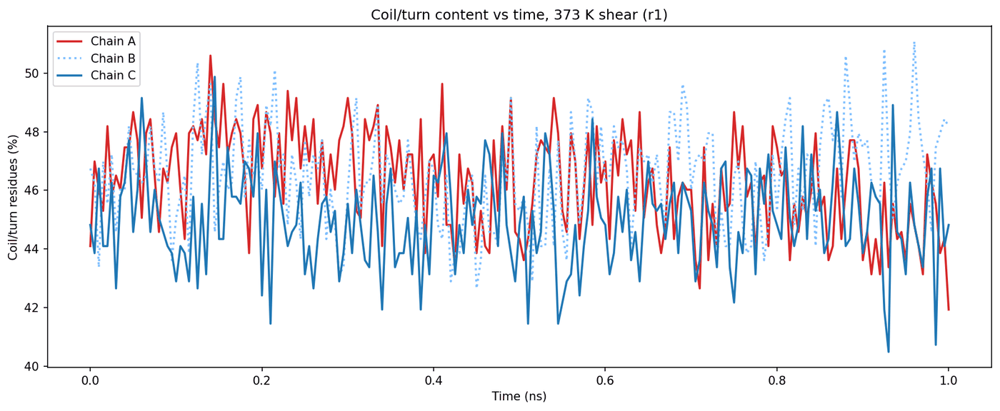

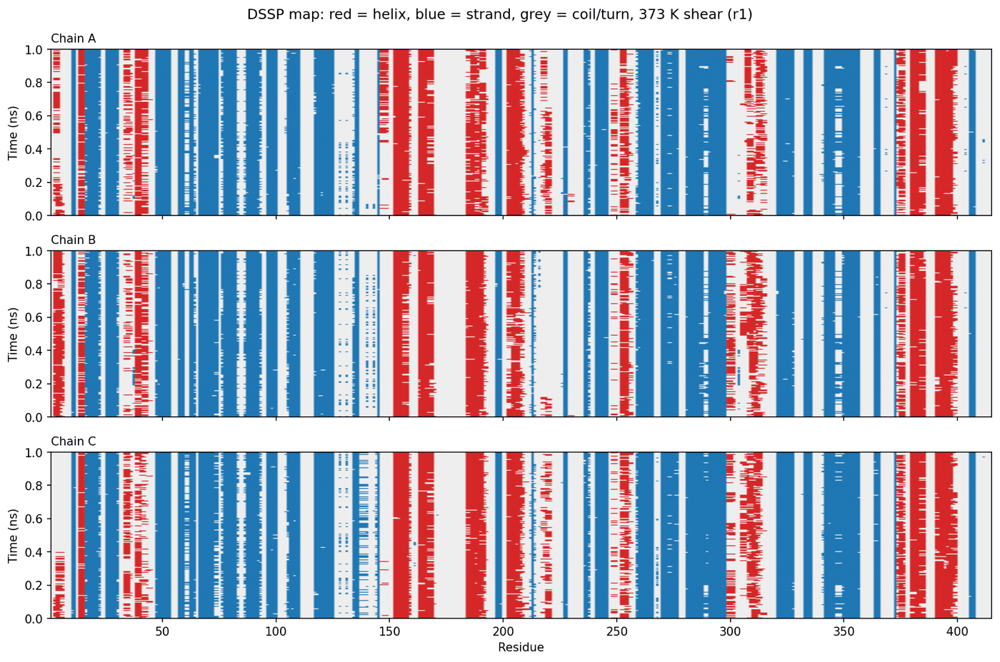

In [ ]:
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(12,5), dpi=150)
for c, s in sty.items():
    ax.plot(t, 100*(1-np.isin(D[c], list("HGIEB")).mean(1)), lw=1.8, **s)
ax.set(xlabel="Time (ns)", ylabel="Coil/turn residues (%)", title="Coil/turn content vs time, 373 K shear (r1)")
ax.legend(); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_coil_time.png"); plt.show()

cmap = ListedColormap(["#eeeeee", "#d62728", "#1f77b4"])   # coil, helix, strand
code = lambda m: np.where(np.isin(m, list("HGI")), 1, np.where(np.isin(m, list("EB")), 2, 0))
fig, axs = plt.subplots(3, 1, figsize=(12,8), dpi=150, sharex=True)
for ax, (c, s) in zip(axs, sty.items()):
    ax.imshow(code(D[c]), aspect="auto", cmap=cmap, vmin=0, vmax=2, origin="lower", extent=[1,415,0,1])
    ax.set_ylabel("Time (ns)"); ax.set_title(s["label"], loc="left", fontsize=10)
axs[-1].set_xlabel("Residue"); fig.suptitle("DSSP map: red = helix, blue = strand, grey = coil/turn, 373 K shear (r1)")
fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_map.png"); plt.show()

In [ ]:
import pandas as pd
def last(f, col=1): a = np.loadtxt(f, comments=('#','@')); return a[len(a)//2:, col].mean()
rows = []
for c in ("chA","chB","chC"):
    rows.append(dict(chain=c,
      RMSD_nm = last(f"{OUT}/xvgs/rmsd_{c}.xvg"), Rg_nm = last(f"{OUT}/xvgs/rg_{c}.xvg"),
      SASA_nm2 = last(f"{OUT}/xvgs/sasa_{c}.xvg", 2), intra_Hbonds = last(f"{OUT}/xvgs/hbnum_{c}.xvg"),
      helix_pct = 100*np.isin(D[c][len(t)//2:], list("HGI")).mean(), strand_pct = 100*np.isin(D[c][len(t)//2:], list("EB")).mean()))
rows.append(dict(chain="trimer", RMSD_nm=last(f"{OUT}/xvgs/rmsd_Protein.xvg"), Rg_nm=last(f"{OUT}/xvgs/rg_Protein.xvg"),
                 SASA_nm2=last(f"{OUT}/xvgs/sasa_Protein.xvg"), intra_Hbonds=last(f"{OUT}/xvgs/hbnum_Protein.xvg")))
df = pd.DataFrame(rows).round(3); df.to_csv(f"{OUT}/xvgs/summary_last0.5ns.csv", index=False); print(df)

    chain  RMSD_nm  Rg_nm  SASA_nm2  intra_Hbonds  helix_pct  strand_pct
0     chA    0.189  2.570   170.775       318.436     16.972      37.314
1     chB    0.148  2.547   171.382       315.752     16.548      36.746
2     chC    0.144  2.551   171.076       319.733     16.402      38.633
3  trimer    0.182  3.398   513.239      1042.455        NaN         NaN


(201, 1245)


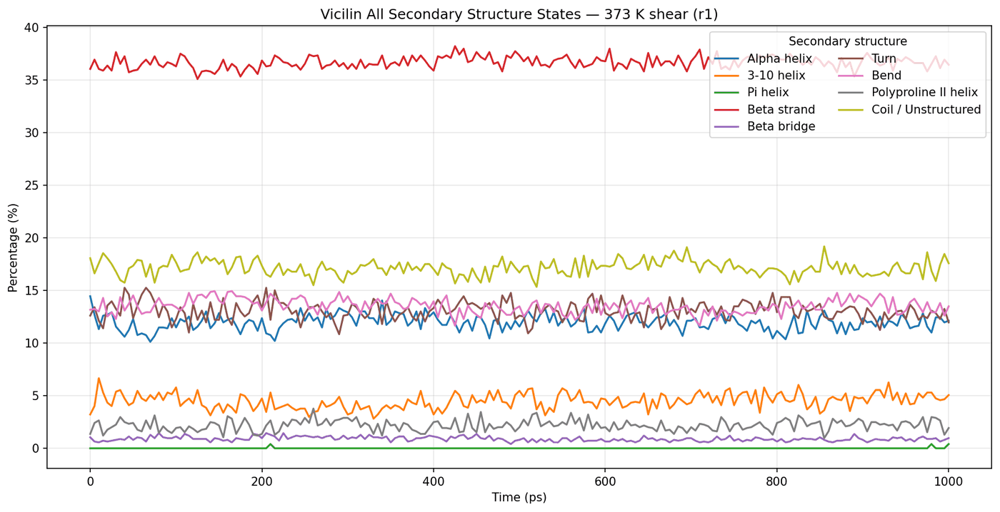

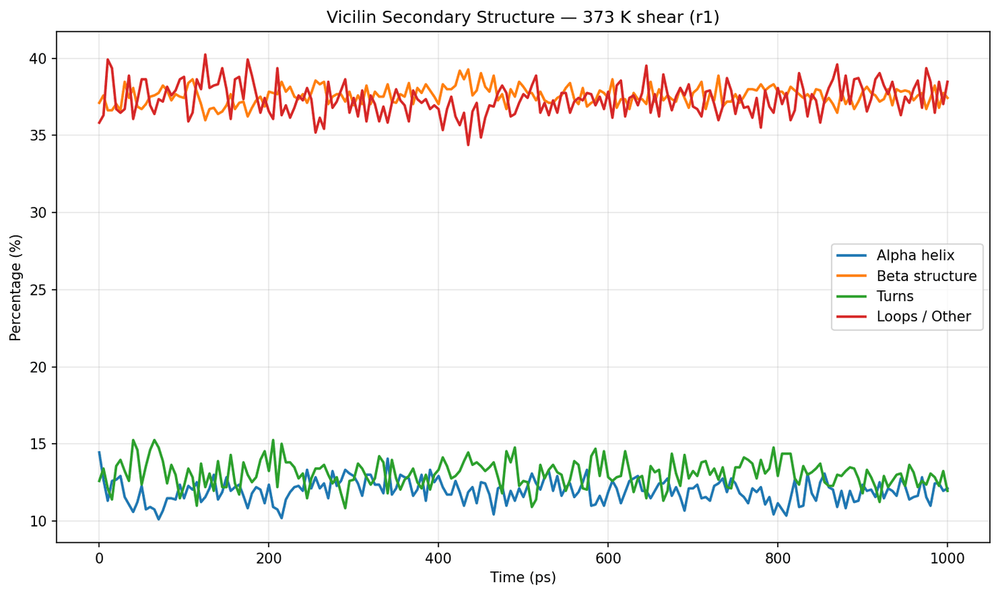

In [ ]:
import os, numpy as np, matplotlib.pyplot as plt
OUT = os.environ["OUT"]

def load_dssp(path):
    a = np.array([list(l.rstrip("\n")) for l in open(path) if l.strip()])
    return a[:, ~(a == "=").all(0)]

STATES = [("Alpha helix","H"),("3-10 helix","G"),("Pi helix","I"),("Beta strand","E"),("Beta bridge","B"),
          ("Turn","T"),("Bend","S"),("Polyproline II helix","P")]
def percent(a):
    P = {n: 100*(a == c).mean(1) for n, c in STATES}
    P["Coil / Unstructured"] = 100 - sum(P.values())
    return P

a = load_dssp(f"{OUT}/xvgs/dssp_chA.dat"); print(a.shape)   # expect (201, 1245)
P = percent(a); t = np.arange(len(a))*5.0                   # 5 ps between kept frames

fig, ax = plt.subplots(figsize=(12,6.2), dpi=150)
for i, (n, y) in enumerate(P.items()): ax.plot(t, y, color=plt.cm.tab10(i), lw=1.6, label=n)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title="Vicilin All Secondary Structure States — 373 K shear (r1)")
ax.grid(alpha=.3); ax.legend(title="Secondary structure", ncol=2, loc="upper right"); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_all_states_373K_shear.png"); plt.show()

G = {"Alpha helix": P["Alpha helix"], "Beta structure": P["Beta strand"]+P["Beta bridge"], "Turns": P["Turn"]}
G["Loops / Other"] = 100 - sum(G.values())
fig, ax = plt.subplots(figsize=(10,6), dpi=150)
for i, (n, y) in enumerate(G.items()): ax.plot(t, y, color=plt.cm.tab10(i), lw=1.8, label=n)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title="Vicilin Secondary Structure — 373 K shear (r1)")
ax.grid(alpha=.3); ax.legend(); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_groups_373K_shear.png"); plt.show()

In [ ]:
import os
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
os.system('ln -sfn "/content/drive/MyDrive/Plant Protein Extrusion MD" /content/pm')
os.environ.update(P="/content/pm", S="md_300_r1", OUT="/content/pm/analysism/vicilin_300_r1")
for d in ["graphs","logs","frames","xvgs"]: os.makedirs(f'{os.environ["OUT"]}/{d}', exist_ok=True)
os.system('pip install -q MDAnalysis scipy; gmx --version | head -1; ls $P/$S.*')

0

In [ ]:
%%bash
ls -lh $P/$S.*
echo "S=$S  OUT=$OUT"
gmx check -f "$P/$S.xtc" 2>&1 | grep -iE "Natoms|Last frame|Step|Time"
find /content/drive/MyDrive -name "md_300_r1.xtc" -exec ls -lh {} \; 2>/dev/null

-rw------- 1 root root 4.0M Oct 10 17:32 /content/pm/md_300_r1.cpt
-rw------- 1 root root 552K Oct 10 16:46 /content/pm/md_300_r1.edr
-rw------- 1 root root  12M Oct 10 17:32 /content/pm/md_300_r1.gro
-rw------- 1 root root  89K Oct 10 17:32 /content/pm/md_300_r1.log
-rw------- 1 root root  403 Oct 10 16:46 /content/pm/md_300_r1.mdp
-rw------- 1 root root 8.8M Oct 10 16:46 /content/pm/md_300_r1.tpr
-rw------- 1 root root  73M Oct 10 16:46 /content/pm/md_300_r1.xtc
S=md_300_r1  OUT=/content/pm/analysism/vicilin_300_r1
Reading frame       0 time    0.000   
Last frame       1000 time 1000.000   
Item        #frames Timestep (ps)
Step          1001    1
Time          1001    1
-rw------- 1 root root 73M Oct 10 16:46 /content/drive/MyDrive/Plant Protein Extrusion MD/md_300_r1.xtc


In [ ]:
%%bash
cd "$OUT/frames"
printf "Protein\n" | gmx convert-tpr -s "$P/$S.tpr" -o protein.tpr 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f "$P/$S.xtc" -o whole2.xtc -pbc whole 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f whole2.xtc -o first_w.gro -dump 0 2>&1 | tail -1

Selected 1: 'Protein'
Selected 1: 'Protein'
Selected 1: 'Protein'


In [ ]:
import numpy as np, MDAnalysis as mda
from MDAnalysis.lib.distances import minimize_vectors
OUT = os.environ["OUT"]
u = mda.Universe(f"{OUT}/frames/first_w.gro", f"{OUT}/frames/whole2.xtc")
sl = {"A":slice(0,6647), "B":slice(6647,13294), "C":slice(13294,19941)}
with mda.Writer(f"{OUT}/frames/together.xtc", u.atoms.n_atoms) as W:
    for ts in u.trajectory[::5]:
        pos = u.atoms.positions.copy(); box = ts.dimensions.astype(np.float32)
        a0 = pos[sl["A"]].mean(0)
        for k in "BC":
            d = pos[sl[k]].mean(0) - a0
            dm = minimize_vectors(d[None,:].astype(np.float32), box)[0]
            pos[sl[k]] -= (d - dm)
        u.atoms.positions = pos; W.write(u.atoms)

In [ ]:
%%bash
cd "$OUT/frames"
printf "Backbone\nProtein\n" | gmx trjconv -s protein.tpr -f together.xtc -o fit_cluster_skip5.xtc -fit rot+trans 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f fit_cluster_skip5.xtc -o first_cl.gro -dump 0 2>&1 | tail -1
rm -f whole2.xtc together.xtc
gmx check -f fit_cluster_skip5.xtc 2>&1 | grep -E "Last frame|Step"

Selected 1: 'Protein'
Selected 1: 'Protein'
Last frame        200 time 1000.000   
Step           201    5


In [ ]:
from scipy.spatial import cKDTree
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
worst = {"AB":0,"BC":0,"AC":0}
for ts in u.trajectory:
    Pp = u.atoms.positions/10; chp = {k:Pp[s] for k,s in sl.items()}
    for p in worst: worst[p] = max(worst[p], cKDTree(chp[p[0]]).query(chp[p[1]])[0].min())
print({k: round(float(v),2) for k,v in worst.items()})
assert max(worst.values()) < 0.5, "chains NOT together - stop and send me this line"

nm = [a[10:15].strip() for a in open(f"{OUT}/frames/first_cl.gro").read().split("\n")[2:2+19941]]
G = {}
for c, r in {"chA":range(1,6648),"chB":range(6648,13295),"chC":range(13295,19942),"Protein":range(1,19942)}.items():
    G[c] = list(r); G[c+"_bb"] = [i for i in r if nm[i-1] in ("N","CA","C")]; G[c+"_CA"] = [i for i in r if nm[i-1]=="CA"]
with open(f"{OUT}/frames/chains.ndx","w") as f:
    for g, idx in G.items():
        f.write(f"[ {g} ]\n")
        for k in range(0, len(idx), 15): f.write(" ".join(f"{i:4d}" for i in idx[k:k+15]) + "\n")
print({g: len(v) for g, v in G.items()})

{'AB': 0.18, 'BC': 0.18, 'AC': 0.17}
{'chA': 6647, 'chA_bb': 1245, 'chA_CA': 415, 'chB': 6647, 'chB_bb': 1245, 'chB_CA': 415, 'chC': 6647, 'chC_bb': 1245, 'chC_CA': 415, 'Protein': 19941, 'Protein_bb': 3735, 'Protein_CA': 1245}


In [ ]:
%%bash
cd "$OUT/frames"; X="$OUT/xvgs"; L="$OUT/logs"; T=fit_cluster_skip5.xtc
for c in Protein chA chB chC; do
  printf "${c}_bb\n${c}_bb\n" | gmx rms  -s first_cl.gro -f $T -n chains.ndx -o $X/rmsd_$c.xvg -tu ns > $L/rmsd_$c.log 2>&1
  printf "${c}_CA\n${c}_CA\n" | gmx rmsf -s first_cl.gro -f $T -n chains.ndx -o $X/rmsf_$c.xvg -res   > $L/rmsf_$c.log 2>&1
  printf "$c\n"               | gmx gyrate -s protein.tpr -f $T -n chains.ndx -o $X/rg_$c.xvg          > $L/rg_$c.log 2>&1
  gmx sasa -s protein.tpr -f $T -n chains.ndx -surface "group Protein" -output "group $c" -o $X/sasa_$c.xvg -or $X/tmp_$c.xvg -tu ns > $L/sasa_$c.log 2>&1
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r "group $c" -t "group $c" -num $X/hbnum_$c.xvg -tu ns > $L/hbond_$c.log 2>&1
done
for p in "chA chB" "chB chC" "chA chC"; do set -- $p
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r "group $1" -t "group $2" -num $X/hbinter_$1_$2.xvg -tu ns > $L/hbinter_$1_$2.log 2>&1
done
mv $X/tmp_Protein.xvg $X/sasa_perres_Protein.xvg; rm -f $X/tmp_ch*.xvg
for f in rmsd_Protein rmsd_chA rmsf_chA rg_Protein sasa_chA hbnum_Protein hbinter_chA_chB; do echo $f $(tail -1 $X/$f.xvg); done

rmsd_Protein 1.0000000 0.1556209
rmsd_chA 1.0000000 0.1536405
rmsf_chA 415 0.2703
rg_Protein 1000.000 3.397064 2.773021 2.755725 2.792211
sasa_chA 1.000 521.208 171.057
hbnum_Protein 1.000 1052
hbinter_chA_chB 1.000 31


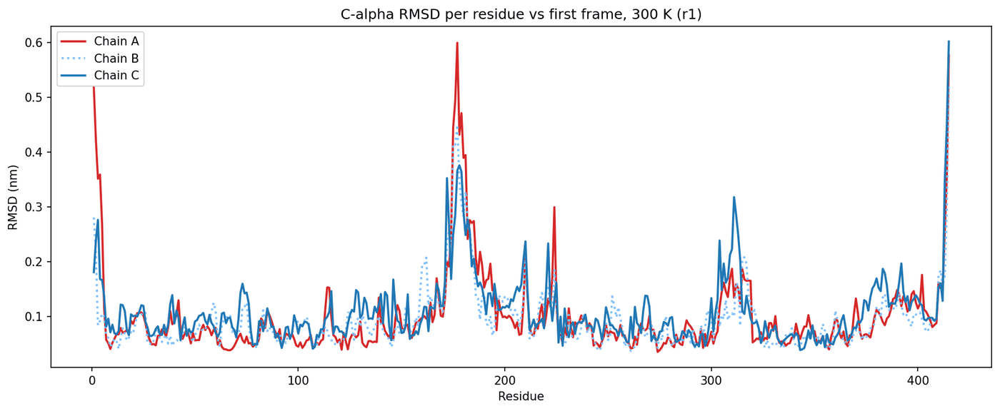

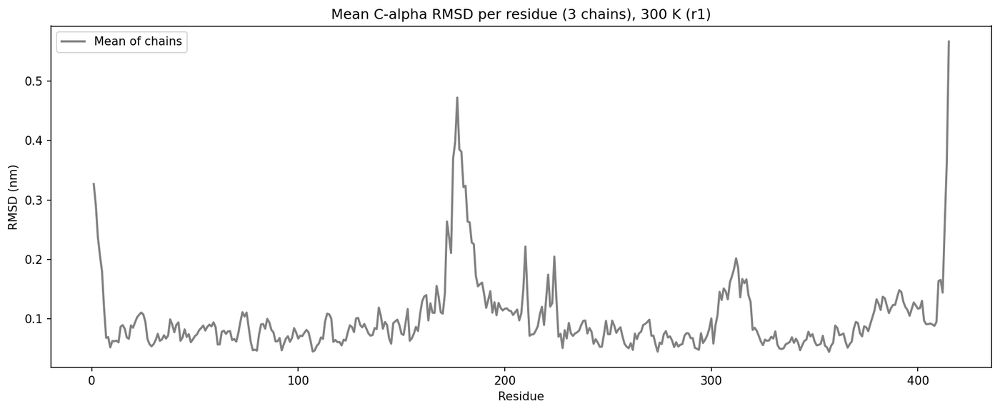

mean H-bonds/frame: 1020.9


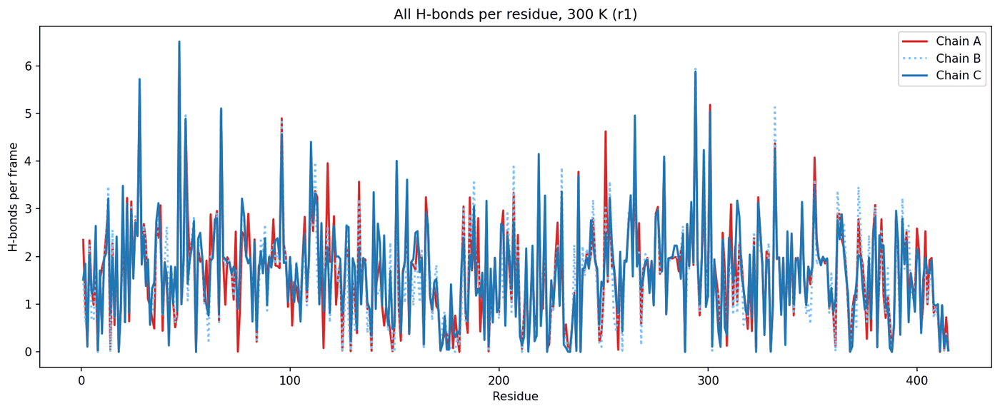

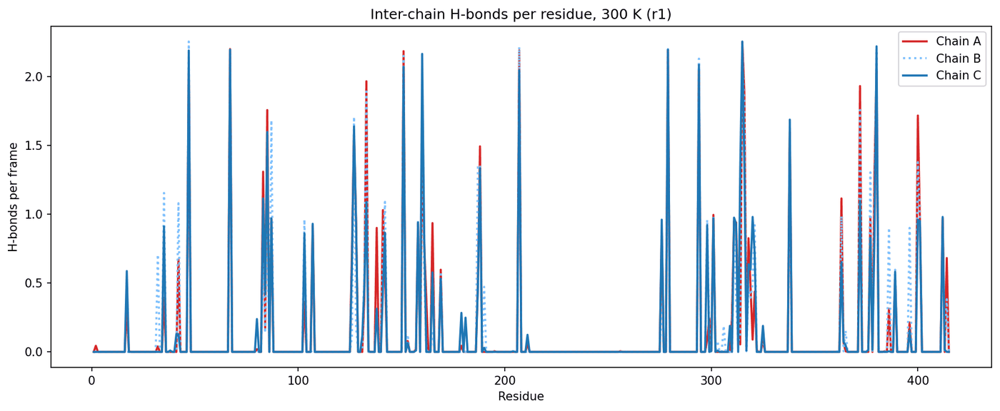

In [ ]:
from MDAnalysis.analysis.align import rotation_matrix
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
cs = {"chA":slice(0,6647), "chB":slice(6647,13294), "chC":slice(13294,19941)}
resR = {}
for name, s in cs.items():
    chn = u.atoms[s]; bb = chn.select_atoms("name N CA C"); ca = chn.select_atoms("name CA")
    u.trajectory[0]; c0 = bb.positions.mean(0); bb0 = bb.positions - c0; ca0 = ca.positions - c0
    d2 = np.zeros(len(ca)); n = 0
    for ts in u.trajectory:
        c = bb.positions.mean(0); R, _ = rotation_matrix(bb.positions - c, bb0)
        d2 += (((ca.positions - c) @ R.T - ca0)**2).sum(1); n += 1
    resR[name] = np.sqrt(d2/n)/10
    np.savetxt(f"{X}/rmsd_perres_{name}.xvg", np.c_[np.arange(1,416), resR[name]], fmt="%d %.6f")
draw("rmsd_per_residue", "C-alpha RMSD per residue vs first frame, 300 K (r1)", "Residue", "RMSD (nm)",
     [(np.arange(1,416), resR[c], s) for c, s in sty.items()])
m = np.mean(list(resR.values()), axis=0)
draw("rmsd_per_residue_mean", "Mean C-alpha RMSD per residue (3 chains), 300 K (r1)", "Residue", "RMSD (nm)",
     [(np.arange(1,416), m, dict(color="grey", label="Mean of chains"))])

nmA = np.array([n.strip() for n in u.atoms.names]); rn = u.atoms.resnames
resid = u.atoms.resids; chain = np.arange(len(nmA))//6647
isH = np.array([n.startswith("H") for n in nmA])
P0 = u.atoms.positions/10; heavy = np.where(~isH)[0]; Hs = np.where(isH)[0]
don = heavy[cKDTree(P0[heavy]).query(P0[Hs])[1]]
k = np.array([nmA[i][0] in "NO" for i in don]); Hs, don = Hs[k], don[k]
acc = np.array([i for i in range(len(nmA)) if nmA[i][0]=="O" or (nmA[i] in ("ND1","NE2") and rn[i].startswith("HI"))])
tot = np.zeros((3,416)); inter = np.zeros((3,416)); nb = []
for ts in u.trajectory:
    Pf = u.atoms.positions/10; n = 0
    for hi, lst in enumerate(cKDTree(Pf[Hs]).query_ball_tree(cKDTree(Pf[acc]), 0.25)):
        D = don[hi]
        for aj in lst:
            A = acc[aj]
            if A == D or (chain[A]==chain[D] and resid[A]==resid[D]): continue
            v1, v2 = Pf[Hs[hi]]-Pf[D], Pf[A]-Pf[D]; dist = np.linalg.norm(v2)
            if dist > 0.35 or v1@v2/(np.linalg.norm(v1)*dist) < np.cos(np.radians(30)): continue
            n += 1
            for Xa in (D, A):
                tot[chain[Xa], resid[Xa]] += 1
                if chain[D] != chain[A]: inter[chain[Xa], resid[Xa]] += 1
    nb.append(n)
nf = len(nb); print("mean H-bonds/frame:", round(float(np.mean(nb)),1))
for nmx, arr, ttl in (("hbperres",tot,"All H-bonds per residue"), ("hbperres_inter",inter,"Inter-chain H-bonds per residue")):
    for i, c in enumerate(sty): np.savetxt(f"{X}/{nmx}_{c}.xvg", np.c_[np.arange(1,416), arr[i,1:]/nf], fmt="%d %.5f")
    draw(nmx, f"{ttl}, 300 K (r1)", "Residue", "H-bonds per frame",
         [(np.arange(1,416), arr[i,1:]/nf, s) for i, s in enumerate(sty.values())])

In [ ]:
%%bash
cd "$OUT/frames"
for c in chA chB chC; do
  printf "$c\n" | gmx dssp -s protein.tpr -f fit_cluster_skip5.xtc -n chains.ndx -o "$OUT/xvgs/dssp_$c.dat" > "$OUT/logs/dssp_$c.log" 2>&1
  echo $c; head -c 80 "$OUT/xvgs/dssp_$c.dat"; echo; tail -3 "$OUT/logs/dssp_$c.log"
done

chA
~HHHHS~SSEE~GGGEEEEEEETTEEEEEEPPSGGG~GGGGGGTT~EEEEEEE~TTEEEEEEE~SEEEEEEEEESEEEEE

GROMACS reminds you: "Correctomundo" (Pulp Fiction)

chB
~HHHHS~SSEE~GGGEEEEEEETTEEEEEEPPSGGG~GGGGGGTT~EEEEEEE~TTEEEEEEE~SEEEEEEEEESEEEEE

GROMACS reminds you: "It is not clear that intelligence has any long-term survival value." (Stephen Hawking)

chC
~HHHHS~SSEE~GGGEEEEEEETTEEEEEEPPSGGG~GGGGGGTT~EEEEEEE~TTEEEEEEE~SEEEEEEEEESEEEEE

GROMACS reminds you: "set: No match." (tcsh)



shape: (201, 1247) | chain breaks at columns: [415 831]
helix chA mean %: 17.5
helix chB mean %: 16.3
helix chC mean %: 16.7


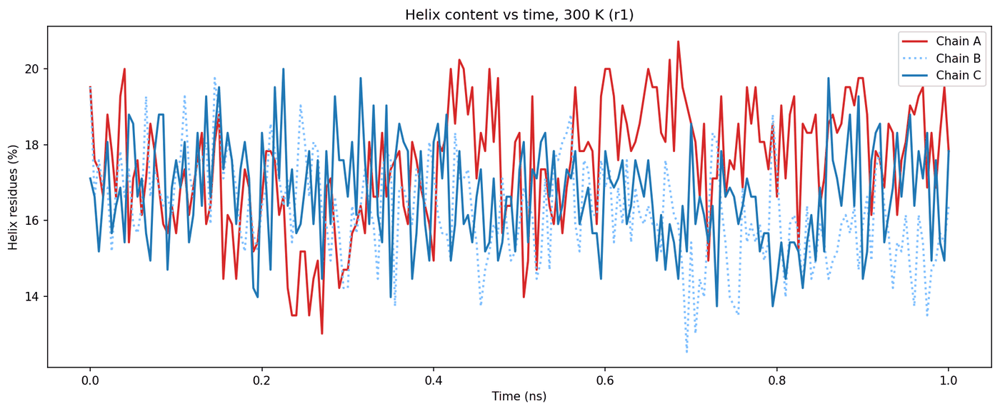

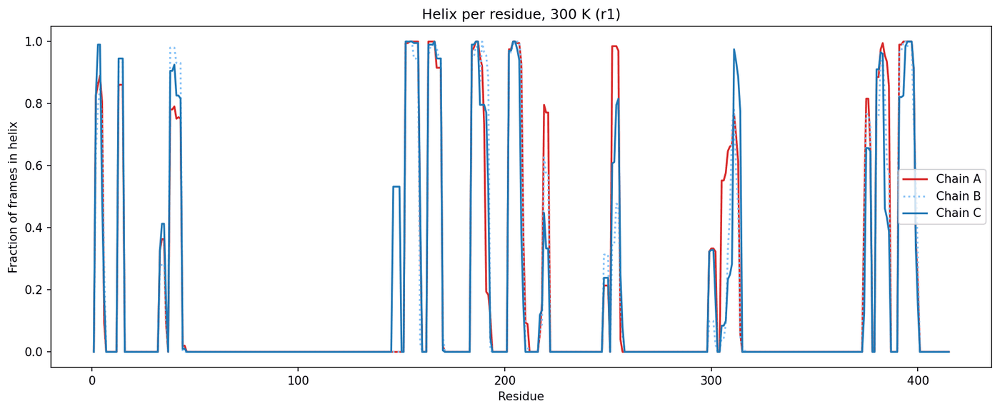

strand chA mean %: 37.6
strand chB mean %: 36.8
strand chC mean %: 38.4


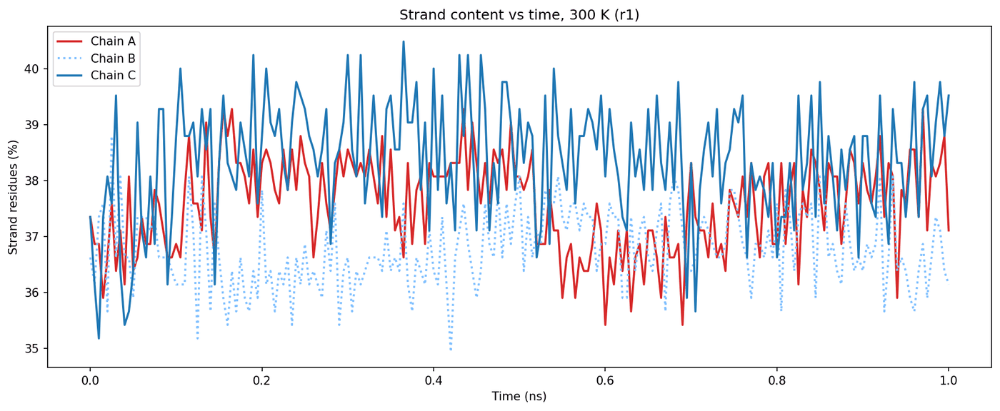

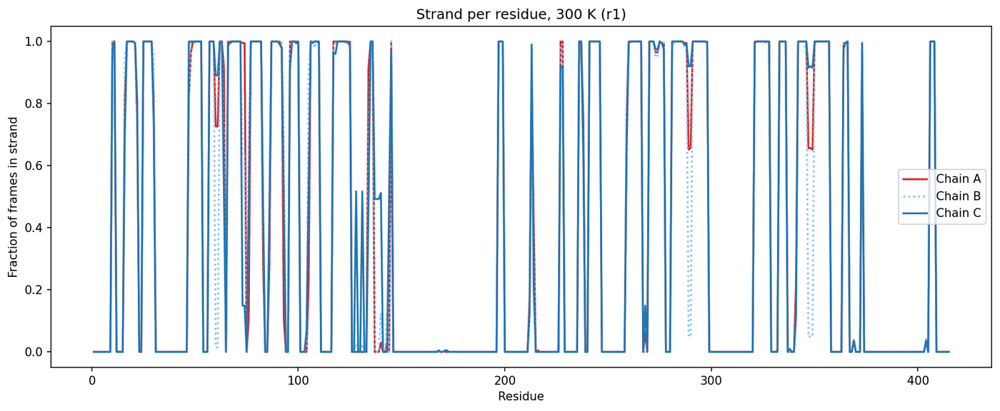

In [ ]:
import numpy as np, matplotlib.pyplot as plt, os
OUT = os.environ["OUT"]
a = np.array([list(l.rstrip("\n")) for l in open(f"{OUT}/xvgs/dssp_chA.dat") if l.strip()])
brk = np.where((a == "=").all(0))[0]
print("shape:", a.shape, "| chain breaks at columns:", brk)
a = a[:, ~(a == "=").all(0)]
assert a.shape[1] == 1245, a.shape
D = {c: a[:, i*415:(i+1)*415] for i, c in enumerate(("chA","chB","chC"))}

sty = {"chA": dict(color="#d62728", ls="-", label="Chain A"),
       "chB": dict(color="#7fbfff", ls=":", label="Chain B"),
       "chC": dict(color="#1f77b4", ls="-", label="Chain C")}
t = np.linspace(0, 1, len(a))
for name, ss, yl in (("helix","HGI","Helix residues (%)"), ("strand","EB","Strand residues (%)")):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        ax.plot(t, 100*np.isin(D[c], list(ss)).mean(1), lw=1.8, **s)
        print(name, c, "mean %:", round(100*np.isin(D[c], list(ss)).mean(), 1))
    ax.set(xlabel="Time (ns)", ylabel=yl, title=f"{name.capitalize()} content vs time, 300 K (r1)")
    ax.legend(); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_time.png"); plt.show()

    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        f = np.isin(D[c], list(ss)).mean(0); ax.plot(np.arange(1,416), f, lw=1.6, **s)
        np.savetxt(f"{OUT}/xvgs/dssp_{name}_perres_{c}.xvg", np.c_[np.arange(1,416), f], fmt="%d %.4f")
    ax.set(xlabel="Residue", ylabel=f"Fraction of frames in {name}", title=f"{name.capitalize()} per residue, 300 K (r1)")
    ax.legend(); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_perres.png"); plt.show()

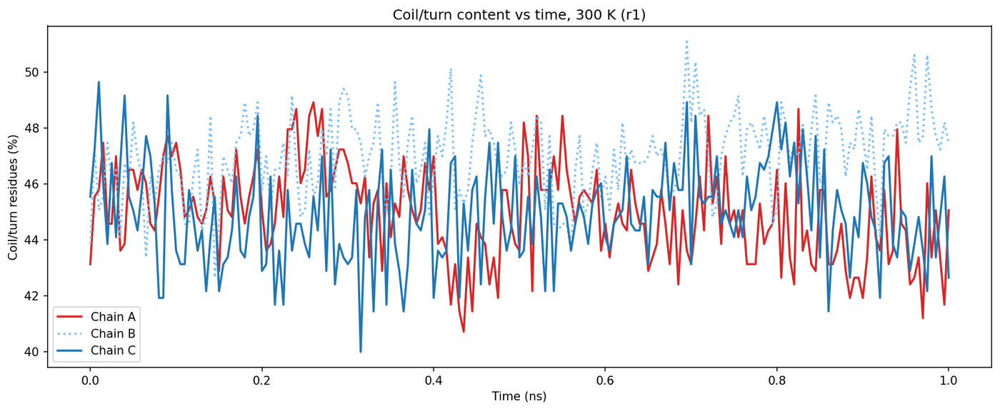

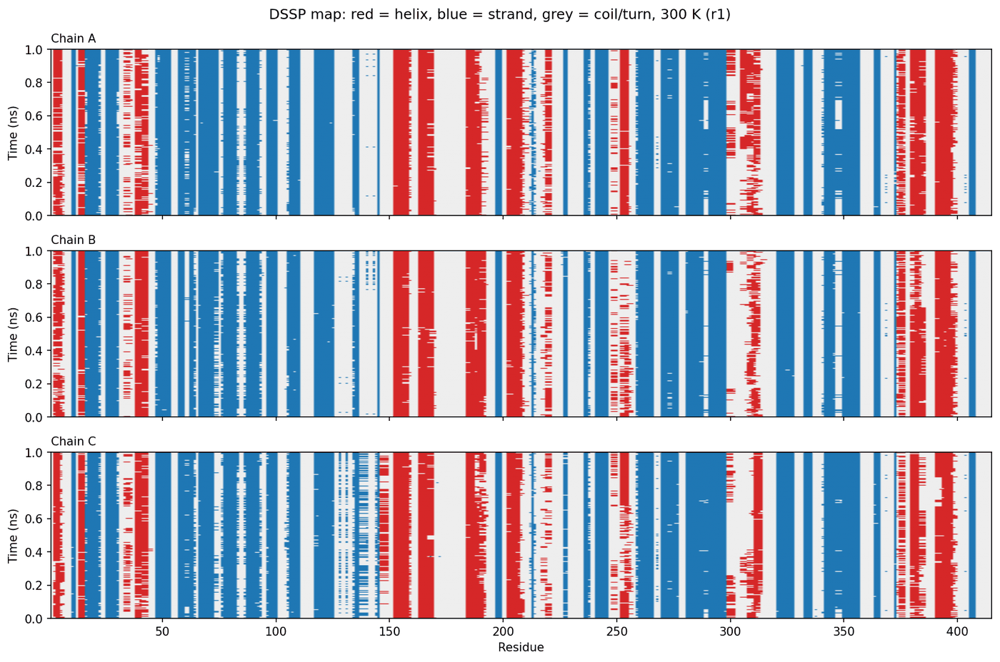

In [ ]:
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(12,5), dpi=150)
for c, s in sty.items():
    ax.plot(t, 100*(1-np.isin(D[c], list("HGIEB")).mean(1)), lw=1.8, **s)
ax.set(xlabel="Time (ns)", ylabel="Coil/turn residues (%)", title="Coil/turn content vs time, 300 K (r1)")
ax.legend(); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_coil_time.png"); plt.show()

cmap = ListedColormap(["#eeeeee", "#d62728", "#1f77b4"])
code = lambda m: np.where(np.isin(m, list("HGI")), 1, np.where(np.isin(m, list("EB")), 2, 0))
fig, axs = plt.subplots(3, 1, figsize=(12,8), dpi=150, sharex=True)
for ax, (c, s) in zip(axs, sty.items()):
    ax.imshow(code(D[c]), aspect="auto", cmap=cmap, vmin=0, vmax=2, origin="lower", extent=[1,415,0,1])
    ax.set_ylabel("Time (ns)"); ax.set_title(s["label"], loc="left", fontsize=10)
axs[-1].set_xlabel("Residue"); fig.suptitle("DSSP map: red = helix, blue = strand, grey = coil/turn, 300 K (r1)")
fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_map.png"); plt.show()

In [ ]:
import pandas as pd
def last(f, col=1): a = np.loadtxt(f, comments=('#','@')); return a[len(a)//2:, col].mean()
rows = []
for c in ("chA","chB","chC"):
    rows.append(dict(chain=c,
      RMSD_nm = last(f"{OUT}/xvgs/rmsd_{c}.xvg"), Rg_nm = last(f"{OUT}/xvgs/rg_{c}.xvg"),
      SASA_nm2 = last(f"{OUT}/xvgs/sasa_{c}.xvg", 2), intra_Hbonds = last(f"{OUT}/xvgs/hbnum_{c}.xvg"),
      helix_pct = 100*np.isin(D[c][len(t)//2:], list("HGI")).mean(), strand_pct = 100*np.isin(D[c][len(t)//2:], list("EB")).mean()))
rows.append(dict(chain="trimer", RMSD_nm=last(f"{OUT}/xvgs/rmsd_Protein.xvg"), Rg_nm=last(f"{OUT}/xvgs/rg_Protein.xvg"),
                 SASA_nm2=last(f"{OUT}/xvgs/sasa_Protein.xvg"), intra_Hbonds=last(f"{OUT}/xvgs/hbnum_Protein.xvg")))
df = pd.DataFrame(rows).round(3); df.to_csv(f"{OUT}/xvgs/summary_last0.5ns.csv", index=False); print(df)

    chain  RMSD_nm  Rg_nm  SASA_nm2  intra_Hbonds  helix_pct  strand_pct
0     chA    0.132  2.560   174.425       321.287     18.070      37.347
1     chB    0.110  2.555   174.327       311.257     15.849      36.956
2     chC    0.137  2.554   174.265       324.782     16.505      38.318
3  trimer    0.143  3.395   523.024      1051.376        NaN         NaN


(201, 1245)


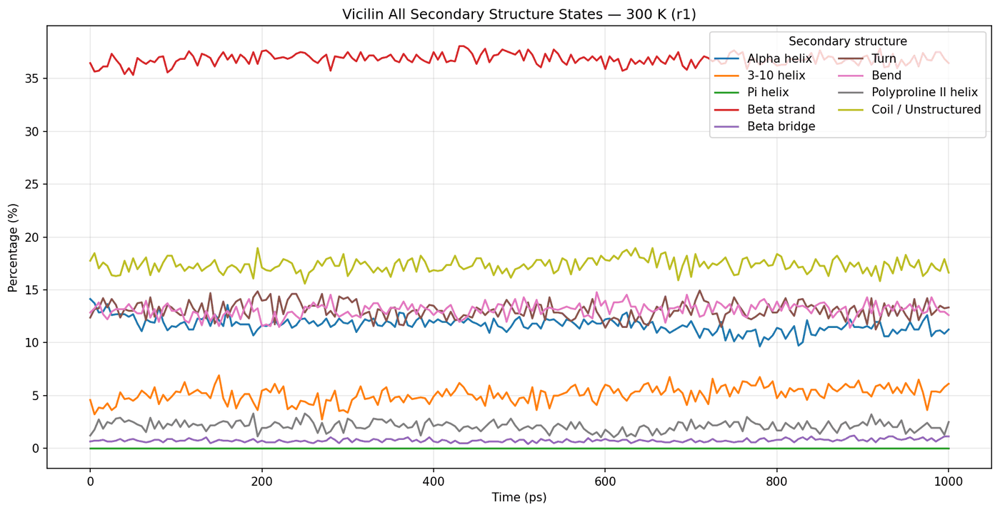

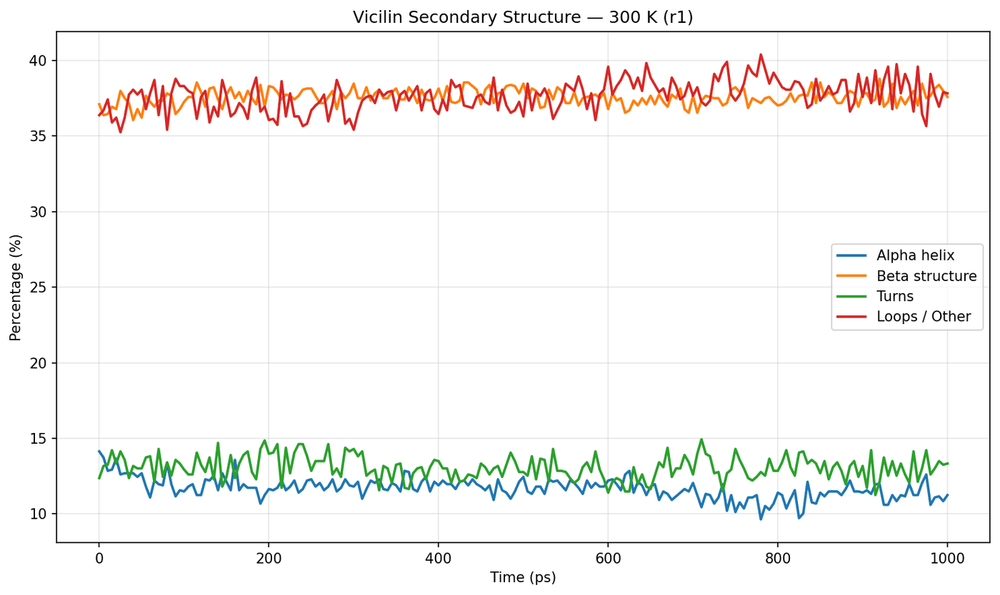

In [ ]:
import os, numpy as np, matplotlib.pyplot as plt
OUT = os.environ["OUT"]

def load_dssp(path):
    a = np.array([list(l.rstrip("\n")) for l in open(path) if l.strip()])
    return a[:, ~(a == "=").all(0)]

STATES = [("Alpha helix","H"),("3-10 helix","G"),("Pi helix","I"),("Beta strand","E"),("Beta bridge","B"),
          ("Turn","T"),("Bend","S"),("Polyproline II helix","P")]
def percent(a):
    P = {n: 100*(a == c).mean(1) for n, c in STATES}
    P["Coil / Unstructured"] = 100 - sum(P.values())
    return P

a = load_dssp(f"{OUT}/xvgs/dssp_chA.dat"); print(a.shape)   # expect (201, 1245)
P = percent(a); t = np.arange(len(a))*5.0

fig, ax = plt.subplots(figsize=(12,6.2), dpi=150)
for i, (n, y) in enumerate(P.items()): ax.plot(t, y, color=plt.cm.tab10(i), lw=1.6, label=n)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title="Vicilin All Secondary Structure States — 300 K (r1)")
ax.grid(alpha=.3); ax.legend(title="Secondary structure", ncol=2, loc="upper right"); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_all_states_300K_r1.png"); plt.show()

G = {"Alpha helix": P["Alpha helix"], "Beta structure": P["Beta strand"]+P["Beta bridge"], "Turns": P["Turn"]}
G["Loops / Other"] = 100 - sum(G.values())
fig, ax = plt.subplots(figsize=(10,6), dpi=150)
for i, (n, y) in enumerate(G.items()): ax.plot(t, y, color=plt.cm.tab10(i), lw=1.8, label=n)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title="Vicilin Secondary Structure — 300 K (r1)")
ax.grid(alpha=.3); ax.legend(); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_groups_300K_r1.png"); plt.show()

In [ ]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
BASE = "/content/drive/MyDrive/Plant Protein Extrusion MD/analysism"
RUNS = {"300 K r1":"vicilin_300_r1","300 K r2":"vicilin_300_r2",
        "373 K r1":"vicilin_373_r1","373 K shear":"vicilin_373_shear_r1"}
COL = {"300 K r1":"#1f77b4","300 K r2":"#7fbfff","373 K r1":"#d62728","373 K shear":"#2ca02c"}
LS  = {"300 K r1":"-","300 K r2":"--","373 K r1":"-","373 K shear":"--"}
CMP = f"{BASE}/comparison_all_runs"
for d in ("graphs","csv"): os.makedirs(f"{CMP}/{d}", exist_ok=True)
CH = ["chA","chB","chC"]; PAIRS = [("chA","chB"),("chB","chC"),("chA","chC")]
PN = [f"{a[-1]}-{b[-1]}" for a,b in PAIRS]
STAT = [("Alpha helix","H"),("3-10 helix","G"),("Pi helix","I"),("Beta strand","E"),
        ("Beta bridge","B"),("Turn","T"),("Bend","S"),("PPII helix","P")]
xvg = lambda f: np.loadtxt(f, comments=('#','@'))
ok = os.path.exists
def load_dssp(p):
    a = np.array([list(l.rstrip("\n")) for l in open(p) if l.strip()])
    return a[:, ~(a == "=").all(0)]

# ---------------- load everything ----------------
rows, resrows, comp = [], [], {}
def add(run, m, e, t, y): rows.extend((run, m, e, float(a), float(b)) for a, b in zip(t, y))
spec = {"RMSD (nm)":("rmsd",1,1.0), "Rg (nm)":("rg",1,1000.0),
        "SASA (nm2)":("sasa",2,1.0), "H-bonds (trimer)":("hbnum",1,1.0)}
RESPAT = {"RMSF (nm)":"rmsf_{c}", "RMSD per residue (nm)":"rmsd_perres_{c}",
          "H-bonds per residue":"hbperres_{c}", "Inter-chain H-bonds per residue":"hbperres_inter_{c}",
          "Helix fraction":"dssp_helix_perres_{c}", "Strand fraction":"dssp_strand_perres_{c}"}
for run, fd in RUNS.items():
    X = f"{BASE}/{fd}/xvgs"
    if not os.path.isdir(X): print("MISSING run folder:", run); continue
    for m, (pre, col, sc) in spec.items():
        for e in CH + ["Protein"]:
            f = f"{X}/{pre}_{e}.xvg"
            if ok(f): a = xvg(f); add(run, m, e, a[:,0]/sc, a[:,col])
            else: print("missing", run, f"{pre}_{e}.xvg")
    for (a_, b_), n in zip(PAIRS, PN):
        f = f"{X}/hbinter_{a_}_{b_}.xvg"
        if ok(f): a = xvg(f); add(run, "Inter H-bonds", n, a[:,0], a[:,1])
    f = f"{X}/dssp_chA.dat"
    if ok(f):
        a = load_dssp(f); n = len(a); t = np.linspace(0, 1, n)   # assumes frames span 1 ns
        ents = {"Protein": a, **{c: a[:, i*415:(i+1)*415] for i, c in enumerate(CH)}}
        for e, mm in ents.items():
            hel = 100*np.isin(mm, list("HGI")).mean(1); stn = 100*np.isin(mm, list("EB")).mean(1)
            add(run, "Helix (%)", e, t, hel); add(run, "Strand (%)", e, t, stn)
            add(run, "Coil/turn (%)", e, t, 100-hel-stn)
        comp[run] = {nm: 100*(a[n//2:] == ch).mean() for nm, ch in STAT}
        comp[run]["Coil/other"] = 100 - sum(comp[run].values())
    for c in CH:
        for m, pat in RESPAT.items():
            f = f"{X}/{pat.format(c=c)}.xvg"
            if ok(f):
                v = xvg(f)[:,1]
                if len(v) == 415: resrows.extend((run, m, c, i+1, float(x)) for i, x in enumerate(v))
    f = f"{X}/sasa_perres_Protein.xvg"
    if ok(f):
        d = xvg(f)
        if len(d) == 1245:
            for i, c in enumerate(CH):
                resrows.extend((run, "SASA per residue (nm2)", c, j+1, float(x)) for j, x in enumerate(d[i*415:(i+1)*415, 1]))

ts  = pd.DataFrame(rows, columns=["run","metric","entity","time_ns","value"])
res = pd.DataFrame(resrows, columns=["run","metric","chain","residue","value"])
ts.to_csv(f"{CMP}/csv/timeseries_long.csv", index=False)
res.to_csv(f"{CMP}/csv/residue_metrics_long.csv", index=False)
pd.DataFrame(comp).T.round(2).to_csv(f"{CMP}/csv/dssp_composition_last_half.csv")

# ---------------- summaries ----------------
def stats(t, y):
    h = t >= t.max()/2
    return dict(mean_full=y.mean(), sd_full=y.std(ddof=1), mean_last_half=y[h].mean(), sd_last_half=y[h].std(ddof=1))
pc = [dict(run=r, metric=m, entity=e, **stats(d.sort_values("time_ns").time_ns.values, d.sort_values("time_ns").value.values))
      for (r, m, e), d in ts.groupby(["run","metric","entity"])]
pd.DataFrame(pc).round(4).to_csv(f"{CMP}/csv/summary_per_chain_and_interface.csv", index=False)

MET = [("RMSD (nm)",["Protein"],"mean","Backbone RMSD, whole trimer (nm)"),
       ("Rg (nm)",["Protein"],"mean","Radius of gyration, whole trimer (nm)"),
       ("SASA (nm2)",["Protein"],"mean","SASA, whole trimer (nm²)"),
       ("H-bonds (trimer)",["Protein"],"mean","H-bonds within trimer"),
       ("Inter H-bonds",PN,"sum","Inter-chain H-bonds (sum of A-B, B-C, A-C)"),
       ("Helix (%)",["Protein"],"mean","Helix (%)"),
       ("Strand (%)",["Protein"],"mean","Strand (%)"),
       ("Coil/turn (%)",["Protein"],"mean","Coil/turn (%)")]
def curve(run, m, ents, agg):
    d = ts[(ts.run==run) & (ts.metric==m) & (ts.entity.isin(ents))]
    if d.empty: return None
    pr = [e for e in ents if (d.entity==e).any()]
    t0 = d[d.entity==pr[0]].sort_values("time_ns").time_ns.values
    Y = np.array([np.interp(t0, *[d[d.entity==e].sort_values("time_ns")[k].values for k in ("time_ns","value")]) for e in pr])
    return t0, (Y.sum(0) if agg=="sum" else Y.mean(0))
agg_rows = []
for run in RUNS:
    for m, ents, agg, yl in MET:
        c = curve(run, m, ents, agg)
        if c: agg_rows.append(dict(run=run, metric=m, **stats(*c)))
S = pd.DataFrame(agg_rows); S.round(4).to_csv(f"{CMP}/csv/summary_all_runs.csv", index=False)
table = S.pivot(index="run", columns="metric", values="mean_last_half").reindex(list(RUNS))
table = table[[m[0] for m in MET if m[0] in table.columns]]
base = table.loc[["300 K r1","300 K r2"]].mean()
th = table.loc["373 K r1"] - base; sh = table.loc["373 K shear"] - table.loc["373 K r1"]
rep = (table.loc["300 K r1"] - table.loc["300 K r2"]).abs()
D = pd.DataFrame({"mean_300K_r1_r2":base, "val_373K_r1":table.loc["373 K r1"], "val_373K_shear":table.loc["373 K shear"],
                  "thermal_delta(373r1-300)":th, "thermal_pct":100*th/base,
                  "shear_delta(shear-373r1)":sh, "shear_pct":100*sh/table.loc["373 K r1"],
                  "replicate_gap(300r1-r2)":rep})
D["thermal_exceeds_replicate_gap"] = th.abs() > rep
D["shear_exceeds_replicate_gap"] = sh.abs() > rep
D.round(4).to_csv(f"{CMP}/csv/condition_deltas.csv")

# ---------------- graphs: time series ----------------
def ts_ax(ax, m, ents, agg, yl):
    for run in RUNS:
        c = curve(run, m, ents, agg)
        if c: ax.plot(c[0], c[1], color=COL[run], ls=LS[run], lw=1.7, label=run)
    ax.set(xlabel="Time (ns)", ylabel=yl, title=yl); ax.grid(alpha=.3); ax.legend(fontsize=8)
fig, axs = plt.subplots(4, 2, figsize=(14, 17))
for ax, (m, ents, agg, yl) in zip(axs.ravel(), MET): ts_ax(ax, m, ents, agg, yl)
fig.suptitle("Vicilin trimer: all runs", y=1.0); fig.tight_layout()
fig.savefig(f"{CMP}/graphs/00_overview_timeseries.png", dpi=150); plt.show()
for i, (m, ents, agg, yl) in enumerate(MET, 1):
    f2, a2 = plt.subplots(figsize=(10, 5), dpi=150); ts_ax(a2, m, ents, agg, yl); f2.tight_layout()
    f2.savefig(f"{CMP}/graphs/ts_{m.split(' (')[0].replace(' ','_').replace('/','_')}.png"); plt.close(f2)

# ---------------- graphs: bars ----------------
fig, axs = plt.subplots(2, 4, figsize=(16, 7))
for ax, (m, ents, agg, yl) in zip(axs.ravel(), MET):
    d = S[S.metric==m].set_index("run").reindex(list(RUNS)).dropna()
    ax.bar(d.index, d.mean_last_half, yerr=d.sd_last_half, color=[COL[r] for r in d.index], capsize=4)
    ax.set_title(m, fontsize=10); ax.tick_params(axis="x", rotation=30); ax.grid(axis="y", alpha=.3)
fig.suptitle("Last-half mean ± SD (whole trimer)"); fig.tight_layout()
fig.savefig(f"{CMP}/graphs/01_bar_summary.png", dpi=150); plt.show()

P = pd.DataFrame(pc)
fig, axs = plt.subplots(2, 3, figsize=(16, 8)); w = 0.2
for ax, m in zip(axs.ravel(), ["RMSD (nm)","Rg (nm)","SASA (nm2)","H-bonds (trimer)","Helix (%)","Strand (%)"]):
    for k, run in enumerate(RUNS):
        d = P[(P.run==run)&(P.metric==m)&(P.entity.isin(CH))].set_index("entity").reindex(CH)
        ax.bar(np.arange(3)+k*w, d.mean_last_half, w, yerr=d.sd_last_half, color=COL[run], label=run, capsize=2)
    ax.set_xticks(np.arange(3)+1.5*w); ax.set_xticklabels(["Chain A","Chain B","Chain C"]); ax.set_title(m); ax.grid(axis="y", alpha=.3)
axs[0,0].legend(fontsize=8); fig.suptitle("Per-chain last-half mean ± SD"); fig.tight_layout()
fig.savefig(f"{CMP}/graphs/02_per_chain_bars.png", dpi=150); plt.show()

# heatmap of % change vs 300 K baseline
pct = 100*(table - base)/base
fig, ax = plt.subplots(figsize=(11, 3.8)); v = np.nanpercentile(np.abs(pct.values), 95)
im = ax.imshow(pct.values, cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto")
ax.set_xticks(range(pct.shape[1])); ax.set_xticklabels(pct.columns, rotation=30, ha="right")
ax.set_yticks(range(pct.shape[0])); ax.set_yticklabels(pct.index)
for i in range(pct.shape[0]):
    for j in range(pct.shape[1]): ax.text(j, i, f"{pct.values[i,j]:.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, label="% change vs mean of 300 K r1/r2"); ax.set_title("Change relative to 300 K baseline (%)")
fig.tight_layout(); fig.savefig(f"{CMP}/graphs/03_pct_change_heatmap.png", dpi=150); plt.show()

# DSSP composition
if comp:
    C = pd.DataFrame(comp).T.reindex([r for r in RUNS if r in comp])
    ax = C.plot(kind="bar", stacked=True, figsize=(10, 5), colormap="tab20"); ax.set_ylabel("% of residues (last half)")
    ax.set_title("DSSP composition, whole trimer"); ax.legend(ncol=2, fontsize=8, bbox_to_anchor=(1.01, 1))
    plt.xticks(rotation=20); plt.tight_layout(); plt.savefig(f"{CMP}/graphs/04_dssp_composition.png", dpi=150); plt.show()

# ---------------- graphs: per residue ----------------
rm = res.groupby(["run","metric","residue"]).value.mean()
def rcurve(run, m):
    try: s = rm.loc[(run, m)]; return s.index.values, s.values
    except KeyError: return None
RM = list(RESPAT) + ["SASA per residue (nm2)"]
fig, axs = plt.subplots(4, 2, figsize=(15, 17))
for ax, m in zip(axs.ravel(), RM):
    for run in RUNS:
        c = rcurve(run, m)
        if c: ax.plot(*c, color=COL[run], ls=LS[run], lw=1.3, label=run)
    ax.set(xlabel="Residue", ylabel=m, title=m + " (mean of 3 chains)"); ax.grid(alpha=.3); ax.legend(fontsize=8)
axs.ravel()[-1].axis("off"); fig.tight_layout()
fig.savefig(f"{CMP}/graphs/05_residue_overlays.png", dpi=150); plt.show()

DM = ["RMSF (nm)","SASA per residue (nm2)","Helix fraction","Strand fraction","H-bonds per residue"]
fig, axs = plt.subplots(len(DM), 2, figsize=(15, 3.2*len(DM))); top = []
for i, m in enumerate(DM):
    a300 = [rcurve(r, m) for r in ("300 K r1","300 K r2")]; a300 = [c[1] for c in a300 if c]
    r373, rsh = rcurve("373 K r1", m), rcurve("373 K shear", m)
    if not (a300 and r373 and rsh): continue
    resid = r373[0]; b = np.mean(a300, axis=0)
    for j, (name, dl) in enumerate((("Thermal: 373 K r1 − 300 K mean", r373[1]-b), ("Shear: 373 K shear − 373 K r1", rsh[1]-r373[1]))):
        ax = axs[i, j]; ax.fill_between(resid, dl, 0, where=dl>=0, color="#d62728", alpha=.6)
        ax.fill_between(resid, dl, 0, where=dl<0, color="#1f77b4", alpha=.6)
        ax.axhline(0, color="k", lw=.6); ax.set(xlabel="Residue", ylabel=f"Δ {m}", title=f"{name}"); ax.grid(alpha=.3)
        for k in np.argsort(-np.abs(dl))[:10]: top.append(dict(contrast=name, metric=m, residue=int(resid[k]), delta=float(dl[k])))
fig.tight_layout(); fig.savefig(f"{CMP}/graphs/06_residue_deltas.png", dpi=150); plt.show()
pd.DataFrame(top).round(4).to_csv(f"{CMP}/csv/top10_residue_changes.csv", index=False)

# ---------------- report ----------------
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("\nLast-half means, whole trimer:\n", table.round(3))
print("\nDeltas vs replicate gap:\n", D.round(3))
print("\nSaved to:", CMP); os.system(f'ls -R "{CMP}" | head -60')

In [ ]:
import numpy as np
from MDAnalysis.coordinates.XTC import XTCReader
r = XTCReader("/content/shear/md_373_shear_r1.xtc")
d = np.array([ts.dimensions.copy() for ts in r])
print("frames:", len(d))
print("a,b,c start:", d[0,:3].round(2), "end:", d[-1,:3].round(2))
print("alpha,beta,gamma start:", d[0,3:].round(2), "end:", d[-1,3:].round(2))
print("max angle change (deg):", np.abs(d[:,3:] - d[0,3:]).max(axis=0).round(2))

frames: 1001
a,b,c start: [135.47 135.47 135.47] end: [135.47 139.64 135.47]
alpha,beta,gamma start: [60. 60. 90.] end: [52.67 60.   75.96]
max angle change (deg): [ 7.33  0.   14.04]


/usr/local/lib/python3.13/site-packages/MDAnalysis/coordinates/XDR.py:261: UserWarning: Reload offsets from trajectory
 ctime or size or n_atoms did not match
  warnings.warn(


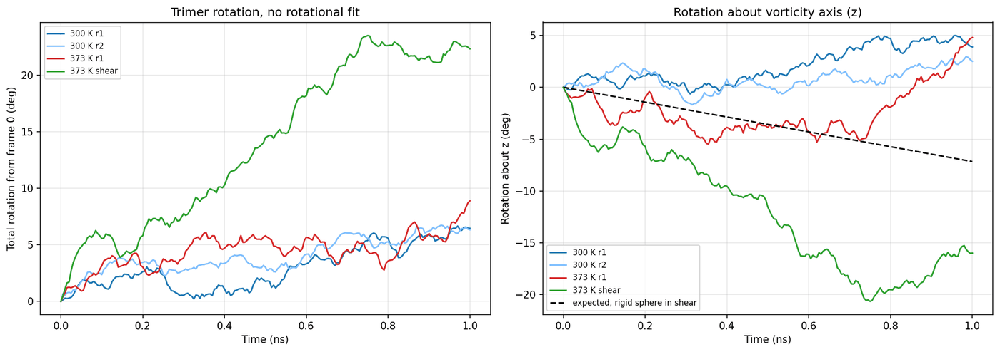

             run  angle_deg  rot_x  rot_y  rot_z
200  373 K shear       22.3    2.2  -15.4  -16.0
401     373 K r1        8.9   -1.1   -7.4    4.8
602     300 K r1        6.5   -1.4   -5.0    3.9
803     300 K r2        6.3    3.5    4.7    2.5


In [ ]:
import os, glob, numpy as np, pandas as pd, MDAnalysis as mda, matplotlib.pyplot as plt
from MDAnalysis.lib.distances import minimize_vectors
from MDAnalysis.analysis.align import rotation_matrix
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
BASE = "/content/drive/MyDrive/Plant Protein Extrusion MD"
os.system(f'ln -sfn "{BASE}" /content/pm')
sr = [d for d in glob.glob("/content/pm/Shear Run*") if os.path.isdir(d)][0]
os.system(f'ln -sfn "{sr}" /content/shear')
RUNS = {"373 K shear":("/content/shear","md_373_shear_r1","vicilin_373_shear_r1"),
        "373 K r1":("/content/pm","md_373_r1","vicilin_373_r1"),
        "300 K r1":("/content/pm","md_300_r1","vicilin_300_r1"),
        "300 K r2":("/content/pm","md_300_r2","vicilin_300_r2")}
sl = [slice(0,6647), slice(6647,13294), slice(13294,19941)]
rows = []
for run, (P, S, name) in RUNS.items():
    F = f"{BASE}/analysism/{name}/frames"
    os.system(f'printf "Protein\\n" | gmx trjconv -s "{F}/protein.tpr" -f "{P}/{S}.xtc" -o /tmp/w.xtc -pbc whole > /tmp/w.log 2>&1')
    u = mda.Universe(f"{F}/first_cl.gro", "/tmp/w.xtc"); ca = u.select_atoms("name CA").indices
    ref = None
    for ts in u.trajectory[::5]:
        pos = u.atoms.positions.copy(); box = ts.dimensions.astype(np.float32)
        a0 = pos[sl[0]].mean(0)
        for s in sl[1:]:
            d = pos[s].mean(0) - a0
            dm = minimize_vectors(d[None,:].astype(np.float32), box)[0]
            pos[s] -= (d - dm)
        x = pos[ca]; x = x - x.mean(0)
        if ref is None: ref = x.copy()
        R, _ = rotation_matrix(x, ref); Rt = R.T          # reference -> this frame
        th = np.arccos(np.clip((np.trace(Rt)-1)/2, -1, 1))
        ax = np.array([Rt[2,1]-Rt[1,2], Rt[0,2]-Rt[2,0], Rt[1,0]-Rt[0,1]])
        n = np.linalg.norm(ax); ax = ax/n if n > 1e-12 else np.zeros(3)
        rv = np.degrees(th)*ax
        rows.append(dict(run=run, time_ns=ts.time/1000, angle_deg=np.degrees(th), rot_x=rv[0], rot_y=rv[1], rot_z=rv[2]))
    os.remove("/tmp/w.xtc")
df = pd.DataFrame(rows)
CMP = f"{BASE}/analysism/comparison_all_runs"
for d in ("csv","graphs"): os.makedirs(f"{CMP}/{d}", exist_ok=True)
df.round(3).to_csv(f"{CMP}/csv/rotation_no_fit.csv", index=False)

COL = {"300 K r1":"#1f77b4","300 K r2":"#7fbfff","373 K r1":"#d62728","373 K shear":"#2ca02c"}
fig, axs = plt.subplots(1, 2, figsize=(14,5), dpi=150)
for run, d in df.groupby("run"):
    axs[0].plot(d.time_ns, d.angle_deg, color=COL[run], label=run)
    axs[1].plot(d.time_ns, d.rot_z, color=COL[run], label=run)
tt = np.linspace(0, 1, 50); axs[1].plot(tt, -7.16*tt, "k--", label="expected, rigid sphere in shear")
axs[0].set(xlabel="Time (ns)", ylabel="Total rotation from frame 0 (deg)", title="Trimer rotation, no rotational fit")
axs[1].set(xlabel="Time (ns)", ylabel="Rotation about z (deg)", title="Rotation about vorticity axis (z)")
for a in axs: a.grid(alpha=.3); a.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{CMP}/graphs/07_rotation_no_fit.png"); plt.show()
print(df.groupby("run").tail(1)[["run","angle_deg","rot_x","rot_y","rot_z"]].round(1))

In [ ]:
import os, subprocess
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD" || exit 1
echo "== molecules in topol.top"; sed -n '/\[ molecules \]/,$p' topol.top
echo; echo "== atoms in em.gro"; sed -n '2p' em.gro
echo; echo "== 373 K files"; ls -1 *373* | head -40
echo; echo "== any r2 files (expect none)"; ls -1 *_r2* 2>&1 | head
echo; echo "== NVT r1 mdp"; cat nvt_373_r1.mdp
echo; echo "== NVT / NPT r1 launch lines"; grep -A1 -m1 "Command line" nvt_373_r1.log; grep -A1 -m1 "Command line" npt_373_r1*.log | head -6
echo; echo "== free space"; df -h /content/drive | tail -1'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

== molecules in topol.top
[ molecules ]
; Compound        #mols
Protein_chain_A     1
Protein_chain_B     1
Protein_chain_C     1
SOL         50655
NA          179
CL          158

== atoms in em.gro
172243

== 373 K files
md_373_r1.cpt
md_373_r1.edr
md_373_r1.gro
md_373_r1.log
md_373_r1.mdp
md_373_r1_prev.cpt
md_373_r1.tpr
md_373_r1.xtc
md_373_shear_r1.cpt
md_373_shear_r1.edr
md_373_shear_r1.gro
md_373_shear_r1.log
md_373_shear_r1.mdp
md_373_shear_r1_prev.cpt
md_373_shear_r1.tpr
md_373_shear_r1.xtc
npt_373_r1.cpt
npt_373_r1.edr
npt_373_r1.gro
npt_373_r1.log
npt_373_r1.mdp
npt_373_r1_prev.cpt
npt_373_r1.tpr
npt_373_r1.xtc
nvt_373_r1.cpt
nvt_373_r1.edr
nvt_373_r1.gro
nvt_373_r1.log
nvt_373_r1.mdp
nvt_373_r1.tpr
nvt_373_r1.xtc

Shear 373 old files :
md_373_shear_r1.cpt
md_373_shear_r1.log
md_373_shear_r1.mdp
md_373_shear_r1_prev.cpt
md_373_shear_r1.tpr

== any r2 files (expect none)
md_300_r2.cpt
md_300_r2.edr
md_300_r2.gro
md_300_r2.log
md_300_r2.mdp
md_300_r2_prev.cpt
md_300_r2.tpr
md_

In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD" || exit 1
if ls nvt_373_r2.* >/dev/null 2>&1; then echo "STOP: nvt_373_r2 files already exist:"; ls nvt_373_r2.*; exit 0; fi
sed 's/^gen-seed = 111/gen-seed = 222/' nvt_373_r1.mdp > nvt_373_r2.mdp
echo "== mdp diff r1 vs r2 (expect gen-seed only)"; diff nvt_373_r1.mdp nvt_373_r2.mdp
echo; echo "== grompp"
gmx grompp -f nvt_373_r2.mdp -c em.gro -r em.gro -p topol.top -o nvt_373_r2.tpr -maxwarn 0 > /tmp/g.txt 2>&1
grep -iE "warning|error|fatal|note" /tmp/g.txt | head -10; tail -3 /tmp/g.txt
ls -lh nvt_373_r1.tpr nvt_373_r2.tpr
echo; echo "== r1 vs r2 tpr"
gmx check -s1 nvt_373_r1.tpr -s2 nvt_373_r2.tpr > /tmp/chk.txt 2>&1
echo "x lines differing: $(grep -cE '^x\[' /tmp/chk.txt)"
echo "v lines differing: $(grep -cE '^v\[' /tmp/chk.txt)"
echo; echo "== other differences (expect only ld_seed)"
grep -vE "^v\[|^x\[|t_resinfo|^ *$|^comparing|Reading|GROMACS|Executable|Data prefix|Working dir|Command line|gmx check|Note:|^ *[0-9.e+-]+ +[0-9.e+-]+ +[0-9.e+-]+\)" /tmp/chk.txt
echo; echo "== r2 NVT files (expect mdp and tpr only)"; ls nvt_373_r2.*'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

== mdp diff r1 vs r2 (expect gen-seed only)
20c20
< gen-seed = 111
---
> gen-seed = 222

== grompp
NOTE 1 [file nvt_373_r2.mdp]:
There was 1 NOTE
Note that mdrun will redetermine rlist based on the actual pair-list setup
Estimate for the relative computational load of the PME mesh part: 0.30

This run will generate roughly 23 Mb of data
-rw------- 1 root root 9.7M Oct 11 15:05 nvt_373_r1.tpr
-rw------- 1 root root 9.7M Oct 18 08:43 nvt_373_r2.tpr

== r1 vs r2 tpr
x lines differing: 0
v lines differing: 172243

== other differences (expect only ld_seed)
inputrec->ld_seed (-1073425 - 1689926835)
-02)

== r2 NVT files (expect mdp and tpr only)
nvt_373_r2.mdp
nvt_373_r2.tpr
 


In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
r = subprocess.run(["bash","-c",'cd "/content/drive/MyDrive/Plant Protein Extrusion MD" && gmx mdrun -deffnm nvt_373_r2 -cpt 5 -ntmpi 1 -ntomp 2 -pin off 2>&1 | tail -5'], capture_output=True, text=True); print(r.stdout)

                 (ns/day)    (hour/ns)    (ms/step)  (Matom*steps/s) 
Performance:       34.517        0.695        5.006           34.405 

GROMACS reminds you: "It's easy to remember: a half a kT is equal to five fourths of a kJ/mol." (Anders Gabrielsson)




In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD" || exit 1
echo "== NVT r2 files"; ls -lh nvt_373_r2.*
echo; echo "== finished normally? (expect 1)"; grep -c "Finished mdrun" nvt_373_r2.log
echo; echo "== NVT r2 temperature"
printf "Temperature\n0\n" | gmx energy -f nvt_373_r2.edr -o /tmp/t_r2.xvg 2>&1 | grep -E "^Temperature|Statistics"
echo; echo "== NVT r1 temperature (comparison)"
printf "Temperature\n0\n" | gmx energy -f nvt_373_r1.edr -o /tmp/t_r1.xvg 2>&1 | grep -E "^Temperature"
echo; echo "== NPT r1 mdp"; cat npt_373_r1.mdp
echo; echo "== any r2 NPT files (expect none)"; ls npt_373_r2* 2>&1'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

== NVT r2 files
-rw------- 1 root root 4.0M Oct 18 08:50 nvt_373_r2.cpt
-rw------- 1 root root  58K Oct 18 08:50 nvt_373_r2.edr
-rw------- 1 root root  12M Oct 18 08:50 nvt_373_r2.gro
-rw------- 1 root root  93K Oct 18 08:50 nvt_373_r2.log
-rw------- 1 root root  408 Oct 18 08:43 nvt_373_r2.mdp
-rw------- 1 root root 9.7M Oct 18 08:43 nvt_373_r2.tpr
-rw------- 1 root root 6.8M Oct 18 08:50 nvt_373_r2.xtc

== finished normally? (expect 1)
1

== NVT r2 temperature
Statistics over 50001 steps [ 0.0000 through 100.0000 ps ], 1 data sets
Temperature                 372.699       0.31    4.09238    1.50829  (K)

== NVT r1 temperature (comparison)
Temperature                 372.689       0.29    4.04959     1.7133  (K)

== NPT r1 mdp
define = -DPOSRES
integrator = md
dt = 0.002
constraints = h-bonds
constraint-algorithm = lincs
cutoff-scheme = Verlet
coulombtype = PME
rcoulomb = 1.0
rvdw = 1.0
DispCorr = EnerPres
tcoupl = V-rescale
tc-grps = Protein Non-Protein
tau-t = 0.1 0.1
ref-t = 373 37

In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD" || exit 1
if ls npt_373_r2.* >/dev/null 2>&1; then echo "STOP: npt_373_r2 files already exist:"; ls npt_373_r2.*; exit 0; fi
cp npt_373_r1.mdp npt_373_r2.mdp
echo "== mdp diff r1 vs r2 (expect none)"; diff npt_373_r1.mdp npt_373_r2.mdp && echo IDENTICAL
echo; echo "== grompp"
gmx grompp -f npt_373_r2.mdp -c nvt_373_r2.gro -r nvt_373_r2.gro -t nvt_373_r2.cpt -p topol.top -o npt_373_r2.tpr -maxwarn 0 > /tmp/g.txt 2>&1
grep -iE "warning|error|fatal|note" /tmp/g.txt | head -10; tail -3 /tmp/g.txt
ls -lh npt_373_r1.tpr npt_373_r2.tpr
echo; echo "== inputrec/topology differences vs r1 (x, v, resinfo hidden)"
gmx check -s1 npt_373_r1.tpr -s2 npt_373_r2.tpr 2>&1 | grep -vE "^v\[|^x\[|t_resinfo|^ *$|^comparing|Reading|GROMACS|Executable|Data prefix|Working dir|Command line|gmx check|Note:|^ *[0-9.e+-]+ +[0-9.e+-]+ +[0-9.e+-]+\)"
echo; echo "== r2 NPT files (expect mdp and tpr only)"; ls npt_373_r2.*'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

== mdp diff r1 vs r2 (expect none)
IDENTICAL

== grompp
NOTE 1 [file npt_373_r2.mdp]:
There was 1 NOTE
Note that mdrun will redetermine rlist based on the actual pair-list setup
Estimate for the relative computational load of the PME mesh part: 0.30

This run will generate roughly 57 Mb of data
-rw------- 1 root root 9.7M Oct 11 15:10 npt_373_r1.tpr
-rw------- 1 root root 9.7M Oct 18 08:53 npt_373_r2.tpr

== inputrec/topology differences vs r1 (x, v, resinfo hidden)
inputrec->posresCom[    0] ( 4.99680e-01  1.66811e-01  5.00066e-01) - ( 4.99666e-01  1.66925e-01  4.99935e-01)
inputrec->posresComB[    0] ( 4.99680e-01  1.66811e-01  5.00066e-01) - ( 4.99666e-01  1.66925e-01  4.99935e-01)
inputrec->ld_seed (-2016445505 - -268501842)
23e-01) - ( 2.04363e-01 -1.32799e-01 -4.66918e-02)

== r2 NPT files (expect mdp and tpr only)
npt_373_r2.mdp
npt_373_r2.tpr
 


In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
r = subprocess.run(["bash","-c",'cd "/content/drive/MyDrive/Plant Protein Extrusion MD" && gmx mdrun -deffnm npt_373_r2 -cpt 5 -ntmpi 1 -ntomp 2 -pin off 2>&1 | tail -5'], capture_output=True, text=True); print(r.stdout)

                 (ns/day)    (hour/ns)    (ms/step)  (Matom*steps/s) 
Performance:       31.467        0.763        5.491           31.366 

GROMACS reminds you: "When you get right down to it, almost every explanation Man came up with for anything until about 1926 was stupid." (Dave Barry)




In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD" || exit 1
echo "== NPT r2 files"; ls -lh npt_373_r2.*
echo; echo "== finished normally? (expect 1)"; grep -c "Finished mdrun" npt_373_r2.log
echo; echo "== NPT r2 averages"
printf "Temperature\nPressure\nDensity\n0\n" | gmx energy -f npt_373_r2.edr -o /tmp/npt_r2.xvg 2>&1 | grep -E "^(Temperature|Pressure|Density)"
echo; echo "== NPT r1 averages (comparison)"
printf "Temperature\nPressure\nDensity\n0\n" | gmx energy -f npt_373_r1.edr -o /tmp/npt_r1.xvg 2>&1 | grep -E "^(Temperature|Pressure|Density)"
echo; echo "== shear r1 mdp (vicilin)"; cat md_373_shear_r1.mdp
echo; echo "== shear r1 launch line"; grep -A1 -m1 "Command line" md_373_shear_r1.log
echo; echo "== did shear r1 start from the same structure as thermal r1? (x lines differing)"
gmx check -s1 md_373_r1.tpr -s2 md_373_shear_r1.tpr 2>&1 | grep -cE "^x\["
echo; echo "== any r2 shear or thermal files (expect none)"; ls md_373_r2* md_373_shear_r2* 2>&1'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

== NPT r2 files
-rw------- 1 root root 4.0M Oct 18 09:16 npt_373_r2.cpt
-rw------- 1 root root 324K Oct 18 09:16 npt_373_r2.edr
-rw------- 1 root root  12M Oct 18 09:16 npt_373_r2.gro
-rw------- 1 root root 352K Oct 18 09:16 npt_373_r2.log
-rw------- 1 root root  481 Oct 18 08:53 npt_373_r2.mdp
-rw------- 1 root root 9.7M Oct 18 08:53 npt_373_r2.tpr
-rw------- 1 root root  32M Oct 18 09:16 npt_373_r2.xtc

== finished normally? (expect 1)
1

== NPT r2 averages
Temperature                 373.027      0.024    1.00905  -0.049435  (K)
Pressure                    6.18742        4.2    143.006 -0.0185353  (bar)
Density                     1004.29       0.11   0.891202 0.00407661  (kg/m^3)

== NPT r1 averages (comparison)
Temperature                 373.048       0.03    1.01958 -0.0300224  (K)
Pressure                   0.102256        2.6    150.319   -5.99145  (bar)
Density                     1004.44      0.049   0.899832    0.10296  (kg/m^3)

== shear r1 mdp (vicilin)
integrator = md
dt

In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD" || exit 1
if ls md_373_shear_r2.* >/dev/null 2>&1; then echo "STOP: md_373_shear_r2 files already exist:"; ls md_373_shear_r2.*; exit 0; fi
sed 's/^ld-seed = 111/ld-seed = 222/' md_373_shear_r1.mdp > md_373_shear_r2.mdp
echo "== mdp diff r1 vs r2 (expect ld-seed only)"; diff md_373_shear_r1.mdp md_373_shear_r2.mdp
echo; echo "== grompp"
gmx grompp -f md_373_shear_r2.mdp -c npt_373_r2.gro -t npt_373_r2.cpt -p topol.top -o md_373_shear_r2.tpr -maxwarn 0 > /tmp/g.txt 2>&1
grep -iE "warning|error|fatal|note" /tmp/g.txt | head -10; tail -3 /tmp/g.txt
ls -lh md_373_shear_r1.tpr md_373_shear_r2.tpr
echo; echo "== inputrec differences vs r1 (x, v, resinfo hidden)"
gmx check -s1 md_373_shear_r1.tpr -s2 md_373_shear_r2.tpr 2>&1 | grep -vE "^v\[|^x\[|t_resinfo|^ *$|^comparing|Reading|GROMACS|Executable|Data prefix|Working dir|Command line|gmx check|Note:|^ *[0-9.e+-]+ +[0-9.e+-]+ +[0-9.e+-]+\)"
echo; echo "== did r1 shear and r1 thermal share velocities? (0 means same NPT start)"
gmx check -s1 md_373_r1.tpr -s2 md_373_shear_r1.tpr 2>&1 | grep -cE "^v\["
echo; echo "== r2 shear files (expect mdp and tpr only)"; ls md_373_shear_r2.*'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

== mdp diff r1 vs r2 (expect ld-seed only)
19c19
< ld-seed = 111
---
> ld-seed = 222

== grompp
Note that mdrun will redetermine rlist based on the actual pair-list setup
Estimate for the relative computational load of the PME mesh part: 0.30

This run will generate roughly 110 Mb of data
-rw------- 1 root root 8.6M Oct 14 10:46 md_373_shear_r1.tpr
-rw------- 1 root root 8.6M Oct 18 09:22 md_373_shear_r2.tpr

== inputrec differences vs r1 (x, v, resinfo hidden)
inputrec->ld_seed (111 - 222)
box[    0] ( 1.35472e+01  0.00000e+00  0.00000e+00) - ( 1.35594e+01  0.00000e+00  0.00000e+00)
box[    1] ( 0.00000e+00  1.35472e+01  0.00000e+00) - ( 0.00000e+00  1.35594e+01  0.00000e+00)
box[    2] ( 6.77362e+00  6.77362e+00  9.57934e+00) - ( 6.77969e+00  6.77969e+00  9.58793e+00)
01)

== did r1 shear and r1 thermal share velocities? (0 means same NPT start)
0

== r2 shear files (expect mdp and tpr only)
md_373_shear_r2.mdp
md_373_shear_r2.tpr
 


In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
r = subprocess.run(["bash","-c",'cd "/content/drive/MyDrive/Plant Protein Extrusion MD" && gmx mdrun -deffnm md_373_shear_r2 -cpt 5 -ntmpi 1 -ntomp 2 -pin off 2>&1 | tail -5'], capture_output=True, text=True); print(r.stdout)

In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD" || exit 1
echo "== shear r2 files"; ls -lh --time-style=+%H:%M md_373_shear_r2*
echo; echo "== last progress lines in log"; grep -E "^ +Step +Time" -A1 md_373_shear_r2.log | tail -2
echo; echo "== checkpoint time (step reached)"
gmx check -f md_373_shear_r2.cpt 2>&1 | grep -iE "step|time" | head -5
echo; echo "== finished? (expect 0)"; grep -c "Finished mdrun" md_373_shear_r2.log
echo; echo "== free space"; df -h /content/drive | tail -1'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

== shear r2 files
-rw------- 1 root root 4.0M 09:39 md_373_shear_r2.cpt
-rw------- 1 root root  40K 09:40 md_373_shear_r2.log
-rw------- 1 root root  410 09:22 md_373_shear_r2.mdp
-rw------- 1 root root 4.0M 09:39 md_373_shear_r2_prev.cpt
-rw------- 1 root root 8.6M 09:22 md_373_shear_r2.tpr

== last progress lines in log
           Step           Time
         135000      270.00000

== checkpoint time (step reached)

Last frame         -1 time  259.680   
Item        #frames Timestep (ps)
Step             1
Time             1

== finished? (expect 0)
0

== free space
drive            15G  4.4G   11G  30% /content/drive
 


In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD" || exit 1
B=backups/md_373_shear_r2_backup
echo "== backup files"; ls -lh --time-style=+%H:%M $B
echo; echo "== backup xtc: first/last frame"
gmx check -f $B/md_373_shear_r2.xtc 2>&1 | grep -E "Reading frame +0 |Last frame"
echo; echo "== backup edr: time range"
printf "Temperature\n0\n" | gmx energy -f $B/md_373_shear_r2.edr -o /tmp/b.xvg 2>&1 | grep -E "Statistics"
echo; echo "== backup cpt vs main cpt (step reached)"
gmx check -f $B/md_373_shear_r2.cpt 2>&1 | grep -E "Last frame"
gmx check -f md_373_shear_r2.cpt 2>&1 | grep -E "Last frame"
echo; echo "== same cpt in both? (md5)"; md5sum $B/md_373_shear_r2.cpt md_373_shear_r2.cpt'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

== backup files
total 25M
-rw------- 1 root root 4.0M 09:40 md_373_shear_r2.cpt
-rw------- 1 root root 178K 09:40 md_373_shear_r2.edr
-rw------- 1 root root  40K 09:40 md_373_shear_r2.log
-rw------- 1 root root  21M 09:40 md_373_shear_r2.xtc

== backup xtc: first/last frame

Reading frame       0 time    0.000   

== backup edr: time range
Statistics over 137001 steps [ 0.0000 through 274.0000 ps ], 1 data sets

== backup cpt vs main cpt (step reached)

Last frame         -1 time  259.680   

Last frame         -1 time  259.680   

== same cpt in both? (md5)
f029b152ec6114b5afc25024b7f4bcb8  backups/md_373_shear_r2_backup/md_373_shear_r2.cpt
f029b152ec6114b5afc25024b7f4bcb8  md_373_shear_r2.cpt
 


In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD" || exit 1
B=backups/md_373_shear_r2_backup
cp -n $B/md_373_shear_r2.xtc $B/md_373_shear_r2.edr .
echo "== main folder now"; ls -lh --time-style=+%H:%M md_373_shear_r2*
echo; echo "== xtc check, full tail"; gmx check -f md_373_shear_r2.xtc 2>&1 | tail -8'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

== main folder now
-rw------- 1 root root 4.0M 09:39 md_373_shear_r2.cpt
-rw------- 1 root root 178K 09:58 md_373_shear_r2.edr
-rw------- 1 root root  40K 09:40 md_373_shear_r2.log
-rw------- 1 root root  410 09:22 md_373_shear_r2.mdp
-rw------- 1 root root 4.0M 09:39 md_373_shear_r2_prev.cpt
-rw------- 1 root root 8.6M 09:22 md_373_shear_r2.tpr
-rw------- 1 root root  21M 09:58 md_373_shear_r2.xtc

== xtc check, full tail
Coords         275    1
Velocities       0
Forces           0
Box            275    1

GROMACS reminds you: "I wanted to make a clever chemistry joke, but the best ones Argon." (39.948)

Checking file md_373_shear_r2.xtc
 cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead



In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
r = subprocess.run(["bash","-c",'cd "/content/drive/MyDrive/Plant Protein Extrusion MD" && gmx mdrun -s md_373_shear_r2.tpr -deffnm md_373_shear_r2 -cpi md_373_shear_r2.cpt -noappend -cpt 5 -ntmpi 1 -ntomp 2 -pin off 2>&1 | tail -5'], capture_output=True, text=True); print(r.stdout)

                 (ns/day)    (hour/ns)    (ms/step)  (Matom*steps/s) 
Performance:       25.390        0.945        6.806           25.308 

GROMACS reminds you: "This simulation is not as the former." (Malvolio, Act II, scene V of Shaphespeare's Twelfth Night)




In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD" || exit 1
echo "== part0002 files"; ls -lh --time-style=+%H:%M md_373_shear_r2.part0002.*
echo; echo "== finished normally? (expect 1)"; grep -c "Finished mdrun" md_373_shear_r2.part0002.log
echo; echo "== resumed from which time"; grep -iE "continuing from checkpoint|Started mdrun|restart" md_373_shear_r2.part0002.log | head -3
echo; echo "== part 2 xtc: first / last frame"
gmx check -f md_373_shear_r2.part0002.xtc 2>&1 | grep -E "Reading frame +0 |Last frame"
echo; echo "== part 2 energies"
printf "Temperature\n0\n" | gmx energy -f md_373_shear_r2.part0002.edr -o /tmp/p2.xvg 2>&1 | grep -E "^Temperature|Statistics"
echo; echo "== final gro"; ls -lh md_373_shear_r2.part0002.gro'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

== part0002 files
-rw------- 1 root root 479K 10:42 md_373_shear_r2.part0002.edr
-rw------- 1 root root  12M 10:42 md_373_shear_r2.part0002.gro
-rw------- 1 root root  76K 10:42 md_373_shear_r2.part0002.log
-rw------- 1 root root  55M 10:42 md_373_shear_r2.part0002.xtc

== finished normally? (expect 1)
1

== resumed from which time
Started mdrun on rank 0 Sun Oct 18 10:00:06 2026

== part 2 xtc: first / last frame

Reading frame       0 time  260.000   

== part 2 energies
Statistics over 370001 steps [ 260.0000 through 1000.0000 ps ], 1 data sets
Temperature                 372.997      0.014   0.885175 -0.0569751  (K)

== final gro
-rw------- 1 root root 12M Oct 18 10:42 md_373_shear_r2.part0002.gro
 


In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD" || exit 1
if ls md_373_shear_r2_combined.* md_373_shear_r2_p1cut.* >/dev/null 2>&1; then echo "STOP: combined/p1cut files already exist:"; ls md_373_shear_r2_combined.* md_373_shear_r2_p1cut.*; exit 0; fi
echo "== trajectory"
printf "Protein\n" | gmx trjconv -f md_373_shear_r2.xtc -s md_373_shear_r2.tpr -e 259 -o md_373_shear_r2_p1cut.xtc > /tmp/t1.txt 2>&1; tail -2 /tmp/t1.txt
gmx trjcat -f md_373_shear_r2_p1cut.xtc md_373_shear_r2.part0002.xtc -o md_373_shear_r2_combined.xtc > /tmp/t2.txt 2>&1; tail -2 /tmp/t2.txt
echo; echo "== energies"
gmx eneconv -f md_373_shear_r2.edr -e 259 -o md_373_shear_r2_p1cut.edr > /tmp/e1.txt 2>&1; tail -2 /tmp/e1.txt
gmx eneconv -f md_373_shear_r2_p1cut.edr md_373_shear_r2.part0002.edr -o md_373_shear_r2_combined.edr > /tmp/e2.txt 2>&1; tail -2 /tmp/e2.txt
echo; echo "== check combined xtc (expect 1001 frames, last time 1000)"
gmx check -f md_373_shear_r2_combined.xtc 2>&1 | grep -E "Last frame|^Step|^Time"
echo; echo "== check combined edr (expect 0 through 1000 ps)"
printf "Temperature\n0\n" | gmx energy -f md_373_shear_r2_combined.edr -o /tmp/c.xvg 2>&1 | grep -E "Statistics|^Temperature"
echo; echo "== box at the end of the run (6th number = box tilt, expect about 3.387)"; tail -1 md_373_shear_r2.part0002.gro
echo; ls -lh md_373_shear_r2_combined.*'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

== trajectory
Select group for output
Selected 1: 'Protein'

lasttime 259

== energies
Note that major changes are planned in future for eneconv, to improve usability and utility.
Last step written from md_373_shear_r2.edr: t 259, step 129500

Last step written from md_373_shear_r2.part0002.edr: t 1000, step 499500

== check combined xtc (expect 1001 frames, last time 1000)

Reading frame       1 time    1.000   
Reading frame       2 time    2.000   
Reading frame       3 time    3.000   
Reading frame       4 time    4.000   
Reading frame       5 time    5.000   
Reading frame       6 time    6.000   
Reading frame       7 time    7.000   
Reading frame       8 time    8.000   
Reading frame       9 time    9.000   
Reading frame      10 time   10.000   
Reading frame      11 time   11.000   
Reading frame      12 time   12.000   
Reading frame      13 time   13.000   
Reading frame      14 time   14.000   
Reading frame      15 time   15.000   
Reading frame      16 time   16.000  

In [ ]:
import os, sys, json, itertools, subprocess
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import drive
TEMP, RUN = "373", "shear_r2"
TPR_NAME  = "md_373_shear_r2"                 # tpr
TRAJ_NAME = "md_373_shear_r2_combined"        # full trajectory
NCH = 3; DEFORM = 3.387                        # trimer; nm/ns tilt from the mdp
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
os.system('ln -sfn "/content/drive/MyDrive/Plant Protein Extrusion MD" /content/pm')
OUT = f"/content/pm/analysism/vicilin_{TEMP}_{RUN}"; T = "373 K shear (r2)"
os.environ.update(P="/content/pm", S=TPR_NAME, TRAJ=TRAJ_NAME, OUT=OUT)
for d in ["graphs","logs","frames","xvgs"]: os.makedirs(f"{OUT}/{d}", exist_ok=True)
subprocess.run([sys.executable,"-m","pip","install","-q","MDAnalysis","scipy"])
import MDAnalysis as mda
from MDAnalysis.coordinates.XTC import XTCReader
from MDAnalysis.lib.distances import minimize_vectors
from MDAnalysis.analysis.align import rotation_matrix
from scipy.spatial import cKDTree
from matplotlib.colors import ListedColormap
def sh(cmd, tail=0):
    r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True)
    o = (r.stdout + r.stderr).strip().split("\n")
    print("\n".join(o[-tail:] if tail else o))

# ---- check files, mdp, and trajectory continuity
print("== files"); sh('ls -lh $P/$S.tpr $P/$TRAJ.xtc; grep -iE "ref[-_]t|deform" $P/$S.mdp')
rd = XTCReader(f"{OUT.rsplit('/analysism',1)[0]}/{TRAJ_NAME}.xtc")
times = np.array([ts.time for ts in rd]); dims = np.array([ts.dimensions.copy() for ts in rd])
print("frames:", len(times), "| time", times[0], "->", times[-1], "| natoms:", rd.n_atoms)
assert times[0] == 0 and abs(times[-1]-1000) < 1e-3 and len(times) == 1001 and np.all(np.diff(times) == 1), "trajectory not continuous 0-1000 ps"
print("box a,b,c start:", dims[0,:3].round(2), "end:", dims[-1,:3].round(2))
print("angles start:", dims[0,3:].round(2), "end:", dims[-1,3:].round(2))
gd = DEFORM/dims[0,1]; print(f"shear rate {gd:.4f} /ns -> expected rigid rotation {-0.5*gd*180/np.pi:.2f} deg/ns about z")

# ---- protein tpr, whole, first frame
print("== whole")
sh(r'''cd "$OUT/frames"
printf "Protein\n" | gmx convert-tpr -s "$P/$S.tpr" -o protein.tpr 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f "$P/$TRAJ.xtc" -o whole2.xtc -pbc whole 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f whole2.xtc -o first_w.gro -dump 0 2>&1 | tail -1''')

# ---- chain detection from .gro
lines = open(f"{OUT}/frames/first_w.gro").read().split("\n")
n = int(lines[1]); body = lines[2:2+n]
resnum = np.array([int(l[0:5]) for l in body]); nm = [l[10:15].strip() for l in body]
starts = [0] + [i for i in range(1, n) if resnum[i] < resnum[i-1]]; ends = starts[1:] + [n]
nres = [len(set(resnum[s:e])) for s, e in zip(starts, ends)]
print("atoms:", n, "| chains:", len(starts), "| atoms/chain:", [e-s for s,e in zip(starts,ends)], "| res/chain:", nres)
assert len(starts) == NCH, f"expected {NCH} chains - send me the line above"
assert len(set(e-s for s,e in zip(starts,ends))) == 1, "chains differ in size - send me the line above"
NR = nres[0]; CH = ["ch"+"ABCDEF"[i] for i in range(NCH)]; G = {}; ranges = {}
for k, (s, e) in enumerate(zip(starts, ends)):
    r = range(s+1, e+1); c = CH[k]; ranges[c] = [s, e]
    G[c] = list(r); G[c+"_bb"] = [i for i in r if nm[i-1] in ("N","CA","C")]; G[c+"_CA"] = [i for i in r if nm[i-1]=="CA"]
r = range(1, n+1)
G["Protein"] = list(r); G["Protein_bb"] = [i for i in r if nm[i-1] in ("N","CA","C")]; G["Protein_CA"] = [i for i in r if nm[i-1]=="CA"]
with open(f"{OUT}/frames/chains.ndx","w") as f:
    for g, idx in G.items():
        f.write(f"[ {g} ]\n")
        for k in range(0, len(idx), 15): f.write(" ".join(f"{i:5d}" for i in idx[k:k+15]) + "\n")
json.dump(dict(ranges=ranges, nres=NR, natoms=n), open(f"{OUT}/frames/chains.json","w"))

# ---- keep chains together (triclinic-safe)
sl = [slice(*ranges[c]) for c in CH]
u = mda.Universe(f"{OUT}/frames/first_w.gro", f"{OUT}/frames/whole2.xtc")
with mda.Writer(f"{OUT}/frames/together.xtc", u.atoms.n_atoms) as W:
    for ts in u.trajectory[::5]:
        pos = u.atoms.positions.copy(); box = ts.dimensions.astype(np.float32); a0 = pos[sl[0]].mean(0)
        for s in sl[1:]:
            d = pos[s].mean(0) - a0
            dm = minimize_vectors(d[None,:].astype(np.float32), box)[0]; pos[s] -= (d - dm)
        u.atoms.positions = pos; W.write(u.atoms)

# ---- fit
print("== fit")
sh(r'''cd "$OUT/frames"
printf "Backbone\nProtein\n" | gmx trjconv -s protein.tpr -f together.xtc -o fit_cluster_skip5.xtc -fit rot+trans 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f fit_cluster_skip5.xtc -o first_cl.gro -dump 0 2>&1 | tail -1
rm -f whole2.xtc together.xtc
gmx check -f fit_cluster_skip5.xtc 2>&1 | grep -E "Last frame|^Step"''')

# ---- trimer integrity check
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
pairs = list(itertools.combinations(range(NCH), 2)); worst = {p: 0.0 for p in pairs}; lonely = 0
for ts in u.trajectory:
    Pp = u.atoms.positions/10; ch = [Pp[s] for s in sl]
    m = {p: cKDTree(ch[p[0]]).query(ch[p[1]])[0].min() for p in pairs}
    for p in pairs: worst[p] = max(worst[p], m[p])
    for i in range(NCH):
        if min(m[p] for p in pairs if i in p) > 0.5: lonely += 1
print({"ABCDEF"[a]+"ABCDEF"[b]: round(float(v),2) for (a,b), v in worst.items()})
print("chains with no neighbour within 0.5 nm:", lonely)
assert lonely == 0, "a chain drifted away"

# ---- GROMACS analysis
print("== gmx analysis (slow)")
PAIRSTR = " ".join(f'"{a} {b}"' for a, b in itertools.combinations(CH, 2))
os.environ.update(CHS=" ".join(["Protein"]+CH), PAIRSTR=PAIRSTR)
sh(r'''cd "$OUT/frames"; X="$OUT/xvgs"; L="$OUT/logs"; T=fit_cluster_skip5.xtc
for c in $CHS; do
  printf "${c}_bb\n${c}_bb\n" | gmx rms  -s first_cl.gro -f $T -n chains.ndx -o $X/rmsd_$c.xvg -tu ns > $L/rmsd_$c.log 2>&1
  printf "${c}_CA\n${c}_CA\n" | gmx rmsf -s first_cl.gro -f $T -n chains.ndx -o $X/rmsf_$c.xvg -res   > $L/rmsf_$c.log 2>&1
  printf "$c\n"               | gmx gyrate -s protein.tpr -f $T -n chains.ndx -o $X/rg_$c.xvg          > $L/rg_$c.log 2>&1
  gmx sasa -s protein.tpr -f $T -n chains.ndx -surface "group Protein" -output "group $c" -o $X/sasa_$c.xvg -or $X/tmp_$c.xvg -tu ns > $L/sasa_$c.log 2>&1
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r "group $c" -t "group $c" -num $X/hbnum_$c.xvg -tu ns > $L/hbond_$c.log 2>&1
done
eval "for p in $PAIRSTR; do set -- \$p
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r \"group \$1\" -t \"group \$2\" -num $X/hbinter_\$1_\$2.xvg -tu ns > $L/hbinter_\$1_\$2.log 2>&1
done"
mv $X/tmp_Protein.xvg $X/sasa_perres_Protein.xvg; rm -f $X/tmp_ch*.xvg
for f in rmsd_Protein rmsd_chA rmsf_chA rg_Protein sasa_chA hbnum_Protein hbinter_chA_chB; do echo $f $(tail -1 $X/$f.xvg); done''')

# ---- plots
X = f"{OUT}/xvgs"
cols = ["#d62728","#1f77b4","#2ca02c","#ff9896","#7fbfff","#98df8a"]
sty = {c: dict(color=cols[i], ls="-", label="Chain "+c[-1]) for i, c in enumerate(CH)}
xvg = lambda f: np.loadtxt(f, comments=('#','@'))
def draw(out, title, xl, yl, items):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for x, y, s in items: ax.plot(x, y, lw=1.6, **s)
    ax.set(xlabel=xl, ylabel=yl, title=title); ax.legend(ncol=2); fig.tight_layout()
    fig.savefig(f"{OUT}/graphs/{out}.png"); plt.show()
chains = lambda pre, col=1, sc=1: [(xvg(f"{X}/{pre}_{c}.xvg")[:,0]/sc, xvg(f"{X}/{pre}_{c}.xvg")[:,col], s) for c, s in sty.items()]
def whole(pre, col=1, sc=1):
    a = xvg(f"{X}/{pre}_Protein.xvg"); return [(a[:,0]/sc, a[:,col], dict(color="grey", label="Whole trimer"))]
for pre, yl, ttl, sc in (("rmsd","RMSD (nm)","Backbone RMSD",1), ("rg","Rg (nm)","Radius of gyration",1000),
                         ("sasa","SASA (nm²)","SASA",1), ("hbnum","H-bonds","Intra-chain H-bonds",1)):
    cc = 2 if pre == "sasa" else 1
    draw(f"{pre}_per_chain", f"{ttl} per chain, {T}", "Time (ns)", yl, chains(pre, cc, sc))
    draw(f"{pre}_protein", f"{ttl}, whole trimer, {T}", "Time (ns)", yl, whole(pre, 1, sc))
draw("rmsf_per_chain", f"C-alpha RMSF per residue, {T}", "Residue", "RMSF (nm)", chains("rmsf"))
d = xvg(f"{X}/sasa_perres_Protein.xvg"); assert len(d) == NCH*NR, len(d)
draw("sasa_per_residue", f"SASA per residue, {T}", "Residue", "SASA (nm²)",
     [(np.arange(1,NR+1), d[i*NR:(i+1)*NR,1], s) for i, s in enumerate(sty.values())])
fig, ax = plt.subplots(figsize=(12,6), dpi=150)
for k, (a_, b_) in enumerate(itertools.combinations(CH, 2)):
    h = xvg(f"{X}/hbinter_{a_}_{b_}.xvg"); ax.plot(h[:,0], h[:,1], lw=1.2, color=plt.cm.tab10(k), label=f"{a_[-1]}–{b_[-1]}")
ax.set(xlabel="Time (ns)", ylabel="H-bonds", title=f"Inter-chain H-bonds, {T}"); ax.legend(ncol=3, fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/graphs/hbonds_inter_chain.png"); plt.show()

# ---- per-residue RMSD and H-bonds
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
NA = u.atoms.n_atoms // NCH; cs = {c: slice(i*NA, (i+1)*NA) for i, c in enumerate(CH)}; resR = {}
for name, s in cs.items():
    chn = u.atoms[s]; bb = chn.select_atoms("name N CA C"); ca = chn.select_atoms("name CA")
    u.trajectory[0]; c0 = bb.positions.mean(0); bb0 = bb.positions - c0; ca0 = ca.positions - c0
    d2 = np.zeros(len(ca)); k = 0
    for ts in u.trajectory:
        c = bb.positions.mean(0); R, _ = rotation_matrix(bb.positions - c, bb0)
        d2 += (((ca.positions - c) @ R.T - ca0)**2).sum(1); k += 1
    resR[name] = np.sqrt(d2/k)/10
    np.savetxt(f"{X}/rmsd_perres_{name}.xvg", np.c_[np.arange(1,NR+1), resR[name]], fmt="%d %.6f")
draw("rmsd_per_residue", f"C-alpha RMSD per residue vs first frame, {T}", "Residue", "RMSD (nm)",
     [(np.arange(1,NR+1), resR[c], s) for c, s in sty.items()])
draw("rmsd_per_residue_mean", f"Mean C-alpha RMSD per residue ({NCH} chains), {T}", "Residue", "RMSD (nm)",
     [(np.arange(1,NR+1), np.mean(list(resR.values()), axis=0), dict(color="grey", label="Mean of chains"))])

nmA = np.array([x.strip() for x in u.atoms.names]); rn = u.atoms.resnames
chain = np.arange(len(nmA)) // NA; ridx = u.atoms.resindices - chain*NR
assert ridx.min() == 0 and ridx.max() == NR-1
isH = np.array([x.startswith("H") for x in nmA])
P0 = u.atoms.positions/10; heavy = np.where(~isH)[0]; Hs = np.where(isH)[0]
don = heavy[cKDTree(P0[heavy]).query(P0[Hs])[1]]
kk = np.array([nmA[i][0] in "NO" for i in don]); Hs, don = Hs[kk], don[kk]
acc = np.array([i for i in range(len(nmA)) if nmA[i][0]=="O" or (nmA[i] in ("ND1","NE2") and rn[i].startswith("HI"))])
tot = np.zeros((NCH,NR)); inter = np.zeros((NCH,NR)); nb = []
for ts in u.trajectory:
    Pf = u.atoms.positions/10; k = 0
    for hi, lst in enumerate(cKDTree(Pf[Hs]).query_ball_tree(cKDTree(Pf[acc]), 0.25)):
        D_ = don[hi]
        for aj in lst:
            A = acc[aj]
            if A == D_ or (chain[A]==chain[D_] and ridx[A]==ridx[D_]): continue
            v1, v2 = Pf[Hs[hi]]-Pf[D_], Pf[A]-Pf[D_]; dist = np.linalg.norm(v2)
            if dist > 0.35 or v1@v2/(np.linalg.norm(v1)*dist) < np.cos(np.radians(30)): continue
            k += 1
            for Xa in (D_, A):
                tot[chain[Xa], ridx[Xa]] += 1
                if chain[D_] != chain[A]: inter[chain[Xa], ridx[Xa]] += 1
    nb.append(k)
nf = len(nb); print("mean H-bonds/frame:", round(float(np.mean(nb)),1))
for nmx, arr, ttl in (("hbperres",tot,"All H-bonds per residue"), ("hbperres_inter",inter,"Inter-chain H-bonds per residue")):
    for i, c in enumerate(CH): np.savetxt(f"{X}/{nmx}_{c}.xvg", np.c_[np.arange(1,NR+1), arr[i]/nf], fmt="%d %.5f")
    draw(nmx, f"{ttl}, {T}", "Residue", "H-bonds per frame", [(np.arange(1,NR+1), arr[i]/nf, s) for i, s in enumerate(sty.values())])

# ---- DSSP
print("== dssp")
sh(r'''cd "$OUT/frames"
printf "Protein\n" | gmx dssp -s protein.tpr -f fit_cluster_skip5.xtc -n chains.ndx -o "$OUT/xvgs/dssp_Protein.dat" > "$OUT/logs/dssp_Protein.log" 2>&1
cp "$OUT/xvgs/dssp_Protein.dat" "$OUT/xvgs/dssp_chA.dat"
head -c 80 "$OUT/xvgs/dssp_Protein.dat"; echo''')
a = np.array([list(l.rstrip("\n")) for l in open(f"{X}/dssp_Protein.dat") if l.strip()])
a = a[:, ~(a == "=").all(0)]; print("dssp shape:", a.shape); assert a.shape[1] == NCH*NR, a.shape
Dd = {c: a[:, i*NR:(i+1)*NR] for i, c in enumerate(CH)}; t = np.arange(len(a))*0.005
for name, ss, yl in (("helix","HGI","Helix residues (%)"), ("strand","EB","Strand residues (%)")):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        ax.plot(t, 100*np.isin(Dd[c], list(ss)).mean(1), lw=1.6, **s)
        print(name, c, "mean %:", round(100*np.isin(Dd[c], list(ss)).mean(), 1))
    ax.set(xlabel="Time (ns)", ylabel=yl, title=f"{name.capitalize()} content vs time, {T}")
    ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_time.png"); plt.show()
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        f = np.isin(Dd[c], list(ss)).mean(0); ax.plot(np.arange(1,NR+1), f, lw=1.4, **s)
        np.savetxt(f"{X}/dssp_{name}_perres_{c}.xvg", np.c_[np.arange(1,NR+1), f], fmt="%d %.4f")
    ax.set(xlabel="Residue", ylabel=f"Fraction of frames in {name}", title=f"{name.capitalize()} per residue, {T}")
    ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_perres.png"); plt.show()
fig, ax = plt.subplots(figsize=(12,5), dpi=150)
for c, s in sty.items(): ax.plot(t, 100*(1-np.isin(Dd[c], list("HGIEB")).mean(1)), lw=1.6, **s)
ax.set(xlabel="Time (ns)", ylabel="Coil/turn residues (%)", title=f"Coil/turn content vs time, {T}")
ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_coil_time.png"); plt.show()
cmap = ListedColormap(["#eeeeee", "#d62728", "#1f77b4"])
code = lambda m: np.where(np.isin(m, list("HGI")), 1, np.where(np.isin(m, list("EB")), 2, 0))
fig, axs = plt.subplots(NCH, 1, figsize=(12,2.2*NCH+1), dpi=150, sharex=True)
for ax, (c, s) in zip(np.atleast_1d(axs), sty.items()):
    ax.imshow(code(Dd[c]), aspect="auto", cmap=cmap, vmin=0, vmax=2, origin="lower", extent=[1,NR,0,1])
    ax.set_ylabel("Time (ns)"); ax.set_title(s["label"], loc="left", fontsize=10)
np.atleast_1d(axs)[-1].set_xlabel("Residue"); fig.suptitle(f"DSSP map: red = helix, blue = strand, grey = coil/turn, {T}")
fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_map.png"); plt.show()

# ---- summary + all-states plots
def last(f, col=1): b = xvg(f); return b[len(b)//2:, col].mean()
h = len(t)//2; rows = []
for c in CH:
    rows.append(dict(chain=c, RMSD_nm=last(f"{X}/rmsd_{c}.xvg"), Rg_nm=last(f"{X}/rg_{c}.xvg"),
      SASA_nm2=last(f"{X}/sasa_{c}.xvg", 2), intra_Hbonds=last(f"{X}/hbnum_{c}.xvg"),
      helix_pct=100*np.isin(Dd[c][h:], list("HGI")).mean(), strand_pct=100*np.isin(Dd[c][h:], list("EB")).mean()))
rows.append(dict(chain="trimer", RMSD_nm=last(f"{X}/rmsd_Protein.xvg"), Rg_nm=last(f"{X}/rg_Protein.xvg"),
                 SASA_nm2=last(f"{X}/sasa_Protein.xvg"), intra_Hbonds=last(f"{X}/hbnum_Protein.xvg")))
df = pd.DataFrame(rows).round(3); df.to_csv(f"{X}/summary_last0.5ns.csv", index=False); print(df)
STATES = [("Alpha helix","H"),("3-10 helix","G"),("Pi helix","I"),("Beta strand","E"),("Beta bridge","B"),
          ("Turn","T"),("Bend","S"),("Polyproline II helix","P")]
Pc = {k_: 100*(a == c_).mean(1) for k_, c_ in STATES}; Pc["Coil / Unstructured"] = 100 - sum(Pc.values())
tp = np.arange(len(a))*5.0
fig, ax = plt.subplots(figsize=(12,6.2), dpi=150)
for i, (k_, y) in enumerate(Pc.items()): ax.plot(tp, y, color=plt.cm.tab10(i), lw=1.6, label=k_)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title=f"Vicilin All Secondary Structure States — {T}")
ax.grid(alpha=.3); ax.legend(title="Secondary structure", ncol=2, loc="upper right"); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_all_states_{TEMP}K_{RUN}.png"); plt.show()
Gp = {"Alpha helix": Pc["Alpha helix"], "Beta structure": Pc["Beta strand"]+Pc["Beta bridge"], "Turns": Pc["Turn"]}
Gp["Loops / Other"] = 100 - sum(Gp.values())
fig, ax = plt.subplots(figsize=(10,6), dpi=150)
for i, (k_, y) in enumerate(Gp.items()): ax.plot(tp, y, color=plt.cm.tab10(i), lw=1.8, label=k_)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title=f"Vicilin Secondary Structure — {T}")
ax.grid(alpha=.3); ax.legend(); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_groups_{TEMP}K_{RUN}.png"); plt.show()
print("DONE ->", OUT)

In [ ]:
import os, subprocess
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD/analysism/vicilin_373_shear_r2" || exit 1
echo "== graphs ($(ls graphs/*.png 2>/dev/null | wc -l))"; ls graphs
echo; echo "== xvg files that are empty or missing (expect nothing)"
for c in Protein chA chB chC; do for p in rmsd rmsf rg sasa hbnum; do [ -s xvgs/${p}_$c.xvg ] || echo "MISSING/EMPTY: ${p}_$c"; done; done
for p in chA_chB chA_chC chB_chC; do [ -s xvgs/hbinter_$p.xvg ] || echo "MISSING/EMPTY: hbinter_$p"; done
for f in sasa_perres_Protein.xvg dssp_Protein.dat dssp_chA.dat; do [ -s xvgs/$f ] || echo "MISSING/EMPTY: $f"; done
echo; echo "== errors in gmx logs (expect nothing)"
grep -liE "fatal error|segmentation|not found|invalid" logs/*.log
echo; echo "== summary (last half of the run)"; cat xvgs/summary_last0.5ns.csv'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

== graphs (23)
dssp_all_states_373K_shear_r2.png
dssp_coil_time.png
dssp_groups_373K_shear_r2.png
dssp_helix_perres.png
dssp_helix_time.png
dssp_map.png
dssp_strand_perres.png
dssp_strand_time.png
hbnum_per_chain.png
hbnum_protein.png
hbonds_inter_chain.png
hbperres_inter.png
hbperres.png
rg_per_chain.png
rg_protein.png
rmsd_per_chain.png
rmsd_per_residue_mean.png
rmsd_per_residue.png
rmsd_protein.png
rmsf_per_chain.png
sasa_per_chain.png
sasa_per_residue.png
sasa_protein.png

== xvg files that are empty or missing (expect nothing)

== errors in gmx logs (expect nothing)

== summary (last half of the run)
chain,RMSD_nm,Rg_nm,SASA_nm2,intra_Hbonds,helix_pct,strand_pct
chA,0.183,2.574,173.462,309.554,16.03,36.433
chB,0.177,2.542,172.13,311.871,14.119,36.572
chC,0.172,2.565,172.468,311.515,15.725,37.049
trimer,0.203,3.402,518.067,1027.594,,
 


In [ ]:
import os, subprocess
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
cmd = r'''cd "/content/drive/MyDrive/Plant Protein Extrusion MD" || { echo "FOLDER NOT FOUND - wrong Drive account?"; exit 1; }
echo "== gmx"; gmx --version 2>&1 | grep -E "GROMACS version|GPU support"
echo; echo "== r2 thermal inputs"; ls -lh md_373_r2.tpr md_373_r2.mdp
echo; echo "== r2 thermal outputs (expect none before the first run)"; ls md_373_r2.* 2>&1 | grep -vE "\.(tpr|mdp)$"
echo; echo "== GPU"; nvidia-smi -L 2>&1 | head -1'''
r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True); print(r.stdout, r.stderr[-300:])

== gmx
GROMACS version:     2026.3-conda_forge
GPU support:         CUDA

== r2 thermal inputs
-rw------- 1 root root  403 Oct 18 11:02 md_373_r2.mdp
-rw------- 1 root root 8.8M Oct 18 11:02 md_373_r2.tpr

== r2 thermal outputs (expect none before the first run)

== GPU
GPU 0: Tesla T4 (UUID: GPU-67e4966c-5986-2cf1-121c-91ffff03d82a)
 


In [ ]:
import os, subprocess
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
r = subprocess.run(["bash","-c",'cd "/content/drive/MyDrive/Plant Protein Extrusion MD" && gmx mdrun -deffnm md_373_r2 -cpt 5 -ntmpi 1 -ntomp 2 -pin off 2>&1 | tail -5'], capture_output=True, text=True); print(r.stdout)

                 (ns/day)    (hour/ns)    (ms/step)  (Matom*steps/s) 
Performance:       34.145        0.703        5.061           34.035 

GROMACS reminds you: "What's the point, yo, what's the spread?" (Red Hot Chili Peppers)




In [ ]:
import os, sys, json, itertools, subprocess
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import drive
TEMP, RUN = "373", "r2"
TPR_NAME  = "md_373_r2"                       # thermal r2 tpr
TRAJ_NAME = "md_373_r2"                       # ran in one part
NCH = 3; DEFORM = 0.0                          # trimer; thermal run, no shear
if not os.path.exists("/content/drive/MyDrive"): drive.mount('/content/drive')
os.environ["PATH"] = "/usr/local/envs/gmx_cuda/bin:" + os.environ["PATH"]
if os.system("gmx --version > /dev/null 2>&1") != 0: raise SystemExit("GROMACS not found - run your GROMACS setup cell first, then run this cell again")
os.system('ln -sfn "/content/drive/MyDrive/Plant Protein Extrusion MD" /content/pm')
PM = "/content/drive/MyDrive/Plant Protein Extrusion MD"
if os.path.exists(f"{PM}/md_373_r2.part0002.xtc"): raise SystemExit("md_373_r2 was restarted (part0002 files exist) - combine the parts first; send me the file list")
if not os.path.exists(f"{PM}/md_373_r2.log") or "Finished mdrun" not in open(f"{PM}/md_373_r2.log").read(): raise SystemExit("md_373_r2.log is missing or has no Finished mdrun line - the run did not finish")
OUT = f"/content/pm/analysism/vicilin_{TEMP}_{RUN}"; T = "373 K thermal (r2)"
os.environ.update(P="/content/pm", S=TPR_NAME, TRAJ=TRAJ_NAME, OUT=OUT)
for d in ["graphs","logs","frames","xvgs"]: os.makedirs(f"{OUT}/{d}", exist_ok=True)
subprocess.run([sys.executable,"-m","pip","install","-q","MDAnalysis","scipy"])
import MDAnalysis as mda
from MDAnalysis.coordinates.XTC import XTCReader
from MDAnalysis.lib.distances import minimize_vectors
from MDAnalysis.analysis.align import rotation_matrix
from scipy.spatial import cKDTree
from matplotlib.colors import ListedColormap
def sh(cmd, tail=0):
    r = subprocess.run(["bash","-c",cmd], capture_output=True, text=True)
    o = (r.stdout + r.stderr).strip().split("\n")
    print("\n".join(o[-tail:] if tail else o))

# ---- check files, mdp, and trajectory continuity
print("== files"); sh('ls -lh $P/$S.tpr $P/$TRAJ.xtc; grep -iE "ref[-_]t|deform" $P/$S.mdp')
rd = XTCReader(f"{OUT.rsplit('/analysism',1)[0]}/{TRAJ_NAME}.xtc")
times = np.array([ts.time for ts in rd]); dims = np.array([ts.dimensions.copy() for ts in rd])
print("frames:", len(times), "| time", times[0], "->", times[-1], "| natoms:", rd.n_atoms)
assert rd.n_atoms == 19941, "xtc is not protein-only (expected 19941 atoms) - send me this number"
assert times[0] == 0 and abs(times[-1]-1000) < 1e-3 and len(times) == 1001 and np.all(np.diff(times) == 1), "trajectory not continuous 0-1000 ps"
print("box a,b,c start:", dims[0,:3].round(2), "end:", dims[-1,:3].round(2))
print("angles start:", dims[0,3:].round(2), "end:", dims[-1,3:].round(2))
if DEFORM:
    gd = DEFORM/(dims[0,1]/10); print(f"shear rate {gd:.4f} /ns -> expected rigid rotation {-0.5*gd*180/np.pi:.2f} deg/ns about z")
else: print("thermal run: box angles should stay 60/60/90")

# ---- protein tpr, whole, first frame
print("== whole")
sh(r'''cd "$OUT/frames"
printf "Protein\n" | gmx convert-tpr -s "$P/$S.tpr" -o protein.tpr 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f "$P/$TRAJ.xtc" -o whole2.xtc -pbc whole 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f whole2.xtc -o first_w.gro -dump 0 2>&1 | tail -1''')

# ---- chain detection from .gro
lines = open(f"{OUT}/frames/first_w.gro").read().split("\n")
n = int(lines[1]); body = lines[2:2+n]
resnum = np.array([int(l[0:5]) for l in body]); nm = [l[10:15].strip() for l in body]
starts = [0] + [i for i in range(1, n) if resnum[i] < resnum[i-1]]; ends = starts[1:] + [n]
nres = [len(set(resnum[s:e])) for s, e in zip(starts, ends)]
print("atoms:", n, "| chains:", len(starts), "| atoms/chain:", [e-s for s,e in zip(starts,ends)], "| res/chain:", nres)
assert len(starts) == NCH, f"expected {NCH} chains - send me the line above"
assert len(set(e-s for s,e in zip(starts,ends))) == 1, "chains differ in size - send me the line above"
NR = nres[0]; CH = ["ch"+"ABCDEF"[i] for i in range(NCH)]; G = {}; ranges = {}
for k, (s, e) in enumerate(zip(starts, ends)):
    r = range(s+1, e+1); c = CH[k]; ranges[c] = [s, e]
    G[c] = list(r); G[c+"_bb"] = [i for i in r if nm[i-1] in ("N","CA","C")]; G[c+"_CA"] = [i for i in r if nm[i-1]=="CA"]
r = range(1, n+1)
G["Protein"] = list(r); G["Protein_bb"] = [i for i in r if nm[i-1] in ("N","CA","C")]; G["Protein_CA"] = [i for i in r if nm[i-1]=="CA"]
with open(f"{OUT}/frames/chains.ndx","w") as f:
    for g, idx in G.items():
        f.write(f"[ {g} ]\n")
        for k in range(0, len(idx), 15): f.write(" ".join(f"{i:5d}" for i in idx[k:k+15]) + "\n")
json.dump(dict(ranges=ranges, nres=NR, natoms=n), open(f"{OUT}/frames/chains.json","w"))

# ---- keep chains together (triclinic-safe)
sl = [slice(*ranges[c]) for c in CH]
u = mda.Universe(f"{OUT}/frames/first_w.gro", f"{OUT}/frames/whole2.xtc")
with mda.Writer(f"{OUT}/frames/together.xtc", u.atoms.n_atoms) as W:
    for ts in u.trajectory[::5]:
        pos = u.atoms.positions.copy(); box = ts.dimensions.astype(np.float32); a0 = pos[sl[0]].mean(0)
        for s in sl[1:]:
            d = pos[s].mean(0) - a0
            dm = minimize_vectors(d[None,:].astype(np.float32), box)[0]; pos[s] -= (d - dm)
        u.atoms.positions = pos; W.write(u.atoms)

# ---- fit
print("== fit")
sh(r'''cd "$OUT/frames"
printf "Backbone\nProtein\n" | gmx trjconv -s protein.tpr -f together.xtc -o fit_cluster_skip5.xtc -fit rot+trans 2>&1 | tail -1
printf "Protein\n" | gmx trjconv -s protein.tpr -f fit_cluster_skip5.xtc -o first_cl.gro -dump 0 2>&1 | tail -1
rm -f whole2.xtc together.xtc
gmx check -f fit_cluster_skip5.xtc 2>&1 | grep -E "Last frame|^Step"''')

# ---- trimer integrity check
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
pairs = list(itertools.combinations(range(NCH), 2)); worst = {p: 0.0 for p in pairs}; lonely = 0
for ts in u.trajectory:
    Pp = u.atoms.positions/10; ch = [Pp[s] for s in sl]
    m = {p: cKDTree(ch[p[0]]).query(ch[p[1]])[0].min() for p in pairs}
    for p in pairs: worst[p] = max(worst[p], m[p])
    for i in range(NCH):
        if min(m[p] for p in pairs if i in p) > 0.5: lonely += 1
print({"ABCDEF"[a]+"ABCDEF"[b]: round(float(v),2) for (a,b), v in worst.items()})
print("chains with no neighbour within 0.5 nm:", lonely)
assert lonely == 0, "a chain drifted away"

# ---- GROMACS analysis
print("== gmx analysis (slow)")
PAIRSTR = " ".join(f'"{a} {b}"' for a, b in itertools.combinations(CH, 2))
os.environ.update(CHS=" ".join(["Protein"]+CH), PAIRSTR=PAIRSTR)
sh(r'''cd "$OUT/frames"; X="$OUT/xvgs"; L="$OUT/logs"; T=fit_cluster_skip5.xtc
for c in $CHS; do
  printf "${c}_bb\n${c}_bb\n" | gmx rms  -s first_cl.gro -f $T -n chains.ndx -o $X/rmsd_$c.xvg -tu ns > $L/rmsd_$c.log 2>&1
  printf "${c}_CA\n${c}_CA\n" | gmx rmsf -s first_cl.gro -f $T -n chains.ndx -o $X/rmsf_$c.xvg -res   > $L/rmsf_$c.log 2>&1
  printf "$c\n"               | gmx gyrate -s protein.tpr -f $T -n chains.ndx -o $X/rg_$c.xvg          > $L/rg_$c.log 2>&1
  gmx sasa -s protein.tpr -f $T -n chains.ndx -surface "group Protein" -output "group $c" -o $X/sasa_$c.xvg -or $X/tmp_$c.xvg -tu ns > $L/sasa_$c.log 2>&1
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r "group $c" -t "group $c" -num $X/hbnum_$c.xvg -tu ns > $L/hbond_$c.log 2>&1
done
eval "for p in $PAIRSTR; do set -- \$p
  gmx hbond -s protein.tpr -f $T -n chains.ndx -r \"group \$1\" -t \"group \$2\" -num $X/hbinter_\$1_\$2.xvg -tu ns > $L/hbinter_\$1_\$2.log 2>&1
done"
mv $X/tmp_Protein.xvg $X/sasa_perres_Protein.xvg; rm -f $X/tmp_ch*.xvg
for f in rmsd_Protein rmsd_chA rmsf_chA rg_Protein sasa_chA hbnum_Protein hbinter_chA_chB; do echo $f $(tail -1 $X/$f.xvg); done''')

# ---- plots
X = f"{OUT}/xvgs"
cols = ["#d62728","#1f77b4","#2ca02c","#ff9896","#7fbfff","#98df8a"]
sty = {c: dict(color=cols[i], ls="-", label="Chain "+c[-1]) for i, c in enumerate(CH)}
xvg = lambda f: np.loadtxt(f, comments=('#','@'))
def draw(out, title, xl, yl, items):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for x, y, s in items: ax.plot(x, y, lw=1.6, **s)
    ax.set(xlabel=xl, ylabel=yl, title=title); ax.legend(ncol=2); fig.tight_layout()
    fig.savefig(f"{OUT}/graphs/{out}.png"); plt.show()
chains = lambda pre, col=1, sc=1: [(xvg(f"{X}/{pre}_{c}.xvg")[:,0]/sc, xvg(f"{X}/{pre}_{c}.xvg")[:,col], s) for c, s in sty.items()]
def whole(pre, col=1, sc=1):
    a = xvg(f"{X}/{pre}_Protein.xvg"); return [(a[:,0]/sc, a[:,col], dict(color="grey", label="Whole trimer"))]
for pre, yl, ttl, sc in (("rmsd","RMSD (nm)","Backbone RMSD",1), ("rg","Rg (nm)","Radius of gyration",1000),
                         ("sasa","SASA (nm²)","SASA",1), ("hbnum","H-bonds","Intra-chain H-bonds",1)):
    cc = 2 if pre == "sasa" else 1
    draw(f"{pre}_per_chain", f"{ttl} per chain, {T}", "Time (ns)", yl, chains(pre, cc, sc))
    draw(f"{pre}_protein", f"{ttl}, whole trimer, {T}", "Time (ns)", yl, whole(pre, 1, sc))
draw("rmsf_per_chain", f"C-alpha RMSF per residue, {T}", "Residue", "RMSF (nm)", chains("rmsf"))
d = xvg(f"{X}/sasa_perres_Protein.xvg"); assert len(d) == NCH*NR, len(d)
draw("sasa_per_residue", f"SASA per residue, {T}", "Residue", "SASA (nm²)",
     [(np.arange(1,NR+1), d[i*NR:(i+1)*NR,1], s) for i, s in enumerate(sty.values())])
fig, ax = plt.subplots(figsize=(12,6), dpi=150)
for k, (a_, b_) in enumerate(itertools.combinations(CH, 2)):
    h = xvg(f"{X}/hbinter_{a_}_{b_}.xvg"); ax.plot(h[:,0], h[:,1], lw=1.2, color=plt.cm.tab10(k), label=f"{a_[-1]}–{b_[-1]}")
ax.set(xlabel="Time (ns)", ylabel="H-bonds", title=f"Inter-chain H-bonds, {T}"); ax.legend(ncol=3, fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/graphs/hbonds_inter_chain.png"); plt.show()

# ---- per-residue RMSD and H-bonds
u = mda.Universe(f"{OUT}/frames/first_cl.gro", f"{OUT}/frames/fit_cluster_skip5.xtc")
NA = u.atoms.n_atoms // NCH; cs = {c: slice(i*NA, (i+1)*NA) for i, c in enumerate(CH)}; resR = {}
for name, s in cs.items():
    chn = u.atoms[s]; bb = chn.select_atoms("name N CA C"); ca = chn.select_atoms("name CA")
    u.trajectory[0]; c0 = bb.positions.mean(0); bb0 = bb.positions - c0; ca0 = ca.positions - c0
    d2 = np.zeros(len(ca)); k = 0
    for ts in u.trajectory:
        c = bb.positions.mean(0); R, _ = rotation_matrix(bb.positions - c, bb0)
        d2 += (((ca.positions - c) @ R.T - ca0)**2).sum(1); k += 1
    resR[name] = np.sqrt(d2/k)/10
    np.savetxt(f"{X}/rmsd_perres_{name}.xvg", np.c_[np.arange(1,NR+1), resR[name]], fmt="%d %.6f")
draw("rmsd_per_residue", f"C-alpha RMSD per residue vs first frame, {T}", "Residue", "RMSD (nm)",
     [(np.arange(1,NR+1), resR[c], s) for c, s in sty.items()])
draw("rmsd_per_residue_mean", f"Mean C-alpha RMSD per residue ({NCH} chains), {T}", "Residue", "RMSD (nm)",
     [(np.arange(1,NR+1), np.mean(list(resR.values()), axis=0), dict(color="grey", label="Mean of chains"))])

nmA = np.array([x.strip() for x in u.atoms.names]); rn = u.atoms.resnames
chain = np.arange(len(nmA)) // NA; ridx = u.atoms.resindices - chain*NR
assert ridx.min() == 0 and ridx.max() == NR-1
isH = np.array([x.startswith("H") for x in nmA])
P0 = u.atoms.positions/10; heavy = np.where(~isH)[0]; Hs = np.where(isH)[0]
don = heavy[cKDTree(P0[heavy]).query(P0[Hs])[1]]
kk = np.array([nmA[i][0] in "NO" for i in don]); Hs, don = Hs[kk], don[kk]
acc = np.array([i for i in range(len(nmA)) if nmA[i][0]=="O" or (nmA[i] in ("ND1","NE2") and rn[i].startswith("HI"))])
tot = np.zeros((NCH,NR)); inter = np.zeros((NCH,NR)); nb = []
for ts in u.trajectory:
    Pf = u.atoms.positions/10; k = 0
    for hi, lst in enumerate(cKDTree(Pf[Hs]).query_ball_tree(cKDTree(Pf[acc]), 0.25)):
        D_ = don[hi]
        for aj in lst:
            A = acc[aj]
            if A == D_ or (chain[A]==chain[D_] and ridx[A]==ridx[D_]): continue
            v1, v2 = Pf[Hs[hi]]-Pf[D_], Pf[A]-Pf[D_]; dist = np.linalg.norm(v2)
            if dist > 0.35 or v1@v2/(np.linalg.norm(v1)*dist) < np.cos(np.radians(30)): continue
            k += 1
            for Xa in (D_, A):
                tot[chain[Xa], ridx[Xa]] += 1
                if chain[D_] != chain[A]: inter[chain[Xa], ridx[Xa]] += 1
    nb.append(k)
nf = len(nb); print("mean H-bonds/frame:", round(float(np.mean(nb)),1))
for nmx, arr, ttl in (("hbperres",tot,"All H-bonds per residue"), ("hbperres_inter",inter,"Inter-chain H-bonds per residue")):
    for i, c in enumerate(CH): np.savetxt(f"{X}/{nmx}_{c}.xvg", np.c_[np.arange(1,NR+1), arr[i]/nf], fmt="%d %.5f")
    draw(nmx, f"{ttl}, {T}", "Residue", "H-bonds per frame", [(np.arange(1,NR+1), arr[i]/nf, s) for i, s in enumerate(sty.values())])

# ---- DSSP
print("== dssp")
sh(r'''cd "$OUT/frames"
printf "Protein\n" | gmx dssp -s protein.tpr -f fit_cluster_skip5.xtc -n chains.ndx -o "$OUT/xvgs/dssp_Protein.dat" > "$OUT/logs/dssp_Protein.log" 2>&1
cp "$OUT/xvgs/dssp_Protein.dat" "$OUT/xvgs/dssp_chA.dat"
head -c 80 "$OUT/xvgs/dssp_Protein.dat"; echo''')
a = np.array([list(l.rstrip("\n")) for l in open(f"{X}/dssp_Protein.dat") if l.strip()])
a = a[:, ~(a == "=").all(0)]; print("dssp shape:", a.shape); assert a.shape[1] == NCH*NR, a.shape
Dd = {c: a[:, i*NR:(i+1)*NR] for i, c in enumerate(CH)}; t = np.arange(len(a))*0.005
for name, ss, yl in (("helix","HGI","Helix residues (%)"), ("strand","EB","Strand residues (%)")):
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        ax.plot(t, 100*np.isin(Dd[c], list(ss)).mean(1), lw=1.6, **s)
        print(name, c, "mean %:", round(100*np.isin(Dd[c], list(ss)).mean(), 1))
    ax.set(xlabel="Time (ns)", ylabel=yl, title=f"{name.capitalize()} content vs time, {T}")
    ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_time.png"); plt.show()
    fig, ax = plt.subplots(figsize=(12,5), dpi=150)
    for c, s in sty.items():
        f = np.isin(Dd[c], list(ss)).mean(0); ax.plot(np.arange(1,NR+1), f, lw=1.4, **s)
        np.savetxt(f"{X}/dssp_{name}_perres_{c}.xvg", np.c_[np.arange(1,NR+1), f], fmt="%d %.4f")
    ax.set(xlabel="Residue", ylabel=f"Fraction of frames in {name}", title=f"{name.capitalize()} per residue, {T}")
    ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_{name}_perres.png"); plt.show()
fig, ax = plt.subplots(figsize=(12,5), dpi=150)
for c, s in sty.items(): ax.plot(t, 100*(1-np.isin(Dd[c], list("HGIEB")).mean(1)), lw=1.6, **s)
ax.set(xlabel="Time (ns)", ylabel="Coil/turn residues (%)", title=f"Coil/turn content vs time, {T}")
ax.legend(ncol=2); fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_coil_time.png"); plt.show()
cmap = ListedColormap(["#eeeeee", "#d62728", "#1f77b4"])
code = lambda m: np.where(np.isin(m, list("HGI")), 1, np.where(np.isin(m, list("EB")), 2, 0))
fig, axs = plt.subplots(NCH, 1, figsize=(12,2.2*NCH+1), dpi=150, sharex=True)
for ax, (c, s) in zip(np.atleast_1d(axs), sty.items()):
    ax.imshow(code(Dd[c]), aspect="auto", cmap=cmap, vmin=0, vmax=2, origin="lower", extent=[1,NR,0,1])
    ax.set_ylabel("Time (ns)"); ax.set_title(s["label"], loc="left", fontsize=10)
np.atleast_1d(axs)[-1].set_xlabel("Residue"); fig.suptitle(f"DSSP map: red = helix, blue = strand, grey = coil/turn, {T}")
fig.tight_layout(); fig.savefig(f"{OUT}/graphs/dssp_map.png"); plt.show()

# ---- summary + all-states plots
def last(f, col=1): b = xvg(f); return b[len(b)//2:, col].mean()
h = len(t)//2; rows = []
for c in CH:
    rows.append(dict(chain=c, RMSD_nm=last(f"{X}/rmsd_{c}.xvg"), Rg_nm=last(f"{X}/rg_{c}.xvg"),
      SASA_nm2=last(f"{X}/sasa_{c}.xvg", 2), intra_Hbonds=last(f"{X}/hbnum_{c}.xvg"),
      helix_pct=100*np.isin(Dd[c][h:], list("HGI")).mean(), strand_pct=100*np.isin(Dd[c][h:], list("EB")).mean()))
rows.append(dict(chain="trimer", RMSD_nm=last(f"{X}/rmsd_Protein.xvg"), Rg_nm=last(f"{X}/rg_Protein.xvg"),
                 SASA_nm2=last(f"{X}/sasa_Protein.xvg"), intra_Hbonds=last(f"{X}/hbnum_Protein.xvg")))
df = pd.DataFrame(rows).round(3); df.to_csv(f"{X}/summary_last0.5ns.csv", index=False); print(df)
STATES = [("Alpha helix","H"),("3-10 helix","G"),("Pi helix","I"),("Beta strand","E"),("Beta bridge","B"),
          ("Turn","T"),("Bend","S"),("Polyproline II helix","P")]
Pc = {k_: 100*(a == c_).mean(1) for k_, c_ in STATES}; Pc["Coil / Unstructured"] = 100 - sum(Pc.values())
tp = np.arange(len(a))*5.0
fig, ax = plt.subplots(figsize=(12,6.2), dpi=150)
for i, (k_, y) in enumerate(Pc.items()): ax.plot(tp, y, color=plt.cm.tab10(i), lw=1.6, label=k_)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title=f"Vicilin All Secondary Structure States — {T}")
ax.grid(alpha=.3); ax.legend(title="Secondary structure", ncol=2, loc="upper right"); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_all_states_{TEMP}K_{RUN}.png"); plt.show()
Gp = {"Alpha helix": Pc["Alpha helix"], "Beta structure": Pc["Beta strand"]+Pc["Beta bridge"], "Turns": Pc["Turn"]}
Gp["Loops / Other"] = 100 - sum(Gp.values())
fig, ax = plt.subplots(figsize=(10,6), dpi=150)
for i, (k_, y) in enumerate(Gp.items()): ax.plot(tp, y, color=plt.cm.tab10(i), lw=1.8, label=k_)
ax.set(xlabel="Time (ps)", ylabel="Percentage (%)", title=f"Vicilin Secondary Structure — {T}")
ax.grid(alpha=.3); ax.legend(); fig.tight_layout()
fig.savefig(f"{OUT}/graphs/dssp_groups_{TEMP}K_{RUN}.png"); plt.show()
print("DONE ->", OUT)